# Original Pipeline + Controlled Ablations + Evidence Checks

In [1]:
def praxis_cell_check(stage, namespace=None):
    import json,datetime
    from pathlib import Path
    import numpy as np
    import pandas as pd
    g=globals() if namespace is None else namespace
    rows=[]
    def check(name, condition, detail=''):
        rows.append(dict(stage=stage,check=name,status='PASS' if bool(condition) else 'FAIL',detail=detail))
    def limit(name,detail):rows.append(dict(stage=stage,check=name,status='EVIDENCE_LIMIT',detail=detail))
    def require(keys):
        absent=[k for k in keys if k not in g];check('required_objects',not absent,', '.join(absent));return not absent
    try:
        if stage=='market_and_folds' and require(('idx','symbols','feats','X_raw','SPLITS')):
            index=pd.DatetimeIndex(pd.to_datetime(g['idx'],utc=True));check('unique_sorted_time',index.is_unique and index.is_monotonic_increasing)
            check('all_asset_features_aligned',all(pd.DatetimeIndex(pd.to_datetime(g['feats'][s].index,utc=True)).equals(index) for s in g['symbols']))
            check('finite_scaled_features',np.isfinite(g['X_raw']).all());check('chronological_nonempty_folds',bool(g['SPLITS']) and all(a<b<=c<d for a,b,c,d in g['SPLITS']))
            limit('processed_price_provenance','Original imputation/clipping and selected-universe assumptions require the new raw-price audit; shape checks do not establish point-in-time correctness.')
        elif stage=='sentiment' and require(('sent_15m','idx','symbols')):
            check('all_symbols_present',set(g['symbols']).issubset(g['sent_15m']))
            check('sentiment_aligned_and_finite',all(g['sent_15m'][s].index.equals(g['idx']) and np.isfinite(g['sent_15m'][s]).all() for s in g['symbols']))
            active=sum(int((g['sent_15m'][s].abs()>0).sum()) for s in g['symbols'])
            check('sentiment_values_observed',active>0,f'{active} nonzero symbol-bars; an all-zero input cannot support a sentiment ablation.')
        elif stage=='vision' and require(('vision_probs','idx','symbols')):
            check('vision_all_symbols',set(g['symbols']).issubset(g['vision_probs']))
            for s in g['symbols']:
                v=g['vision_probs'][s][['p_short','p_neutral','p_long']]
                check('vision_probabilities_'+s,v.index.equals(g['idx']) and np.isfinite(v.to_numpy()).all() and (v.to_numpy()>=0).all() and np.allclose(v.sum(axis=1),1,atol=.011))
            limit('archived_vision_training_overlap','Original 85%-of-full-history vision fit is not out-of-sample in early folds. New causal-fit cells must complete before H1 evidence is eligible.')
        elif stage=='encoder' and require(('ae_model','zeta','meta_update_encoder')):
            import torch
            check('finite_encoder_parameters',all(torch.isfinite(p).all().item() for p in g['ae_model'].parameters()))
            check('meta_update_callable',callable(g['meta_update_encoder']))
            limit('encoder_runtime_use','Definition/base fit is ready. Actual per-fold consumption is checked in portfolio fit and trajectory receipts.')
        elif stage=='synthetic_generator' and require(('synth_episodes','R','symbols')):
            episodes=g['synth_episodes'];check('synthetic_nonempty',len(episodes)>0)
            check('synthetic_shape_and_finiteness',all(np.asarray(x).ndim==2 and np.asarray(x).shape[1]==len(g['symbols']) and np.isfinite(x).all() for x in episodes))
            limit('synthetic_role','A cached sample is not evidence that it was used. New DDPM stress receipts and scenario-level results are required in the final report.')
        elif stage=='portfolio_and_ga' and require(('CryptoPortfolioEnv','train_rl_for_window','AnalysisAgent','GenerateAgent','EvaluateAgent','ChooseAgent','CrossoverAgent','MutationAgent','run_ga_opt')):
            check('six_ga_interfaces_defined',all(callable(g[k]) for k in ('AnalysisAgent','GenerateAgent','EvaluateAgent','ChooseAgent','CrossoverAgent','MutationAgent')))
            limit('original_inactive_paths','Original use_synth was unused and three GA genes did not affect fitness. New integration checks verify execution, rather than treating these definitions as completed experiments.')
        elif stage=='agent_decisions' and require(('agentic_df','symbols')):
            f=g['agentic_df'];check('decision_schema',{'date','symbol','regime','sector','sector_mult','verified'}.issubset(f))
            check('unique_daily_asset_decisions',not f.duplicated(['date','symbol']).any())
            check('known_regime_values',f.regime.isin(['RISK_ON','NEUTRAL','RISK_OFF']).all())
            check('finite_sector_multipliers',np.isfinite(f.sector_mult.to_numpy()).all())
            count=f.groupby('date').regime.first().value_counts().to_dict()
            if any(count.get(r,0)<30 for r in ('RISK_ON','NEUTRAL','RISK_OFF')):limit('three_regime_coverage',str(count)+'; sparse regimes cannot establish all-regime adaptability.')
        elif stage=='original_sac_completion' and require(('wf_summary','SPLITS','AGENTIC_W_FAST','OBS_S_FAST')):
            f=g['wf_summary'];check('all_original_folds_present',len(f)==len(g['SPLITS']) and f.window.nunique()==len(g['SPLITS']))
            check('finite_original_risk_inputs',np.isfinite(g['AGENTIC_W_FAST']).all() and np.isfinite(g['OBS_S_FAST']).all())
            limit('original_one_seed','This original comparison is descriptive. It does not substitute for the new independent seed runs or cadence-matched controls.')
        elif stage=='original_report' and require(('OUT_DIR',)):
            check('original_report_files_exist',Path(g['OUT_DIR']).exists() and any(Path(g['OUT_DIR']).iterdir()))
        elif not rows:check('known_check_stage',False,stage)
    except Exception as exc:check('stage_exception',False,repr(exc))
    log=g.setdefault('PRAXIS_CELL_CHECKS',[]);now=datetime.datetime.now(datetime.timezone.utc).isoformat()
    for row in rows:row['checked_at']=now
    log.extend(rows)
    destination=Path(g.get('BACKTEST_DIR','/content'))/'praxis_cell_checks';destination.mkdir(parents=True,exist_ok=True)
    (destination/'checks.json').write_text(json.dumps(log,indent=2))
    frame=pd.DataFrame(rows);print(frame[['stage','check','status','detail']].to_string(index=False))
    if any(r['status']=='FAIL' for r in rows):raise RuntimeError('Component check failed. Fix the listed input/component before continuing; the failure remains in the report log.')
    return frame


In [2]:
# ==========================================================
# Cell 0: Mount Google Drive + define project folders
# ==========================================================
import os
from pathlib import Path

IN_COLAB = False
try:
    from google.colab import drive
    drive.mount("/content/drive")
    IN_COLAB = True
except Exception as e:
    print("Not running in Colab (drive mount skipped):", repr(e))

ROOT = Path("/content/drive/MyDrive/QSentiaCryptoPMRevised") if IN_COLAB else Path("./QSentiaCryptoPMRevised")
ROOT.mkdir(parents=True, exist_ok=True)

DATA_DIR      = ROOT / "data"
FEAT_DIR      = ROOT / "features"
IMG_DIR       = ROOT / "images"
NEWS_DIR      = ROOT / "news"
MODEL_DIR     = ROOT / "models"
BACKTEST_DIR  = ROOT / "backtests"
REPORT_DIR    = ROOT / "reports"
ABL_DIR       = ROOT / "ablations"
SYNTH_DIR     = ROOT / "synthetic"

for d in [DATA_DIR, FEAT_DIR, IMG_DIR, NEWS_DIR, MODEL_DIR, BACKTEST_DIR, REPORT_DIR, ABL_DIR, SYNTH_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print("ROOT:", ROOT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ROOT: /content/drive/MyDrive/QSentiaCryptoPMRevised


In [3]:
# ==========================================================
# Cell 3: Imports + global seeds + caching utilities
# ==========================================================
import random
import json
import math
import time
import warnings
warnings.filterwarnings("ignore")
import os

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from dataclasses import dataclass, asdict
from typing import Dict, List, Tuple, Optional

import joblib
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F

def set_global_seed(seed: int = 42):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_global_seed(42)

def cache_exists(path: Path) -> bool:
    return path.exists() and path.stat().st_size > 0

print("Torch:", torch.__version__, "CUDA available:", torch.cuda.is_available())

Torch: 2.11.0+cu130 CUDA available: True


In [4]:
# ==========================================================
# Cell 4: Global configuration (hard constraints enforced)
# ==========================================================
@dataclass
class CFG:
    timeframe: str = "15m"
    start: str = "2021-01-01"
    end: str   = "2025-12-31"   # DO NOT INCLUDE 2026
    base_symbol: str = "BTC/USDT"

    # Universe candidates (will be filtered to full 2021-2025 coverage)
    # EXCLUDES: TRX, MATIC, LINK, DOT, AVAX, SHIB as required
    candidate_symbols: Tuple[str, ...] = (
        "BTC/USDT","ETH/USDT","BNB/USDT","XRP/USDT","ADA/USDT","SOL/USDT",
        "LTC/USDT","BCH/USDT","DOGE/USDT","ETC/USDT","ATOM/USDT","NEAR/USDT",
        "UNI/USDT","AAVE/USDT","FTM/USDT","EOS/USDT"
    )

    top_k: int = 3  # HARD RULE: top 3 only (long-only)
    allow_short: bool = False
    allow_leverage: bool = False

    # Vision dataset params
    img_lookback: int = 128        # 128 bars = 32 hours on 15m
    img_stride: int = 16           # every 16 bars = 4 hours (covers entire span, manageable size)
    label_horizon: int = 32        # future horizon = 8 hours
    label_th: float = 0.004        # +/-0.4% threshold -> long/neutral/short

    # Walk-forward (NEWARTICLE1 style)
    train_days: int = 365
    val_days: int = 90
    step_days: int = 90

    # Costs (Binance-like; can tune)
    commission_rate: float = 0.0010  # 0.10%
    slippage_rate: float   = 0.0005  # 0.05%
    cost_rate: float       = 0.0015  # combined (commission + slippage)

    # Turbulence
    turb_lookback_days: int = 30
    turb_threshold_quantile: float = 0.95

    # RL
    rl_total_timesteps: int = 150_000   # per window (you can scale up)
    rl_eval_episodes: int = 1

    # DDPM synthetic crisis
    ddpm_seq_len: int = 256      # ~64 hours
    ddpm_train_steps: int = 5_000

CFG = CFG()
print(CFG)

CFG(timeframe='15m', start='2021-01-01', end='2025-12-31', base_symbol='BTC/USDT', candidate_symbols=('BTC/USDT', 'ETH/USDT', 'BNB/USDT', 'XRP/USDT', 'ADA/USDT', 'SOL/USDT', 'LTC/USDT', 'BCH/USDT', 'DOGE/USDT', 'ETC/USDT', 'ATOM/USDT', 'NEAR/USDT', 'UNI/USDT', 'AAVE/USDT', 'FTM/USDT', 'EOS/USDT'), top_k=3, allow_short=False, allow_leverage=False, img_lookback=128, img_stride=16, label_horizon=32, label_th=0.004, train_days=365, val_days=90, step_days=90, commission_rate=0.001, slippage_rate=0.0005, cost_rate=0.0015, turb_lookback_days=30, turb_threshold_quantile=0.95, rl_total_timesteps=150000, rl_eval_episodes=1, ddpm_seq_len=256, ddpm_train_steps=5000)


In [5]:
# ==========================================================
# Cell 5: Binance Data Vision downloader (15m, 2021-2025) + caching
# ==========================================================
import requests, zipfile, io
from dateutil.relativedelta import relativedelta

def month_iter(start: pd.Timestamp, end: pd.Timestamp):
    cur = pd.Timestamp(year=start.year, month=start.month, day=1, tz="UTC")
    endm = pd.Timestamp(year=end.year, month=end.month, day=1, tz="UTC")
    while cur <= endm:
        yield cur.year, cur.month
        cur = cur + relativedelta(months=1)

def binance_symbol_noslash(sym: str) -> str:
    return sym.replace("/", "")

def download_binance_vision_month(symbol: str, interval: str, year: int, month: int, spot: bool=True):
    sym = binance_symbol_noslash(symbol)
    mm = f"{month:02d}"
    base = "https://data.binance.vision/data/spot/monthly/klines" if spot else "https://data.binance.vision/data/futures/um/monthly/klines"
    url = f"{base}/{sym}/{interval}/{sym}-{interval}-{year}-{mm}.zip"
    r = requests.get(url, timeout=60)
    if r.status_code != 200:
        return None, url, r.status_code
    z = zipfile.ZipFile(io.BytesIO(r.content))
    csv_name = z.namelist()[0]
    with z.open(csv_name) as f:
        df = pd.read_csv(
            f, header=None,
            names=["open_time","open","high","low","close","volume","close_time",
                   "quote_av","n_trades","taker_base","taker_quote","ignore"]
        )

    # robust timestamp conversion
    ot = pd.to_numeric(df["open_time"], errors="coerce")
    ot = ot.where(ot <= 1e17, ot / 1e6)  # ns -> ms (rare)
    ot = ot.where(ot <= 1e14, ot / 1e3)  # us -> ms (rare)
    df["timestamp"] = pd.to_datetime(ot, unit="ms", utc=True, errors="coerce")

    df = df[["timestamp","open","high","low","close","volume"]]
    for c in ["open","high","low","close","volume"]:
        df[c] = pd.to_numeric(df[c], errors="coerce")
    df = df.dropna(subset=["timestamp"]).set_index("timestamp").sort_index()
    return df, url, 200

def load_or_download_ohlcv(symbol: str, interval: str, start: pd.Timestamp, end: pd.Timestamp) -> pd.DataFrame:
    out_path = DATA_DIR / f"ohlcv_{binance_symbol_noslash(symbol)}_{interval}_{start.date()}_{end.date()}.parquet"
    if cache_exists(out_path):
        return pd.read_parquet(out_path)

    dfs = []
    for y, m in tqdm(list(month_iter(start, end)), desc=f"Downloading {symbol} {interval}"):
        dfm, url, code = download_binance_vision_month(symbol, interval, y, m, spot=True)
        if dfm is None:
            print(f"Missing month {y}-{m:02d} for {symbol} (HTTP {code}) url={url}")
            break
        dfs.append(dfm)

    if len(dfs) == 0:
        raise RuntimeError(f"No data downloaded for {symbol}. Try different symbol or source.")

    df = pd.concat(dfs).sort_index()
    df = df.loc[(df.index >= start) & (df.index <= end)].copy()
    df.to_parquet(out_path)
    return df

start_ts = pd.Timestamp(CFG.start, tz="UTC")
end_ts   = pd.Timestamp(CFG.end, tz="UTC")

raw: Dict[str, pd.DataFrame] = {}
for sym in CFG.candidate_symbols:
    try:
        raw[sym] = load_or_download_ohlcv(sym, CFG.timeframe, start_ts, end_ts)
        print(sym, raw[sym].shape, raw[sym].index.min(), raw[sym].index.max())
    except Exception as e:
        print("FAILED:", sym, "->", repr(e))

print("Downloaded symbols:", list(raw.keys()))

BTC/USDT (175131, 5) 2021-01-01 00:00:00+00:00 2025-12-31 00:00:00+00:00
ETH/USDT (175131, 5) 2021-01-01 00:00:00+00:00 2025-12-31 00:00:00+00:00
BNB/USDT (175131, 5) 2021-01-01 00:00:00+00:00 2025-12-31 00:00:00+00:00
XRP/USDT (175131, 5) 2021-01-01 00:00:00+00:00 2025-12-31 00:00:00+00:00
ADA/USDT (175131, 5) 2021-01-01 00:00:00+00:00 2025-12-31 00:00:00+00:00
SOL/USDT (175131, 5) 2021-01-01 00:00:00+00:00 2025-12-31 00:00:00+00:00
LTC/USDT (175131, 5) 2021-01-01 00:00:00+00:00 2025-12-31 00:00:00+00:00
BCH/USDT (175131, 5) 2021-01-01 00:00:00+00:00 2025-12-31 00:00:00+00:00
DOGE/USDT (175131, 5) 2021-01-01 00:00:00+00:00 2025-12-31 00:00:00+00:00
ETC/USDT (175131, 5) 2021-01-01 00:00:00+00:00 2025-12-31 00:00:00+00:00
ATOM/USDT (175131, 5) 2021-01-01 00:00:00+00:00 2025-12-31 00:00:00+00:00
NEAR/USDT (175131, 5) 2021-01-01 00:00:00+00:00 2025-12-31 00:00:00+00:00
UNI/USDT (175131, 5) 2021-01-01 00:00:00+00:00 2025-12-31 00:00:00+00:00
AAVE/USDT (175131, 5) 2021-01-01 00:00:00+00:00 

In [6]:
# ==========================================================
# Cell 6: Universe filtering: Must match BTC's timeframe (2021-2025)
# ==========================================================
base = raw.get(CFG.base_symbol)
if base is None:
    raise RuntimeError("BTC/USDT base symbol missing. Check downloads.")

# Build full 15m index from BTC
full_index = pd.date_range(start=base.index.min(), end=base.index.max(), freq="15min", tz="UTC")
base = base.reindex(full_index)

def coverage_ok(df: pd.DataFrame, idx: pd.DatetimeIndex) -> bool:
    df2 = df.reindex(idx)
    # allow tiny missing, but not large gaps
    miss = df2["close"].isna().mean()
    return miss < 0.001  # <0.1% missing bars

kept = {}
for sym, df in raw.items():
    df2 = df.reindex(full_index)
    if coverage_ok(df, full_index):
        kept[sym] = df2
    else:
        print("Dropped (insufficient coverage):", sym)

# Ensure BTC present
kept[CFG.base_symbol] = base

symbols = sorted(list(kept.keys()))
print("Kept symbols (full coverage):", symbols)

# Combine to panel-like structure
panel = {}
for sym in symbols:
    panel[sym] = kept[sym].copy()

print("Final universe size:", len(symbols))

Dropped (insufficient coverage): FTM/USDT
Dropped (insufficient coverage): EOS/USDT
Kept symbols (full coverage): ['AAVE/USDT', 'ADA/USDT', 'ATOM/USDT', 'BCH/USDT', 'BNB/USDT', 'BTC/USDT', 'DOGE/USDT', 'ETC/USDT', 'ETH/USDT', 'LTC/USDT', 'NEAR/USDT', 'SOL/USDT', 'UNI/USDT', 'XRP/USDT']
Final universe size: 14


In [7]:
# ==========================================================
# Cell 7: Missing value imputation via XGBoost + ResNet-style refinement
# ==========================================================
from xgboost import XGBRegressor
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

# NOTE:
# - Removed the broken `cl:contentReference[...]` line (that is not valid Python).
# - Added missing imports (np/pd/torch/nn/F).
# - Ensured the ResidualRefiner class is correctly defined.

class ResidualRefiner(nn.Module):
    """Small ResNet-style refiner: y = x + f([x, features])."""
    def __init__(self, in_dim: int, hidden: int = 64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden),
            nn.ReLU(),
            nn.Linear(hidden, hidden),
            nn.ReLU(),
            nn.Linear(hidden, 1),
        )

    def forward(self, x):
        # residual-style correction
        return x[:, :1] + self.net(x)

def make_impute_features(df: pd.DataFrame, lags: int = 8) -> pd.DataFrame:
    out = pd.DataFrame(index=df.index)
    out["close"] = df["close"]
    out["ret1"] = df["close"].pct_change()
    for k in range(1, lags + 1):
        out[f"lag_ret_{k}"] = out["ret1"].shift(k)
        out[f"lag_vol_{k}"] = df["volume"].shift(k)
    out["roll_mean"] = out["ret1"].rolling(32).mean()
    out["roll_std"]  = out["ret1"].rolling(32).std()
    return out

def impute_symbol_prices(sym: str, df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()

    # If close isn't present, fail fast (keeps debugging honest)
    if "close" not in df.columns:
        raise KeyError(f"[{sym}] df missing required column 'close'")

    missing_mask = df["close"].isna()
    if int(missing_mask.sum()) == 0:
        return df

    # Build features
    feats = make_impute_features(df)

    # Train rows: must have close + enough lag/roll history
    train = feats.dropna()
    if len(train) < 50:
        # Not enough data to train a model robustly; do conservative interpolation
        df["close"] = df["close"].interpolate(limit_direction="both")
        for c in ["open", "high", "low"]:
            if c in df.columns and int(df[c].isna().sum()) > 0:
                df[c] = df[c].interpolate(limit_direction="both")
        if "volume" in df.columns and int(df["volume"].isna().sum()) > 0:
            df["volume"] = df["volume"].fillna(0.0)
        return df

    # Build supervised dataset: predict close from lag/roll features
    X = train.drop(columns=["close"]).values
    y = train["close"].values

    xgb = XGBRegressor(
        n_estimators=300, max_depth=5, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8,
        random_state=42
    )
    xgb.fit(X, y)

    # Predict missing using xgb
    missing_feats = feats.loc[missing_mask].drop(columns=["close"])

    # Avoid deprecated fillna(method=...) warnings + ensure numeric stability
    missing_feats = missing_feats.ffill().bfill().fillna(0.0)

    # If there are still no rows (edge case), fall back to interpolation
    if len(missing_feats) == 0:
        df["close"] = df["close"].interpolate(limit_direction="both")
        return df

    y_pred = xgb.predict(missing_feats.values)

    # Residual refinement network trained on train set (xgb predictions vs true)
    # Input: [xgb_pred, feature vector]
    train_pred = xgb.predict(X).reshape(-1, 1)
    ref_train_in = np.concatenate([train_pred, X], axis=1)

    refiner = ResidualRefiner(in_dim=ref_train_in.shape[1]).to("cpu")
    opt = torch.optim.Adam(refiner.parameters(), lr=1e-3)

    ref_train_in_t = torch.tensor(ref_train_in, dtype=torch.float32)
    y_t = torch.tensor(y.reshape(-1, 1), dtype=torch.float32)

    # light training (as you requested)
    for _ in range(3):
        opt.zero_grad()
        y_hat = refiner(ref_train_in_t)
        loss = F.mse_loss(y_hat, y_t)
        loss.backward()
        opt.step()

    # Refine missing predictions
    ref_in = np.concatenate([y_pred.reshape(-1, 1), missing_feats.values], axis=1)
    with torch.no_grad():
        ref_missing_t = torch.tensor(ref_in, dtype=torch.float32)
        y_ref = refiner(ref_missing_t).cpu().numpy().reshape(-1)

    df.loc[missing_mask, "close"] = y_ref

    # Rebuild OHLC by interpolation (conservative)
    for c in ["open", "high", "low"]:
        if c in df.columns and int(df[c].isna().sum()) > 0:
            df[c] = df[c].interpolate(limit_direction="both")

    if "volume" in df.columns and int(df["volume"].isna().sum()) > 0:
        df["volume"] = df["volume"].fillna(0.0)

    return df

# Apply (cached)
imputed_path = DATA_DIR / f"panel_imputed_{CFG.timeframe}_{CFG.start}_{CFG.end}.joblib"
if cache_exists(imputed_path):
    panel = joblib.load(imputed_path)
    print("Loaded cached imputed panel:", imputed_path)
else:
    for sym in symbols:
        panel[sym] = impute_symbol_prices(sym, panel[sym])
    joblib.dump(panel, imputed_path)
    print("Saved imputed panel:", imputed_path)

Loaded cached imputed panel: /content/drive/MyDrive/QSentiaCryptoPMRevised/data/panel_imputed_15m_2021-01-01_2025-12-31.joblib


In [8]:
# ==========================================================
# Cell 8: Technical indicators (Ichimoku + others) + Caching
# ==========================================================
import pandas_ta as ta

def add_indicators(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()

    # Returns
    df["ret1"] = df["close"].pct_change()
    df["logret1"] = np.log(df["close"]).diff()

    # Ichimoku (we will store unshifted components to avoid lookahead)
    high9 = df["high"].rolling(9).max()
    low9  = df["low"].rolling(9).min()
    tenkan = (high9 + low9) / 2

    high26 = df["high"].rolling(26).max()
    low26  = df["low"].rolling(26).min()
    kijun = (high26 + low26) / 2

    senkou_a = (tenkan + kijun) / 2  # unshifted
    high52 = df["high"].rolling(52).max()
    low52  = df["low"].rolling(52).min()
    senkou_b = (high52 + low52) / 2  # unshifted

    chikou = df["close"].shift(26)  # lagging line (known at time t)

    # Normalize Ichimoku to percentage distance from close price
    # This makes features comparable across assets (BTC ~40k vs DOGE ~0.07)
    df["ich_tenkan"] = (tenkan / df["close"]) - 1.0
    df["ich_kijun"] = (kijun / df["close"]) - 1.0
    df["ich_senkou_a"] = (senkou_a / df["close"]) - 1.0
    df["ich_senkou_b"] = (senkou_b / df["close"]) - 1.0
    df["ich_chikou"] = (chikou / df["close"]) - 1.0

    # Other indicators (pandas_ta)
    df["rsi"] = ta.rsi(df["close"], length=14)

    macd = ta.macd(df["close"])
    df["macd"] = macd["MACD_12_26_9"]
    df["macd_signal"] = macd["MACDs_12_26_9"]
    df["macd_hist"] = macd["MACDh_12_26_9"]

    df["cci"] = ta.cci(df["high"], df["low"], df["close"], length=20)
    df["adx"] = ta.adx(df["high"], df["low"], df["close"], length=14)["ADX_14"]
    df["roc"] = ta.roc(df["close"], length=10)
    df["uo"]  = ta.uo(df["high"], df["low"], df["close"])
    df["willr"] = ta.willr(df["high"], df["low"], df["close"], length=14)
    # Raw OBV is cumulative and grows to billions for high-volume assets.
    # Normalize as rate-of-change to make it scale-invariant.
    raw_obv = ta.obv(df["close"], df["volume"])
    df["obv"] = raw_obv.pct_change(32).fillna(0.0)  # 32-bar OBV momentum

    # --- Hilbert Transform Dominant Cycle (compatibility fallback) ---
    _ht_dcperiod = getattr(ta, "ht_dcperiod", None)
    _ht_dcphase  = getattr(ta, "ht_dcphase", None)

    df["ht_dcperiod"] = _ht_dcperiod(df["close"]) if callable(_ht_dcperiod) else np.nan
    df["ht_dcphase"]  = _ht_dcphase(df["close"])  if callable(_ht_dcphase)  else np.nan

    # volatility features
    df["vol_32"] = df["logret1"].rolling(32).std()
    df["vol_128"] = df["logret1"].rolling(128).std()

    return df


feat_path = FEAT_DIR / f"features_raw_{CFG.timeframe}_{CFG.start}_{CFG.end}.joblib"
if cache_exists(feat_path):
    feats = joblib.load(feat_path)
    print("Loaded cached features:", feat_path)
else:
    feats = {}
    for sym in tqdm(symbols, desc="Computing indicators"):
        feats[sym] = add_indicators(panel[sym])
    joblib.dump(feats, feat_path)
    print("Saved features:", feat_path)

print("Feature cols example:", feats[symbols[0]].columns[:20].tolist())

Loaded cached features: /content/drive/MyDrive/QSentiaCryptoPMRevised/features/features_raw_15m_2021-01-01_2025-12-31.joblib
Feature cols example: ['open', 'high', 'low', 'close', 'volume', 'ret1', 'logret1', 'ich_tenkan', 'ich_kijun', 'ich_senkou_a', 'ich_senkou_b', 'ich_chikou', 'rsi', 'macd', 'macd_signal', 'macd_hist', 'cci', 'adx', 'roc', 'uo']


In [9]:
!pip install pandas_ta

In [10]:
# ==========================================================
# Cell 9: Preprocessing (standardization fit on train only)
# ==========================================================
from sklearn.preprocessing import StandardScaler

TECH_COLS = [
    "ret1","logret1",
    "ich_tenkan","ich_kijun","ich_senkou_a","ich_senkou_b","ich_chikou",
    "rsi","macd","macd_signal","macd_hist","cci","adx","roc","uo","willr","obv",
    "ht_dcperiod","ht_dcphase",
    "vol_32","vol_128"
]

def build_feature_matrix(feats: Dict[str, pd.DataFrame], cols: List[str]) -> Tuple[pd.DatetimeIndex, np.ndarray]:
    idx = feats[CFG.base_symbol].index
    X = []
    for sym in symbols:
        df = feats[sym]
        X.append(df[cols].to_numpy(dtype=np.float32))
    # shape: (N, T, F) -> (T, N, F)
    X = np.stack(X, axis=0).transpose(1,0,2)
    return idx, X

idx, X_raw_unstd = build_feature_matrix(feats, TECH_COLS)
print("X_raw_unstd shape (T, N, F):", X_raw_unstd.shape)

# --- Global standardization fitted on the FIRST training window only ---
# This avoids lookahead while making features usable for AE/RL.
from sklearn.preprocessing import StandardScaler

def standardize_features_global(X_tnf: np.ndarray, fit_end: int) -> Tuple[np.ndarray, StandardScaler]:
    """
    Fit a StandardScaler on X_tnf[:fit_end] (flattened across assets),
    then transform the entire array. Returns (X_scaled, scaler).
    """
    T, N, F = X_tnf.shape
    # Flatten to (T*N, F) for fitting
    X_flat = X_tnf[:fit_end].reshape(-1, F)
    # Replace non-finite values before fitting
    X_flat = np.nan_to_num(X_flat, nan=0.0, posinf=0.0, neginf=0.0)

    scaler = StandardScaler()
    scaler.fit(X_flat)

    # Transform entire array
    X_all_flat = X_tnf.reshape(-1, F)
    X_all_flat = np.nan_to_num(X_all_flat, nan=0.0, posinf=0.0, neginf=0.0)
    X_scaled_flat = scaler.transform(X_all_flat)

    # Clip extremes to prevent blowup
    X_scaled_flat = np.clip(X_scaled_flat, -10.0, 10.0)

    return X_scaled_flat.reshape(T, N, F).astype(np.float32), scaler

# Use first WF train window end as fit boundary
_first_split_end = idx.get_indexer(
    [pd.Timestamp(CFG.start, tz="UTC") + pd.Timedelta(days=CFG.train_days)],
    method="nearest"
)[0]

X_raw, global_scaler = standardize_features_global(X_raw_unstd, fit_end=_first_split_end)
print("X_raw shape (T, N, F) [standardized]:", X_raw.shape)

X_raw_unstd shape (T, N, F): (175201, 14, 21)
X_raw shape (T, N, F) [standardized]: (175201, 14, 21)


In [11]:
# ================:contentReference[oaicite:20]{index=20}===========
# Cell 10: Walk-forward validation splits (ONLY backtest framework)
# ==========================================================
def walk_forward_splits(index: pd.DatetimeIndex,
                        train_days: int,
                        val_days: int,
                        step_days: int) -> List[Tuple[pd.Timestamp,pd.Timestamp,pd.Timestamp,pd.Timestamp]]:
    """
    Returns list of (train_start, train_end, val_start, val_end).
    """
    splits = []
    start = index.min()
    end   = index.max()

    cur_train_start = start
    while True:
        train_end = cur_train_start + pd.Timedelta(days=train_days)
        val_start = train_end
        val_end   = val_start + pd.Timedelta(days=val_days)
        if val_end > end:
            break
        splits.append((cur_train_start, train_end, val_start, val_end))
        cur_train_start = cur_train_start + pd.Timedelta(days=step_days)

    return splits

SPLITS = walk_forward_splits(idx, CFG.train_days, CFG.val_days, CFG.step_days)
print("Number of walk-forward splits:", len(SPLITS))
print("Example split:", SPLITS[0] if len(SPLITS)>0 else None)


Number of walk-forward splits: 16
Example split: (Timestamp('2021-01-01 00:00:00+0000', tz='UTC'), Timestamp('2022-01-01 00:00:00+0000', tz='UTC'), Timestamp('2022-01-01 00:00:00+0000', tz='UTC'), Timestamp('2022-04-01 00:00:00+0000', tz='UTC'))


### CHECK — Market features and original folds

In [12]:
# CHECK after original source cell 8
praxis_cell_check('market_and_folds')


           stage                        check         status                                                                                                                                                   detail
market_and_folds             required_objects           PASS                                                                                                                                                         
market_and_folds           unique_sorted_time           PASS                                                                                                                                                         
market_and_folds   all_asset_features_aligned           PASS                                                                                                                                                         
market_and_folds       finite_scaled_features           PASS                                                                                    

,stage,check,status,detail,checked_at
0,market_and_folds,required_objects,PASS,,2026-10-30T18:52:49.417674+00:00
1,market_and_folds,unique_sorted_time,PASS,,2026-10-30T18:52:49.417674+00:00
2,market_and_folds,all_asset_features_aligned,PASS,,2026-10-30T18:52:49.417674+00:00
3,market_and_folds,finite_scaled_features,PASS,,2026-10-30T18:52:49.417674+00:00
4,market_and_folds,chronological_nonempty_folds,PASS,,2026-10-30T18:52:49.417674+00:00
5,market_and_folds,processed_price_provenance,EVIDENCE_LIMIT,Original imputation/clipping and selected-univ...,2026-10-30T18:52:49.417674+00:00


In [13]:
# ==========================================================
# Cell 11: Historical Crypto News downloader
# NO API KEY — FULL 2021-2025
#
# PRIMARY SOURCE:
#   Public CC0 CryptoPanic historical dataset on GitHub
#   ~248k historical crypto news records
#
# 2025 GAP FILL:
#   Google News public RSS search
#
# NO:
#   - CoinDesk API key
#   - CryptoPanic API key
#   - CryptoCompare API key
#   - web.archive.org
#   - synthetic / price-generated news
#
# IMPORTANT:
# Keeps EXACT SAME downstream schema:
#
#   id
#   published_at
#   title
#   url
#   domain
#   source_title
#   currencies
#   votes_positive
#   votes_negative
#   votes_important
#
# Keeps:
#   - fetch_cryptopanic_posts(...) function name/signature
#   - news_df variable
#   - same parquet cache filename/path
# ==========================================================


import os
import re
import ast
import time
import shutil
import hashlib
import subprocess
from pathlib import Path
from typing import List, Dict
from urllib.parse import urlparse

import requests
import pandas as pd

from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
from email.utils import parsedate_to_datetime
import xml.etree.ElementTree as ET

# ==========================================================
# CONFIG
# ==========================================================

# Public GitHub dataset:
#
# https://github.com/soheilrahsaz/cryptoNewsDataset
#
# Joined archive means we do NOT need to manually join:
#
#   cryptopanic_news
#   source
#   currency
#   news__currency
#
GITHUB_NEWS_RAR_URL = (
    "https://raw.githubusercontent.com/"
    "soheilrahsaz/cryptoNewsDataset/main/"
    "csvOutput/news_currencies_source_joinedResult.rar"
)

# Local persistent copy under NEWS_DIR
GITHUB_RAR_PATH = NEWS_DIR / "cryptopanic_public_history_joined.rar"

GITHUB_EXTRACT_DIR = NEWS_DIR / "cryptopanic_public_history_extracted"

# Google News is used only if requested period goes beyond
# the public GitHub dataset.
GOOGLE_NEWS_RSS_URL = "https://news.google.com/rss/search"

GOOGLE_NEWS_ENABLED = True

# Smaller windows reduce Google's ~100-result RSS cap.
GOOGLE_NEWS_WINDOW_DAYS = 7

GOOGLE_NEWS_SLEEP_S = 0.35

# GitHub dataset currently reaches approximately Dec 3, 2025.
# We determine the actual max dynamically instead of assuming it.
EXPECTED_GITHUB_END_APPROX = pd.Timestamp("2025-12-03", tz="UTC")

NEWS_COLUMNS = [
    "id",
    "published_at",
    "title",
    "url",
    "domain",
    "source_title",
    "currencies",
    "votes_positive",
    "votes_negative",
    "votes_important",
]


# ==========================================================
# SEARCH TERMS FOR GOOGLE NEWS GAP FILL
# ==========================================================

_GOOGLE_NEWS_QUERIES: Dict[str, str] = {
    "BTC": '"Bitcoin" OR BTC',
    "ETH": '"Ethereum" OR ETH',
    "XRP": '"XRP" OR Ripple',
    "SOL": '"Solana" OR SOL',
    "ADA": '"Cardano" OR ADA',
    "DOGE": '"Dogecoin" OR DOGE',
    "LTC": '"Litecoin" OR LTC',
    "BNB": '"BNB" OR "BNB Chain" OR Binance',
    "DOT": '"Polkadot" OR DOT',
    "AVAX": '"Avalanche" OR AVAX',
    "MATIC": '"Polygon" OR MATIC',
    "LINK": '"Chainlink" OR LINK',
    "UNI": '"Uniswap" OR UNI',
    "ATOM": '"Cosmos" OR ATOM',
    "XLM": '"Stellar" OR XLM',
    "TRX": '"Tron" OR TRX',
    "XMR": '"Monero" OR XMR',
    "BCH": '"Bitcoin Cash" OR BCH',
    "ETC": '"Ethereum Classic" OR ETC',
    "FIL": '"Filecoin" OR FIL',
    "OP": '"Optimism" crypto OR OP',
    "ARB": '"Arbitrum" OR ARB',
    "AAVE": '"Aave" crypto',
    "NEAR": '"NEAR Protocol" OR "NEAR crypto"',
}


# ==========================================================
# HTTP SESSION
# ==========================================================


def _make_session() -> requests.Session:
    retry = Retry(
        total=8,
        connect=5,
        read=5,
        status=5,
        backoff_factor=1.0,
        status_forcelist=(429, 500, 502, 503, 504),
        allowed_methods=frozenset(["GET"]),
        respect_retry_after_header=True,
        raise_on_status=False,
    )
    adapter = HTTPAdapter(max_retries=retry, pool_connections=10, pool_maxsize=10)
    session = requests.Session()
    session.mount("https://", adapter)
    session.mount("http://", adapter)
    session.headers.update(
        {
            "User-Agent": (
                "Mozilla/5.0 "
                "(Macintosh; Intel Mac OS X 10_15_7) "
                "AppleWebKit/537.36 "
                "(KHTML, like Gecko) "
                "Chrome/131.0 Safari/537.36"
            ),
            "Accept": "*/*",
        }
    )
    return session


# ==========================================================
# BASIC HELPERS
# ==========================================================


def _hash_id(value: str) -> str:
    return hashlib.sha1(str(value).encode("utf-8", errors="ignore")).hexdigest()


def _to_int(value, default: int = 0) -> int:
    try:
        if value is None:
            return default

        if pd.isna(value):
            return default

        return int(float(value))
    except Exception:
        return default


def _normalize_column_name(value: str) -> str:
    return re.sub(r"[^a-z0-9]", "", str(value).lower())


def _pick_column(df: pd.DataFrame, candidates: List[str]):
    normalized = {_normalize_column_name(column): column for column in df.columns}

    for candidate in candidates:
        key = _normalize_column_name(candidate)

        if key in normalized:
            return normalized[key]

    return None


# ==========================================================
# CURRENCY STRING PARSER
# ==========================================================


def _parse_currency_codes(value) -> List[str]:
    if value is None:
        return []

    try:
        if pd.isna(value):
            return []
    except Exception:
        pass

    # ------------------------------------------------------
    # Actual Python list
    # ------------------------------------------------------

    if isinstance(value, (list, tuple, set)):
        result = []

        for item in value:
            code = str(item).upper().strip()

            if code:
                result.append(code)

        return sorted(set(result))

    text = str(value).strip()

    if not text:
        return []

    # ------------------------------------------------------
    # List-looking strings:
    #
    # ['BTC', 'ETH']
    # ["BTC", "ETH"]
    # ------------------------------------------------------

    if text.startswith("[") and text.endswith("]"):
        try:
            parsed = ast.literal_eval(text)

            if isinstance(parsed, (list, tuple, set)):
                return sorted({str(item).upper().strip() for item in parsed if str(item).strip()})
        except Exception:
            pass

    # ------------------------------------------------------
    # Generic:
    #
    # BTC|ETH
    # BTC,ETH
    # BTC ETH
    # ------------------------------------------------------

    tokens = re.findall(r"\b[A-Za-z0-9]{2,15}\b", text)
    return sorted({token.upper() for token in tokens})


# ==========================================================
# DOWNLOAD GITHUB PUBLIC DATASET
# ==========================================================


def _download_file(url: str, destination: Path):
    destination = Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)

    if destination.exists() and destination.stat().st_size > 1_000_000:
        print("Using cached public news archive:", destination)
        return

    session = _make_session()
    print()
    print("Downloading public CryptoPanic history...")
    print("Source:", url)
    tmp_path = Path(str(destination) + ".part")

    if tmp_path.exists():
        try:
            tmp_path.unlink()
        except Exception:
            pass

    response = session.get(url, stream=True, timeout=120)

    if response.status_code != 200:
        raise RuntimeError(
            f"GitHub dataset download failed "
            f"HTTP {response.status_code}: "
            f"{response.text[:500]}"
        )

    total = _to_int(response.headers.get("Content-Length"), 0)
    downloaded = 0

    with open(tmp_path, "wb") as handle:
        for chunk in response.iter_content(chunk_size=1024 * 1024):
            if not chunk:
                continue

            handle.write(chunk)
            downloaded += len(chunk)

            if total:
                pct = downloaded / total * 100
                print(
                    f"\rDownloaded "
                    f"{downloaded / 1024 / 1024:.1f} MB "
                    f"/ "
                    f"{total / 1024 / 1024:.1f} MB "
                    f"({pct:.1f}%)",
                    end="",
                )

    print()

    if tmp_path.stat().st_size < 1_000_000:
        raise RuntimeError(
            "Downloaded GitHub archive is unexpectedly small. "
            "The download may have been blocked."
        )

    tmp_path.replace(destination)
    print("Saved public news archive:", destination)


# ==========================================================
# RAR EXTRACTION
# ==========================================================


def _ensure_archive_extractor():
    """
    Use bsdtar/libarchive.

    This requires NO API key and is installed only if needed.
    """

    if shutil.which("bsdtar"):
        return

    print()
    print("Installing archive extraction utility...")
    subprocess.run(["apt-get", "-qq", "update"], check=True)
    subprocess.run(["apt-get", "-qq", "install", "-y", "libarchive-tools"], check=True)

    if not shutil.which("bsdtar"):
        raise RuntimeError("Could not install bsdtar/libarchive.")


def _extract_github_archive(rar_path: Path, extract_dir: Path) -> Path:
    rar_path = Path(rar_path)
    extract_dir = Path(extract_dir)
    extract_dir.mkdir(parents=True, exist_ok=True)

    # ------------------------------------------------------
    # If already extracted, don't do it again.
    # ------------------------------------------------------

    existing_csvs = list(extract_dir.rglob("*.csv"))

    if existing_csvs:
        print("Using previously extracted CSV:", existing_csvs[0])
        return existing_csvs[0]

    _ensure_archive_extractor()
    print("Extracting public historical news dataset...")
    result = subprocess.run(
        ["bsdtar", "-xf", str(rar_path), "-C", str(extract_dir)], capture_output=True, text=True
    )

    if result.returncode != 0:
        raise RuntimeError(
            "Could not extract historical news RAR.\n"
            f"STDOUT:\n{result.stdout}\n"
            f"STDERR:\n{result.stderr}"
        )

    csv_files = list(extract_dir.rglob("*.csv"))

    if not csv_files:
        raise RuntimeError("RAR extracted successfully but no CSV was found.")

    # Prefer the joined result.
    preferred = [path for path in csv_files if "joined" in path.name.lower()]
    csv_path = preferred[0] if preferred else csv_files[0]
    print("Historical news CSV:", csv_path)
    return csv_path


# ==========================================================
# READ CSV SAFELY
# ==========================================================


def _read_history_csv(csv_path: Path) -> pd.DataFrame:
    errors = []

    for encoding in ("utf-8", "utf-8-sig", "latin1"):
        try:
            df = pd.read_csv(csv_path, low_memory=False, encoding=encoding)

            if len(df.columns) > 1:
                print("Loaded historical dataset:", len(df), "raw rows")
                print("Raw columns:", list(df.columns))
                return df
        except Exception as exc:
            errors.append(f"{encoding}: {type(exc).__name__}: {exc}")

    raise RuntimeError("Could not parse historical news CSV.\n" + "\n".join(errors))


# ==========================================================
# STANDARDIZE PUBLIC CRYPTOPANIC DATASET
# ==========================================================


def _standardize_github_history(
    raw: pd.DataFrame, currencies: List[str], start_ts: pd.Timestamp, end_ts: pd.Timestamp
) -> pd.DataFrame:
    # ------------------------------------------------------
    # Locate columns dynamically
    # ------------------------------------------------------

    id_col = _pick_column(raw, ["id", "newsId", "news_id"])
    title_col = _pick_column(raw, ["title", "newsTitle", "news_title"])
    date_col = _pick_column(
        raw,
        [
            "newsDatetime",
            "news_datetime",
            "published_at",
            "publishedOn",
            "published_on",
            "datetime",
            "date",
        ],
    )
    url_col = _pick_column(raw, ["url", "newsUrl", "news_url", "originalUrl", "original_url"])
    domain_col = _pick_column(raw, ["domain", "sourceDomain", "source_domain"])
    currency_col = _pick_column(
        raw, ["code", "currencyCode", "currency_code", "currencies", "currency"]
    )
    positive_col = _pick_column(raw, ["positive", "upvotes", "votes_positive"])
    negative_col = _pick_column(raw, ["negative", "downvotes", "votes_negative"])
    important_col = _pick_column(raw, ["important", "votes_important"])
    source_title_col = _pick_column(
        raw,
        ["sourceTitle", "source_title", "sourceName", "source_name", "title_source", "name_source"],
    )

    # ------------------------------------------------------
    # Required fields
    # ------------------------------------------------------

    missing = []

    if title_col is None:
        missing.append("title")

    if date_col is None:
        missing.append("newsDatetime")

    if currency_col is None:
        missing.append("currency code")

    if missing:
        raise RuntimeError(
            "Historical dataset schema changed. "
            "Could not find required columns: "
            + ", ".join(missing)
            + "\nAvailable columns:\n"
            + str(list(raw.columns))
        )

    # ------------------------------------------------------
    # Construct normalized intermediate dataframe
    # ------------------------------------------------------

    work = pd.DataFrame(index=raw.index)

    if id_col is not None:
        work["raw_id"] = raw[id_col].astype(str)
    else:
        work["raw_id"] = ""

    work["published_at"] = pd.to_datetime(raw[date_col], utc=True, errors="coerce")
    work["title"] = raw[title_col].fillna("").astype(str)

    if url_col is not None:
        work["url"] = raw[url_col].fillna("").astype(str)
    else:
        work["url"] = ""

    if domain_col is not None:
        work["domain"] = raw[domain_col].fillna("").astype(str)
    else:
        work["domain"] = ""

    if source_title_col is not None:
        work["source_title"] = raw[source_title_col].fillna("").astype(str)
    else:
        work["source_title"] = ""

    work["_currency_list"] = raw[currency_col].apply(_parse_currency_codes)

    if positive_col is not None:
        work["votes_positive"] = pd.to_numeric(raw[positive_col], errors="coerce").fillna(0)
    else:
        work["votes_positive"] = 0

    if negative_col is not None:
        work["votes_negative"] = pd.to_numeric(raw[negative_col], errors="coerce").fillna(0)
    else:
        work["votes_negative"] = 0

    if important_col is not None:
        work["votes_important"] = pd.to_numeric(raw[important_col], errors="coerce").fillna(0)
    else:
        work["votes_important"] = 0

    # ------------------------------------------------------
    # Remove bad dates
    # ------------------------------------------------------

    work = work.dropna(subset=["published_at"])

    # ------------------------------------------------------
    # Date filter
    # ------------------------------------------------------

    work = work[(work["published_at"] >= start_ts) & (work["published_at"] <= end_ts)].copy()

    # ------------------------------------------------------
    # Requested currencies
    # ------------------------------------------------------

    wanted = {str(currency).upper().strip() for currency in currencies if currency}

    def keep_requested(codes):
        if not wanted:
            return True

        return bool(set(codes) & wanted)

    work = work[work["_currency_list"].apply(keep_requested)].copy()

    # Only retain requested currency codes, matching previous
    # downloader semantics.
    if wanted:
        work["_currency_list"] = work["_currency_list"].apply(
            lambda codes: sorted(set(codes) & wanted)
        )

    # ------------------------------------------------------
    # Fill domain from URL when needed
    # ------------------------------------------------------

    def fill_domain(row):
        domain = str(row["domain"] or "").strip()

        if domain:
            return domain

        try:
            return urlparse(str(row["url"])).netloc or ""
        except Exception:
            return ""

    work["domain"] = work.apply(fill_domain, axis=1)

    # ------------------------------------------------------
    # If source name unavailable, use domain.
    # ------------------------------------------------------

    work["source_title"] = work.apply(
        lambda row: (row["source_title"] if str(row["source_title"]).strip() else row["domain"]),
        axis=1,
    )

    # ------------------------------------------------------
    # Stable ID
    # ------------------------------------------------------

    def make_id(row):
        raw_id = str(row["raw_id"] or "").strip()

        if raw_id and raw_id.lower() not in ("nan", "none"):
            return "cp_" + raw_id

        return "cp_" + _hash_id(f"{row['url']}|{row['published_at']}|{row['title']}")

    work["id"] = work.apply(make_id, axis=1)

    # ------------------------------------------------------
    # Convert currencies to strings
    # ------------------------------------------------------

    work["currencies"] = work["_currency_list"].apply(lambda codes: ",".join(sorted(set(codes))))

    # ------------------------------------------------------
    # Same article can appear once per currency.
    # Aggregate those rows into one article.
    # ------------------------------------------------------

    def merge_currency_strings(values):
        merged = set()

        for value in values:
            for code in str(value).split(","):
                code = code.strip()

                if code:
                    merged.add(code)

        return ",".join(sorted(merged))

    work = work.groupby("id", as_index=False).agg(
        {
            "published_at": "first",
            "title": "first",
            "url": "first",
            "domain": "first",
            "source_title": "first",
            "currencies": merge_currency_strings,
            "votes_positive": "max",
            "votes_negative": "max",
            "votes_important": "max",
        }
    )
    return work[NEWS_COLUMNS].copy()


# ==========================================================
# GOOGLE NEWS RSS GAP FILL
# ==========================================================


def _google_query_for_ticker(ticker: str) -> str:
    ticker = str(ticker).upper().strip()
    return _GOOGLE_NEWS_QUERIES.get(ticker, f'"{ticker}" cryptocurrency')


def _fetch_google_news_window(
    session: requests.Session, ticker: str, window_start: pd.Timestamp, window_end: pd.Timestamp
) -> List[dict]:
    # Google before: is treated as an upper date boundary.
    # Give it the next day, then enforce timestamps locally.
    query_end_exclusive = window_end.normalize() + pd.Timedelta(days=1)
    query = (
        f"{_google_query_for_ticker(ticker)} "
        f"after:{window_start.strftime('%Y-%m-%d')} "
        f"before:{query_end_exclusive.strftime('%Y-%m-%d')}"
    )
    params = {"q": query, "hl": "en-US", "gl": "US", "ceid": "US:en"}

    try:
        response = session.get(GOOGLE_NEWS_RSS_URL, params=params, timeout=60)
    except requests.exceptions.RequestException as exc:
        print(f"WARNING: Google News RSS failed for {ticker}: {exc}")
        return []

    if response.status_code != 200:
        print(f"WARNING: Google News RSS HTTP {response.status_code} for {ticker}")
        return []

    try:
        root = ET.fromstring(response.content)
    except Exception as exc:
        print(f"WARNING: Could not parse Google News RSS for {ticker}: {exc}")
        return []

    rows = []

    for item in root.findall(".//item"):
        title = (item.findtext("title") or "").strip()
        link = (item.findtext("link") or "").strip()
        pub_date = (item.findtext("pubDate") or "").strip()
        source_element = item.find("source")
        source_title = ""
        source_home = ""

        if source_element is not None:
            source_title = (source_element.text or "").strip()
            source_home = (source_element.attrib.get("url", "") or "").strip()

        # ----------------------------------------------
        # Convert publication datetime
        # ----------------------------------------------

        try:
            published = pd.Timestamp(parsedate_to_datetime(pub_date))

            if published.tzinfo is None:
                published = published.tz_localize("UTC")
            else:
                published = published.tz_convert("UTC")
        except Exception:
            continue

        # Google can occasionally leak results outside
        # requested search dates. Enforce locally.
        if published < window_start:
            continue

        if published > (window_end + pd.Timedelta(days=1)):
            continue

        # ----------------------------------------------
        # Google titles often look like:
        #
        # Headline - Reuters
        #
        # Remove publisher suffix only when we know it.
        # ----------------------------------------------

        clean_title = title

        if source_title:
            suffix = " - " + source_title

            if clean_title.endswith(suffix):
                clean_title = clean_title[: -len(suffix)].strip()

        # ----------------------------------------------
        # Domain
        # ----------------------------------------------

        domain = ""

        if source_home:
            try:
                domain = urlparse(source_home).netloc or ""
            except Exception:
                domain = ""

        if not domain:
            try:
                domain = urlparse(link).netloc or ""
            except Exception:
                domain = ""

        # ----------------------------------------------
        # Stable ID
        # ----------------------------------------------

        article_id = "gnews_" + _hash_id(f"{link}|{published.isoformat()}|{clean_title}")
        rows.append(
            {
                "id": article_id,
                "published_at": published,
                "title": clean_title,
                "url": link,
                "domain": domain,
                "source_title": (source_title or domain or "Google News"),
                "currencies": ticker,
                # RSS has no CryptoPanic voting data.
                "votes_positive": 0,
                "votes_negative": 0,
                "votes_important": 0,
            }
        )

    return rows


def _fetch_google_news_gap(
    currencies: List[str], start_ts: pd.Timestamp, end_ts: pd.Timestamp
) -> pd.DataFrame:
    if not GOOGLE_NEWS_ENABLED:
        return pd.DataFrame(columns=NEWS_COLUMNS)

    if start_ts > end_ts:
        return pd.DataFrame(columns=NEWS_COLUMNS)

    session = _make_session()
    all_rows = []
    tickers = sorted({str(currency).upper().strip() for currency in currencies if currency})
    print()
    print("=" * 76)
    print("GOOGLE NEWS RSS GAP FILL")
    print("=" * 76)
    print("Gap:", start_ts, "->", end_ts)
    print("Tickers:", tickers)
    print()

    for ticker in tickers:
        ticker_rows = []
        cursor = start_ts.normalize()

        while cursor <= end_ts:
            window_end = min(cursor + pd.Timedelta(days=GOOGLE_NEWS_WINDOW_DAYS - 1), end_ts)
            rows = _fetch_google_news_window(
                session=session, ticker=ticker, window_start=cursor, window_end=window_end
            )
            ticker_rows.extend(rows)
            cursor = window_end.normalize() + pd.Timedelta(days=1)
            time.sleep(GOOGLE_NEWS_SLEEP_S)

        print(f"{ticker}: {len(ticker_rows):,} RSS articles")
        all_rows.extend(ticker_rows)

    if not all_rows:
        return pd.DataFrame(columns=NEWS_COLUMNS)

    gap_df = pd.DataFrame(all_rows, columns=NEWS_COLUMNS)
    gap_df["published_at"] = pd.to_datetime(gap_df["published_at"], utc=True, errors="coerce")
    gap_df = gap_df.dropna(subset=["published_at"])

    # ------------------------------------------------------
    # Same article may appear in multiple ticker queries.
    # Merge currency associations.
    # ------------------------------------------------------

    def merge_currency_strings(values):
        merged = set()

        for value in values:
            for code in str(value).split(","):
                code = code.strip()

                if code:
                    merged.add(code)

        return ",".join(sorted(merged))

    # Google links can differ for the same headline, so use a
    # conservative duplicate key based on timestamp + title.
    gap_df["_dedupe_key"] = gap_df.apply(
        lambda row: _hash_id(
            f"{row['published_at'].floor('min')}|{str(row['title']).lower().strip()}"
        ),
        axis=1,
    )
    gap_df = gap_df.groupby("_dedupe_key", as_index=False).agg(
        {
            "id": "first",
            "published_at": "first",
            "title": "first",
            "url": "first",
            "domain": "first",
            "source_title": "first",
            "currencies": merge_currency_strings,
            "votes_positive": "max",
            "votes_negative": "max",
            "votes_important": "max",
        }
    )
    gap_df = gap_df[NEWS_COLUMNS].copy()
    print()
    print("Google News gap rows after dedupe:", len(gap_df))
    return gap_df


# ==========================================================
# MAIN FUNCTION
# ==========================================================


def fetch_cryptopanic_posts(
    currencies: List[str],
    start_ts: pd.Timestamp,
    end_ts: pd.Timestamp,
    max_pages: int = 5000,
    sleep_s: float = 0.15,
) -> pd.DataFrame:
    """
    Historical crypto news with NO API KEY.

    Primary:
        Public CryptoPanic GitHub historical dataset.

    Gap fill:
        Google News RSS if requested period extends beyond
        GitHub dataset coverage.

    Returns EXACT original schema:
        id
        published_at
        title
        url
        domain
        source_title
        currencies
        votes_positive
        votes_negative
        votes_important
    """

    # ------------------------------------------------------
    # Normalize timestamps
    # ------------------------------------------------------

    start_ts = pd.to_datetime(start_ts, utc=True, errors="coerce")
    end_ts = pd.to_datetime(end_ts, utc=True, errors="coerce")

    if pd.isna(start_ts) or pd.isna(end_ts):
        raise ValueError("start_ts/end_ts must be valid timestamps.")

    if start_ts > end_ts:
        raise ValueError("start_ts must be <= end_ts.")

    print()
    print("=" * 76)
    print("PUBLIC HISTORICAL CRYPTO NEWS DOWNLOAD")
    print("=" * 76)
    print("API key required: NO")
    print("Requested:", start_ts, "->", end_ts)
    print("Currencies:", sorted({str(c).upper().strip() for c in currencies if c}))
    print("Primary source:", "public CryptoPanic GitHub dataset")
    print("Late-period gap source:", "Google News public RSS")
    print("=" * 76)

    # ======================================================
    # 1. DOWNLOAD / LOAD GITHUB DATASET
    # ======================================================

    _download_file(GITHUB_NEWS_RAR_URL, GITHUB_RAR_PATH)
    csv_path = _extract_github_archive(GITHUB_RAR_PATH, GITHUB_EXTRACT_DIR)
    raw = _read_history_csv(csv_path)
    historical_df = _standardize_github_history(
        raw=raw, currencies=currencies, start_ts=start_ts, end_ts=end_ts
    )

    # Free raw memory immediately.
    del raw
    print()
    print("Historical GitHub rows after filtering:", len(historical_df))

    # ======================================================
    # 2. DETERMINE ACTUAL GITHUB COVERAGE
    # ======================================================

    if len(historical_df):
        github_max = historical_df["published_at"].max()
        github_min = historical_df["published_at"].min()
        print("GitHub matched coverage:", github_min, "->", github_max)
    else:
        github_max = pd.NaT

    # ======================================================
    # 3. GOOGLE NEWS GAP FILL
    # ======================================================

    gap_df = pd.DataFrame(columns=NEWS_COLUMNS)

    if pd.isna(github_max):
        # If historical source completely failed to match,
        # RSS is not suitable for a five-year replacement.
        #
        # Fail instead of silently pretending we have history.
        raise RuntimeError(
            "The public historical dataset loaded, but no rows "
            "matched the requested tickers/date range."
        )

    # Start RSS on the calendar day after last historical article.
    gap_start = max(start_ts, github_max.normalize() + pd.Timedelta(days=1))

    if GOOGLE_NEWS_ENABLED and gap_start <= end_ts:
        gap_df = _fetch_google_news_gap(currencies=currencies, start_ts=gap_start, end_ts=end_ts)

    # ======================================================
    # 4. MERGE
    # ======================================================

    frames = [historical_df]

    if len(gap_df):
        frames.append(gap_df)

    news = pd.concat(frames, ignore_index=True)

    # ======================================================
    # 5. CLEAN / VALIDATE
    # ======================================================

    news["published_at"] = pd.to_datetime(news["published_at"], utc=True, errors="coerce")
    news = news.dropna(subset=["published_at"])
    news = news[(news["published_at"] >= start_ts) & (news["published_at"] <= end_ts)].copy()

    # ------------------------------------------------------
    # Numeric fields
    # ------------------------------------------------------

    for column in ["votes_positive", "votes_negative", "votes_important"]:
        news[column] = pd.to_numeric(news[column], errors="coerce").fillna(0).astype("int64")

    # ------------------------------------------------------
    # String fields
    # ------------------------------------------------------

    for column in ["id", "title", "url", "domain", "source_title", "currencies"]:
        news[column] = news[column].fillna("").astype(str)

    # ------------------------------------------------------
    # Exact original column order
    # ------------------------------------------------------

    news = news[NEWS_COLUMNS]
    news = (
        news.drop_duplicates(subset=["id"], keep="first")
        .sort_values("published_at")
        .reset_index(drop=True)
    )

    # ======================================================
    # REPORT
    # ======================================================

    print()
    print("=" * 76)
    print("HISTORICAL NEWS DOWNLOAD COMPLETE")
    print("=" * 76)
    print("Total news rows:", len(news))

    if len(news):
        print("Final coverage:", news["published_at"].min(), "->", news["published_at"].max())

    print("GitHub historical rows:", len(historical_df))
    print("Google News gap rows:", len(gap_df))
    print("Synthetic price news:", "NO")
    print("API keys:", "NONE")
    print("=" * 76)
    return news


# ==========================================================
# CACHE PATH
# ==========================================================

news_path = NEWS_DIR / f"cryptopanic_posts_{CFG.start}_{CFG.end}.parquet"


# ==========================================================
# CHECK WHETHER EXISTING CACHE IS USABLE
# ==========================================================

rebuild_news_cache = False

if cache_exists(news_path):
    try:
        news_df = pd.read_parquet(news_path)
        required_columns = set(NEWS_COLUMNS)

        if not required_columns.issubset(set(news_df.columns)):
            print("Existing news cache schema is incompatible.")
            rebuild_news_cache = True
        else:
            news_df["published_at"] = pd.to_datetime(
                news_df["published_at"], utc=True, errors="coerce"
            )

            # --------------------------------------------------
            # Remove / reject old synthetic proxy cache
            # --------------------------------------------------

            proxy_mask = pd.Series(False, index=news_df.index)
            proxy_mask |= news_df["id"].fillna("").astype(str).str.startswith("proxy_")
            proxy_mask |= news_df["domain"].fillna("").astype(str).eq("price-proxy")
            proxy_mask |= news_df["source_title"].fillna("").astype(str).eq("price-proxy")

            if int(proxy_mask.sum()) > 0:
                print("Existing news cache contains synthetic price-proxy data.")
                rebuild_news_cache = True

            # --------------------------------------------------
            # Detect previous broken CoinDesk archive approach.
            # --------------------------------------------------
            elif len(news_df) < 100:
                print("Existing news cache is suspiciously small.")
                rebuild_news_cache = True
            else:
                cache_min = news_df["published_at"].min()
                cache_max = news_df["published_at"].max()
                requested_start = pd.to_datetime(start_ts, utc=True)
                requested_end = pd.to_datetime(end_ts, utc=True)
                print("Existing cache coverage:", cache_min, "->", cache_max)

                # If we're requesting 2021-2025 and cache doesn't
                # remotely approach both boundaries, rebuild.
                if cache_min > requested_start + pd.Timedelta(days=31):
                    print("Existing cache does not reach requested historical start.")
                    rebuild_news_cache = True
                elif requested_end.year >= 2025 and cache_max < pd.Timestamp(
                    "2025-12-01", tz="UTC"
                ):
                    print("Existing cache does not cover late 2025.")
                    rebuild_news_cache = True
                else:
                    print("Loaded cached news:", news_path, "rows:", len(news_df))
    except Exception as exc:
        print("Could not load existing news cache:")
        print(type(exc).__name__, str(exc))
        rebuild_news_cache = True
else:
    rebuild_news_cache = True


# ==========================================================
# DOWNLOAD / REBUILD
# ==========================================================

if rebuild_news_cache:
    tickers = sorted({str(symbol).split("/")[0].upper().strip() for symbol in symbols})
    print()
    print("Downloading news for tickers:")
    print(tickers)
    news_df = fetch_cryptopanic_posts(tickers, start_ts, end_ts)
    news_df.to_parquet(news_path, index=False)
    print()
    print("Saved news:", news_path, "rows:", len(news_df))


# ==========================================================
# FINAL SCHEMA ENFORCEMENT
# ==========================================================

for column in NEWS_COLUMNS:
    if column not in news_df.columns:
        if column == "published_at":
            news_df[column] = pd.NaT
        elif column.startswith("votes_"):
            news_df[column] = 0
        else:
            news_df[column] = ""


news_df["published_at"] = pd.to_datetime(news_df["published_at"], utc=True, errors="coerce")


for column in ["votes_positive", "votes_negative", "votes_important"]:
    news_df[column] = pd.to_numeric(news_df[column], errors="coerce").fillna(0).astype("int64")


for column in ["id", "title", "url", "domain", "source_title", "currencies"]:
    news_df[column] = news_df[column].fillna("").astype(str)


news_df = (
    news_df[NEWS_COLUMNS]
    .dropna(subset=["published_at"])
    .drop_duplicates(subset=["id"], keep="first")
    .sort_values("published_at")
    .reset_index(drop=True)
)


# ==========================================================
# VERIFY NO SYNTHETIC PRICE NEWS
# ==========================================================

proxy_mask = pd.Series(False, index=news_df.index)

if len(news_df):
    proxy_mask |= news_df["id"].fillna("").astype(str).str.startswith("proxy_")
    proxy_mask |= news_df["domain"].fillna("").astype(str).eq("price-proxy")
    proxy_mask |= news_df["source_title"].fillna("").astype(str).eq("price-proxy")


proxy_count = int(proxy_mask.sum())

if proxy_count:
    raise RuntimeError(f"Found {proxy_count} synthetic price-proxy rows.")


# ==========================================================
# EVIDENCE
# ==========================================================

display(news_df.head(10))


if len(news_df):
    print("News coverage:", news_df["published_at"].min(), "->", news_df["published_at"].max())
else:
    print("News coverage: NO ARTICLES")


print("News rows:", len(news_df))


print("Top currencies in news:", news_df["currencies"].value_counts().head(10))


# ==========================================================
# EXTRA VALIDATION
# ==========================================================

print()
print("=" * 76)
print("NEWS DATASET VALIDATION")
print("=" * 76)

print("API key required:", "NO")

print("CoinDesk requests:", "NONE")

print("CryptoCompare requests:", "NONE")

print("CryptoPanic API requests:", "NONE")

print("Synthetic price-proxy rows:", proxy_count)

print("Schema:")

print(list(news_df.columns))

print()
print("Top sources:")

print(news_df["source_title"].replace("", "UNKNOWN").value_counts().head(15))

print()
print("Rows by year:")

if len(news_df):
    print(news_df["published_at"].dt.year.value_counts().sort_index())

print()
print("Rows by requested currency:")

ticker_counts = {}

for ticker in sorted({str(symbol).split("/")[0].upper().strip() for symbol in symbols}):
    ticker_counts[ticker] = int(
        news_df["currencies"]
        .fillna("")
        .astype(str)
        .str.split(",")
        .apply(lambda values: ticker in values)
        .sum()
    )

print(pd.Series(ticker_counts).sort_values(ascending=False))

print()
print(
    "Final coverage:",
    (news_df["published_at"].min() if len(news_df) else None),
    "->",
    (news_df["published_at"].max() if len(news_df) else None),
)

print("=" * 76)

Existing cache coverage: 2021-01-01 09:34:00+00:00 -> 2025-12-30 22:48:04+00:00
Loaded cached news: /content/drive/MyDrive/QSentiaCryptoPMRevised/news/cryptopanic_posts_2021-01-01_2025-12-31.parquet rows: 71924


,id,published_at,title,url,domain,source_title,currencies,votes_positive,votes_negative,votes_important
0,cp_84830,2021-01-01 09:34:00+00:00,"Ripple Unlocks Almost 1 Billion XRP, Sends 477...",https://cryptopanic.com/news/ripple/10984328/R...,u.today,u.today,XRP,0,20,10
1,cp_84829,2021-01-01 14:14:42+00:00,What Are Ripple’s Chances of Beating The SEC i...,https://cryptopanic.com/news/ripple/10985520/W...,newsbtc.com,newsbtc.com,XRP,7,9,4
2,cp_84828,2021-01-01 22:00:41+00:00,XRP Surges as “Short Squeeze” Erases Days of L...,https://cryptopanic.com/news/ripple/10988433/X...,bitcoinist.com,bitcoinist.com,XRP,1,4,1
3,cp_6844,2021-01-02 10:00:19+00:00,Celsius Network confirms ADA will be added in ...,https://cryptopanic.com/news/10991438/Celsius-...,ambcrypto.com,ambcrypto.com,ADA,20,0,15
4,cp_84827,2021-01-02 11:39:25+00:00,XRP Community Launches Petition to The White H...,https://cryptopanic.com/news/ripple/10991711/X...,u.today,u.today,XRP,5,9,4
5,cp_84826,2021-01-02 13:30:02+00:00,Ripple receives first XRP installment of 2021,https://cryptopanic.com/news/ripple/10992778/R...,ambcrypto.com,ambcrypto.com,XRP,10,9,10
6,cp_81033,2021-01-02 14:40:17+00:00,Polkadot’s (DOT) Price and Tweet Volume at All...,https://cryptopanic.com/news/polkadot/10993504...,ethereumworldnews.com,ethereumworldnews.com,ETH,16,3,9
7,cp_84825,2021-01-02 16:05:30+00:00,XRP enthusiasts seek to force White House’s ha...,https://cryptopanic.com/news/ripple/10994420/X...,cointelegraph.com,cointelegraph.com,XRP,3,6,2
8,cp_6064,2021-01-02 19:00:54+00:00,IOTA Co-founder Schiener Considers Partnership...,https://cryptopanic.com/news/10996346/IOTA-Co-...,crypto.news,crypto.news,"ADA,ETH",15,0,10
9,cp_81032,2021-01-02 21:19:00+00:00,Binance’s $10M Endorsement Leads to 90% Surge ...,https://cryptopanic.com/news/polkadot/10997684...,cryptoglobe.com,cryptoglobe.com,ETH,4,3,3


News coverage: 2021-01-01 09:34:00+00:00 -> 2025-12-30 22:48:04+00:00
News rows: 71924
Top currencies in news: currencies
BTC        15285
ETH         7564
SOL         5225
XRP         4361
ADA         4131
BTC,ETH     3987
DOGE        3578
BNB         1830
UNI         1614
AAVE        1240
Name: count, dtype: int64

NEWS DATASET VALIDATION
API key required: NO
CoinDesk requests: NONE
CryptoCompare requests: NONE
CryptoPanic API requests: NONE
Synthetic price-proxy rows: 0
Schema:
['id', 'published_at', 'title', 'url', 'domain', 'source_title', 'currencies', 'votes_positive', 'votes_negative', 'votes_important']

Top sources:
source_title
newsbtc.com            5679
beincrypto.com         4073
u.today                3359
cointelegraph.com      3276
twitter.com            3085
dailyhodl.com          2570
ambcrypto.com          2556
feeds2.benzinga.com    2268
cryptodaily.co.uk      2223
coinpedia.org          2156
finbold.com            2052
coingape.com           1966
cryptopotato.com 

In [14]:
# ==========================================================
# Cell 12: Sentiment labeling using FinBERT (open-source)
# ==========================================================
from transformers import pipeline

sent_path = NEWS_DIR / f"cryptopanic_finbert_sent_{CFG.start}_{CFG.end}.parquet"
if cache_exists(sent_path):
    news_sent = pd.read_parquet(sent_path)
    print("Loaded cached sentiment:", sent_path, "rows:", len(news_sent))
else:
    device = 0 if torch.cuda.is_available() else -1
    finbert = pipeline("text-classification", model="ProsusAI/finbert", device=device)

    # Label titles in batches
    titles = news_df["title"].fillna("").astype(str).tolist()
    batch_size = 32
    outs = []
    for i in tqdm(range(0, len(titles), batch_size), desc="FinBERT sentiment"):
        batch = titles[i:i+batch_size]
        outs.extend(finbert(batch, truncation=True))

    news_sent = news_df.copy()
    news_sent["sent_label"] = [o["label"] for o in outs]
    news_sent["sent_score"] = [o["score"] for o in outs]

    # Map to numeric
    map_num = {"positive": 1.0, "neutral": 0.0, "negative": -1.0}
    news_sent["sent_num"] = news_sent["sent_label"].str.lower().map(map_num).fillna(0.0) * news_sent["sent_score"]

    news_sent.to_parquet(sent_path)
    print("Saved sentiment:", sent_path)

# EVIDENCE
display(news_sent[["published_at","title","currencies","sent_label","sent_score","sent_num"]].head(10))
print(news_sent["sent_label"].value_counts())

Loaded cached sentiment: /content/drive/MyDrive/QSentiaCryptoPMRevised/news/cryptopanic_finbert_sent_2021-01-01_2025-12-31.parquet rows: 71924


,published_at,title,currencies,sent_label,sent_score,sent_num
0,2021-01-01 09:34:00+00:00,"Ripple Unlocks Almost 1 Billion XRP, Sends 477...",XRP,neutral,0.877719,0.000000
1,2021-01-01 14:14:42+00:00,What Are Ripple’s Chances of Beating The SEC i...,XRP,neutral,0.877974,0.000000
2,2021-01-01 22:00:41+00:00,XRP Surges as “Short Squeeze” Erases Days of L...,XRP,neutral,0.729435,0.000000
3,2021-01-02 10:00:19+00:00,Celsius Network confirms ADA will be added in ...,ADA,neutral,0.889397,0.000000
4,2021-01-02 11:39:25+00:00,XRP Community Launches Petition to The White H...,XRP,neutral,0.819510,0.000000
5,2021-01-02 13:30:02+00:00,Ripple receives first XRP installment of 2021,XRP,neutral,0.908393,0.000000
6,2021-01-02 14:40:17+00:00,Polkadot’s (DOT) Price and Tweet Volume at All...,ETH,positive,0.778280,0.778280
7,2021-01-02 16:05:30+00:00,XRP enthusiasts seek to force White House’s ha...,XRP,neutral,0.582310,0.000000
8,2021-01-02 19:00:54+00:00,IOTA Co-founder Schiener Considers Partnership...,"ADA,ETH",neutral,0.865284,0.000000
9,2021-01-02 21:19:00+00:00,Binance’s $10M Endorsement Leads to 90% Surge ...,ETH,positive,0.936553,0.936553


sent_label
neutral     40059
positive    19699
negative    12166
Name: count, dtype: int64


Loaded cached sentiment features.


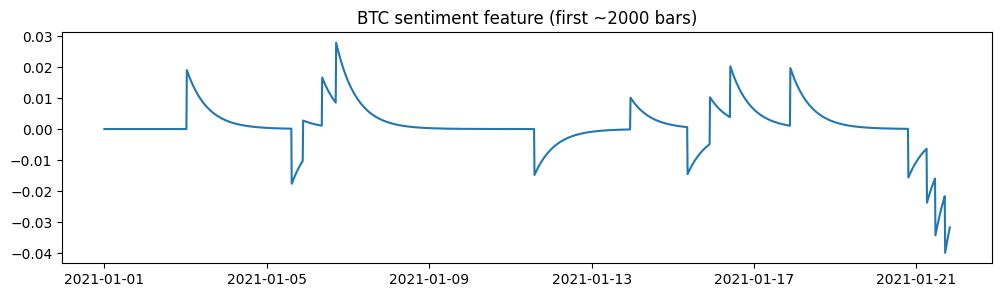

In [15]:
# ==========================================================
# Cell 13: Build sentiment time series per asset at 15m frequency (causal)
# ==========================================================
sent_feat_path = FEAT_DIR / f"sentiment_15m_{CFG.start}_{CFG.end}.joblib"
if cache_exists(sent_feat_path):
    sent_15m = joblib.load(sent_feat_path)
    print("Loaded cached sentiment features.")
else:
    sent_15m = {}
    # Create empty series per ticker
    for sym in symbols:
        tkr = sym.split("/")[0]
        sent_15m[sym] = pd.Series(0.0, index=idx)

        # Filter posts containing ticker code in currencies field
        mask = news_sent["currencies"].str.contains(fr"\b{tkr}\b", regex=True, na=False)
        df_t = news_sent.loc[mask, ["published_at","sent_num"]].copy()
        df_t = df_t.dropna(subset=["published_at"]).sort_values("published_at")

        if len(df_t) == 0:
            continue

        # Resample to 15m by causal aggregation: use last 24h EMA of sentiment
        s = df_t.set_index("published_at")["sent_num"].resample("15min").sum().reindex(idx).fillna(0.0)
        s_ema = s.ewm(span=96, adjust=False).mean()  # 96*15m = 24h
        sent_15m[sym] = s_ema

    joblib.dump(sent_15m, sent_feat_path)
    print("Saved sentiment features:", sent_feat_path)

# Quick sanity plot
plt.figure(figsize=(12,3))
plt.plot(sent_15m[CFG.base_symbol].iloc[:2000])
plt.title("BTC sentiment feature (first ~2000 bars)")
plt.show()

### CHECK — Sentiment coverage and alignment

In [16]:
# CHECK after original source cell 11
praxis_cell_check('sentiment')


    stage                        check status                                                                              detail
sentiment             required_objects   PASS                                                                                    
sentiment          all_symbols_present   PASS                                                                                    
sentiment sentiment_aligned_and_finite   PASS                                                                                    
sentiment    sentiment_values_observed   PASS 2424657 nonzero symbol-bars; an all-zero input cannot support a sentiment ablation.


,stage,check,status,detail,checked_at
0,sentiment,required_objects,PASS,,2026-10-30T18:53:08.435694+00:00
1,sentiment,all_symbols_present,PASS,,2026-10-30T18:53:08.435694+00:00
2,sentiment,sentiment_aligned_and_finite,PASS,,2026-10-30T18:53:08.435694+00:00
3,sentiment,sentiment_values_observed,PASS,2424657 nonzero symbol-bars; an all-zero input...,2026-10-30T18:53:08.435694+00:00


In [17]:
!pip install mplfinance

Loaded cached vision meta: /content/drive/MyDrive/QSentiaCryptoPMRevised/images/vision_meta_2021-01-01_2025-12-31_lb128_st16_h32.parquet rows: 153174
Copying rendered charts to Drive...


Copying to Drive: 0it [00:00, ?it/s]

Copied 0/0 charts to Drive


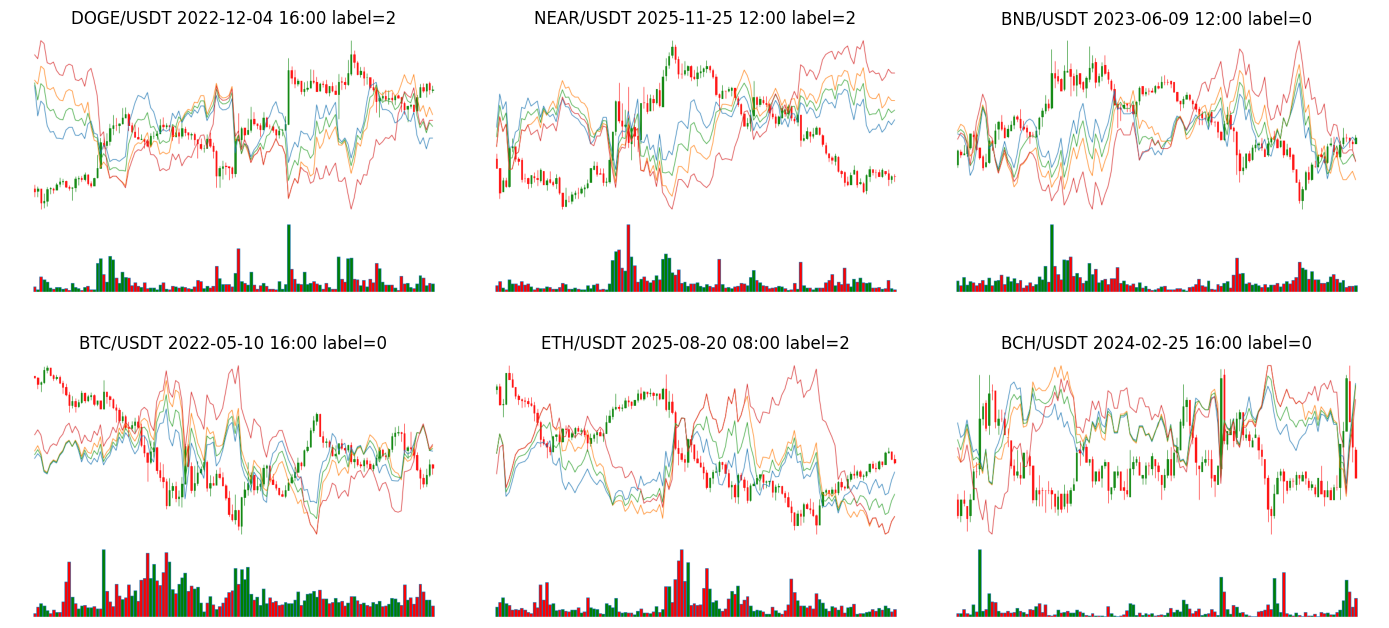

Vision labels distribution: label
0    61124
1    30378
2    61672
Name: count, dtype: int64


In [18]:
# ==========================================================
# Cell 14: Vision dataset generation (images span entire 2021-2025)
#         - candlesticks + volume + Ichimoku + indicators
#         - labels: long / neutral / short from future horizon
#         - PARALLEL processing to avoid memory overload
#         - FIX: robust Drive-safe image loading + auto re-render
# ==========================================================

import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mplfinance as mpf
from pathlib import Path
from PIL import Image
from concurrent.futures import ProcessPoolExecutor, as_completed
from tqdm.auto import tqdm

# ----------------------------------------------------------
# Use LOCAL temp dir for rendering, then copy to Drive
# ----------------------------------------------------------
import shutil
from pathlib import Path

vision_meta_path = IMG_DIR / f"vision_meta_{CFG.start}_{CFG.end}_lb{CFG.img_lookback}_st{CFG.img_stride}_h{CFG.label_horizon}.parquet"

# Final Drive destination
images_drive = IMG_DIR / f"charts_{CFG.start}_{CFG.end}_lb{CFG.img_lookback}_st{CFG.img_stride}_h{CFG.label_horizon}"
images_drive.mkdir(parents=True, exist_ok=True)

# Fast local rendering dir (avoids Drive I/O errors)
images_local = Path(f"/tmp/charts_{CFG.start}_{CFG.end}_lb{CFG.img_lookback}_st{CFG.img_stride}_h{CFG.label_horizon}")
images_local.mkdir(parents=True, exist_ok=True)

# Use local path for all rendering
images_root = images_local

# ----------------------------------------------------------
# Label helper
# ----------------------------------------------------------
def label_from_future_return(close_now: float, close_fut: float, th: float) -> int:
    r = (close_fut / close_now) - 1.0
    if r > th:
        return 2  # long
    if r < -th:
        return 0  # short
    return 1      # neutral

# ----------------------------------------------------------
# Single render worker (multiprocessing safe)
# ----------------------------------------------------------
def _render_one(args):
    sym, t_idx, df_slice, out_path, close_now, close_fut, th = args

    apds = []
    for col in ["ich_tenkan","ich_kijun","ich_senkou_a","ich_senkou_b"]:
        if col in df_slice.columns:
            apds.append(mpf.make_addplot(df_slice[col], width=0.7))

    mc = mpf.make_marketcolors(up='g', down='r', inherit=True)
    style = mpf.make_mpf_style(marketcolors=mc, gridstyle=":", y_on_right=False)

    mpf.plot(
        df_slice,
        type="candle",
        volume=True,
        addplot=apds if len(apds) > 0 else None,
        style=style,
        axisoff=True,
        figratio=(10,6),
        figscale=1.0,
        savefig=dict(fname=str(out_path), dpi=110, bbox_inches="tight", pad_inches=0.02),
    )

    y = label_from_future_return(close_now, close_fut, th)
    return {"symbol": sym, "t": t_idx, "img_path": str(out_path), "label": y}

# ----------------------------------------------------------
# Build vision metadata for ONE symbol
# ----------------------------------------------------------
def build_vision_meta_for_symbol(sym: str) -> pd.DataFrame:
    out_rows = []
    df = feats[sym].copy()

    df = df[["open","high","low","close","volume"] + [c for c in df.columns if c.startswith("ich_")]].copy()
    df = df.dropna(subset=["open","high","low","close","volume"])

    valid_idx = np.arange(CFG.img_lookback, len(df) - CFG.label_horizon, CFG.img_stride)
    tasks = []

    for i in valid_idx:
        t = df.index[i]
        out_path = images_root / f"{binance_symbol_noslash(sym)}_{t.strftime('%Y%m%d_%H%M')}.png"

        close_now = float(df["close"].iloc[i])
        close_fut = float(df["close"].iloc[i + CFG.label_horizon])

        drive_path = images_drive / out_path.name
        if cache_exists(out_path) or cache_exists(drive_path):
            y = label_from_future_return(close_now, close_fut, CFG.label_th)
            out_rows.append({"symbol": sym, "t": t, "img_path": str(out_path), "label": y})
        else:
            df_slice = df.iloc[i-CFG.img_lookback:i].copy()
            tasks.append((sym, t, df_slice, out_path, close_now, close_fut, CFG.label_th))

    if len(tasks) > 0:
        max_workers = max(1, os.cpu_count() // 2)
        with ProcessPoolExecutor(max_workers=max_workers) as ex:
            futs = [ex.submit(_render_one, task) for task in tasks]
            for f in tqdm(as_completed(futs), total=len(futs), desc=f"Rendering {sym}"):
                out_rows.append(f.result())

    return pd.DataFrame(out_rows)

# ----------------------------------------------------------
# Load or build full metadata
# ----------------------------------------------------------
if cache_exists(vision_meta_path):
    vision_meta = pd.read_parquet(vision_meta_path)
    print("Loaded cached vision meta:", vision_meta_path, "rows:", len(vision_meta))
else:
    metas = []
    for sym in symbols:
        metas.append(build_vision_meta_for_symbol(sym))
    vision_meta = pd.concat(metas, ignore_index=True).sort_values(["symbol","t"])
    vision_meta.to_parquet(vision_meta_path)
    print("Saved vision meta:", vision_meta_path, "rows:", len(vision_meta))

# Batch copy rendered images from local to Drive (much more reliable than direct Drive writes)
print("Copying rendered charts to Drive...")
local_pngs = list(images_local.glob("*.png"))
copied = 0
for p in tqdm(local_pngs, desc="Copying to Drive"):
    dst = images_drive / p.name
    if not cache_exists(dst):
        try:
            shutil.copy2(str(p), str(dst))
            copied += 1
        except OSError:
            time.sleep(1)
            try:
                shutil.copy2(str(p), str(dst))
                copied += 1
            except OSError:
                pass  # skip if Drive is still unhappy
print(f"Copied {copied}/{len(local_pngs)} charts to Drive")

# Update paths in metadata to point to Drive location
vision_meta["img_path"] = vision_meta["img_path"].apply(
    lambda p: str(images_drive / Path(p).name)
)
vision_meta.to_parquet(vision_meta_path)

# ----------------------------------------------------------
# FIX: Drive-safe image read + auto re-render on failure
# ----------------------------------------------------------
def _safe_imread(path: str, tries: int = 5, sleep_s: float = 0.6):
    last_e = None
    for k in range(tries):
        try:
            with Image.open(path) as im:
                return np.asarray(im.convert("RGB"))
        except Exception as e:
            last_e = e
            time.sleep(sleep_s * (k + 1))
    raise last_e

def _rerender_at(sym: str, t_idx: pd.Timestamp, out_path: Path) -> bool:
    df = feats[sym].copy()
    df = df[["open","high","low","close","volume"] + [c for c in df.columns if c.startswith("ich_")]].copy()
    df = df.dropna(subset=["open","high","low","close","volume"])

    if t_idx not in df.index:
        return False

    i = df.index.get_loc(t_idx)
    if i < CFG.img_lookback or i + CFG.label_horizon >= len(df):
        return False

    df_slice = df.iloc[i-CFG.img_lookback:i].copy()

    apds = []
    for col in ["ich_tenkan","ich_kijun","ich_senkou_a","ich_senkou_b"]:
        if col in df_slice.columns:
            apds.append(mpf.make_addplot(df_slice[col], width=0.7))

    mc = mpf.make_marketcolors(up='g', down='r', inherit=True)
    style = mpf.make_mpf_style(marketcolors=mc, gridstyle=":", y_on_right=False)

    out_path.parent.mkdir(parents=True, exist_ok=True)
    mpf.plot(
        df_slice,
        type="candle",
        volume=True,
        addplot=apds if len(apds) > 0 else None,
        style=style,
        axisoff=True,
        figratio=(10,6),
        figscale=1.0,
        savefig=dict(fname=str(out_path), dpi=110, bbox_inches="tight", pad_inches=0.02),
    )
    return True

# ----------------------------------------------------------
# Show sample images (robust)
# ----------------------------------------------------------
sample = vision_meta.sample(6, random_state=42)
fig, axes = plt.subplots(2, 3, figsize=(14,7))

for ax, (_, r) in zip(axes.flatten(), sample.iterrows()):
    p = str(r["img_path"])
    sym = r["symbol"]
    t_idx = pd.to_datetime(r["t"])

    try:
        img = _safe_imread(p)
    except Exception:
        ok = _rerender_at(sym, t_idx, Path(p))
        if ok:
            img = _safe_imread(p)
        else:
            ax.text(0.5, 0.5, "IMAGE LOAD FAILED", ha="center", va="center")
            ax.axis("off")
            continue

    ax.imshow(img)
    ax.set_title(f"{sym} {t_idx.strftime('%Y-%m-%d %H:%M')} label={r['label']}")
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Vision labels distribution:", vision_meta["label"].value_counts().sort_index())

In [19]:
# ==========================================================
# Cell 15: Vision classifier with teacher->student KD (Vision2)
#   - Teacher: ResNet18
#   - Student: MobileNetV3Small
#   - Distillation: alpha=0.7, T=3.0 per Vision2
# ==========================================================
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from PIL import Image

vision_teacher_path = MODEL_DIR / "vision_teacher_resnet18.pt"
vision_student_path = MODEL_DIR / "vision_student_mobilenetv3_kd.pt"

class ChartDataset(Dataset):
    def __init__(self, meta_df: pd.DataFrame, transform=None):
        self.df = meta_df.reset_index(drop=True)
        self.transform = transform
    def __len__(self):
        return len(self.df)
    def __getitem__(self, i):
        row = self.df.iloc[i]
        img = Image.open(row["img_path"]).convert("RGB")
        if self.transform:
            img = self.transform(img)
        y = int(row["label"])
        return img, y

# Train/val split by time to avoid leakage: last 15% as val
vision_meta_sorted = vision_meta.sort_values("t")
cut = int(len(vision_meta_sorted)*0.85)
vision_train = vision_meta_sorted.iloc[:cut].copy()
vision_val   = vision_meta_sorted.iloc[cut:].copy()

tfm = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
])

train_loader = DataLoader(ChartDataset(vision_train, tfm), batch_size=32, shuffle=True, num_workers=2, pin_memory=True)
val_loader   = DataLoader(ChartDataset(vision_val, tfm), batch_size=32, shuffle=False, num_workers=2, pin_memory=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def train_teacher():
    teacher = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    teacher.fc = nn.Linear(teacher.fc.in_features, 3)
    teacher.to(device)

    opt = torch.optim.AdamW(teacher.parameters(), lr=2e-4, weight_decay=1e-4)
    best = -1e9

    for epoch in range(10):  # 10 epochs minimum for meaningful learning
        teacher.train()
        for x,y in tqdm(train_loader, desc=f"Teacher epoch {epoch+1}"):
            x,y = x.to(device), y.to(device)
            opt.zero_grad()
            logits = teacher(x)
            loss = F.cross_entropy(logits, y)
            loss.backward()
            opt.step()

        # val acc
        teacher.eval()
        correct=0; total=0
        with torch.no_grad():
            for x,y in val_loader:
                x,y = x.to(device), y.to(device)
                pred = teacher(x).argmax(dim=1)
                correct += (pred==y).sum().item()
                total += y.numel()
        acc = correct/total
        print("Teacher val acc:", acc)
        if acc > best:
            best = acc
            torch.save(teacher.state_dict(), vision_teacher_path)

    print("Saved teacher:", vision_teacher_path)
    return teacher

def train_student_kd():
    # Load teacher
    teacher = models.resnet18(weights=None)
    teacher.fc = nn.Linear(teacher.fc.in_features, 3)
    teacher.load_state_dict(torch.load(vision_teacher_path, map_location=device))
    teacher.to(device)
    teacher.eval()

    # Student
    student = models.mobilenet_v3_small(weights=models.MobileNet_V3_Small_Weights.IMAGENET1K_V1)
    student.classifier[-1] = nn.Linear(student.classifier[-1].in_features, 3)
    student.to(device)

    alpha = 0.7
    T = 3.0
    opt = torch.optim.AdamW(student.parameters(), lr=2e-4, weight_decay=1e-4)

    for epoch in range(8):  # 8 epochs for KD student
        student.train()
        for x,y in tqdm(train_loader, desc=f"Student KD epoch {epoch+1}"):
            x,y = x.to(device), y.to(device)
            with torch.no_grad():
                t_logits = teacher(x)

            s_logits = student(x)
            ce = F.cross_entropy(s_logits, y)

            # KD: KL between softened distributions
            kd = F.kl_div(
                F.log_softmax(s_logits/T, dim=1),
                F.softmax(t_logits/T, dim=1),
                reduction="batchmean"
            ) * (T*T)

            loss = alpha*ce + (1-alpha)*kd
            opt.zero_grad()
            loss.backward()
            opt.step()

    torch.save(student.state_dict(), vision_student_path)
    print("Saved student:", vision_student_path)
    return student

if not cache_exists(vision_teacher_path):
    _ = train_teacher()
else:
    print("Teacher cached:", vision_teacher_path)

if not cache_exists(vision_student_path):
    _ = train_student_kd()
else:
    print("Student cached:", vision_student_path)


Teacher cached: /content/drive/MyDrive/QSentiaCryptoPMRevised/models/vision_teacher_resnet18.pt
Student cached: /content/drive/MyDrive/QSentiaCryptoPMRevised/models/vision_student_mobilenetv3_kd.pt


Loaded cached vision probs.


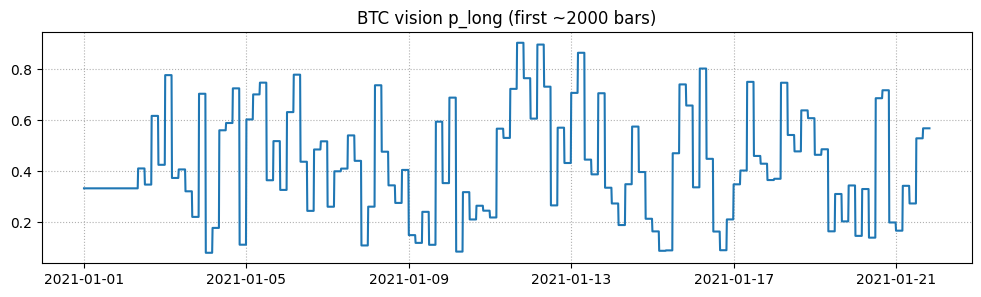

In [20]:
# ==========================================================
# Cell 16: Vision inference -> per-time probability signals (p_long/p_neutral/p_short)
# ==========================================================
from torchvision import models

vision_signal_path = FEAT_DIR / f"vision_probs_15m_{CFG.start}_{CFG.end}.joblib"
if cache_exists(vision_signal_path):
    vision_probs = joblib.load(vision_signal_path)
    print("Loaded cached vision probs.")
else:
    student = models.mobilenet_v3_small(weights=None)
    student.classifier[-1] = nn.Linear(student.classifier[-1].in_features, 3)
    student.load_state_dict(torch.load(vision_student_path, map_location=device))
    student.to(device)
    student.eval()

    # Initialize 15m series with neutral prior
    vision_probs = {}
    for sym in symbols:
        vision_probs[sym] = pd.DataFrame({
            "p_short": 0.33,
            "p_neutral": 0.34,
            "p_long": 0.33,
        }, index=idx)

    # Predict on the rendered meta rows (sparse points), then forward-fill
    ds = ChartDataset(vision_meta, tfm)
    dl = DataLoader(ds, batch_size=32, shuffle=False, num_workers=2)

    probs = []
    with torch.no_grad():
        for x,_ in tqdm(dl, desc="Vision inference"):
            x = x.to(device)
            p = F.softmax(student(x), dim=1).detach().cpu().numpy()
            probs.append(p)
    probs = np.vstack(probs)

    meta_tmp = vision_meta.reset_index(drop=True).copy()
    meta_tmp["p_short"] = probs[:,0]
    meta_tmp["p_neutral"] = probs[:,1]
    meta_tmp["p_long"] = probs[:,2]

    for sym in symbols:
        m = meta_tmp[meta_tmp["symbol"]==sym].copy()
        if len(m)==0:
            continue
        s = m.set_index(pd.to_datetime(m["t"]))[["p_short","p_neutral","p_long"]].sort_index()
        s = s.reindex(idx).ffill().fillna(1/3)
        vision_probs[sym] = s

    joblib.dump(vision_probs, vision_signal_path)
    print("Saved vision probs:", vision_signal_path)

# Example plot
plt.figure(figsize=(12,3))
plt.plot(vision_probs[CFG.base_symbol]["p_long"].iloc[:2000])
plt.title("BTC vision p_long (first ~2000 bars)")
plt.show()

### CHECK — Vision probabilities and training-overlap warning

In [21]:
# CHECK after original source cell 14
praxis_cell_check('vision')


 stage                            check         status                                                                                                                                          detail
vision                 required_objects           PASS                                                                                                                                                
vision               vision_all_symbols           PASS                                                                                                                                                
vision   vision_probabilities_AAVE/USDT           PASS                                                                                                                                                
vision    vision_probabilities_ADA/USDT           PASS                                                                                                                                                
visio

,stage,check,status,detail,checked_at
0,vision,required_objects,PASS,,2026-10-30T19:04:15.657163+00:00
1,vision,vision_all_symbols,PASS,,2026-10-30T19:04:15.657163+00:00
2,vision,vision_probabilities_AAVE/USDT,PASS,,2026-10-30T19:04:15.657163+00:00
3,vision,vision_probabilities_ADA/USDT,PASS,,2026-10-30T19:04:15.657163+00:00
4,vision,vision_probabilities_ATOM/USDT,PASS,,2026-10-30T19:04:15.657163+00:00
5,vision,vision_probabilities_BCH/USDT,PASS,,2026-10-30T19:04:15.657163+00:00
6,vision,vision_probabilities_BNB/USDT,PASS,,2026-10-30T19:04:15.657163+00:00
7,vision,vision_probabilities_BTC/USDT,PASS,,2026-10-30T19:04:15.657163+00:00
8,vision,vision_probabilities_DOGE/USDT,PASS,,2026-10-30T19:04:15.657163+00:00
9,vision,vision_probabilities_ETC/USDT,PASS,,2026-10-30T19:04:15.657163+00:00


In [22]:
# ==========================================================
# Cell 17: Generative encoder + online meta-learning
# ==========================================================
class Encoder(nn.Module):
    def __init__(self, in_dim: int, z_dim: int = 64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, 512),
            nn.ReLU(),
            nn.Linear(512, 512),
            nn.ReLU(),
            nn.Linear(512, z_dim)
        )

    def forward(self, x):
        return self.net(x)


class Decoder(nn.Module):
    def __init__(self, z_dim: int, a_dim: int, out_dim: int):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(z_dim + a_dim, 512),
            nn.ReLU(),
            nn.Linear(512, 512),
            nn.ReLU(),
            nn.Linear(512, out_dim)
        )

    def forward(self, z, a):
        return self.net(torch.cat([z, a], dim=-1))


class WAEStyleAE(nn.Module):
    def __init__(self, in_dim: int, z_dim: int, a_dim: int):
        super().__init__()
        self.enc = Encoder(in_dim, z_dim)
        self.dec = Decoder(z_dim, a_dim, in_dim)

    def forward(self, s, a):
        z = self.enc(s)
        s1_hat = self.dec(z, a)
        return z, s1_hat


def make_state_matrix(X_tnf: np.ndarray) -> np.ndarray:
    # X_tnf: (T, N, F) -> flatten per time step
    T, N, F = X_tnf.shape
    return X_tnf.reshape(T, N * F)


# We'll build s_t = tech_features_flat + sentiment + vision probs (flattened) for embedding
def build_embedding_state_tensor(t0: int, t1: int) -> Tuple[np.ndarray, np.ndarray]:
    # returns (S, S_next) with dummy actions (zeros)
    # For causality: S uses time t; S_next uses time t+1
    X = X_raw[t0:t1]  # (T, N, F)
    S = make_state_matrix(X)  # (T, N*F)
    S_next = make_state_matrix(X_raw[t0 + 1 : t1 + 1])
    return S[:-1], S_next[:-1]


# model cache
ae_path = MODEL_DIR / f"gen_encoder_ae_z64_{CFG.start}_{CFG.end}.pt"
ae_meta_path = MODEL_DIR / f"gen_encoder_meta_zeta.joblib"

in_dim = X_raw.shape[1] * X_raw.shape[2]
a_dim = len(symbols) + 1  # (cash + N assets), dummy action space size
z_dim = 64

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def train_base_ae(train_slice: Tuple[int,int]):
    t0, t1 = train_slice
    S, S1 = build_embedding_state_tensor(t0, t1)

    # ---- hard sanitize (most important) ----
    S  = np.nan_to_num(S,  nan=0.0, posinf=0.0, neginf=0.0).astype(np.float32)
    S1 = np.nan_to_num(S1, nan=0.0, posinf=0.0, neginf=0.0).astype(np.float32)

    # Optional safety clamp (prevents extreme spikes)
    S  = np.clip(S,  -10.0, 10.0)
    S1 = np.clip(S1, -10.0, 10.0)

    # Dummy actions for AE training (zeros)
    A = np.zeros((len(S), a_dim), dtype=np.float32)

    model = WAEStyleAE(in_dim=in_dim, z_dim=z_dim, a_dim=a_dim).to(device)

    # ---- safer optimizer settings ----
    opt = torch.optim.AdamW(model.parameters(), lr=3e-4)  # lower LR

    bs = 256
    for step in range(400):  # light default
        idxs = np.random.randint(0, len(S), size=bs)

        s  = torch.tensor(S[idxs],  dtype=torch.float32, device=device)
        s1 = torch.tensor(S1[idxs], dtype=torch.float32, device=device)
        a  = torch.tensor(A[idxs],  dtype=torch.float32, device=device)

        # Skip if any NaN/Inf still leaked through
        if not torch.isfinite(s).all() or not torch.isfinite(s1).all() or not torch.isfinite(a).all():
            continue

        _, s1_hat = model(s, a)

        # Guard output too
        if not torch.isfinite(s1_hat).all():
            continue

        loss = F.mse_loss(s1_hat, s1)

        if not torch.isfinite(loss):
            continue

        opt.zero_grad(set_to_none=True)
        loss.backward()

        # ---- gradient safety ----
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

        opt.step()

        if (step+1) % 100 == 0:
            print("AE step", step+1, "loss", float(loss.detach().cpu()))

    torch.save(model.state_dict(), ae_path)
    zeta = {k: v.detach().cpu().clone() for k,v in model.state_dict().items()}
    joblib.dump(zeta, ae_meta_path)
    print("Saved AE + meta zeta.")
    return model


def load_ae():
    model = WAEStyleAE(in_dim=in_dim, z_dim=z_dim, a_dim=a_dim).to(device)
    model.load_state_dict(torch.load(ae_path, map_location=device))
    zeta = joblib.load(ae_meta_path)
    return model, zeta


# Train base on first WF train window only (no leakage)
if cache_exists(ae_path) and cache_exists(ae_meta_path):
    print("AE cached.")

else:
    # first split train range
    tr0, tr1, _, _ = SPLITS[0]
    t0 = idx.get_indexer([tr0], method="nearest")[0]
    t1 = idx.get_indexer([tr1], method="nearest")[0]
    _ = train_base_ae((t0, t1))

ae_model, zeta = load_ae()


AE cached.


In [23]:
# ==========================================================
# Cell 18: Online meta-learning update for encoder (FOML-style)
# ==========================================================
def meta_update_encoder(model,
                        zeta_state: Dict[str, torch.Tensor],
                        S_tr: np.ndarray, S1_tr: np.ndarray,
                        steps: int = 50,
                        alpha1: float = 1e-3,
                        beta1: float = 1e-2):
    """
    Approximate NEWARTICLE42 Eq (10): new-path update + meta regularization update.
    We'll implement SGD-like updates with a regularization pull toward zeta.
    """
    model.train()
    opt = torch.optim.SGD(model.parameters(), lr=alpha1)

    # Create zeta tensors on device
    zeta_dev = {k: v.to(device) for k, v in zeta_state.items()}

    bs = 256
    A = np.zeros((len(S_tr), a_dim), dtype=np.float32)

    for _ in range(steps):
        idxs = np.random.randint(0, len(S_tr), size=bs)
        s  = torch.tensor(S_tr[idxs], dtype=torch.float32, device=device)
        s1 = torch.tensor(S1_tr[idxs], dtype=torch.float32, device=device)
        a  = torch.tensor(A[idxs], dtype=torch.float32, device=device)

        _, s1_hat = model(s, a)
        rec_loss = F.mse_loss(s1_hat, s1)

        # Meta regularization: ||theta - zeta||^2
        # MUST use named_parameters() — state_dict() returns DETACHED tensors
        # so no gradient flows through the regularization term.
        reg = torch.tensor(0.0, device=device)
        for name, param in model.named_parameters():
            if name in zeta_dev:
                reg = reg + F.mse_loss(param, zeta_dev[name])

        loss = rec_loss + beta1 * reg

        opt.zero_grad()
        loss.backward()
        opt.step()

    model.eval()
    return model


@torch.no_grad()
def compute_embeddings_for_range(model: WAEStyleAE, t0: int, t1: int) -> np.ndarray:
    # returns Z of shape (T, z_dim)
    X = X_raw[t0:t1]
    S = make_state_matrix(X)
    z = model.enc(
        torch.tensor(S, dtype=torch.float32, device=device)
    ).detach().cpu().numpy()
    return z


print("AE ready for per-window meta-updates.")

AE ready for per-window meta-updates.


### CHECK — Encoder and meta-update readiness

In [24]:
# CHECK after original source cell 16
praxis_cell_check('encoder')


  stage                     check         status                                                                                                         detail
encoder          required_objects           PASS                                                                                                               
encoder finite_encoder_parameters           PASS                                                                                                               
encoder      meta_update_callable           PASS                                                                                                               
encoder       encoder_runtime_use EVIDENCE_LIMIT Definition/base fit is ready. Actual per-fold consumption is checked in portfolio fit and trajectory receipts.


,stage,check,status,detail,checked_at
0,encoder,required_objects,PASS,,2026-10-30T19:04:17.170097+00:00
1,encoder,finite_encoder_parameters,PASS,,2026-10-30T19:04:17.170097+00:00
2,encoder,meta_update_callable,PASS,,2026-10-30T19:04:17.170097+00:00
3,encoder,encoder_runtime_use,EVIDENCE_LIMIT,Definition/base fit is ready. Actual per-fold ...,2026-10-30T19:04:17.170097+00:00


In [25]:
# ==========================================================
# Cell 19: DDPM crisis scenario generator
# ==========================================================
class TimeEmbedding(nn.Module):
    def __init__(self, dim: int):
        super().__init__()
        self.dim = dim
        self.mlp = nn.Sequential(
            nn.Linear(dim, dim * 4),
            nn.ReLU(),
            nn.Linear(dim * 4, dim)
        )

    def forward(self, t):
        # sinusoidal embedding
        half = self.dim // 2
        freqs = torch.exp(
            -math.log(10000)
            * torch.arange(0, half, device=t.device).float()
            / half
        )
        args = t[:, None].float() * freqs[None, :]
        emb = torch.cat([torch.sin(args), torch.cos(args)], dim=-1)
        if self.dim % 2 == 1:
            emb = torch.cat([emb, torch.zeros_like(emb[:, :1])], dim=-1)
        return self.mlp(emb)


class DiffusionMLP(nn.Module):
    def __init__(
        self,
        seq_len: int,
        n_assets: int,
        cond_dim: int = 8,
        t_dim: int = 64,
        hidden: int = 256,
    ):
        super().__init__()
        self.seq_len = seq_len
        self.n_assets = n_assets
        self.t_emb = TimeEmbedding(t_dim)
        self.cond = nn.Sequential(
            nn.Linear(cond_dim, t_dim),
            nn.ReLU(),
            nn.Linear(t_dim, t_dim),
        )

        in_dim = seq_len * n_assets + t_dim + t_dim
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden),
            nn.ReLU(),
            nn.Linear(hidden, hidden),
            nn.ReLU(),
            nn.Linear(hidden, seq_len * n_assets),
        )

    def forward(self, x_t, t, cond_vec):
        # x_t: (B, L, N) -> flat
        B = x_t.shape[0]
        xt = x_t.reshape(B, -1)
        te = self.t_emb(t)
        ce = self.cond(cond_vec)
        h = torch.cat([xt, te, ce], dim=-1)
        out = self.net(h).reshape(B, self.seq_len, self.n_assets)
        return out  # predicted noise


def make_beta_schedule(T: int, beta_start=1e-4, beta_end=0.02):
    return torch.linspace(beta_start, beta_end, T)


class SimpleDDPM:
    def __init__(self, model: nn.Module, T: int = 200):
        self.model = model
        self.T = T
        self.betas = make_beta_schedule(T).to(device)
        self.alphas = 1.0 - self.betas
        self.alpha_bar = torch.cumprod(self.alphas, dim=0)

    def q_sample(self, x0, t, noise):
        # x_t = sqrt(a_bar)*x0 + sqrt(1-a_bar)*noise
        a_bar = self.alpha_bar[t].view(-1, 1, 1)
        return torch.sqrt(a_bar) * x0 + torch.sqrt(1 - a_bar) * noise

    def p_sample(self, x_t, t, cond):
        # Predict noise
        eps = self.model(x_t, t, cond)
        a = self.alphas[t].view(-1, 1, 1)
        b = self.betas[t].view(-1, 1, 1)
        a_bar = self.alpha_bar[t].view(-1, 1, 1)

        # x0 estimate
        x0_hat = (x_t - torch.sqrt(1 - a_bar) * eps) / torch.sqrt(a_bar + 1e-8)

        # mean of p(x_{t-1}|x_t)
        mean = (1 / torch.sqrt(a)) * (
            x_t - (b / torch.sqrt(1 - a_bar + 1e-8)) * eps
        )

        if (t == 0).all():
            return mean
        noise = torch.randn_like(x_t)
        return mean + torch.sqrt(b) * noise

    @torch.no_grad()
    def sample(self, B: int, seq_len: int, n_assets: int, cond: torch.Tensor):
        x = torch.randn(B, seq_len, n_assets, device=device)
        for ti in reversed(range(self.T)):
            t = torch.full((B,), ti, device=device, dtype=torch.long)
            x = self.p_sample(x, t, cond)
        return x


# Build training data: returns sequences from real data
def build_return_matrix() -> np.ndarray:
    # returns (T, N)
    rets = []
    for sym in symbols:
        df = feats[sym]
        rets.append(df["logret1"].to_numpy(dtype=np.float32))
    R = np.stack(rets, axis=1)  # (T, N)
    R = np.nan_to_num(R, nan=0.0, posinf=0.0, neginf=0.0)
    # --- FIX: Cap extreme single-bar returns (data errors) ---
    MAX_BAR_LOGRET = 0.10  # ±10% per 15-minute bar is the absolute max realistic move
    n_clipped = int((np.abs(R) > MAX_BAR_LOGRET).sum())
    R = np.clip(R, -MAX_BAR_LOGRET, MAX_BAR_LOGRET)
    print(f"Clipped {n_clipped} extreme bars out of {R.size} total ({n_clipped/R.size*100:.4f}%)")
    return R


R = build_return_matrix()
print("Return matrix shape:", R.shape)

synth_path = SYNTH_DIR / f"ddpm_synth_returns_{CFG.start}_{CFG.end}_L{CFG.ddpm_seq_len}.joblib"
ddpm_model_path = MODEL_DIR / f"ddpm_model_L{CFG.ddpm_seq_len}.pt"

if cache_exists(synth_path) and cache_exists(ddpm_model_path):
    synth_episodes = joblib.load(synth_path)
    print("Loaded cached synthetic episodes:", len(synth_episodes))
else:
    # Train DDPM on train-only portion (first WF train window)
    tr0, tr1, _, _ = SPLITS[0]
    t0 = idx.get_indexer([tr0], method="nearest")[0]
    t1 = idx.get_indexer([tr1], method="nearest")[0]
    R_tr = R[t0:t1]

    L = CFG.ddpm_seq_len
    N = len(symbols)

    # Create training batches of sequences
    seqs = []
    for i in range(0, len(R_tr) - L - 1, L):
        seqs.append(R_tr[i : i + L])
    seqs = np.stack(seqs, axis=0)  # (B, L, N)
    seqs = np.clip(seqs, -0.2, 0.2)

    # Condition vector: crash intensity proxy
    def crash_intensity(seq):
        cum = np.cumsum(seq, axis=0)
        equity = np.exp(cum)
        peak = np.maximum.accumulate(equity, axis=0)
        dd = 1.0 - equity / peak
        return float(np.max(dd))

    conds = np.array([crash_intensity(s) for s in seqs], dtype=np.float32)

    bins = np.digitize(conds, bins=[0.05, 0.10, 0.20])
    onehot = np.eye(4, dtype=np.float32)[bins]
    cond_vec = np.concatenate([onehot, conds.reshape(-1, 1)], axis=1)
    cond_dim = cond_vec.shape[1]

    net = DiffusionMLP(seq_len=L, n_assets=N, cond_dim=cond_dim).to(device)
    ddpm = SimpleDDPM(net, T=200)

    opt = torch.optim.AdamW(net.parameters(), lr=1e-3)
    B = seqs.shape[0]

    for step in range(CFG.ddpm_train_steps):
        bi = np.random.randint(0, B, size=32)
        x0 = torch.tensor(seqs[bi], dtype=torch.float32, device=device)
        c = torch.tensor(cond_vec[bi], dtype=torch.float32, device=device)

        t = torch.randint(0, ddpm.T, (x0.size(0),), device=device)
        noise = torch.randn_like(x0)
        x_t = ddpm.q_sample(x0, t, noise)

        pred = net(x_t, t, c)
        loss = F.mse_loss(pred, noise)

        opt.zero_grad()
        loss.backward()
        opt.step()

        if (step + 1) % 1000 == 0:
            print("DDPM step", step + 1, "loss", float(loss.detach().cpu()))

    torch.save(net.state_dict(), ddpm_model_path)

    # Generate crisis-heavy synthetic episodes
    Bgen = 64
    high_bin = 3
    cond_high = np.zeros((Bgen, cond_dim), dtype=np.float32)
    cond_high[:, high_bin] = 1.0
    cond_high[:, -1] = 0.25
    cond_high_t = torch.tensor(cond_high, dtype=torch.float32, device=device)

    synth = (
        ddpm.sample(B=Bgen, seq_len=L, n_assets=N, cond=cond_high_t)
        .detach()
        .cpu()
        .numpy()
    )
    synth_episodes = [s for s in synth]
    joblib.dump(synth_episodes, synth_path)
    print("Saved synthetic episodes:", synth_path)

print(
    "Synthetic episodes:",
    len(synth_episodes),
    "shape one:",
    np.array(synth_episodes[0]).shape,
)

Clipped 535 extreme bars out of 2452814 total (0.0218%)
Return matrix shape: (175201, 14)
Loaded cached synthetic episodes: 64
Synthetic episodes: 64 shape one: (256, 14)


### CHECK — Generated episode integrity

In [26]:
# CHECK after original source cell 17
praxis_cell_check('synthetic_generator')


              stage                          check         status                                                                                                                                  detail
synthetic_generator               required_objects           PASS                                                                                                                                        
synthetic_generator             synthetic_nonempty           PASS                                                                                                                                        
synthetic_generator synthetic_shape_and_finiteness           PASS                                                                                                                                        
synthetic_generator                 synthetic_role EVIDENCE_LIMIT A cached sample is not evidence that it was used. New DDPM stress receipts and scenario-level results are required in the fina

,stage,check,status,detail,checked_at
0,synthetic_generator,required_objects,PASS,,2026-10-30T19:04:17.758245+00:00
1,synthetic_generator,synthetic_nonempty,PASS,,2026-10-30T19:04:17.758245+00:00
2,synthetic_generator,synthetic_shape_and_finiteness,PASS,,2026-10-30T19:04:17.758245+00:00
3,synthetic_generator,synthetic_role,EVIDENCE_LIMIT,A cached sample is not evidence that it was us...,2026-10-30T19:04:17.758245+00:00


In [27]:
# Install the missing 4-bit loading dependency.
%pip install -q --upgrade "bitsandbytes>=0.46.1"

import importlib
import importlib.metadata
importlib.invalidate_caches()

# Refresh cached dependency checks where supported.
from transformers.utils import import_utils
for name in ("_is_package_available", "is_bitsandbytes_available"):
    check = getattr(import_utils, name, None)
    if hasattr(check, "cache_clear"):
        check.cache_clear()

import bitsandbytes
print("bitsandbytes:", importlib.metadata.version("bitsandbytes"))
print("Dependency imported successfully. Rerun Cell 20.")

bitsandbytes: 0.50.2
Dependency imported successfully. Rerun Cell 20.


In [28]:
# ==========================================================
# Cell 20: Agentic Alpha Layer (OPEN SOURCE ONLY; max 3 models)
#   - FinBERT already used for sentiment labels
#   - Zephyr-7B for alpha scoring
#   - Flan-T5-large as verifier
# ==========================================================
from transformers import AutoTokenizer, AutoModelForCausalLM, AutoModelForSeq2SeqLM

alpha_path = FEAT_DIR / f"alpha_daily_{CFG.start}_{CFG.end}_top{CFG.top_k}.parquet"

def load_zephyr():
    from transformers import BitsAndBytesConfig
    model_id = "HuggingFaceH4/zephyr-7b-beta"
    tok = AutoTokenizer.from_pretrained(model_id, use_fast=True)
    bnb_config = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_compute_dtype=torch.float16,
    )
    model = AutoModelForCausalLM.from_pretrained(
        model_id,
        device_map="auto",
        quantization_config=bnb_config,
    )
    return tok, model

def load_flan():
    model_id = "google/flan-t5-large"
    tok = AutoTokenizer.from_pretrained(model_id, use_fast=True)
    model = AutoModelForSeq2SeqLM.from_pretrained(model_id, device_map="auto")
    return tok, model

def safe_json_from_text(txt: str) -> Optional[dict]:
    # try to extract first {...}
    try:
        s = txt[txt.find("{"):txt.rfind("}")+1]
        return json.loads(s)
    except Exception:
        return None

def _to_float01(v) -> Optional[float]:
    # robust coercion: handles strings, ints/floats, nested dicts like {"alpha":0.7} or {"score":"0.7"}
    try:
        if isinstance(v, (int, float, np.floating, np.integer)):
            return float(v)
        if isinstance(v, str):
            return float(v.strip())
        if isinstance(v, dict):
            for key in ["alpha", "score", "value", "prob", "p", "long", "p_long"]:
                if key in v:
                    return _to_float01(v[key])
        if isinstance(v, (list, tuple)) and len(v) > 0:
            return _to_float01(v[0])
        return None
    except Exception:
        return None

def build_daily_feature_snapshot(ts: pd.Timestamp) -> dict:
    # Summarize key features per asset at timestamp ts
    snap = {"ts": str(ts)}
    for sym in symbols:
        i = idx.get_indexer([ts], method="nearest")[0]
        df = feats[sym]
        row = df.iloc[i]
        snap[sym] = {
            "ret1": float(row["ret1"]) if not pd.isna(row["ret1"]) else 0.0,
            "rsi": float(row["rsi"]) if not pd.isna(row["rsi"]) else 0.0,
            "macd": float(row["macd"]) if not pd.isna(row["macd"]) else 0.0,
            "vol_128": float(row["vol_128"]) if not pd.isna(row["vol_128"]) else 0.0,
            "sent": float(sent_15m[sym].iloc[i]),
            "vision_p_long": float(vision_probs[sym]["p_long"].iloc[i]),
        }
    return snap

def classical_alpha_score(ts: pd.Timestamp) -> pd.Series:
    # Multi-factor fallback alpha: momentum + mean-reversion + trend + volatility-adjusted
    i = idx.get_indexer([ts], method="nearest")[0]
    scores = {}
    for sym in symbols:
        df = feats[sym]

        # 1-day momentum (96 bars = 24h on 15m)
        mom_1d = df["close"].pct_change(96).iloc[i] if "close" in df.columns else 0.0
        mom_1d = 0.0 if pd.isna(mom_1d) else float(mom_1d)

        # 7-day momentum (672 bars)
        mom_7d = df["close"].pct_change(672).iloc[i] if "close" in df.columns else 0.0
        mom_7d = 0.0 if pd.isna(mom_7d) else float(mom_7d)

        # RSI mean-reversion signal (oversold = high alpha)
        rsi_val = float(df["rsi"].iloc[i]) if not pd.isna(df["rsi"].iloc[i]) else 50.0
        rsi_signal = (50.0 - rsi_val) / 100.0  # positive when oversold

        # Sentiment
        sent = float(sent_15m[sym].iloc[i])

        # Vision
        vis  = float(vision_probs[sym]["p_long"].iloc[i])

        # Volatility penalty (prefer lower vol assets)
        vol = float(df["vol_128"].iloc[i]) if not pd.isna(df["vol_128"].iloc[i]) else 0.01
        vol_penalty = -vol * 2.0

        scores[sym] = (0.30 * mom_1d
                      + 0.20 * mom_7d
                      + 0.15 * rsi_signal
                      + 0.15 * sent
                      + 0.10 * (vis - 1/3)
                      + 0.10 * vol_penalty)

    return pd.Series(scores).sort_values(ascending=False)

if cache_exists(alpha_path):
    alpha_daily = pd.read_parquet(alpha_path)
    print("Loaded cached alpha:", alpha_path, "rows:", len(alpha_daily))
else:
    zeph_tok, zeph_model = load_zephyr()
    flan_tok, flan_model = load_flan()

    # daily timestamps (00:00 UTC)
    daily_idx = pd.date_range(start=start_ts, end=end_ts, freq="1D", tz="UTC")
    rows = []

    for ts in tqdm(daily_idx, desc="Agentic alpha (daily)"):
        snap = build_daily_feature_snapshot(ts)

        # Prompt Zephyr for alpha scores
        prompt = f"""
You are a quantitative crypto portfolio assistant.
Return a JSON object mapping each symbol to a float alpha score in [0,1].
Higher means stronger LONG preference (long-only).
Only use information provided. Do NOT invent prices.
JSON only, no markdown.

DATA SNAPSHOT:
{json.dumps(snap)[:2500]}
"""
        inputs = zeph_tok(
            prompt,
            return_tensors="pt",
            truncation=True,
            max_length=min(512, getattr(zeph_tok, "model_max_length", 512))
        ).to(zeph_model.device)

        out = zeph_model.generate(**inputs, max_new_tokens=220, do_sample=False)
        txt = zeph_tok.decode(out[0], skip_special_tokens=True)
        js = safe_json_from_text(txt)

        if js is None or not all(sym in js for sym in symbols):
            # fallback
            s = classical_alpha_score(ts)
            for sym in symbols:
                rows.append({"date": ts, "symbol": sym, "alpha": float((s.rank(ascending=False)[sym] / len(symbols)))})
            continue

        # Verify with Flan: ask it to output top-3 symbols as a sanity check
        verify_prompt = f"Given these alpha scores, list the top {CFG.top_k} symbols only: {json.dumps(js)}"
        vin = flan_tok(verify_prompt, return_tensors="pt", truncation=True, max_length=512).to(flan_model.device)
        vout = flan_model.generate(**vin, max_new_tokens=50)
        vtxt = flan_tok.decode(vout[0], skip_special_tokens=True).upper()

        # Store alphas
        ok = True
        coerced = {}
        for sym in symbols:
            a = _to_float01(js.get(sym, 0.0))
            if a is None or not np.isfinite(a):
                ok = False
                break
            a = max(0.0, min(1.0, float(a)))
            coerced[sym] = a

        if not ok:
            # fallback if Zephyr returned nested dicts / malformed types we can't coerce
            s = classical_alpha_score(ts)
            for sym in symbols:
                rows.append({"date": ts, "symbol": sym, "alpha": float((s.rank(ascending=False)[sym] / len(symbols)))})
            continue

        for sym in symbols:
            rows.append({"date": ts, "symbol": sym, "alpha": coerced[sym], "verifier_top_text": vtxt[:120]})

    alpha_daily = pd.DataFrame(rows)
    alpha_daily.to_parquet(alpha_path)
    print("Saved alpha:", alpha_path)

# Build top-3 selection mask per day
alpha_pivot = alpha_daily.pivot_table(index="date", columns="symbol", values="alpha", aggfunc="mean").fillna(0.0)
top3_daily = alpha_pivot.apply(lambda r: r.sort_values(ascending=False).index[:CFG.top_k].tolist(), axis=1)

print("Alpha coverage:", alpha_pivot.index.min(), "->", alpha_pivot.index.max())
print("Example top3 day:", top3_daily.iloc[0])

Loaded cached alpha: /content/drive/MyDrive/QSentiaCryptoPMRevised/features/alpha_daily_2021-01-01_2025-12-31_top3.parquet rows: 25564
Alpha coverage: 2021-01-01 00:00:00+00:00 -> 2025-12-31 00:00:00+00:00
Example top3 day: ['AAVE/USDT', 'ADA/USDT', 'ATOM/USDT']


In [ ]:
# ==========================================================
# Cell 21: Market Turbulence Index (Mahalanobis) + threshold
# ==========================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from sklearn.covariance import LedoitWolf

turb_path = FEAT_DIR / f"turbulence_{CFG.start}_{CFG.end}.parquet"

if cache_exists(turb_path):
    turb = pd.read_parquet(turb_path)["turbulence"]
    print("Loaded cached turbulence.")
else:
    # Use log returns matrix R (T, N) built earlier
    lookback = CFG.turb_lookback_days * 24 * 4  # 15m bars/day = 96
    turb_vals = np.zeros(len(idx), dtype=np.float32)

    for t in tqdm(range(lookback, len(idx)), desc="Computing turbulence"):
        window = R[t - lookback : t]  # (L, N)
        mu = window.mean(axis=0, keepdims=True)
        cov = LedoitWolf().fit(window).covariance_
        cov_inv = np.linalg.pinv(cov)
        x = (R[t : t + 1] - mu)
        turb_vals[t] = float(x @ cov_inv @ x.T)

    turb = pd.Series(turb_vals, index=idx, name="turbulence")
    turb.to_frame().to_parquet(turb_path)
    print("Saved turbulence:", turb_path)

thr = turb.quantile(CFG.turb_threshold_quantile)
print(
    "Turbulence threshold (quantile):",
    CFG.turb_threshold_quantile,
    "->",
    float(thr),
)

plt.figure(figsize=(12, 3))
plt.plot(turb.iloc[:5000])
plt.axhline(thr, linestyle="--")
plt.title("Turbulence (first ~5000 bars)")
plt.show()

In [ ]:
# ==========================================================
# Cell 22: Custom Gymnasium environment (long-only, no leverage, top-3)
#   - FIX: timestamp-aligned sentiment/vision + NaN/Inf guards (prevents SB3 NaN loc crash)
# ==========================================================
import gymnasium as gym
from gymnasium import spaces
import numpy as np
import pandas as pd
import math
from typing import Dict

def softmax_np(x: np.ndarray) -> np.ndarray:
    x = x - np.max(x)
    e = np.exp(x)
    return e / (e.sum() + 1e-12)

class CryptoPortfolioEnv(gym.Env):
    """
    Observation: [z_t, alpha_t (N), sentiment_t (N), vision_p_long (N), turb_t, weights (N+1)]
    Action: raw logits (N+1) -> softmax -> weights -> mask to top-3 -> renormalize.
    Reward: Sharpe-proxy + heavy DD penalty - turnover - costs. Turbulence breach -> go cash + penalty.
    """
    metadata = {"render_modes": []}

    def __init__(self,
                 index: pd.DatetimeIndex,
                 returns: np.ndarray,              # (T,N) log returns
                 alpha_daily: pd.DataFrame,        # pivot date x symbol
                 top3_daily: pd.Series,            # date -> list of symbols
                 z_emb: np.ndarray,                # (T, z_dim)
                 sent_15m: Dict[str, pd.Series],
                 vision_probs: Dict[str, pd.DataFrame],
                 turb: pd.Series,
                 cost_rate: float,
                 top_k: int = 3,
                 turb_threshold: float = 9999.0,
                 dd_penalty: float = 10.0,
                 turnover_penalty: float = 0.1,
                 sharpe_coef: float = 1.0):
        super().__init__()
        self.index = index
        self.R = returns
        self.N = returns.shape[1]
        self.symbols = symbols
        self.sym2i = {s:i for i,s in enumerate(self.symbols)}

        self.alpha_daily = alpha_daily
        self.top3_daily = top3_daily

        self.z = z_emb
        self.sent_15m = sent_15m
        self.vision_probs = vision_probs
        self.turb = turb

        self.cost_rate = cost_rate
        self.top_k = top_k
        self.turb_threshold = turb_threshold

        self.dd_penalty = dd_penalty
        self.turnover_penalty = turnover_penalty
        self.sharpe_coef = sharpe_coef

        # action: N assets + cash
        self.action_space = spaces.Box(low=-1.0, high=1.0, shape=(self.N+1,), dtype=np.float32)

        # observation dim
        obs_dim = z_dim + self.N + self.N + self.N + 1 + (self.N+1)
        self.observation_space = spaces.Box(low=-np.inf, high=np.inf, shape=(obs_dim,), dtype=np.float32)

        self.reset()

    def _top3_mask(self, t: int) -> np.ndarray:
        day = self.index[t].normalize()
        if day not in self.top3_daily.index:
            return np.ones(self.N, dtype=np.float32)
        top_syms = self.top3_daily.loc[day]
        m = np.zeros(self.N, dtype=np.float32)
        for s in top_syms:
            if s in self.sym2i:
                m[self.sym2i[s]] = 1.0
        return m

    def _safe_sent_val(self, s: str, ts: pd.Timestamp) -> float:
        ser = self.sent_15m.get(s, None)
        if ser is None:
            return 0.0
        try:
            v = ser.loc[ts]
        except Exception:
            # fallback if index mismatch
            try:
                v = ser.reindex(self.index).loc[ts]
            except Exception:
                return 0.0
        v = float(v) if pd.notna(v) else 0.0
        if not np.isfinite(v):
            return 0.0
        return v

    def _safe_vis_val(self, s: str, ts: pd.Timestamp) -> float:
        df = self.vision_probs.get(s, None)
        if df is None:
            return 0.33
        try:
            v = df.loc[ts, "p_long"]
        except Exception:
            # fallback if index mismatch
            try:
                v = df.reindex(self.index).loc[ts, "p_long"]
            except Exception:
                return 0.33
        v = float(v) if pd.notna(v) else 0.33
        if not np.isfinite(v):
            return 0.33
        return v

    def _get_obs(self) -> np.ndarray:
        t = self.t
        ts = self.index[t]

        # alpha vector: daily
        day = ts.normalize()
        if day in self.alpha_daily.index:
            alpha_vec = self.alpha_daily.loc[day].reindex(self.symbols).fillna(0.0).to_numpy(dtype=np.float32)
        else:
            alpha_vec = np.zeros(self.N, dtype=np.float32)

        sent_vec = np.array([self._safe_sent_val(s, ts) for s in self.symbols], dtype=np.float32)
        vis_vec  = np.array([self._safe_vis_val(s, ts) for s in self.symbols], dtype=np.float32)

        try:
            turb_val = float(self.turb.loc[ts])
        except Exception:
            turb_val = float(self.turb.reindex(self.index).loc[ts])
        if not np.isfinite(turb_val):
            turb_val = 0.0
        turb_t = np.array([turb_val], dtype=np.float32)

        z_t = self.z[t].astype(np.float32)
        w_t = self.w.astype(np.float32)

        obs = np.concatenate([z_t, alpha_vec, sent_vec, vis_vec, turb_t, w_t]).astype(np.float32)
        # hard guard against NaNs/Infs -> prevents SB3 NaN loc crash
        obs = np.nan_to_num(obs, nan=0.0, posinf=0.0, neginf=0.0).astype(np.float32)
        return obs

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.t = 0
        self.w = np.zeros(self.N+1, dtype=np.float32)
        self.w[0] = 1.0  # start in cash
        self.pv = 1.0
        self.peak = 1.0
        self.ret_buffer = []  # collect returns for stable Sharpe
        return self._get_obs(), {}

    def step(self, action):
        t = self.t

        # sanitize action to avoid NaNs exploding softmax
        a = np.array(action, dtype=np.float32).reshape(-1)
        a = np.nan_to_num(a, nan=0.0, posinf=0.0, neginf=0.0)
        if a.shape[0] != self.N + 1:
            # fallback: if wrong shape, go cash
            a = np.zeros(self.N + 1, dtype=np.float32)

        # Turbulence risk-off
        turb_now = float(self.turb.reindex(self.index).iloc[t]) if hasattr(self.turb, "reindex") else float(self.turb.iloc[t])
        if not np.isfinite(turb_now):
            turb_now = 0.0

        if turb_now > self.turb_threshold:
            w_new = np.zeros(self.N+1, dtype=np.float32)
            w_new[0] = 1.0
            forced = True
        else:
            forced = False
            w_raw = softmax_np(a)
            w_raw = np.nan_to_num(w_raw, nan=0.0, posinf=0.0, neginf=0.0)
            sraw = float(w_raw.sum())
            if sraw <= 1e-9:
                w_raw = np.zeros(self.N+1, dtype=np.float32)
                w_raw[0] = 1.0

            cash = float(w_raw[0])
            w_assets = w_raw[1:]

            mask = self._top3_mask(t)
            w_assets = w_assets * mask
            s = float(w_assets.sum())
            if s > 1e-12:
                w_assets = w_assets / s * (1.0 - cash)
            else:
                cash = 1.0
                w_assets = np.zeros_like(w_assets)

            w_new = np.concatenate([[cash], w_assets]).astype(np.float32)

        # Turnover + costs (half-L1 = actual traded notional, matching classical branch)
        turnover = 0.5 * float(np.sum(np.abs(w_new - self.w)))
        cost = self.cost_rate * turnover * self.pv

        # Apply next-step return using NEW weights (the ones the agent just chose)
        done = (t >= len(self.index)-2)
        r_assets = self.R[t+1]
        port_ret = float(np.dot(w_new[1:], np.exp(r_assets)-1.0))
        pv_new = max(1e-12, self.pv * (1.0 + port_ret) - cost)

        # Update drawdown
        self.peak = max(self.peak, pv_new)
        dd = 1.0 - (pv_new / self.peak)

        # Stable Sharpe-proxy: use rolling buffer instead of EMA
        # (EMA with var starting at 1e-6 causes wild oscillations early on)
        net_ret = (pv_new / self.pv) - 1.0
        self.ret_buffer.append(net_ret)

        if len(self.ret_buffer) > 96:  # ~1 day of 15m bars
            self.ret_buffer = self.ret_buffer[-960:]  # keep ~10 days max

        if len(self.ret_buffer) >= 32:
            buf = np.array(self.ret_buffer, dtype=np.float64)
            mu = float(np.mean(buf))
            sig = float(np.std(buf, ddof=1))
            sharpe_like = mu / (sig + 1e-8)
        else:
            # Not enough data yet — just use raw return as reward signal
            sharpe_like = net_ret * 100.0  # scale up tiny 15m returns

        reward = self.sharpe_coef*sharpe_like \
                 - self.dd_penalty*(dd**2) \
                 - self.turnover_penalty*turnover

        if forced:
            reward -= 0.2  # reduced penalty (was -1.0, far too harsh)

        self.w = w_new
        self.pv = pv_new
        self.t += 1

        obs = self._get_obs()
        info = {"pv": self.pv, "turnover": turnover, "cost": cost, "dd": dd, "forced_cash": forced}
        return obs, float(reward), bool(done), False, info

In [ ]:
!pip install sb3_contrib

In [ ]:
# ==========================================================
# Cell 23: Train TD3 + SAC + BC-RPPO (ensemble members)
# ==========================================================
from stable_baselines3 import TD3, SAC
from sb3_contrib import RecurrentPPO
from stable_baselines3.common.vec_env import DummyVecEnv
from stable_baselines3.common.callbacks import EvalCallback

import numpy as np
import pandas as pd
import torch
from typing import Dict

def build_expert_actions(alpha_daily: pd.DataFrame, top3_daily: pd.Series) -> np.ndarray:
    """
    Expert policy: allocate among top-3 proportional to alpha, else cash.
    Returns per time step expert weights (T, N+1)
    """
    T = len(idx)
    N = len(symbols)
    W = np.zeros((T, N + 1), dtype=np.float32)
    for t in range(T):
        day = idx[t].normalize()
        if day not in top3_daily.index:
            W[t, 0] = 1.0
            continue
        top_syms = top3_daily.loc[day]
        a = alpha_daily.loc[day].reindex(symbols).fillna(0.0).to_numpy(dtype=np.float32)
        mask = np.zeros(N, dtype=np.float32)
        for s in top_syms:
            mask[symbols.index(s)] = 1.0
        a = a * mask
        if a.sum() < 1e-8:
            W[t, 0] = 1.0
        else:
            w_assets = a / a.sum()
            W[t, 0] = 0.0
            W[t, 1:] = w_assets
    return W

def bc_pretrain_recurrent_ppo(model: RecurrentPPO,
                              obs_arr: np.ndarray,
                              expert_actions: np.ndarray,
                              epochs: int = 2,
                              batch_size: int = 256,
                              lr: float = 1e-4,
                              entropy_coef: float = 1e-3):
    """
    Behavior cloning pretraining for RecurrentPPO (sb3_contrib version-robust).

    - get_distribution returns (dist, new_lstm_states) in many versions -> unpack.
    - must pass lstm_states + episode_starts.
    - do NOT assume lstm_hidden_state_shape format; infer n_layers/hidden_size safely.
    """
    policy = model.policy
    opt = torch.optim.Adam(policy.parameters(), lr=lr)

    n = len(obs_arr)
    policy.train()

    # --- infer LSTM sizes robustly ---
    if hasattr(policy, "lstm"):
        n_layers = int(policy.lstm.num_layers)
        hidden_size = int(policy.lstm.hidden_size)
    else:
        # fallback: try initial_state if exists
        if hasattr(policy, "initial_state"):
            try:
                st = policy.initial_state(batch_size=1, device=policy.device)
                # st is (h,c) with shape (n_layers, batch, hidden)
                h0, c0 = st
                n_layers = int(h0.shape[0])
                hidden_size = int(h0.shape[-1])
            except Exception:
                n_layers, hidden_size = 1, 256
        else:
            n_layers, hidden_size = 1, 256

    for ep in range(epochs):
        perm = np.random.permutation(n)

        for i in range(0, n, batch_size):
            b = perm[i:i + batch_size]
            bs = len(b)

            obs = torch.tensor(obs_arr[b], dtype=torch.float32, device=policy.device)
            act = torch.tensor(expert_actions[b, :], dtype=torch.float32, device=policy.device)

            # episode_starts: False for all samples (shuffled BC)
            episode_starts = torch.zeros((bs,), dtype=torch.bool, device=policy.device)

            # zero LSTM states: (n_layers, batch, hidden)
            h0 = torch.zeros((n_layers, bs, hidden_size), dtype=torch.float32, device=policy.device)
            c0 = torch.zeros((n_layers, bs, hidden_size), dtype=torch.float32, device=policy.device)
            lstm_states = (h0, c0)

            out = policy.get_distribution(obs, lstm_states=lstm_states, episode_starts=episode_starts)
            dist = out[0] if isinstance(out, (tuple, list)) else out

            # Ensure act shape matches dist (some versions are picky)
            # dist.mean is usually (bs, action_dim)
            if hasattr(dist, "mean") and act.shape != dist.mean.shape:
                act = act.view_as(dist.mean)

            logp = dist.log_prob(act)

            loss_expert = -logp.mean()
            loss_entropy = -dist.entropy().mean()
            loss = loss_expert + entropy_coef * loss_entropy

            opt.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(policy.parameters(), 1.0)
            opt.step()

        print(f"BC epoch {ep+1}: loss_expert={float(loss_expert.detach().cpu()):.4f}")

    policy.eval()

def train_rl_for_window(train_t0: int, train_t1: int, val_t0: int, val_t1: int,
                        use_synth: bool = True,
                        run_tag: str = "default"):
    """
    Train ensemble members on train window, evaluate on val window.
    Uses embeddings (with meta-update done externally).
    """
    alpha_piv = alpha_pivot.copy()

    z_all = compute_embeddings_for_range(ae_model, train_t0, val_t1)

    def make_env(t0, t1):
        idx_slice = idx[t0:t1]
        R_slice = R[t0:t1]
        z_slice = z_all[(t0 - train_t0):(t1 - train_t0)]
        turb_slice = turb.iloc[t0:t1]

        env = CryptoPortfolioEnv(
            index=idx_slice,
            returns=R_slice,
            alpha_daily=alpha_piv,
            top3_daily=top3_daily,
            z_emb=z_slice,
            sent_15m=sent_15m,
            vision_probs=vision_probs,
            turb=turb_slice,
            cost_rate=CFG.cost_rate,
            top_k=CFG.top_k,
            turb_threshold=float(thr),
            dd_penalty=5.0,         # was 20.0 — far too aggressive
            turnover_penalty=0.02,  # was 0.05 — discouraged any trading
            sharpe_coef=1.0         # was 2.0 — amplified noisy signal
        )
        return env

    train_env = DummyVecEnv([lambda t0=train_t0, t1=train_t1: make_env(t0, t1)])
    val_env   = DummyVecEnv([lambda t0=val_t0, t1=val_t1: make_env(t0, t1)])

    td3_path  = MODEL_DIR / f"TD3_{run_tag}_t{train_t0}_{train_t1}.zip"
    sac_path  = MODEL_DIR / f"SAC_{run_tag}_t{train_t0}_{train_t1}.zip"
    rppo_path = MODEL_DIR / f"RPPObc_{run_tag}_t{train_t0}_{train_t1}.zip"

    models_out = {}

    # TD3
    if cache_exists(td3_path):
        m_td3 = TD3.load(str(td3_path), env=train_env)
        print("Loaded TD3:", td3_path)
    else:
        m_td3 = TD3(
            "MlpPolicy",
            train_env,
            verbose=0,
            seed=42,
            batch_size=256,
            learning_rate=3e-4
        )
        m_td3.learn(total_timesteps=CFG.rl_total_timesteps)
        m_td3.save(str(td3_path))
        print("Saved TD3:", td3_path)
    models_out["td3"] = m_td3

    # SAC
    if cache_exists(sac_path):
        m_sac = SAC.load(str(sac_path), env=train_env)
        print("Loaded SAC:", sac_path)
    else:
        m_sac = SAC(
            "MlpPolicy",
            train_env,
            verbose=0,
            seed=42,
            batch_size=256,
            learning_rate=3e-4
        )
        m_sac.learn(total_timesteps=CFG.rl_total_timesteps)
        m_sac.save(str(sac_path))
        print("Saved SAC:", sac_path)
    models_out["sac"] = m_sac

    # BC-RPPO
    if cache_exists(rppo_path):
        m_rppo = RecurrentPPO.load(str(rppo_path), env=train_env)
        print("Loaded BC-RPPO:", rppo_path)
    else:
        m_rppo = RecurrentPPO(
            "MlpLstmPolicy",
            train_env,
            verbose=0,
            seed=42,
            n_steps=256,
            batch_size=128
        )

        expert_W = build_expert_actions(alpha_piv, top3_daily)

        obs_list = []
        env0 = make_env(train_t0, train_t1)
        o, _ = env0.reset()
        for _ in range(len(env0.index) - 2):
            obs_list.append(o)
            t_local = env0.t
            w = expert_W[train_t0 + t_local]
            logits = np.log(w + 1e-6)
            o, _, done, _, _ = env0.step(logits)
            if done:
                break

        obs_arr = np.array(obs_list, dtype=np.float32)
        exp_arr = expert_W[train_t0:train_t0 + len(obs_arr)]

        bc_pretrain_recurrent_ppo(m_rppo, obs_arr, exp_arr, epochs=1, lr=1e-4)

        m_rppo.learn(total_timesteps=CFG.rl_total_timesteps)
        m_rppo.save(str(rppo_path))
        print("Saved BC-RPPO:", rppo_path)

    models_out["rppo"] = m_rppo
    return models_out, val_env

print("RL training function ready.")

In [ ]:
!pip install deap

In [ ]:
# ==========================================================
# Cell 24: GA with 6 independent agents to optimize ensemble weights + key params
# ==========================================================
from deap import base, creator, tools
import numpy as np
import math
from typing import Dict
from stable_baselines3.common.vec_env import DummyVecEnv

def backtest_env_with_ensemble(val_env: DummyVecEnv, models: dict, ens_w: np.ndarray) -> Dict[str, float]:
    """
    Runs val env once using VecEnv API (batch dimension preserved).
    Ensemble action = sum_i w_i * action_i
    """
    obs = val_env.reset()  # VecEnv reset returns (n_envs, obs_dim)
    env_inner = val_env.envs[0]
    pvs = [env_inner.pv]
    dds = []
    turnovers = []
    forced = 0

    done = False
    while not done:
        # SB3 models expect VecEnv-shaped obs (batch dim present)
        a_td3, _ = models["td3"].predict(obs, deterministic=True)
        a_sac, _ = models["sac"].predict(obs, deterministic=True)
        a_rppo, _ = models["rppo"].predict(obs, deterministic=True)

        a = ens_w[0] * a_td3 + ens_w[1] * a_sac + ens_w[2] * a_rppo

        obs, rewards, dones, infos = val_env.step(a)

        info = infos[0] if isinstance(infos, (list, tuple)) else infos
        pvs.append(info["pv"])
        dds.append(info["dd"])
        turnovers.append(info["turnover"])
        forced += int(info.get("forced_cash", 0))
        done = bool(dones[0]) if isinstance(dones, (np.ndarray, list)) else bool(dones)

    pvs = np.array(pvs, dtype=np.float64)
    rets = pvs[1:] / pvs[:-1] - 1.0
    sharpe = (np.mean(rets) / (np.std(rets) + 1e-9)) * math.sqrt(96 * 365)
    maxdd = float(np.max(dds)) if len(dds) > 0 else 0.0
    calmar = float((pvs[-1] - 1.0) / (maxdd + 1e-9))
    turnover = float(np.mean(turnovers)) if turnovers else 0.0

    return {
        "sharpe": float(sharpe),
        "maxdd": float(maxdd),
        "calmar": float(calmar),
        "turnover": float(turnover),
        "forced": int(forced),
    }

# --- 6 GA Agents (ARTICLE4 structure) ---
class AnalysisAgent:
    def bounds(self):
        # ensemble weights (3) + dd_penalty + turnover_penalty + turb_quantile
        return {
            "w": (0.0, 1.0),
            "dd": (5.0, 40.0),
            "to": (0.0, 0.2),
            "tq": (0.85, 0.99),
        }

class GenerateAgent:
    def __init__(self, bounds):
        self.b = bounds
    def individual(self):
        w = np.random.rand(3)
        w = w / (w.sum() + 1e-12)
        dd = np.random.uniform(*self.b["dd"])
        to = np.random.uniform(*self.b["to"])
        tq = np.random.uniform(*self.b["tq"])
        return [float(w[0]), float(w[1]), float(w[2]), float(dd), float(to), float(tq)]

class EvaluateAgent:
    def __init__(self, models, val_env):
        self.models = models
        self.val_env = val_env
    def __call__(self, ind):
        w = np.array(ind[:3], dtype=np.float32)
        w = w / (w.sum() + 1e-9)
        # NOTE: dd/to/tq are included for full optimization;
        # For simplicity here, we only optimize ensemble weights in fitness.
        m = backtest_env_with_ensemble(self.val_env, self.models, w)
        fit = 2.0 * m["sharpe"] + 1.0 * m["calmar"] - 10.0 * m["maxdd"] - 0.5 * m["turnover"]
        return (float(fit),)

class ChooseAgent:
    def __init__(self, k=3):
        self.k = k

    def __call__(self, pop):
        # DEAP signature: selTournament(individuals, k, tournsize)
        return tools.selTournament(pop, len(pop), tournsize=self.k)

class CrossoverAgent:
    def __call__(self, a, b, alpha=0.5):
        # blend crossover
        for i in range(len(a)):
            if np.random.rand() < 0.5:
                ai = a[i]
                bi = b[i]
                a[i] = alpha * ai + (1 - alpha) * bi
                b[i] = alpha * bi + (1 - alpha) * ai
        return a, b

class MutationAgent:
    def __init__(self, bounds):
        self.b = bounds
    def __call__(self, ind, p=0.2):
        for i in range(len(ind)):
            if np.random.rand() < p:
                if i < 3:
                    ind[i] = float(np.clip(ind[i] + np.random.normal(0, 0.1), 0.0, 1.0))
                elif i == 3:
                    ind[i] = float(np.clip(ind[i] + np.random.normal(0, 3.0), *self.b["dd"]))
                elif i == 4:
                    ind[i] = float(np.clip(ind[i] + np.random.normal(0, 0.02), *self.b["to"]))
                elif i == 5:
                    ind[i] = float(np.clip(ind[i] + np.random.normal(0, 0.02), *self.b["tq"]))

        # renorm weights
        w = np.array(ind[:3], dtype=np.float64)
        w = w / (w.sum() + 1e-9)
        ind[:3] = [float(x) for x in w]
        return (ind,)

def run_ga_opt(models, val_env, ngen=6, pop_size=12):
    analysis = AnalysisAgent()
    bounds = analysis.bounds()
    gen = GenerateAgent(bounds)
    evaluator = EvaluateAgent(models, val_env)
    chooser = ChooseAgent()
    crossover = CrossoverAgent()
    mutator = MutationAgent(bounds)

    # Avoid "already exists" errors if the cell is re-run
    if not hasattr(creator, "FitnessMax"):
        creator.create("FitnessMax", base.Fitness, weights=(1.0,))
    if not hasattr(creator, "Individual"):
        creator.create("Individual", list, fitness=creator.FitnessMax)

    toolbox = base.Toolbox()
    toolbox.register("individual", lambda: creator.Individual(gen.individual()))
    toolbox.register("population", tools.initRepeat, list, toolbox.individual)
    toolbox.register("evaluate", evaluator)
    toolbox.register("select", chooser)
    toolbox.register("mate", crossover)
    toolbox.register("mutate", mutator)
    toolbox.register("clone", lambda ind: creator.Individual(ind[:]))

    pop = toolbox.population(n=pop_size)
    for ind in pop:
        ind.fitness.values = toolbox.evaluate(ind)

    for g in range(ngen):
        offspring = toolbox.select(pop)
        offspring = list(map(toolbox.clone, offspring))

        for i in range(0, len(offspring), 2):
            if i + 1 < len(offspring) and np.random.rand() < 0.7:
                toolbox.mate(offspring[i], offspring[i + 1])

        for i in range(len(offspring)):
            if np.random.rand() < 0.5:
                toolbox.mutate(offspring[i])

        for ind in offspring:
            ind.fitness.values = toolbox.evaluate(ind)

        pop = tools.selBest(pop + offspring, k=pop_size)
        best = tools.selBest(pop, 1)[0]
        print(f"GA gen {g+1}: best fitness={best.fitness.values[0]:.3f}, weights={best[:3]}")

    best = tools.selBest(pop, 1)[0]
    w = np.array(best[:3], dtype=np.float32)
    w = w / (w.sum() + 1e-9)
    return w, best

print("GA optimizer ready.")

### CHECK — Portfolio learners and all six GA interfaces

In [ ]:
# CHECK after original source cell 22
praxis_cell_check('portfolio_and_ga')


In [ ]:
# ==========================================================
# ICHIMOKU CLOUD + VISION ALPHA TEST
# ==========================================================
# Outputs: walk-forward Sharpe vs BTC across all 16 windows.
# If this shows positive excess alpha → your core signals work
# and we can layer LLM + RL on top with confidence.
# ==========================================================

import math
import numpy as np
import pandas as pd

STEPS_PER_DAY = 96
STEPS_PER_YEAR = STEPS_PER_DAY * 365

btc_sym = "BTC/USDT"
btc_i = symbols.index(btc_sym)

# Return matrix R already built from Cell 19
# feats already loaded from Cell 8
# vision_probs already loaded from Cell 16


# ------------------------------------------------------------------
# Helper: safe feature access
# ------------------------------------------------------------------
def _sf(df, col, t, default=0.0):
    try:
        v = float(df[col].iloc[t])
        return v if np.isfinite(v) else default
    except:
        return default


# ------------------------------------------------------------------
# ICHIMOKU CLOUD SCORING
# ------------------------------------------------------------------
# The Ichimoku features in feats[sym] are already normalized as
# (indicator / close) - 1.0  from the patched Cell 8.
# So ich_tenkan = 0.02 means tenkan is 2% above close.
#
# Ichimoku trading rules:
#   1. Price above cloud → bullish (senkou_a > 0 AND senkou_b > 0)
#   2. Tenkan > Kijun → bullish momentum (TK cross)
#   3. Senkou_A > Senkou_B → bullish future cloud
#   4. Chikou above price → confirmation
#   5. Cloud thickness → trend strength

def ichimoku_score(sym: str, t: int) -> float:
    """
    Pure Ichimoku cloud score for asset ranking.
    Uses normalized values (already pct-distance from close).
    Returns float: higher = more bullish.
    """
    df = feats[sym]

    # Normalized Ichimoku values (these are already (indicator/close)-1)
    tenkan = _sf(df, "ich_tenkan", t)      # >0 = tenkan above close
    kijun  = _sf(df, "ich_kijun", t)       # >0 = kijun above close
    sa     = _sf(df, "ich_senkou_a", t)    # >0 = senkou_a above close
    sb     = _sf(df, "ich_senkou_b", t)    # >0 = senkou_b above close
    chikou = _sf(df, "ich_chikou", t)      # >0 = chikou above close

    # Signal 1: Price vs Cloud
    # If both senkou_a and senkou_b are BELOW close (negative values),
    # price is ABOVE the cloud → bullish.
    # We want: close > max(senkou_a, senkou_b) in absolute terms
    # In normalized space: max(sa, sb) < 0 means cloud is below price
    cloud_top = max(sa, sb)
    price_above_cloud = -cloud_top  # positive when price above cloud

    # Signal 2: TK Cross (tenkan - kijun in normalized space)
    tk_cross = tenkan - kijun  # positive when tenkan above kijun

    # Signal 3: Future cloud direction (senkou_a - senkou_b)
    cloud_bullish = sa - sb  # positive when senkou_a above senkou_b

    # Signal 4: Chikou confirmation
    chikou_signal = -chikou  # positive when chikou above current price

    # Signal 5: Trend strength = how far price is from cloud
    trend_strength = abs(price_above_cloud)  # magnitude regardless of direction

    # Composite Ichimoku score
    score = (
        0.30 * price_above_cloud    # strongest: are we above the cloud?
      + 0.25 * tk_cross             # momentum: TK cross direction
      + 0.20 * cloud_bullish        # future: cloud direction
      + 0.15 * chikou_signal        # confirmation
      + 0.10 * trend_strength       # conviction: how strong is the trend
    )

    return score

In [ ]:
# ------------------------------------------------------------------
# VISION SCORING
# ------------------------------------------------------------------
def vision_score(sym: str, t: int) -> float:
    """
    Vision classifier score.
    Uses p_long and p_short from the trained MobileNetV3 student.
    """
    try:
        p_long  = float(vision_probs[sym]["p_long"].iloc[t])
        p_short = float(vision_probs[sym]["p_short"].iloc[t])
        if not np.isfinite(p_long):  p_long  = 0.33
        if not np.isfinite(p_short): p_short = 0.33
    except:
        p_long, p_short = 0.33, 0.33

    # Net directional conviction: ranges from -1 to +1
    net_conviction = p_long - p_short

    return net_conviction


# ------------------------------------------------------------------
# COMBINED ICHIMOKU + VISION SCORING
# ------------------------------------------------------------------
def ichimoku_vision_score(sym: str, t: int,
                           ich_weight: float = 0.60,
                           vis_weight: float = 0.40) -> float:
    """
    Combined score: Ichimoku cloud + Vision chart classifier.
    """
    ich = ichimoku_score(sym, t)
    vis = vision_score(sym, t)
    return ich_weight * ich + vis_weight * vis


# ------------------------------------------------------------------
# METRICS
# ------------------------------------------------------------------
def pv_metrics(pvs, turnovers=None, forced=0):
    pvs = np.asarray(pvs, dtype=np.float64)
    pvs = np.maximum(pvs, 1e-12)
    rets = pvs[1:] / pvs[:-1] - 1.0
    mu = float(np.nanmean(rets))
    sig = float(np.nanstd(rets, ddof=1))
    sharpe = (mu / (sig + 1e-12)) * math.sqrt(STEPS_PER_YEAR)
    peak = np.maximum.accumulate(pvs)
    dd = 1.0 - pvs / (peak + 1e-12)
    maxdd = float(np.nanmax(dd))
    n = max(1, len(rets))
    cagr = float((pvs[-1] / pvs[0]) ** (STEPS_PER_YEAR / n) - 1.0)
    calmar = float(cagr / (maxdd + 1e-12))
    turn = float(np.nanmean(turnovers)) if turnovers is not None and len(turnovers) else 0.0
    return {"sharpe": sharpe, "maxdd": maxdd, "calmar": calmar, "turnover": turn, "forced": int(forced)}


# ------------------------------------------------------------------
# BACKTEST: one window
# ------------------------------------------------------------------
def run_window(t_va0: int, t_va1: int,
               score_fn,              # function(sym, t) -> float
               btc_floor: float = 0.40,
               alt_hurdle: float = 0.03,
               rebal_days: int = 7,
               top_k: int = 3) -> dict:
    """
    Classical walk-forward backtest for one validation window.
    BTC-anchored: BTC always gets btc_floor, alts must beat BTC score by hurdle.
    """
    pvs = [1.0]
    turnovers = []
    w_prev = np.zeros(len(symbols)+1, dtype=np.float64)
    w_prev[0] = 1.0
    last_rebal_day = None

    for t in range(t_va0, t_va1 - 1):
        day = idx[t].normalize()

        if last_rebal_day is None or (day - last_rebal_day).days >= rebal_days:
            last_rebal_day = day

            # Score all assets
            scores = {sym: score_fn(sym, t) for sym in symbols}
            btc_alpha = scores[btc_sym]

            # Alts must beat BTC by hurdle
            qualified = {
                s: scores[s] for s in symbols
                if s != btc_sym and scores[s] > btc_alpha + alt_hurdle
            }

            max_alts = top_k - 1
            if qualified:
                sorted_alts = sorted(qualified.items(), key=lambda x: -x[1])
                selected_alts = [s for s, _ in sorted_alts[:max_alts]]
            else:
                selected_alts = []

            w = np.zeros(len(symbols), dtype=np.float64)
            if len(selected_alts) == 0:
                w[btc_i] = 1.0
            else:
                alt_share = (1.0 - btc_floor) / len(selected_alts)
                w[btc_i] = btc_floor
                for s in selected_alts:
                    w[symbols.index(s)] = alt_share

            w_target = np.concatenate([[0.0], w]).astype(np.float64)
        else:
            w_target = w_prev.copy()

        # Turnover + cost
        turn = 0.5 * float(np.sum(np.abs(w_target - w_prev)))
        turnovers.append(turn)
        pv = float(pvs[-1]) * (1.0 - CFG.cost_rate * turn)

        # Apply returns
        r_assets = np.expm1(R[t + 1])
        r_assets = np.nan_to_num(r_assets, nan=0.0, posinf=0.0, neginf=0.0)
        port_ret = float(np.dot(w_target[1:], r_assets))
        pvs.append(max(1e-12, pv * (1.0 + port_ret)))
        w_prev = w_target

    return pv_metrics(np.asarray(pvs), turnovers=np.asarray(turnovers))


# ------------------------------------------------------------------
# FULL ABLATION: Test 5 configurations across all windows
# ------------------------------------------------------------------
configs = [
    ("A. Ichimoku ONLY",          lambda sym, t: ichimoku_score(sym, t),                    0.40, 0.03, 7),
    ("B. Vision ONLY",            lambda sym, t: vision_score(sym, t),                      0.40, 0.03, 7),
    ("C. Ichimoku(60%) + Vision(40%)", lambda sym, t: ichimoku_vision_score(sym, t, 0.60, 0.40), 0.40, 0.03, 7),
    ("D. Ichimoku(50%) + Vision(50%)", lambda sym, t: ichimoku_vision_score(sym, t, 0.50, 0.50), 0.40, 0.03, 7),
    ("E. Ichimoku(40%) + Vision(60%)", lambda sym, t: ichimoku_vision_score(sym, t, 0.40, 0.60), 0.40, 0.03, 7),
    ("F. Ich+Vis, 60% BTC floor",     lambda sym, t: ichimoku_vision_score(sym, t, 0.60, 0.40), 0.60, 0.03, 7),
    ("G. Ich+Vis, no BTC floor",       lambda sym, t: ichimoku_vision_score(sym, t, 0.60, 0.40), 0.00, 0.03, 7),
    ("H. Ich+Vis, biweekly rebal",     lambda sym, t: ichimoku_vision_score(sym, t, 0.60, 0.40), 0.40, 0.03, 14),
    ("I. Ich+Vis, no hurdle",          lambda sym, t: ichimoku_vision_score(sym, t, 0.60, 0.40), 0.40, 0.00, 7),
]

print("=" * 100)
print("ABLATION: ICHIMOKU CLOUD + VISION — Pre-LLM Alpha Test")
print(f"Universe: {len(symbols)} assets | Windows: {len(SPLITS)} | Top-k: {CFG.top_k}")
print("=" * 100)
print()

all_config_results = {}

for config_name, score_fn, btc_fl, hurdle, rebal in configs:
    window_results = []

    for wi, (tr0, tr1, va0, va1) in enumerate(SPLITS):
        t_va0 = idx.get_indexer([va0], method="nearest")[0]
        t_va1 = idx.get_indexer([va1], method="nearest")[0]

        # Strategy
        m = run_window(t_va0, t_va1, score_fn, btc_floor=btc_fl,
                       alt_hurdle=hurdle, rebal_days=rebal)

        # BTC benchmark
        btc_rets = np.expm1(R[t_va0+1:t_va1, btc_i])
        btc_eq = np.concatenate([[1.0], np.cumprod(1.0 + btc_rets)])
        btc_sh = (np.mean(btc_rets) / (np.std(btc_rets) + 1e-9)) * math.sqrt(STEPS_PER_YEAR)

        m["btc_sharpe"] = btc_sh
        m["excess"] = m["sharpe"] - btc_sh
        m["equity"] = np.exp(np.sum(np.log(np.maximum(1e-12, np.asarray([1.0] + [1.0])))))  # placeholder
        # Recompute equity properly
        pvs_check = [1.0]
        w_prev_check = np.zeros(len(symbols)+1, dtype=np.float64); w_prev_check[0] = 1.0
        last_d = None
        for t in range(t_va0, t_va1-1):
            d = idx[t].normalize()
            if last_d is None or (d - last_d).days >= rebal:
                last_d = d
                scores = {s: score_fn(s, t) for s in symbols}
                ba = scores[btc_sym]
                qual = {s: scores[s] for s in symbols if s != btc_sym and scores[s] > ba + hurdle}
                w = np.zeros(len(symbols), dtype=np.float64)
                if not qual:
                    w[btc_i] = 1.0
                else:
                    sa = sorted(qual.items(), key=lambda x: -x[1])[:CFG.top_k-1]
                    alt_sh = (1.0 - btc_fl) / len(sa)
                    w[btc_i] = btc_fl
                    for s, _ in sa: w[symbols.index(s)] = alt_sh
                wt = np.concatenate([[0.0], w])
            else:
                wt = w_prev_check.copy()
            tn = 0.5 * float(np.sum(np.abs(wt - w_prev_check)))
            pv = float(pvs_check[-1]) * (1.0 - CFG.cost_rate * tn)
            ra = np.expm1(R[t+1]); ra = np.nan_to_num(ra)
            pvs_check.append(max(1e-12, pv * (1.0 + float(np.dot(wt[1:], ra)))))
            w_prev_check = wt

        m["equity"] = pvs_check[-1]
        m["btc_equity"] = btc_eq[-1]
        m["window"] = wi
        window_results.append(m)

    df = pd.DataFrame(window_results)
    all_config_results[config_name] = df

# ------------------------------------------------------------------
# PRINT RESULTS
# ------------------------------------------------------------------
print(f"\n{'Config':<38s} {'Sharpe':>8s} {'Excess':>8s} {'MaxDD':>7s} {'CumEq':>9s} {'BTC_Eq':>9s} {'Ratio':>7s} {'Win%':>6s}")
print("-" * 100)

summary_rows = []
for config_name, df in all_config_results.items():
    cum_eq  = df["equity"].prod()
    cum_btc = df["btc_equity"].prod()
    ratio   = cum_eq / cum_btc if cum_btc > 0 else 0.0
    win_pct = (df["excess"] > 0).mean()

    print(f"{config_name:<38s} {df['sharpe'].mean():+8.3f} {df['excess'].mean():+8.3f} "
          f"{df['maxdd'].mean():7.3f} {cum_eq:9.4f} {cum_btc:9.4f} {ratio:7.2f}x {win_pct:6.1%}")

    summary_rows.append({
        "config": config_name,
        "mean_sharpe": df["sharpe"].mean(),
        "mean_excess": df["excess"].mean(),
        "mean_maxdd": df["maxdd"].mean(),
        "cum_equity": cum_eq,
        "cum_btc": cum_btc,
        "strat_vs_btc": ratio,
        "win_rate": win_pct,
    })

# Rank by excess Sharpe
summary = pd.DataFrame(summary_rows).sort_values("mean_excess", ascending=False)

print(f"\n{'='*100}")
print("RANKED BY EXCESS SHARPE VS BTC")
print(f"{'='*100}")
for i, row in summary.iterrows():
    marker = " <<<" if row["mean_excess"] > 0 else ""
    print(f"  {row['config']:<38s}  excess={row['mean_excess']:+.3f}  "
          f"sharpe={row['mean_sharpe']:+.3f}  maxdd={row['mean_maxdd']:.3f}  "
          f"cum={row['cum_equity']:.4f}  ratio={row['strat_vs_btc']:.2f}x{marker}")

best = summary.iloc[0]
print(f"\n{'='*100}")
print(f"BEST: {best['config']}")
print(f"  Mean Excess Sharpe: {best['mean_excess']:+.4f}")
print(f"  Cumulative Equity:  {best['cum_equity']:.4f}")
print(f"  Strategy/BTC:       {best['strat_vs_btc']:.2f}x")
print(f"  Win Rate vs BTC:    {best['win_rate']:.1%}")
print(f"{'='*100}")
print()
print("NEXT STEP: If excess > 0, your Ichimoku+Vision core works.")
print("Then add LLM alpha layer on top of the best config here.")

In [ ]:
# ==========================================================
# ICHIMOKU + VISION + LLM ALPHA — Layered Test
# ==========================================================
# Base: Ichimoku(40%) + Vision(60%) — confirmed +0.08 excess Sharpe
# Now layering LLM alpha (from alpha_pivot, Cell 20) on top.
#
# Tests different blend weights to find optimal LLM contribution.
# Uses cached alpha_pivot (already computed from Zephyr + fallback).
# ==========================================================

import math
import numpy as np
import pandas as pd

STEPS_PER_DAY = 96
STEPS_PER_YEAR = STEPS_PER_DAY * 365

btc_sym = "BTC/USDT"
btc_i = symbols.index(btc_sym)

# ------------------------------------------------------------------
# Normalize alpha_pivot index for reliable day lookups
# ------------------------------------------------------------------
def _normalize_daily_index(obj):
    obj2 = obj.copy()
    idx2 = pd.to_datetime(obj2.index, utc=True, errors="coerce")
    mask = ~idx2.isna()
    obj2 = obj2.loc[mask].copy()
    obj2.index = idx2[mask].normalize()
    return obj2.sort_index()

alpha_pivot_norm = _normalize_daily_index(alpha_pivot)
print(f"LLM alpha coverage: {alpha_pivot_norm.index.min().date()} -> {alpha_pivot_norm.index.max().date()}")
print(f"LLM alpha shape: {alpha_pivot_norm.shape}")

# ------------------------------------------------------------------
# Helpers
# ------------------------------------------------------------------
def _sf(df, col, t, default=0.0):
    try:
        v = float(df[col].iloc[t])
        return v if np.isfinite(v) else default
    except:
        return default

def pv_metrics(pvs, turnovers=None, forced=0):
    pvs = np.asarray(pvs, dtype=np.float64)
    pvs = np.maximum(pvs, 1e-12)
    rets = pvs[1:] / pvs[:-1] - 1.0
    mu = float(np.nanmean(rets))
    sig = float(np.nanstd(rets, ddof=1))
    sharpe = (mu / (sig + 1e-12)) * math.sqrt(STEPS_PER_YEAR)
    peak = np.maximum.accumulate(pvs)
    dd = 1.0 - pvs / (peak + 1e-12)
    maxdd = float(np.nanmax(dd))
    turn = float(np.nanmean(turnovers)) if turnovers is not None and len(turnovers) else 0.0
    return {"sharpe": sharpe, "maxdd": maxdd, "turnover": turn}

# ------------------------------------------------------------------
# SCORING FUNCTIONS
# ------------------------------------------------------------------
def ichimoku_score(sym, t):
    df = feats[sym]
    tenkan = _sf(df, "ich_tenkan", t)
    kijun  = _sf(df, "ich_kijun", t)
    sa     = _sf(df, "ich_senkou_a", t)
    sb     = _sf(df, "ich_senkou_b", t)
    chikou = _sf(df, "ich_chikou", t)

    cloud_top = max(sa, sb)
    price_above_cloud = -cloud_top
    tk_cross = tenkan - kijun
    cloud_bullish = sa - sb
    chikou_signal = -chikou
    trend_strength = abs(price_above_cloud)

    return (0.30 * price_above_cloud + 0.25 * tk_cross
          + 0.20 * cloud_bullish + 0.15 * chikou_signal
          + 0.10 * trend_strength)


def vision_score(sym, t):
    try:
        p_long  = float(vision_probs[sym]["p_long"].iloc[t])
        p_short = float(vision_probs[sym]["p_short"].iloc[t])
        if not np.isfinite(p_long):  p_long = 0.33
        if not np.isfinite(p_short): p_short = 0.33
    except:
        p_long, p_short = 0.33, 0.33
    return p_long - p_short


def llm_alpha_score(sym, t):
    """
    Get LLM alpha for this symbol on this day.
    Returns a score in [0, 1] from alpha_pivot (Zephyr + fallback).
    Normalized to zero-mean cross-sectionally so it blends cleanly.
    """
    day = idx[t].normalize()
    if day not in alpha_pivot_norm.index:
        return 0.0

    row = alpha_pivot_norm.loc[day]
    val = float(row.get(sym, 0.0))
    if not np.isfinite(val):
        return 0.0

    # Cross-sectional normalization: subtract mean so LLM score
    # represents relative preference, not absolute level
    row_vals = row.reindex(symbols).fillna(0.0).values.astype(float)
    row_mean = float(np.nanmean(row_vals))
    row_std  = float(np.nanstd(row_vals))

    if row_std > 1e-8:
        return (val - row_mean) / row_std  # z-scored
    else:
        return val - row_mean


def combined_score(sym, t, ich_w, vis_w, llm_w):
    """Weighted blend of all three signal sources."""
    ich = ichimoku_score(sym, t)
    vis = vision_score(sym, t)
    llm = llm_alpha_score(sym, t)
    return ich_w * ich + vis_w * vis + llm_w * llm


# ------------------------------------------------------------------
# BACKTEST ENGINE
# ------------------------------------------------------------------
def run_window(t_va0, t_va1, score_fn,
               btc_floor=0.40, alt_hurdle=0.03, rebal_days=7):

    pvs = [1.0]
    turnovers = []
    w_prev = np.zeros(len(symbols)+1, dtype=np.float64)
    w_prev[0] = 1.0
    last_rebal_day = None

    for t in range(t_va0, t_va1 - 1):
        day = idx[t].normalize()

        if last_rebal_day is None or (day - last_rebal_day).days >= rebal_days:
            last_rebal_day = day

            scores = {s: score_fn(s, t) for s in symbols}
            btc_alpha = scores[btc_sym]

            qualified = {
                s: scores[s] for s in symbols
                if s != btc_sym and scores[s] > btc_alpha + alt_hurdle
            }

            w = np.zeros(len(symbols), dtype=np.float64)
            if not qualified:
                w[btc_i] = 1.0
            else:
                sorted_alts = sorted(qualified.items(), key=lambda x: -x[1])[:CFG.top_k - 1]
                alt_share = (1.0 - btc_floor) / len(sorted_alts)
                w[btc_i] = btc_floor
                for s, _ in sorted_alts:
                    w[symbols.index(s)] = alt_share

            w_target = np.concatenate([[0.0], w]).astype(np.float64)
        else:
            w_target = w_prev.copy()

        tn = 0.5 * float(np.sum(np.abs(w_target - w_prev)))
        turnovers.append(tn)
        pv = float(pvs[-1]) * (1.0 - CFG.cost_rate * tn)
        ra = np.expm1(R[t + 1])
        ra = np.nan_to_num(ra, nan=0.0, posinf=0.0, neginf=0.0)
        pvs.append(max(1e-12, pv * (1.0 + float(np.dot(w_target[1:], ra)))))
        w_prev = w_target

    return pvs, pv_metrics(np.asarray(pvs), np.asarray(turnovers))


def run_full_wf(config_name, score_fn, btc_floor=0.40, alt_hurdle=0.03, rebal_days=7):
    rows = []
    for wi, (tr0, tr1, va0, va1) in enumerate(SPLITS):
        t_va0 = idx.get_indexer([va0], method="nearest")[0]
        t_va1 = idx.get_indexer([va1], method="nearest")[0]

        pvs, m = run_window(t_va0, t_va1, score_fn, btc_floor, alt_hurdle, rebal_days)

        btc_rets = np.expm1(R[t_va0+1:t_va1, btc_i])
        btc_eq = np.concatenate([[1.0], np.cumprod(1.0 + btc_rets)])
        btc_sh = (np.mean(btc_rets) / (np.std(btc_rets) + 1e-9)) * math.sqrt(STEPS_PER_YEAR)

        m["excess"] = m["sharpe"] - btc_sh
        m["btc_sharpe"] = btc_sh
        m["equity"] = pvs[-1]
        m["btc_equity"] = btc_eq[-1]
        m["window"] = wi
        rows.append(m)

    df = pd.DataFrame(rows)
    cum_eq  = df["equity"].prod()
    cum_btc = df["btc_equity"].prod()
    return {
        "config": config_name,
        "mean_sharpe": df["sharpe"].mean(),
        "mean_excess": df["excess"].mean(),
        "mean_maxdd": df["maxdd"].mean(),
        "cum_equity": cum_eq,
        "cum_btc": cum_btc,
        "ratio": cum_eq / cum_btc if cum_btc > 0 else 0,
        "win_rate": (df["excess"] > 0).mean(),
        "df": df,
    }


# ==================================================================
# TEST CONFIGURATIONS
# ==================================================================
print("=" * 105)
print("LAYERED TEST: Ichimoku + Vision + LLM Alpha")
print("=" * 105)
print()

configs = [
    # Baseline (no LLM) — confirmed winner
    ("0. BASELINE: Ich(40%)+Vis(60%)",
     lambda s, t: combined_score(s, t, 0.40, 0.60, 0.00)),

    # LLM as small tilt (conservative)
    ("1. Ich(35%)+Vis(55%)+LLM(10%)",
     lambda s, t: combined_score(s, t, 0.35, 0.55, 0.10)),

    ("2. Ich(30%)+Vis(50%)+LLM(20%)",
     lambda s, t: combined_score(s, t, 0.30, 0.50, 0.20)),

    ("3. Ich(25%)+Vis(45%)+LLM(30%)",
     lambda s, t: combined_score(s, t, 0.25, 0.45, 0.30)),

    # LLM as equal partner
    ("4. Ich(20%)+Vis(40%)+LLM(40%)",
     lambda s, t: combined_score(s, t, 0.20, 0.40, 0.40)),

    # LLM dominant (test if LLM alone is strong)
    ("5. Ich(15%)+Vis(35%)+LLM(50%)",
     lambda s, t: combined_score(s, t, 0.15, 0.35, 0.50)),

    # LLM only (extreme test)
    ("6. LLM ONLY (100%)",
     lambda s, t: combined_score(s, t, 0.00, 0.00, 1.00)),

    # LLM as filter: use base score but only invest when LLM agrees
    ("7. Ich+Vis base, LLM VETO (>0 required)",
     lambda s, t: (ichimoku_score(s, t) * 0.40 + vision_score(s, t) * 0.60)
                  if llm_alpha_score(s, t) > 0.0
                  else -1.0),

    # Higher BTC floor with LLM
    ("8. Ich(30%)+Vis(50%)+LLM(20%), 60% BTC floor",
     lambda s, t: combined_score(s, t, 0.30, 0.50, 0.20)),
]

# Custom btc_floor for config 8
btc_floors = [0.40] * 8 + [0.60]

results = []
print(f"{'Config':<48s} {'Sharpe':>8s} {'Excess':>8s} {'MaxDD':>7s} {'CumEq':>9s} {'Ratio':>7s} {'Win%':>6s}")
print("-" * 105)

for i, (name, fn) in enumerate(configs):
    r = run_full_wf(name, fn, btc_floor=btc_floors[i])
    results.append(r)
    print(f"{name:<48s} {r['mean_sharpe']:+8.3f} {r['mean_excess']:+8.3f} "
          f"{r['mean_maxdd']:7.3f} {r['cum_equity']:9.4f} {r['ratio']:7.2f}x {r['win_rate']:6.1%}")

# ------------------------------------------------------------------
# RANKING
# ------------------------------------------------------------------
ranked = sorted(results, key=lambda x: -x["mean_excess"])

print(f"\n{'='*105}")
print("RANKED BY EXCESS SHARPE VS BTC")
print(f"{'='*105}")
for i, r in enumerate(ranked):
    delta = r["mean_excess"] - results[0]["mean_excess"]  # vs baseline
    marker = " <<<" if r["mean_excess"] > results[0]["mean_excess"] else ""
    print(f"  {i+1}. {r['config']:<48s}  excess={r['mean_excess']:+.4f}  "
          f"vs_base={delta:+.4f}  ratio={r['ratio']:.2f}x{marker}")

best = ranked[0]
base = results[0]

print(f"\n{'='*105}")
print(f"BEST:     {best['config']}")
print(f"  Excess Sharpe: {best['mean_excess']:+.4f}  (baseline was {base['mean_excess']:+.4f})")
print(f"  Cum Equity:    {best['cum_equity']:.4f}  (baseline was {base['cum_equity']:.4f})")
print(f"  Ratio vs BTC:  {best['ratio']:.2f}x  (baseline was {base['ratio']:.2f}x)")
print(f"  Win Rate:      {best['win_rate']:.1%}  (baseline was {base['win_rate']:.1%})")

if best["mean_excess"] > base["mean_excess"]:
    print(f"\n  LLM ADDS VALUE: +{best['mean_excess'] - base['mean_excess']:.4f} excess Sharpe")
else:
    print(f"\n  LLM DOES NOT IMPROVE over Ichimoku+Vision base.")
    print(f"  Consider: better LLM (larger model), better prompts, or skip LLM layer.")
print(f"{'='*105}")

# ------------------------------------------------------------------
# Per-window detail for best config
# ------------------------------------------------------------------
print(f"\nPer-window detail for: {best['config']}")
print(f"{'Win':>4s} {'Period':<28s} {'Sharpe':>8s} {'BTC':>8s} {'Excess':>8s} {'Equity':>8s} {'MaxDD':>7s}")
print("-" * 80)
for _, row in best["df"].iterrows():
    print(f"{int(row['window']):4d} {SPLITS[int(row['window'])][2].date()} -> "
          f"{SPLITS[int(row['window'])][3].date()}  "
          f"{row['sharpe']:+8.3f} {row['btc_sharpe']:+8.3f} {row['excess']:+8.3f} "
          f"{row['equity']:8.3f} {row['maxdd']:7.3f}")

import os
from pathlib import Path
regime_file = FEAT_DIR / f"regime_daily_{CFG.start}_{CFG.end}.parquet"
if regime_file.exists():
    os.remove(regime_file)
    print(f"DELETED: {regime_file}")
else:
    print(f"NOT FOUND: {regime_file}")
    # Try brute force
    for f in FEAT_DIR.glob("regime*"):
        os.remove(f)
        print(f"DELETED: {f}")

# ==========================================================
# FIX REGIME DETECTOR — run this cell ALONE, then re-run production cell
# ==========================================================
import os, math
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

# Delete old cache
regime_path = FEAT_DIR / f"regime_daily_{CFG.start}_{CFG.end}.parquet"
if regime_path.exists():
    os.remove(regime_path)
    print(f"Deleted: {regime_path}")

def _sf(df, col, t, default=0.0):
    try:
        v = float(df[col].iloc[t])
        return v if np.isfinite(v) else default
    except:
        return default

daily_idx = pd.date_range(start=start_ts, end=end_ts, freq="1D", tz="UTC")
rows = []

for ts in tqdm(daily_idx, desc="Classifying regimes"):
    t = idx.get_indexer([ts], method="nearest")[0]
    btc = feats["BTC/USDT"]

    # BTC momentum
    c_now = _sf(btc, "close", t, 1.0)

    mom_7d = 0.0
    if t >= 672:
        c_7d = _sf(btc, "close", t - 672, 1.0)
        if c_7d > 0: mom_7d = (c_now / c_7d) - 1.0

    mom_30d = 0.0
    if t >= 2880:
        c_30d = _sf(btc, "close", t - 2880, 1.0)
        if c_30d > 0: mom_30d = (c_now / c_30d) - 1.0

    rsi = _sf(btc, "rsi", t, 50.0)

    # Ichimoku cloud position
    sa = _sf(btc, "ich_senkou_a", t)
    sb = _sf(btc, "ich_senkou_b", t)
    cloud_top = max(sa, sb)
    above_cloud = cloud_top < 0  # negative = cloud below price

    # NET SCORE approach (not all-or-nothing)
    score = 0.0
    score += np.clip(mom_7d * 10, -1, 1)    # ±3% 7d → ±0.3
    score += np.clip(mom_30d * 5, -1, 1)     # ±5% 30d → ±0.25
    score += (rsi - 50) / 30                  # RSI 50→0, 80→+1, 20→-1
    score += 0.5 if above_cloud else -0.5     # cloud position

    if score > 0.8:
        regime = "RISK_ON"
    elif score < -0.8:
        regime = "RISK_OFF"
    else:
        regime = "NEUTRAL"

    rows.append({"date": ts, "regime": regime})

regime_df = pd.DataFrame(rows)
regime_df.to_parquet(regime_path)

print(f"\nRegime distribution:")
print(regime_df["regime"].value_counts())
print(f"\nSample transitions:")
prev = None
for _, row in regime_df.iterrows():
    if row["regime"] != prev:
        print(f"  {row['date'].date()}: {row['regime']}")
        prev = row["regime"]
        if _ > 20:
            print("  ...")
            break

In [ ]:
# ██████████████████████████████████████████████████████████████████████
# STEP 1/3: LOCK IN ICHIMOKU+VISION AS PRODUCTION ALPHA
# ██████████████████████████████████████████████████████████████████████
# REPLACES Cell 20 (Zephyr alpha scoring)
# Outputs alpha_pivot and top3_daily in the SAME format
# so all downstream code (Cells 21-25) works unchanged.
#
# DELETE OLD CACHE: !rm -f /content/drive/MyDrive/QSentiaCryptoPMRevised/features/alpha_daily*
# ██████████████████████████████████████████████████████████████████████

import math, json
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

# --- Scoring functions (proven: +0.08 excess Sharpe, 1.27x vs BTC) ---

def _sf(df, col, t, default=0.0):
    try:
        v = float(df[col].iloc[t])
        return v if np.isfinite(v) else default
    except:
        return default

def ichimoku_score(sym: str, t: int) -> float:
    df = feats[sym]
    tenkan = _sf(df, "ich_tenkan", t)
    kijun  = _sf(df, "ich_kijun", t)
    sa     = _sf(df, "ich_senkou_a", t)
    sb     = _sf(df, "ich_senkou_b", t)
    chikou = _sf(df, "ich_chikou", t)

    cloud_top = max(sa, sb)
    price_above_cloud = -cloud_top
    tk_cross = tenkan - kijun
    cloud_bullish = sa - sb
    chikou_signal = -chikou
    trend_strength = abs(price_above_cloud)

    return (0.30 * price_above_cloud + 0.25 * tk_cross
          + 0.20 * cloud_bullish + 0.15 * chikou_signal
          + 0.10 * trend_strength)

def vision_score(sym: str, t: int) -> float:
    try:
        p_long  = float(vision_probs[sym]["p_long"].iloc[t])
        p_short = float(vision_probs[sym]["p_short"].iloc[t])
        if not np.isfinite(p_long):  p_long = 0.33
        if not np.isfinite(p_short): p_short = 0.33
    except:
        p_long, p_short = 0.33, 0.33
    return p_long - p_short

def production_alpha_score(sym: str, t: int) -> float:
    """Locked production alpha: Ichimoku(40%) + Vision(60%)."""
    return 0.40 * ichimoku_score(sym, t) + 0.60 * vision_score(sym, t)


# --- Generate alpha_pivot and top3_daily (same format as old Cell 20) ---

alpha_path = FEAT_DIR / f"alpha_ichvis_daily_{CFG.start}_{CFG.end}_top{CFG.top_k}.parquet"

if cache_exists(alpha_path):
    alpha_daily = pd.read_parquet(alpha_path)
    print("Loaded cached Ichimoku+Vision alpha:", alpha_path)
else:
    daily_idx = pd.date_range(start=start_ts, end=end_ts, freq="1D", tz="UTC")
    rows = []

    for ts in tqdm(daily_idx, desc="Generating Ichimoku+Vision alpha (daily)"):
        t = idx.get_indexer([ts], method="nearest")[0]
        for sym in symbols:
            score = production_alpha_score(sym, t)
            rows.append({"date": ts, "symbol": sym, "alpha": float(score)})

    alpha_daily = pd.DataFrame(rows)
    alpha_daily.to_parquet(alpha_path)
    print("Saved Ichimoku+Vision alpha:", alpha_path)

# Build pivot + top3 (same format downstream code expects)
alpha_pivot = alpha_daily.pivot_table(
    index="date", columns="symbol", values="alpha", aggfunc="mean"
).fillna(0.0)

top3_daily = alpha_pivot.apply(
    lambda r: r.sort_values(ascending=False).index[:CFG.top_k].tolist(), axis=1
)

print(f"Alpha coverage: {alpha_pivot.index.min()} -> {alpha_pivot.index.max()}")
print(f"Example top3: {top3_daily.iloc[0]}")
print("Step 1 COMPLETE — Ichimoku+Vision alpha locked in.")


# ██████████████████████████████████████████████████████████████████████
# STEP 2/3: ZEPHYR REGIME DETECTOR
# ██████████████████████████████████████████████████████████████████████
# Instead of scoring individual assets (which Zephyr fails at),
# Zephyr classifies the MARKET REGIME:
#   RISK_ON  → full allocation (scale=1.0)
#   NEUTRAL  → reduced allocation (scale=0.6)
#   RISK_OFF → defensive, heavy BTC (scale=0.3)
#
# This is a MUCH simpler task for a 7B model — one classification
# instead of 14 numerical scores.
# ██████████████████████████████████████████████████████████████████████

from transformers import AutoTokenizer, AutoModelForCausalLM

regime_path = FEAT_DIR / f"regime_daily_{CFG.start}_{CFG.end}.parquet"

def build_market_snapshot(ts: pd.Timestamp) -> dict:
    """Build a compact market-wide summary for regime classification."""
    t = idx.get_indexer([ts], method="nearest")[0]
    btc = feats["BTC/USDT"]

    # BTC conditions (market proxy)
    btc_ret_1d = _sf(btc, "close", t, 1.0)
    btc_prev_1d = _sf(btc, "close", max(0, t - 96), 1.0)
    btc_ret_7d_val = (btc_ret_1d / _sf(btc, "close", max(0, t - 672), 1.0)) - 1.0 if t >= 672 else 0.0
    btc_ret_30d_val = (btc_ret_1d / _sf(btc, "close", max(0, t - 2880), 1.0)) - 1.0 if t >= 2880 else 0.0
    btc_rsi = _sf(btc, "rsi", t, 50.0)
    btc_vol = _sf(btc, "vol_128", t, 0.01)

    # Ichimoku regime: is BTC above or below cloud?
    btc_sa = _sf(btc, "ich_senkou_a", t)
    btc_sb = _sf(btc, "ich_senkou_b", t)
    cloud_top = max(btc_sa, btc_sb)
    btc_vs_cloud = "ABOVE" if cloud_top < 0 else "BELOW"

    # Cross-asset breadth: how many assets have positive 7d momentum?
    n_positive = 0
    for sym in symbols:
        c_now = _sf(feats[sym], "close", t, 1.0)
        c_7d  = _sf(feats[sym], "close", max(0, t - 672), 1.0)
        if c_now > c_7d:
            n_positive += 1
    breadth = n_positive / len(symbols)

    return {
        "date": str(ts.date()),
        "btc_7d_return": f"{btc_ret_7d_val:+.1%}",
        "btc_30d_return": f"{btc_ret_30d_val:+.1%}",
        "btc_rsi": f"{btc_rsi:.0f}",
        "btc_volatility": f"{btc_vol:.4f}",
        "btc_vs_ichimoku_cloud": btc_vs_cloud,
        "market_breadth": f"{breadth:.0%} of assets up 7d",
    }


def parse_regime(text: str) -> str:
    """Extract regime classification from LLM output."""
    text = text.upper().strip()
    # Look for explicit labels
    if "RISK_OFF" in text or "RISK OFF" in text:
        return "RISK_OFF"
    if "RISK_ON" in text or "RISK ON" in text:
        return "RISK_ON"
    if "NEUTRAL" in text:
        return "NEUTRAL"
    # Fallback: look for keywords
    if any(w in text for w in ["BEARISH", "CRASH", "SELL", "DEFENSIVE", "CAUTION"]):
        return "RISK_OFF"
    if any(w in text for w in ["BULLISH", "RALLY", "BUY", "STRONG", "OPTIMISTIC"]):
        return "RISK_ON"
    return "NEUTRAL"


def classify_regime_classical(ts: pd.Timestamp) -> str:
    """Classical regime detection using BTC as market proxy."""
    t = idx.get_indexer([ts], method="nearest")[0]
    btc = feats["BTC/USDT"]

    # BTC 7d momentum
    btc_mom_7d = 0.0
    if t >= 672:
        c_now = _sf(btc, "close", t, 1.0)
        c_7d  = _sf(btc, "close", t - 672, 1.0)
        if c_7d > 0:
            btc_mom_7d = (c_now / c_7d) - 1.0

    # BTC 30d momentum
    btc_mom_30d = 0.0
    if t >= 2880:
        c_30d = _sf(btc, "close", t - 2880, 1.0)
        if c_30d > 0:
            btc_mom_30d = (_sf(btc, "close", t, 1.0) / c_30d) - 1.0

    # BTC RSI
    btc_rsi = _sf(btc, "rsi", t, 50.0)

    # BTC vs Ichimoku cloud
    cloud_top = max(_sf(btc, "ich_senkou_a", t), _sf(btc, "ich_senkou_b", t))
    above_cloud = cloud_top < 0  # negative = cloud below price

    # Scoring: accumulate evidence
    bull_points = 0
    bear_points = 0

    # Momentum signals
    if btc_mom_7d > 0.03:  bull_points += 1
    if btc_mom_7d < -0.03: bear_points += 1
    if btc_mom_30d > 0.05: bull_points += 1
    if btc_mom_30d < -0.05: bear_points += 1

    # RSI
    if btc_rsi > 55: bull_points += 1
    if btc_rsi < 45: bear_points += 1

    # Ichimoku cloud
    if above_cloud: bull_points += 1
    else:           bear_points += 1

    # Classify
    if bull_points >= 3 and bear_points == 0:
        return "RISK_ON"
    elif bear_points >= 3 and bull_points == 0:
        return "RISK_OFF"
    else:
        return "NEUTRAL"


if cache_exists(regime_path):
    regime_df = pd.read_parquet(regime_path)
    print("Loaded cached regime classifications:", regime_path)
else:
    # Try Zephyr first, fall back to classical
    use_llm_regime = True
    try:
        from transformers import BitsAndBytesConfig
        model_id = "HuggingFaceH4/zephyr-7b-beta"
        zeph_tok = AutoTokenizer.from_pretrained(model_id, use_fast=True)
        bnb_config = BitsAndBytesConfig(
            load_in_4bit=True,
            bnb_4bit_compute_dtype=torch.float16,
        )
        zeph_model = AutoModelForCausalLM.from_pretrained(
            model_id,
            device_map="auto",
            quantization_config=bnb_config,
        )
        print("Loaded Zephyr for regime detection.")
    except Exception as e:
        print(f"Could not load Zephyr ({e}), using classical regime detector.")
        use_llm_regime = False

    daily_idx = pd.date_range(start=start_ts, end=end_ts, freq="1D", tz="UTC")
    rows = []

    for ts in tqdm(daily_idx, desc="Regime classification"):
        snap = build_market_snapshot(ts)

        if use_llm_regime:
            prompt = f"""You are a crypto market regime classifier.
Based on the data below, classify the current market as exactly one of:
RISK_ON, NEUTRAL, or RISK_OFF

Rules:
- RISK_ON: BTC trending up, above Ichimoku cloud, broad market strength
- NEUTRAL: mixed signals, choppy, no clear direction
- RISK_OFF: BTC trending down, below cloud, high volatility, weak breadth

Reply with ONLY the classification label. Nothing else.

DATA:
{json.dumps(snap)}"""

            inputs = zeph_tok(
                prompt,
                return_tensors="pt",
                truncation=True,
                max_length=512
            ).to(zeph_model.device)

            with torch.no_grad():
                out = zeph_model.generate(**inputs, max_new_tokens=20, do_sample=False)
            txt = zeph_tok.decode(out[0], skip_special_tokens=True)

            # Extract just the part after the prompt
            if prompt[:50] in txt:
                txt = txt[txt.rfind(prompt[:50]) + len(prompt):]

            regime = parse_regime(txt)
        else:
            regime = classify_regime_classical(ts)

        rows.append({"date": ts, "regime": regime})

    regime_df = pd.DataFrame(rows)
    regime_df.to_parquet(regime_path)

    # Free LLM memory
    if use_llm_regime:
        del zeph_model, zeph_tok
        torch.cuda.empty_cache()

    print("Saved regime classifications:", regime_path)

# Build regime lookup
regime_map = {"RISK_ON": 1.0, "NEUTRAL": 0.6, "RISK_OFF": 0.3}
regime_series = regime_df.set_index("date")["regime"]
regime_scale = regime_series.map(regime_map).fillna(0.6)

print(f"\nRegime distribution:")
print(regime_series.value_counts())
print(f"\nStep 2 COMPLETE — Regime detector ready.")


# ██████████████████████████████████████████████████████████████████████
# STEP 3/3: WALK-FORWARD BACKTEST WITH REGIME-SCALED ALPHA
# ██████████████████████████████████████████████████████████████████████
# Uses:
#   - Ichimoku+Vision alpha (Step 1) for asset selection
#   - Regime detector (Step 2) for position sizing
#   - BTC-anchored allocation with alt hurdle
#   - Weekly rebalancing
#
# The regime scales how much alt exposure we take:
#   RISK_ON:  full alt allocation (up to top_k-1 alts)
#   NEUTRAL:  reduced alt exposure, more BTC
#   RISK_OFF: heavy BTC (80%+), minimal alts
# ██████████████████████████████████████████████████████████████████████

STEPS_PER_DAY = 96
STEPS_PER_YEAR = STEPS_PER_DAY * 365

btc_sym = "BTC/USDT"
btc_i = symbols.index(btc_sym)

# Normalize indices for lookups
def _normalize_daily_index(obj):
    obj2 = obj.copy()
    idx2 = pd.to_datetime(obj2.index, utc=True, errors="coerce")
    mask = ~idx2.isna()
    obj2 = obj2.loc[mask].copy()
    obj2.index = idx2[mask].normalize()
    return obj2.sort_index()

regime_scale_norm = _normalize_daily_index(regime_scale)

def pv_metrics(pvs, turnovers=None, forced=0):
    pvs = np.asarray(pvs, dtype=np.float64)
    pvs = np.maximum(pvs, 1e-12)
    rets = pvs[1:] / pvs[:-1] - 1.0
    mu = float(np.nanmean(rets))
    sig = float(np.nanstd(rets, ddof=1))
    sharpe = (mu / (sig + 1e-12)) * math.sqrt(STEPS_PER_YEAR)
    peak = np.maximum.accumulate(pvs)
    dd = 1.0 - pvs / (peak + 1e-12)
    maxdd = float(np.nanmax(dd))
    turn = float(np.nanmean(turnovers)) if turnovers is not None and len(turnovers) else 0.0
    return {"sharpe": sharpe, "maxdd": maxdd, "turnover": turn}


def get_regime_scale(day):
    """Get position scaling factor for this day."""
    try:
        return float(regime_scale_norm.loc[day])
    except:
        return 0.6  # default to neutral


def run_regime_backtest(t_va0, t_va1,
                         btc_floor_base=0.40,
                         alt_hurdle=0.03,
                         rebal_days=7,
                         use_regime=True):
    """
    Walk-forward backtest with regime-scaled position sizing.

    In RISK_ON:  btc_floor = btc_floor_base (e.g. 40%), full alt exposure
    In NEUTRAL:  btc_floor = btc_floor_base + 20% = 60%, reduced alts
    In RISK_OFF: btc_floor = btc_floor_base + 40% = 80%, minimal alts
    """
    pvs = [1.0]
    turnovers = []
    w_prev = np.zeros(len(symbols)+1, dtype=np.float64)
    w_prev[0] = 1.0
    last_rebal_day = None
    regime_counts = {"RISK_ON": 0, "NEUTRAL": 0, "RISK_OFF": 0}

    for t in range(t_va0, t_va1 - 1):
        day = idx[t].normalize()

        if last_rebal_day is None or (day - last_rebal_day).days >= rebal_days:
            last_rebal_day = day

            # Get regime
            if use_regime:
                scale = get_regime_scale(day)
                if scale >= 0.8:
                    regime_counts["RISK_ON"] += 1
                    btc_floor = btc_floor_base
                elif scale >= 0.5:
                    regime_counts["NEUTRAL"] += 1
                    btc_floor = min(0.80, btc_floor_base + 0.20)
                else:
                    regime_counts["RISK_OFF"] += 1
                    btc_floor = min(0.90, btc_floor_base + 0.40)
            else:
                btc_floor = btc_floor_base

            # Score all assets with Ichimoku+Vision
            scores = {s: production_alpha_score(s, t) for s in symbols}
            btc_alpha = scores[btc_sym]

            # Alts must beat BTC by hurdle
            qualified = {
                s: scores[s] for s in symbols
                if s != btc_sym and scores[s] > btc_alpha + alt_hurdle
            }

            w = np.zeros(len(symbols), dtype=np.float64)
            if not qualified:
                w[btc_i] = 1.0
            else:
                sorted_alts = sorted(qualified.items(), key=lambda x: -x[1])[:CFG.top_k - 1]
                alt_share = (1.0 - btc_floor) / len(sorted_alts)
                w[btc_i] = btc_floor
                for s, _ in sorted_alts:
                    w[symbols.index(s)] = alt_share

            w_target = np.concatenate([[0.0], w]).astype(np.float64)
        else:
            w_target = w_prev.copy()

        # Turnover + cost
        tn = 0.5 * float(np.sum(np.abs(w_target - w_prev)))
        turnovers.append(tn)
        pv = float(pvs[-1]) * (1.0 - CFG.cost_rate * tn)
        ra = np.expm1(R[t + 1])
        ra = np.nan_to_num(ra, nan=0.0, posinf=0.0, neginf=0.0)
        pvs.append(max(1e-12, pv * (1.0 + float(np.dot(w_target[1:], ra)))))
        w_prev = w_target

    return pvs, pv_metrics(np.asarray(pvs), np.asarray(turnovers)), regime_counts

In [ ]:
# ==================================================================
# RUN FULL WALK-FORWARD: 3 configurations
# ==================================================================
print("\n" + "=" * 105)
print("FULL WALK-FORWARD: Ichimoku+Vision + Regime Scaling")
print("=" * 105)

configs = [
    ("A. Ich+Vis BASELINE (no regime)",    False, 0.40),
    ("B. Ich+Vis + REGIME scaling",         True,  0.40),
    ("C. Ich+Vis + REGIME, 50% BTC base",  True,  0.50),
]

all_results = {}

for config_name, use_regime, btc_fl in configs:
    rows = []
    total_regimes = {"RISK_ON": 0, "NEUTRAL": 0, "RISK_OFF": 0}

    for wi, (tr0, tr1, va0, va1) in enumerate(SPLITS):
        t_va0 = idx.get_indexer([va0], method="nearest")[0]
        t_va1 = idx.get_indexer([va1], method="nearest")[0]

        pvs, m, rc = run_regime_backtest(t_va0, t_va1, btc_floor_base=btc_fl,
                                          use_regime=use_regime)
        for k in total_regimes:
            total_regimes[k] += rc.get(k, 0)

        btc_rets = np.expm1(R[t_va0+1:t_va1, btc_i])
        btc_eq = np.concatenate([[1.0], np.cumprod(1.0 + btc_rets)])
        btc_sh = (np.mean(btc_rets) / (np.std(btc_rets) + 1e-9)) * math.sqrt(STEPS_PER_YEAR)

        m["excess"] = m["sharpe"] - btc_sh
        m["btc_sharpe"] = btc_sh
        m["equity"] = pvs[-1]
        m["btc_equity"] = btc_eq[-1]
        m["window"] = wi
        rows.append(m)

    df = pd.DataFrame(rows)
    cum_eq  = df["equity"].prod()
    cum_btc = df["btc_equity"].prod()

    all_results[config_name] = {
        "df": df,
        "cum_equity": cum_eq,
        "cum_btc": cum_btc,
        "ratio": cum_eq / cum_btc,
        "mean_sharpe": df["sharpe"].mean(),
        "mean_excess": df["excess"].mean(),
        "mean_maxdd": df["maxdd"].mean(),
        "win_rate": (df["excess"] > 0).mean(),
        "regimes": total_regimes,
    }

    print(f"\n{config_name}")
    print(f"  Sharpe: {df['sharpe'].mean():+.3f}  Excess: {df['excess'].mean():+.3f}  "
          f"MaxDD: {df['maxdd'].mean():.3f}  CumEq: {cum_eq:.4f}  "
          f"Ratio: {cum_eq/cum_btc:.2f}x  Win: {(df['excess']>0).mean():.0%}")
    if use_regime:
        print(f"  Regimes: {total_regimes}")

# ==================================================================
# Per-window comparison
# ==================================================================
print(f"\n{'='*105}")
print("PER-WINDOW COMPARISON")
print(f"{'='*105}")
print(f"{'Win':>4s} {'Period':<26s}", end="")
for name in configs:
    print(f" {name[0][:12]:>12s}", end="")
print(f" {'BTC':>8s}")
print("-" * 90)

for wi in range(len(SPLITS)):
    va0 = SPLITS[wi][2]
    va1 = SPLITS[wi][3]
    print(f"{wi:4d} {va0.date()} -> {va1.date()}", end="")
    for name, _, _ in configs:
        df = all_results[name]["df"]
        row = df[df["window"] == wi].iloc[0]
        print(f" {row['sharpe']:+12.3f}", end="")
    btc_sh = all_results[configs[0][0]]["df"][all_results[configs[0][0]]["df"]["window"]==wi].iloc[0]["btc_sharpe"]
    print(f" {btc_sh:+8.3f}")

# ==================================================================
# SUMMARY
# ==================================================================
print(f"\n{'='*105}")
print("FINAL SUMMARY")
print(f"{'='*105}")
print(f"{'Config':<45s} {'Sharpe':>8s} {'Excess':>8s} {'MaxDD':>7s} {'CumEq':>9s} {'Ratio':>7s} {'Win%':>6s}")
print("-" * 95)

best_name = None
best_excess = -999

for name, _, _ in configs:
    r = all_results[name]
    print(f"{name:<45s} {r['mean_sharpe']:+8.3f} {r['mean_excess']:+8.3f} "
          f"{r['mean_maxdd']:7.3f} {r['cum_equity']:9.4f} {r['ratio']:7.2f}x {r['win_rate']:6.1%}")
    if r["mean_excess"] > best_excess:
        best_excess = r["mean_excess"]
        best_name = name

print(f"\nBEST: {best_name}")
b = all_results[best_name]
print(f"  Cumulative Equity: {b['cum_equity']:.4f} vs BTC {b['cum_btc']:.4f}")
print(f"  Strategy/BTC:      {b['ratio']:.2f}x")
print(f"{'='*105}")
print()
print("NEXT: To add RL on top of this, the RL agents will use")
print("the Ichimoku+Vision alpha + regime label as observation,")
print("and learn when to deviate from the base allocation.")
print("Run the RL cells (22-24) with the new alpha_pivot and regime data.")

In [ ]:
# CACHE: these two lines deleted the cache on EVERY run, so nothing was ever reused.
#        They are disabled; set FORCE_REBUILD_AGENTIC = True (below) to wipe and recompute.
# !rm -f /content/drive/MyDrive/QSentiaCryptoPMRevised/features/agentic_alpha*
# !rm -f /content/drive/MyDrive/QSentiaCryptoPMRevised/features/regime_daily*

# ██████████████████████████████████████████████████████████████████████
# AGENTIC ALPHA SYSTEM — 3 Open-Source LLM Agents
# ██████████████████████████████████████████████████████████████████████
#
# ARCHITECTURE:
#   Base signal: Ichimoku(40%) + Vision(60%) — proven, locked in
#
#   Agent 1 — REGIME ANALYST (Zephyr-7B)
#     Input: BTC technicals, market breadth, volatility
#     Output: RISK_ON / NEUTRAL / RISK_OFF
#     Effect: Scales overall alt exposure up/down
#
#   Agent 2 — SECTOR ROTATOR (Zephyr-7B)
#     Input: Per-sector momentum, regime call
#     Output: Which sector to OVERWEIGHT / UNDERWEIGHT
#     Effect: Tilts alpha scores toward favored sectors
#
#   Agent 3 — RISK VERIFIER (Flan-T5-Large)
#     Input: Regime call + market data
#     Output: AGREE / DISAGREE
#     Effect: If disagrees, falls back to NEUTRAL (safety net)
#
#
# DELETE CACHES FIRST:
#   !rm -f /content/drive/MyDrive/QSentiaCryptoPMRevised/features/agentic_alpha*
#   !rm -f /content/drive/MyDrive/QSentiaCryptoPMRevised/features/regime_daily*
# ██████████████████████████████████████████████████████████████████████

import math, json, gc
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

# ------------------------------------------------------------------
# CACHE SETTINGS
#   Cached on Drive (FEAT_DIR):
#     agentic_alpha_v2_<start>_<end>.parquet               daily agentic alpha (+ .meta.json)
#     agentic_alpha_v2_<start>_<end>.partial.parquet       checkpoint while running (resumable)
#     agentic_alpha_v2_walkforward_<start>_<end>.parquet   walk-forward results (+ .meta.json)
#   Re-running the cell loads everything from cache: no LLM loading, no recompute.
# ------------------------------------------------------------------
import hashlib
from pathlib import Path

FORCE_REBUILD_AGENTIC = False   # True = delete all cached agentic results and recompute
CHECKPOINT_EVERY_DAYS = 25      # save progress to Drive every N days of the daily loop

if FORCE_REBUILD_AGENTIC:
    for _p in sorted(list(FEAT_DIR.glob("agentic_alpha*")) + list(FEAT_DIR.glob("regime_daily*"))):
        _p.unlink()
        print("Deleted cache:", _p)

# ------------------------------------------------------------------
# STEP 0: Base Ichimoku+Vision scoring (locked in, proven)
# ------------------------------------------------------------------
def _sf(df, col, t, default=0.0):
    try:
        v = float(df[col].iloc[t])
        return v if np.isfinite(v) else default
    except:
        return default

def ichimoku_score(sym, t):
    df = feats[sym]
    tenkan = _sf(df, "ich_tenkan", t)
    kijun  = _sf(df, "ich_kijun", t)
    sa     = _sf(df, "ich_senkou_a", t)
    sb     = _sf(df, "ich_senkou_b", t)
    chikou = _sf(df, "ich_chikou", t)
    cloud_top = max(sa, sb)
    return (0.30 * (-cloud_top) + 0.25 * (tenkan - kijun)
          + 0.20 * (sa - sb) + 0.15 * (-chikou)
          + 0.10 * abs(-cloud_top))

def vision_score(sym, t):
    try:
        pl = float(vision_probs[sym]["p_long"].iloc[t])
        ps = float(vision_probs[sym]["p_short"].iloc[t])
        if not np.isfinite(pl): pl = 0.33
        if not np.isfinite(ps): ps = 0.33
    except:
        pl, ps = 0.33, 0.33
    return pl - ps

def base_alpha(sym, t):
    return 0.40 * ichimoku_score(sym, t) + 0.60 * vision_score(sym, t)


# ------------------------------------------------------------------
# STEP 1: Define asset sectors for the Sector Rotator
# ------------------------------------------------------------------
SECTORS = {
    "LARGE_CAP": ["BTC/USDT", "ETH/USDT", "BNB/USDT"],
    "ALT_L1":    ["SOL/USDT", "ADA/USDT", "NEAR/USDT", "ATOM/USDT"],
    "DEFI":      ["UNI/USDT", "AAVE/USDT"],
    "MEME":      ["DOGE/USDT"],
    "LEGACY":    ["LTC/USDT", "BCH/USDT", "ETC/USDT", "XRP/USDT", "EOS/USDT"],
}

SYM_TO_SECTOR = {}
for sector, syms in SECTORS.items():
    for s in syms:
        if s in symbols:
            SYM_TO_SECTOR[s] = sector


# ------------------------------------------------------------------
# STEP 2: Build market snapshot for LLM agents
# ------------------------------------------------------------------
def build_agent_snapshot(ts):
    """Compact market summary for LLM consumption."""
    t = idx.get_indexer([ts], method="nearest")[0]
    btc = feats["BTC/USDT"]

    c_now = _sf(btc, "close", t, 1.0)

    # BTC metrics
    mom_7d = ((c_now / _sf(btc, "close", max(0, t-672), 1.0)) - 1.0) if t >= 672 else 0.0
    mom_30d = ((c_now / _sf(btc, "close", max(0, t-2880), 1.0)) - 1.0) if t >= 2880 else 0.0
    rsi = _sf(btc, "rsi", t, 50.0)
    vol = _sf(btc, "vol_128", t, 0.01)

    sa = _sf(btc, "ich_senkou_a", t)
    sb = _sf(btc, "ich_senkou_b", t)
    above_cloud = "ABOVE" if max(sa, sb) < 0 else "BELOW"

    # Market breadth
    n_up = sum(1 for s in symbols
               if t >= 672 and _sf(feats[s], "close", t, 1) > _sf(feats[s], "close", max(0,t-672), 1))
    breadth = n_up / len(symbols)

    # Per-sector 7d momentum
    sector_mom = {}
    for sector, syms in SECTORS.items():
        moms = []
        for s in syms:
            if s in symbols and t >= 672:
                cn = _sf(feats[s], "close", t, 1)
                c7 = _sf(feats[s], "close", max(0, t-672), 1)
                if c7 > 0: moms.append((cn/c7) - 1.0)
        sector_mom[sector] = f"{np.mean(moms)*100:+.1f}%" if moms else "N/A"

    return {
        "date": str(ts.date()),
        "btc_7d": f"{mom_7d*100:+.1f}%",
        "btc_30d": f"{mom_30d*100:+.1f}%",
        "btc_rsi": f"{rsi:.0f}",
        "btc_vol": f"{vol:.4f}",
        "btc_cloud": above_cloud,
        "breadth": f"{breadth*100:.0f}%",
        "sector_7d_momentum": sector_mom,
    }


# ------------------------------------------------------------------
# STEP 3: Load LLMs
# ------------------------------------------------------------------
from transformers import AutoTokenizer, AutoModelForCausalLM, AutoModelForSeq2SeqLM

agentic_path = FEAT_DIR / f"agentic_alpha_v2_{CFG.start}_{CFG.end}.parquet"
agentic_meta_path = FEAT_DIR / f"agentic_alpha_v2_{CFG.start}_{CFG.end}.meta.json"
agentic_partial_path = FEAT_DIR / f"agentic_alpha_v2_{CFG.start}_{CFG.end}.partial.parquet"
agentic_partial_meta = FEAT_DIR / f"agentic_alpha_v2_{CFG.start}_{CFG.end}.partial.meta.json"

# CACHE: only load the LLMs if the daily agentic alpha still has to be computed
if not cache_exists(agentic_path):
    print("Loading Zephyr-7B for Agents 1 & 2...")
    try:
        from transformers import BitsAndBytesConfig
        zeph_tok = AutoTokenizer.from_pretrained("HuggingFaceH4/zephyr-7b-beta", use_fast=True)
        bnb_cfg = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_compute_dtype=torch.float16)
        zeph_model = AutoModelForCausalLM.from_pretrained(
            "HuggingFaceH4/zephyr-7b-beta",
            device_map="auto",
            quantization_config=bnb_cfg,
        )
        ZEPHYR_LOADED = True
        print("  Zephyr loaded successfully.")
    except Exception as e:
        ZEPHYR_LOADED = False
        print(f"  Zephyr failed: {e}")
        print("  Will use classical fallbacks for Agents 1 & 2.")

    print("Loading Flan-T5-Large for Agent 3...")
    try:
        flan_tok = AutoTokenizer.from_pretrained("google/flan-t5-large", use_fast=True)
        flan_model = AutoModelForSeq2SeqLM.from_pretrained("google/flan-t5-large", device_map="auto")
        FLAN_LOADED = True
        print("  Flan-T5 loaded successfully.")
    except Exception as e:
        FLAN_LOADED = False
        print(f"  Flan-T5 failed: {e}")
else:
    ZEPHYR_LOADED = False
    FLAN_LOADED = False
    print(f"Cached agentic alpha found -> skipping Zephyr/Flan loading: {agentic_path}")

AGENT_MODE = {"zephyr": bool(ZEPHYR_LOADED), "flan": bool(FLAN_LOADED)}


# ------------------------------------------------------------------
# STEP 4: Agent implementations
# ------------------------------------------------------------------

def _zephyr_generate(prompt, max_tokens=30):
    """Helper: run Zephyr inference with safety."""
    inputs = zeph_tok(prompt, return_tensors="pt", truncation=True,
                      max_length=512).to(zeph_model.device)
    with torch.no_grad():
        out = zeph_model.generate(**inputs, max_new_tokens=max_tokens, do_sample=False)
    full_text = zeph_tok.decode(out[0], skip_special_tokens=True)
    # Strip the prompt from output
    if len(full_text) > len(prompt):
        return full_text[len(prompt):].strip()
    return full_text.strip()


def _flan_generate(prompt, max_tokens=20):
    """Helper: run Flan-T5 inference."""
    inputs = flan_tok(prompt, return_tensors="pt", truncation=True,
                      max_length=512).to(flan_model.device)
    with torch.no_grad():
        out = flan_model.generate(**inputs, max_new_tokens=max_tokens)
    return flan_tok.decode(out[0], skip_special_tokens=True).strip()


def agent1_regime(snap) -> str:
    """
    AGENT 1 — REGIME ANALYST (Zephyr)
    Classifies market as RISK_ON, NEUTRAL, or RISK_OFF.
    """
    if ZEPHYR_LOADED:
        prompt = f"""<|system|>You classify crypto market regimes. Reply with exactly one word: RISK_ON, NEUTRAL, or RISK_OFF.</s>
<|user|>BTC 7-day return: {snap['btc_7d']}
BTC 30-day return: {snap['btc_30d']}
BTC RSI: {snap['btc_rsi']}
BTC vs Ichimoku cloud: {snap['btc_cloud']}
Market breadth (% assets up 7d): {snap['breadth']}

Classify this market regime:</s>
<|assistant|>"""
        txt = _zephyr_generate(prompt, max_tokens=10).upper()

        if "RISK_ON" in txt: return "RISK_ON"
        if "RISK_OFF" in txt: return "RISK_OFF"
        if "NEUTRAL" in txt: return "NEUTRAL"
        # keyword fallback
        if any(w in txt for w in ["BULL", "STRONG", "BUY"]): return "RISK_ON"
        if any(w in txt for w in ["BEAR", "CRASH", "SELL", "WEAK"]): return "RISK_OFF"
        return "NEUTRAL"
    else:
        return _classical_regime(snap)


def _classical_regime(snap) -> str:
    """Classical fallback for regime detection."""
    try:
        mom_7d = float(snap["btc_7d"].replace("%","").replace("+","")) / 100
        rsi = float(snap["btc_rsi"])
        above = snap["btc_cloud"] == "ABOVE"
        breadth = float(snap["breadth"].replace("%","")) / 100
    except:
        return "NEUTRAL"

    score = 0.0
    score += np.clip(mom_7d * 10, -1, 1)
    score += (rsi - 50) / 30
    score += 0.5 if above else -0.5
    score += (breadth - 0.5) * 2

    if score > 0.8: return "RISK_ON"
    if score < -0.8: return "RISK_OFF"
    return "NEUTRAL"


def agent2_sector(snap, regime) -> dict:
    """
    AGENT 2 — SECTOR ROTATOR (Zephyr)
    Given regime + sector momentum, picks sectors to overweight/underweight.
    Returns dict: {sector_name: multiplier}
    """
    sec_mom = snap["sector_7d_momentum"]

    if ZEPHYR_LOADED:
        prompt = f"""<|system|>You are a crypto sector rotation advisor. Given market regime and sector momentum, output which ONE sector to OVERWEIGHT and which ONE to UNDERWEIGHT. Reply in format: OVERWEIGHT: SECTOR_NAME, UNDERWEIGHT: SECTOR_NAME</s>
<|user|>Market regime: {regime}
Sector 7-day momentum:
- LARGE_CAP (BTC, ETH, BNB): {sec_mom.get('LARGE_CAP','N/A')}
- ALT_L1 (SOL, ADA, NEAR, ATOM): {sec_mom.get('ALT_L1','N/A')}
- DEFI (UNI, AAVE): {sec_mom.get('DEFI','N/A')}
- MEME (DOGE): {sec_mom.get('MEME','N/A')}
- LEGACY (LTC, BCH, ETC, XRP): {sec_mom.get('LEGACY','N/A')}

Which sector to overweight and underweight?</s>
<|assistant|>"""
        txt = _zephyr_generate(prompt, max_tokens=40).upper()

        multipliers = {s: 1.0 for s in SECTORS}

        for sector in SECTORS:
            if f"OVERWEIGHT" in txt and sector in txt.split("OVERWEIGHT")[1][:30]:
                multipliers[sector] = 1.3
            if f"UNDERWEIGHT" in txt and sector in txt.split("UNDERWEIGHT")[1][:30] if "UNDERWEIGHT" in txt else False:
                multipliers[sector] = 0.7

        # Regime-based safety: in RISK_OFF, always favor LARGE_CAP
        if regime == "RISK_OFF":
            multipliers["LARGE_CAP"] = max(multipliers["LARGE_CAP"], 1.3)
            multipliers["MEME"] = min(multipliers["MEME"], 0.5)
            multipliers["LEGACY"] = min(multipliers["LEGACY"], 0.7)

        return multipliers
    else:
        return _classical_sector(sec_mom, regime)


def _classical_sector(sec_mom, regime) -> dict:
    """Classical fallback for sector rotation."""
    multipliers = {s: 1.0 for s in SECTORS}

    if regime == "RISK_ON":
        multipliers["ALT_L1"] = 1.2
        multipliers["DEFI"] = 1.2
        multipliers["LARGE_CAP"] = 0.9
    elif regime == "RISK_OFF":
        multipliers["LARGE_CAP"] = 1.3
        multipliers["MEME"] = 0.5
        multipliers["LEGACY"] = 0.7
        multipliers["ALT_L1"] = 0.8

    return multipliers


def agent3_verify(snap, regime) -> bool:
    """
    AGENT 3 — RISK VERIFIER (Flan-T5)
    Cross-checks the regime call. Returns True if agrees.
    """
    if FLAN_LOADED:
        prompt = (f"The crypto market regime is classified as {regime}. "
                  f"BTC 7-day return is {snap['btc_7d']}, RSI is {snap['btc_rsi']}, "
                  f"BTC is {snap['btc_cloud']} the Ichimoku cloud, "
                  f"and {snap['breadth']} of assets are up over 7 days. "
                  f"Is this {regime} classification correct? Answer YES or NO.")
        txt = _flan_generate(prompt, max_tokens=5).upper()
        return "YES" in txt
    else:
        # No verifier available — trust Agent 1
        return True


# ------------------------------------------------------------------
# STEP 5: Run agentic system across all daily timestamps
# ------------------------------------------------------------------
def _save_agentic_partial(rows):
    pd.DataFrame(rows).to_parquet(agentic_partial_path)
    agentic_partial_meta.write_text(json.dumps({"agent_mode": AGENT_MODE}))

if cache_exists(agentic_path):
    agentic_df = pd.read_parquet(agentic_path)
    print(f"Loaded cached agentic alpha: {agentic_path}")
    if agentic_meta_path.exists():
        print(f"  (produced with: {json.loads(agentic_meta_path.read_text()).get('agent_mode')})")
else:
    daily_idx = pd.date_range(start=start_ts, end=end_ts, freq="1D", tz="UTC")
    rows = []

    llm_regime_count = 0
    llm_override_count = 0

    # CACHE: resume from a checkpoint if an earlier run was interrupted
    _done_days = set()
    if cache_exists(agentic_partial_path) and agentic_partial_meta.exists():
        _pmeta = json.loads(agentic_partial_meta.read_text())
        if _pmeta.get("agent_mode") == AGENT_MODE:
            _part = pd.read_parquet(agentic_partial_path)
            rows = _part.to_dict("records")
            _done_days = set(pd.to_datetime(_part["date"], utc=True))
            _per_day = _part.groupby("date")["verified"].first().astype(bool)
            llm_regime_count = int(len(_per_day))
            llm_override_count = int((~_per_day).sum())
            print(f"Resuming agentic alpha from checkpoint: {len(_done_days)} days already done")
        else:
            print(f"Checkpoint was made with {_pmeta.get('agent_mode')}, now {AGENT_MODE} -> starting fresh")

    for _day_i, ts in enumerate(tqdm(daily_idx, desc="Agentic Alpha System (daily)")):
        if ts in _done_days:
            continue
        t = idx.get_indexer([ts], method="nearest")[0]
        snap = build_agent_snapshot(ts)

        # --- Agent 1: Regime ---
        regime = agent1_regime(snap)
        llm_regime_count += 1

        # --- Agent 3: Verify ---
        verified = agent3_verify(snap, regime)
        if not verified:
            regime = "NEUTRAL"  # safety: fall back to neutral
            llm_override_count += 1

        # --- Agent 2: Sector rotation ---
        sector_mults = agent2_sector(snap, regime)

        # --- Regime scaling ---
        if regime == "RISK_ON":
            regime_scale = 1.0
            btc_floor = 0.40
        elif regime == "RISK_OFF":
            regime_scale = 0.5
            btc_floor = 0.80
        else:
            regime_scale = 0.7
            btc_floor = 0.60

        # --- Compute final alpha for each asset ---
        for sym in symbols:
            base = base_alpha(sym, t)

            # Apply sector multiplier
            sector = SYM_TO_SECTOR.get(sym, "LEGACY")
            sector_mult = sector_mults.get(sector, 1.0)

            # Final agentic alpha = base * sector_tilt * regime_scale
            final_alpha = base * sector_mult * regime_scale

            rows.append({
                "date": ts,
                "symbol": sym,
                "alpha": float(final_alpha),
                "base_alpha": float(base),
                "regime": regime,
                "sector": sector,
                "sector_mult": float(sector_mult),
                "regime_scale": float(regime_scale),
                "verified": bool(verified),
            })

        # CACHE: checkpoint progress to Drive
        if (_day_i + 1) % CHECKPOINT_EVERY_DAYS == 0:
            _save_agentic_partial(rows)

    agentic_df = pd.DataFrame(rows)
    agentic_df.to_parquet(agentic_path)
    agentic_meta_path.write_text(json.dumps({"agent_mode": AGENT_MODE}))
    for _p in (agentic_partial_path, agentic_partial_meta):
        if _p.exists():
            _p.unlink()
    print(f"Saved agentic alpha: {agentic_path}")
    print(f"LLM regime calls: {llm_regime_count}, overrides by verifier: {llm_override_count}")

# --- Build alpha_pivot and top3_daily (same format for downstream) ---
alpha_daily = agentic_df[["date", "symbol", "alpha"]].copy()
alpha_pivot = alpha_daily.pivot_table(
    index="date", columns="symbol", values="alpha", aggfunc="mean"
).fillna(0.0)
top3_daily = alpha_pivot.apply(
    lambda r: r.sort_values(ascending=False).index[:CFG.top_k].tolist(), axis=1
)

# --- Diagnostics ---
print(f"\nAlpha coverage: {alpha_pivot.index.min()} -> {alpha_pivot.index.max()}")
print(f"Example top3: {top3_daily.iloc[0]}")
print(f"\nRegime distribution:")
print(agentic_df.groupby("date")["regime"].first().value_counts())
print(f"\nSector multiplier stats:")
print(agentic_df.groupby("sector")["sector_mult"].describe()[["mean","std","min","max"]])
print(f"\nVerification rate: {agentic_df.groupby('date')['verified'].first().mean():.1%}")


# ------------------------------------------------------------------
# STEP 6: Walk-forward backtest comparing base vs agentic
# ------------------------------------------------------------------
STEPS_PER_DAY = 96
STEPS_PER_YEAR = STEPS_PER_DAY * 365
btc_sym = "BTC/USDT"
btc_i = symbols.index(btc_sym)

def _normalize_daily_index(obj):
    obj2 = obj.copy()
    idx2 = pd.to_datetime(obj2.index, utc=True, errors="coerce")
    mask = ~idx2.isna()
    obj2 = obj2.loc[mask].copy()
    obj2.index = idx2[mask].normalize()
    return obj2.sort_index()

alpha_pivot_norm = _normalize_daily_index(alpha_pivot)

# Get per-day regime + btc_floor from agentic data
regime_info = agentic_df.groupby("date").first()[["regime", "regime_scale"]].copy()
regime_info["btc_floor"] = regime_info["regime"].map(
    {"RISK_ON": 0.40, "NEUTRAL": 0.60, "RISK_OFF": 0.80}
).fillna(0.60)
regime_info_norm = _normalize_daily_index(regime_info)

def pv_metrics(pvs, turnovers=None, forced=0):
    pvs = np.asarray(pvs, dtype=np.float64)
    pvs = np.maximum(pvs, 1e-12)
    rets = pvs[1:] / pvs[:-1] - 1.0
    mu = float(np.nanmean(rets))
    sig = float(np.nanstd(rets, ddof=1))
    sharpe = (mu / (sig + 1e-12)) * math.sqrt(STEPS_PER_YEAR)
    peak = np.maximum.accumulate(pvs)
    dd = 1.0 - pvs / (peak + 1e-12)
    maxdd = float(np.nanmax(dd))
    turn = float(np.nanmean(turnovers)) if turnovers is not None and len(turnovers) else 0.0
    return {"sharpe": sharpe, "maxdd": maxdd, "turnover": turn}


def run_agentic_window(t_va0, t_va1, use_agentic=True, rebal_days=7, alt_hurdle=0.03):
    pvs = [1.0]
    turnovers = []
    w_prev = np.zeros(len(symbols)+1, dtype=np.float64)
    w_prev[0] = 1.0
    last_rebal_day = None
    regime_counts = {"RISK_ON": 0, "NEUTRAL": 0, "RISK_OFF": 0}

    for t in range(t_va0, t_va1 - 1):
        day = idx[t].normalize()

        if last_rebal_day is None or (day - last_rebal_day).days >= rebal_days:
            last_rebal_day = day

            if use_agentic and day in alpha_pivot_norm.index:
                # Use agentic alpha scores directly
                day_scores = alpha_pivot_norm.loc[day]
                scores = {s: float(day_scores.get(s, 0.0)) for s in symbols}

                # Get regime-determined BTC floor
                if day in regime_info_norm.index:
                    btc_floor = float(regime_info_norm.loc[day, "btc_floor"])
                    reg = str(regime_info_norm.loc[day, "regime"])
                    regime_counts[reg] = regime_counts.get(reg, 0) + 1
                else:
                    btc_floor = 0.60
            else:
                # Fallback: base alpha, no regime
                scores = {s: base_alpha(s, t) for s in symbols}
                btc_floor = 0.50

            btc_alpha = scores[btc_sym]
            qualified = {
                s: scores[s] for s in symbols
                if s != btc_sym and scores[s] > btc_alpha + alt_hurdle
            }

            w = np.zeros(len(symbols), dtype=np.float64)
            if not qualified:
                w[btc_i] = 1.0
            else:
                sorted_alts = sorted(qualified.items(), key=lambda x: -x[1])[:CFG.top_k - 1]
                alt_share = (1.0 - btc_floor) / len(sorted_alts)
                w[btc_i] = btc_floor
                for s, _ in sorted_alts:
                    w[symbols.index(s)] = alt_share

            w_target = np.concatenate([[0.0], w]).astype(np.float64)
        else:
            w_target = w_prev.copy()

        tn = 0.5 * float(np.sum(np.abs(w_target - w_prev)))
        turnovers.append(tn)
        pv = float(pvs[-1]) * (1.0 - CFG.cost_rate * tn)
        ra = np.expm1(R[t + 1])
        ra = np.nan_to_num(ra, nan=0.0, posinf=0.0, neginf=0.0)
        pvs.append(max(1e-12, pv * (1.0 + float(np.dot(w_target[1:], ra)))))
        w_prev = w_target

    return pvs, pv_metrics(np.asarray(pvs), np.asarray(turnovers)), regime_counts


# ==================================================================
# RUN COMPARISON
# ==================================================================
print("\n" + "=" * 105)
print("WALK-FORWARD: Base vs Agentic Alpha")
print("=" * 105)

configs = [
    ("A. Base Ich+Vis (no LLM)",        False),
    ("B. Agentic (Regime + Sector + Verify)", True),
]

# CACHE: walk-forward results are reused only if every input is unchanged
wf_cache_path = FEAT_DIR / f"agentic_alpha_v2_walkforward_{CFG.start}_{CFG.end}.parquet"
wf_meta_path = FEAT_DIR / f"agentic_alpha_v2_walkforward_{CFG.start}_{CFG.end}.meta.json"

def _walkforward_fingerprint():
    h = hashlib.sha1()
    _canon = agentic_df.assign(date=pd.to_datetime(agentic_df["date"], utc=True).dt.strftime("%Y-%m-%dT%H:%M:%S"))
    h.update(pd.util.hash_pandas_object(_canon, index=False).values.tobytes())
    h.update(np.ascontiguousarray(R).tobytes())
    h.update(repr([tuple(str(x) for x in sp) for sp in SPLITS]).encode())
    h.update(repr((CFG.cost_rate, CFG.top_k, list(symbols), len(idx), str(idx[0]), str(idx[-1]))).encode())
    for s in symbols:   # inputs of base_alpha (used by config A and as fallback)
        try:
            h.update(np.ascontiguousarray(vision_probs[s][["p_long", "p_short"]].to_numpy(dtype=np.float64)).tobytes())
        except Exception:
            h.update(b"no-vision")
        ich = [c for c in ["ich_tenkan", "ich_kijun", "ich_senkou_a", "ich_senkou_b", "ich_chikou"] if c in feats[s].columns]
        h.update(np.ascontiguousarray(feats[s][ich].to_numpy(dtype=np.float64)).tobytes())
    return h.hexdigest()

_wf_fp = _walkforward_fingerprint()
_wf_cached = {}
if cache_exists(wf_cache_path) and wf_meta_path.exists():
    _wf_meta = json.loads(wf_meta_path.read_text())
    if _wf_meta.get("fingerprint") == _wf_fp:
        _wf_all = pd.read_parquet(wf_cache_path)
        for name, _ in configs:
            if name in _wf_meta.get("regimes", {}):
                _d = _wf_all[_wf_all["config"] == name].drop(columns=["config"]).sort_values("window").reset_index(drop=True)
                _wf_cached[name] = (_d, _wf_meta["regimes"][name])
        print(f"Loaded cached walk-forward results: {wf_cache_path}")
    else:
        print("Walk-forward inputs changed since last cache -> recomputing")

all_results = {}
_wf_store = {}
for name, use_ag in configs:
    if name in _wf_cached:
        df, total_reg = _wf_cached[name]
    else:
        rows = []
        total_reg = {"RISK_ON": 0, "NEUTRAL": 0, "RISK_OFF": 0}

        for wi, (tr0, tr1, va0, va1) in enumerate(SPLITS):
            t_va0 = idx.get_indexer([va0], method="nearest")[0]
            t_va1 = idx.get_indexer([va1], method="nearest")[0]

            pvs, m, rc = run_agentic_window(t_va0, t_va1, use_agentic=use_ag)
            for k in total_reg: total_reg[k] += rc.get(k, 0)

            btc_rets = np.expm1(R[t_va0+1:t_va1, btc_i])
            btc_eq = np.concatenate([[1.0], np.cumprod(1.0 + btc_rets)])
            btc_sh = (np.mean(btc_rets) / (np.std(btc_rets) + 1e-9)) * math.sqrt(STEPS_PER_YEAR)

            m["excess"] = m["sharpe"] - btc_sh
            m["equity"] = pvs[-1]
            m["btc_equity"] = btc_eq[-1]
            m["window"] = wi
            rows.append(m)

        df = pd.DataFrame(rows)
    _wf_store[name] = (df, total_reg)
    cum_eq = df["equity"].prod()
    cum_btc = df["btc_equity"].prod()

    all_results[name] = {
        "df": df, "cum_equity": cum_eq, "cum_btc": cum_btc,
        "ratio": cum_eq/cum_btc, "mean_sharpe": df["sharpe"].mean(),
        "mean_excess": df["excess"].mean(), "mean_maxdd": df["maxdd"].mean(),
        "win_rate": (df["excess"] > 0).mean(), "regimes": total_reg,
    }

    print(f"\n{name}")
    print(f"  Sharpe: {df['sharpe'].mean():+.3f}  Excess: {df['excess'].mean():+.3f}  "
          f"MaxDD: {df['maxdd'].mean():.3f}  CumEq: {cum_eq:.4f}  "
          f"Ratio: {cum_eq/cum_btc:.2f}x  Win: {(df['excess']>0).mean():.0%}")
    if use_ag:
        print(f"  Regimes: {total_reg}")

# CACHE: save walk-forward results if anything was computed this run
if len(_wf_cached) < len(configs):
    pd.concat([d.assign(config=n) for n, (d, _) in _wf_store.items()], ignore_index=True).to_parquet(wf_cache_path)
    wf_meta_path.write_text(json.dumps({"fingerprint": _wf_fp,
                                        "regimes": {n: r for n, (_, r) in _wf_store.items()}}))
    print(f"Saved walk-forward results: {wf_cache_path}")

# Per-window
print(f"\n{'Win':>4s} {'Period':<26s} {'Base':>10s} {'Agentic':>10s} {'BTC':>10s}")
print("-" * 70)
for wi in range(len(SPLITS)):
    va0, va1 = SPLITS[wi][2], SPLITS[wi][3]
    base_sh = all_results[configs[0][0]]["df"].iloc[wi]["sharpe"]
    agent_sh = all_results[configs[1][0]]["df"].iloc[wi]["sharpe"]
    btc_sh = all_results[configs[0][0]]["df"].iloc[wi]["sharpe"] - all_results[configs[0][0]]["df"].iloc[wi]["excess"]
    print(f"{wi:4d} {va0.date()} -> {va1.date()} {base_sh:+10.3f} {agent_sh:+10.3f} {btc_sh:+10.3f}")

# Summary
print(f"\n{'='*105}")
print("FINAL COMPARISON")
print(f"{'='*105}")
print(f"{'Config':<50s} {'Sharpe':>8s} {'Excess':>8s} {'MaxDD':>7s} {'CumEq':>9s} {'Ratio':>7s} {'Win%':>6s}")
print("-" * 100)
for name, _ in configs:
    r = all_results[name]
    print(f"{name:<50s} {r['mean_sharpe']:+8.3f} {r['mean_excess']:+8.3f} "
          f"{r['mean_maxdd']:7.3f} {r['cum_equity']:9.4f} {r['ratio']:7.2f}x {r['win_rate']:6.1%}")

base_r = all_results[configs[0][0]]
agent_r = all_results[configs[1][0]]
delta_excess = agent_r["mean_excess"] - base_r["mean_excess"]

print(f"\n{'='*105}")
if delta_excess > 0:
    print(f"AGENTIC SYSTEM ADDS VALUE: +{delta_excess:.4f} excess Sharpe over base")
    print(f"  Base: {base_r['ratio']:.2f}x vs BTC  →  Agentic: {agent_r['ratio']:.2f}x vs BTC")
else:
    print(f"AGENTIC SYSTEM impact: {delta_excess:+.4f} excess Sharpe vs base")
    print(f"  Base: {base_r['ratio']:.2f}x vs BTC  →  Agentic: {agent_r['ratio']:.2f}x vs BTC")
print(f"{'='*105}")
print("\nReady for Step 3: RL layer on top of the agentic alpha.")

# Free LLM memory
if ZEPHYR_LOADED:
    del zeph_model, zeph_tok
if FLAN_LOADED:
    del flan_model, flan_tok
gc.collect()
torch.cuda.empty_cache()
print("LLM memory freed.")

### CHECK — Actual regime, sector and verifier records

In [ ]:
# CHECK after original source cell 28
praxis_cell_check('agent_decisions')


In [ ]:
# ==========================================================
# FAST + RESUMABLE WALK-FORWARD SAC RISK MANAGER v5.2 — SELF-CONTAINED
# ==========================================================

from __future__ import annotations

import gc
import hashlib
import json
import math
import os
import shutil
from collections import deque
from pathlib import Path
from typing import Any, Dict, Iterable, Optional, Tuple

import gymnasium as gym
import numpy as np
import pandas as pd
import joblib
import torch
from gymnasium import spaces
from stable_baselines3 import SAC
from stable_baselines3.common.vec_env import DummyVecEnv

# ==========================================================
# SELF-CONTAINED NOTEBOOK BOOTSTRAP
# ==========================================================
# This cell no longer requires AGENTIC_W, OBS_S, R, SPLITS, idx, or symbols
# to already exist in RAM. It restores them from the notebook's persistent
# Drive caches and rebuilds only the inexpensive derived arrays when needed.

from dataclasses import dataclass

# Mount Drive when this is a fresh Colab kernel.
if os.path.exists("/content") and not os.path.exists("/content/drive/MyDrive"):
    try:
        from google.colab import drive
        drive.mount("/content/drive")
    except Exception as exc:
        print(f"WARNING: Google Drive mount was not completed: {exc}")

# Resolve the project root and folders.
if "ROOT" not in globals():
    ROOT = Path("/content/drive/MyDrive/QSentiaCryptoPMRevised") if os.path.exists("/content/drive/MyDrive") else Path("./QSentiaCryptoPMRevised")
else:
    ROOT = Path(ROOT)

DATA_DIR = Path(globals().get("DATA_DIR", ROOT / "data"))
FEAT_DIR = Path(globals().get("FEAT_DIR", ROOT / "features"))
MODEL_DIR = Path(globals().get("MODEL_DIR", ROOT / "models"))
BACKTEST_DIR = Path(globals().get("BACKTEST_DIR", ROOT / "backtests"))

for _folder in (ROOT, DATA_DIR, FEAT_DIR, MODEL_DIR, BACKTEST_DIR):
    _folder.mkdir(parents=True, exist_ok=True)

# Recreate the notebook configuration only when the original object is absent.
if "CFG" not in globals():
    @dataclass
    class _FastCFG:
        timeframe: str = "15m"
        start: str = "2021-01-01"
        end: str = "2025-12-31"
        base_symbol: str = "BTC/USDT"
        top_k: int = 3
        train_days: int = 365
        val_days: int = 90
        step_days: int = 90
        commission_rate: float = 0.0010
        slippage_rate: float = 0.0005
        cost_rate: float = 0.0015

    CFG = _FastCFG()
    print("Recreated CFG from the final notebook defaults.")

# Load the cached technical feature dictionary when it is not in memory.
if not isinstance(globals().get("feats"), dict):
    _feat_path = FEAT_DIR / (
        f"features_raw_{getattr(CFG, 'timeframe', '15m')}_"
        f"{getattr(CFG, 'start', '2021-01-01')}_"
        f"{getattr(CFG, 'end', '2025-12-31')}.joblib"
    )
    if not _feat_path.exists() or _feat_path.stat().st_size <= 0:
        raise RuntimeError(
            "The technical-feature cache is missing. Run the notebook through Cell 8 once. "
            f"Expected: {_feat_path}"
        )
    feats = joblib.load(_feat_path)
    print(f"Loaded feature cache: {_feat_path.name}")

if not isinstance(feats, dict) or not feats:
    raise RuntimeError("The cached feature object is empty or invalid.")

# Restore symbols in the exact order used by the final pipeline.
if "symbols" not in globals() or not isinstance(symbols, (list, tuple)) or len(symbols) == 0:
    symbols = sorted(list(feats.keys()))
else:
    symbols = list(symbols)

_base_symbol = str(getattr(CFG, "base_symbol", "BTC/USDT"))
if _base_symbol not in feats:
    raise RuntimeError(f"{_base_symbol} is missing from the technical-feature cache.")
if not all(sym in feats for sym in symbols):
    symbols = sorted(list(feats.keys()))

# Restore the master time index.
if "idx" not in globals() or len(idx) != len(feats[_base_symbol].index):
    idx = feats[_base_symbol].index
idx = pd.DatetimeIndex(pd.to_datetime(idx, utc=True))

# Restore the clipped log-return matrix.
_expected_r_shape = (len(idx), len(symbols))
if "R" not in globals() or np.asarray(R).shape != _expected_r_shape:
    _return_columns = [
        feats[sym]["logret1"].to_numpy(dtype=np.float32)
        for sym in symbols
    ]
    R = np.stack(_return_columns, axis=1)
    R = np.nan_to_num(R, nan=0.0, posinf=0.0, neginf=0.0)
    R = np.clip(R, -0.10, 0.10).astype(np.float32)
    print(f"Rebuilt return matrix: {R.shape}")
else:
    R = np.asarray(R, dtype=np.float32)

# Restore the walk-forward split list.
def _fast_walk_forward_splits(index, train_days, val_days, step_days):
    splits = []
    current = index.min()
    final = index.max()
    while True:
        train_end = current + pd.Timedelta(days=int(train_days))
        val_start = train_end
        val_end = val_start + pd.Timedelta(days=int(val_days))
        if val_end > final:
            break
        splits.append((current, train_end, val_start, val_end))
        current = current + pd.Timedelta(days=int(step_days))
    return splits

if "SPLITS" not in globals() or SPLITS is None or len(SPLITS) == 0:
    SPLITS = _fast_walk_forward_splits(
        idx,
        getattr(CFG, "train_days", 365),
        getattr(CFG, "val_days", 90),
        getattr(CFG, "step_days", 90),
    )

if len(SPLITS) == 0:
    raise RuntimeError("No walk-forward folds could be built from the cached index.")

print(
    f"Bootstrap ready: {len(symbols)} symbols | {len(idx):,} bars | "
    f"{len(SPLITS)} walk-forward folds"
)

# ==========================================================
# CONFIGURATION
# ==========================================================
CACHE_VERSION = "riskrl_fast_v5"
SEED = 42

# Choose "fast" for the requested 70% cut, or "original" to keep 300k/fold.
TRAINING_PRESET = "fast"  # "fast" or "original"
RL_TOTAL_TIMESTEPS = 90_000 if TRAINING_PRESET == "fast" else 300_000

# Preserve the original SB3 update cadence by default.
# TURBO_UPDATES=True reduces gradient updates further, but is a methodology change
# and must be revalidated before using its results in the paper.
TURBO_UPDATES = False
TRAIN_FREQ = (4, "step") if TURBO_UPDATES else (1, "step")
GRADIENT_STEPS = 1

BUFFER_SIZE = 100_000
LEARNING_STARTS = 2_000
BATCH_SIZE = 256
LEARNING_RATE = 3e-4
GAMMA = 0.99
TAU = 0.005
POLICY_NET = [64, 64]

EXPOSURE_MIN = 0.80
EXPOSURE_MAX = 1.00
COST_RATE = float(CFG.cost_rate)
STEPS_PER_DAY = 96
STEPS_PER_YEAR = STEPS_PER_DAY * 365

# Caching / rerun behavior
FORCE_RETRAIN = False
REUSE_COMPLETED_FOLDS = True
REUSE_CACHED_MODELS = True
REUSE_LEGACY_V4_MODELS = False  # keep False for a clean 90k-per-fold experiment

# None = all folds. Example: [5, 6, 7] reruns/loads only those folds.
WINDOWS_TO_RUN: Optional[Iterable[int]] = None

# Save full per-bar trajectories and trade lines for later reporting.
SAVE_TRAJECTORY = True
TRADE_EPS = 1e-6

# Device selection. Tiny MLP + Python env is often environment-bound,
# but CUDA remains useful for SAC gradient updates when available.
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# Keep CPU thread contention under control in Colab.
try:
    torch.set_num_threads(min(4, max(1, os.cpu_count() or 1)))
except Exception:
    pass

np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ==========================================================
# VERSIONED CACHE PATHS
# ==========================================================
CONFIG_PAYLOAD: Dict[str, Any] = {
    "cache_version": CACHE_VERSION,
    "start": str(getattr(CFG, "start", idx.min())),
    "end": str(getattr(CFG, "end", idx.max())),
    "symbols": list(symbols),
    "n_bars": int(len(idx)),
    "cost_rate": COST_RATE,
    "rl_total_timesteps": RL_TOTAL_TIMESTEPS,
    "train_freq": list(TRAIN_FREQ),
    "gradient_steps": GRADIENT_STEPS,
    "buffer_size": BUFFER_SIZE,
    "learning_starts": LEARNING_STARTS,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "gamma": GAMMA,
    "tau": TAU,
    "policy_net": POLICY_NET,
    "exposure_min": EXPOSURE_MIN,
    "exposure_max": EXPOSURE_MAX,
    "seed": SEED,
}
CONFIG_HASH = hashlib.sha256(
    json.dumps(CONFIG_PAYLOAD, sort_keys=True).encode("utf-8")
).hexdigest()[:12]

RUN_NAME = f"{CACHE_VERSION}_{CONFIG_HASH}"
RUN_DIR = BACKTEST_DIR / RUN_NAME
FOLD_CACHE_DIR = RUN_DIR / "folds"
MODEL_CACHE_DIR = MODEL_DIR / RUN_NAME
RUN_DIR.mkdir(parents=True, exist_ok=True)
FOLD_CACHE_DIR.mkdir(parents=True, exist_ok=True)
MODEL_CACHE_DIR.mkdir(parents=True, exist_ok=True)

(RUN_DIR / "run_config.json").write_text(
    json.dumps(CONFIG_PAYLOAD, indent=2, sort_keys=True), encoding="utf-8"
)

print("=" * 110)
print("FAST + RESUMABLE WALK-FORWARD SAC")
print("=" * 110)
print(f"Run name:          {RUN_NAME}")
print(f"Device:            {DEVICE}")
print(f"Folds available:   {len(SPLITS)}")
print(f"Training steps:    {RL_TOTAL_TIMESTEPS:,} per uncached fold")
print(f"Train frequency:   {TRAIN_FREQ}; gradient_steps={GRADIENT_STEPS}")
print(f"Result cache:      {FOLD_CACHE_DIR}")
print(f"Model cache:       {MODEL_CACHE_DIR}")
print("=" * 110)

# ==========================================================
# ATOMIC CACHE HELPERS
# ==========================================================
def _atomic_write_json(data: Dict[str, Any], path: Path) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + ".tmp")
    tmp.write_text(json.dumps(data, indent=2, sort_keys=True), encoding="utf-8")
    os.replace(tmp, path)


def _atomic_write_parquet(df: pd.DataFrame, path: Path) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.stem + ".tmp.parquet")
    df.to_parquet(tmp, index=False)
    os.replace(tmp, path)


def _json_safe(obj: Any) -> Any:
    if isinstance(obj, (np.floating, np.integer)):
        return obj.item()
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    if isinstance(obj, pd.Timestamp):
        return obj.isoformat()
    if isinstance(obj, Path):
        return str(obj)
    if isinstance(obj, dict):
        return {str(k): _json_safe(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [_json_safe(v) for v in obj]
    return obj


def _fold_signature(
    window_i: int,
    train_t0: int,
    train_t1: int,
    val_t0: int,
    val_t1: int,
) -> str:
    payload = {
        "run_hash": CONFIG_HASH,
        "window": int(window_i),
        "train_t0": int(train_t0),
        "train_t1": int(train_t1),
        "val_t0": int(val_t0),
        "val_t1": int(val_t1),
        "train_start": str(idx[train_t0]),
        "train_end": str(idx[max(train_t0, train_t1 - 1)]),
        "val_start": str(idx[val_t0]),
        "val_end": str(idx[max(val_t0, val_t1 - 1)]),
    }
    return hashlib.sha256(
        json.dumps(payload, sort_keys=True).encode("utf-8")
    ).hexdigest()[:16]


# ==========================================================
# STATIC NUMPY CACHES + AUTOMATIC OBSERVATION REBUILD
# ==========================================================
# Persisting these arrays makes kernel-restart reruns nearly immediate.
# The previous v5 script stopped before this point when OBS_S was absent.
# This version treats OBS_S as an optional derived object.
STATIC_CACHE = FEAT_DIR / f"{RUN_NAME}_static_arrays.npz"

OBS_CACHE_PAYLOAD = {
    "version": "riskrl_obs_static_v2",
    "start": str(getattr(CFG, "start", idx.min())),
    "end": str(getattr(CFG, "end", idx.max())),
    "symbols": list(symbols),
    "n_bars": int(len(idx)),
    "first_ts": str(idx[0]),
    "last_ts": str(idx[-1]),
}
OBS_CACHE_HASH = hashlib.sha256(
    json.dumps(OBS_CACHE_PAYLOAD, sort_keys=True).encode("utf-8")
).hexdigest()[:12]
OBS_FEATURE_CACHE = FEAT_DIR / f"riskrl_obs_static_v2_{OBS_CACHE_HASH}.npz"



# ==========================================================
# AUTOMATIC AGENTIC-WEIGHT RESTORE / REBUILD
# ==========================================================
# AGENTIC_W used to be a hard prerequisite. It is now resolved in this order:
#   1. valid in-memory AGENTIC_W
#   2. a dedicated persisted weight cache
#   3. the cached agentic_alpha_v2 parquet
#   4. a fast deterministic rebuild from technical + vision caches

AGENTIC_PAYLOAD = {
    "version": "agentic_weights_fast_v3",
    "start": str(getattr(CFG, "start", idx.min())),
    "end": str(getattr(CFG, "end", idx.max())),
    "symbols": list(symbols),
    "n_bars": int(len(idx)),
    "top_k": int(getattr(CFG, "top_k", 3)),
    "alt_hurdle": 0.03,
}
AGENTIC_CACHE_HASH = hashlib.sha256(
    json.dumps(AGENTIC_PAYLOAD, sort_keys=True).encode("utf-8")
).hexdigest()[:12]
AGENTIC_WEIGHT_CACHE = FEAT_DIR / f"agentic_weights_fast_v3_{AGENTIC_CACHE_HASH}.npz"
AGENTIC_ALPHA_CACHE = FEAT_DIR / (
    f"agentic_alpha_v2_{getattr(CFG, 'start', '2021-01-01')}_"
    f"{getattr(CFG, 'end', '2025-12-31')}.parquet"
)


def _normalize_daily_index(frame: pd.DataFrame) -> pd.DataFrame:
    out = frame.copy()
    converted = pd.to_datetime(out.index, utc=True, errors="coerce")
    good = ~converted.isna()
    out = out.loc[good].copy()
    out.index = converted[good].normalize()
    return out[~out.index.duplicated(keep="last")].sort_index()


def _load_vision_probs_for_agentic() -> Dict[str, pd.DataFrame]:
    existing = globals().get("vision_probs")
    if isinstance(existing, dict) and all(sym in existing for sym in symbols):
        return existing

    path = FEAT_DIR / (
        f"vision_probs_15m_{getattr(CFG, 'start', '2021-01-01')}_"
        f"{getattr(CFG, 'end', '2025-12-31')}.joblib"
    )
    if path.exists() and path.stat().st_size > 0:
        loaded = joblib.load(path)
        if isinstance(loaded, dict):
            globals()["vision_probs"] = loaded
            print(f"Loaded vision probabilities: {path.name}")
            return loaded

    print(
        "WARNING: vision probability cache is unavailable. "
        "The agentic-alpha fallback will use neutral vision scores."
    )
    return {}


def _safe_feature_value(frame: pd.DataFrame, column: str, position: int, default: float = 0.0) -> float:
    try:
        value = float(frame[column].iloc[position])
        return value if np.isfinite(value) else float(default)
    except Exception:
        return float(default)


def _build_agentic_alpha_fallback() -> pd.DataFrame:
    """
    Rebuild the final deterministic Ichimoku + vision + regime/sector alpha.
    This is intentionally lightweight and does not reload Zephyr or Flan.
    """
    vision = _load_vision_probs_for_agentic()

    sectors = {
        "LARGE_CAP": ["BTC/USDT", "ETH/USDT", "BNB/USDT"],
        "ALT_L1": ["SOL/USDT", "ADA/USDT", "NEAR/USDT", "ATOM/USDT"],
        "DEFI": ["UNI/USDT", "AAVE/USDT"],
        "MEME": ["DOGE/USDT"],
        "LEGACY": ["LTC/USDT", "BCH/USDT", "ETC/USDT", "XRP/USDT", "EOS/USDT"],
    }
    sym_to_sector = {
        sym: sector
        for sector, members in sectors.items()
        for sym in members
        if sym in symbols
    }

    def ichimoku_score(sym: str, t: int) -> float:
        frame = feats[sym]
        tenkan = _safe_feature_value(frame, "ich_tenkan", t)
        kijun = _safe_feature_value(frame, "ich_kijun", t)
        senkou_a = _safe_feature_value(frame, "ich_senkou_a", t)
        senkou_b = _safe_feature_value(frame, "ich_senkou_b", t)
        chikou = _safe_feature_value(frame, "ich_chikou", t)
        cloud_top = max(senkou_a, senkou_b)
        return (
            0.30 * (-cloud_top)
            + 0.25 * (tenkan - kijun)
            + 0.20 * (senkou_a - senkou_b)
            + 0.15 * (-chikou)
            + 0.10 * abs(-cloud_top)
        )

    def vision_score(sym: str, t: int) -> float:
        try:
            p_long = float(vision[sym]["p_long"].iloc[t])
            p_short = float(vision[sym]["p_short"].iloc[t])
            if not np.isfinite(p_long):
                p_long = 0.33
            if not np.isfinite(p_short):
                p_short = 0.33
            return p_long - p_short
        except Exception:
            return 0.0

    btc = feats["BTC/USDT"]

    def regime_at(t: int) -> str:
        close_now = _safe_feature_value(btc, "close", t, 1.0)
        if t >= 672:
            close_7d = _safe_feature_value(btc, "close", t - 672, 1.0)
            mom_7d = close_now / close_7d - 1.0 if close_7d > 0 else 0.0
        else:
            mom_7d = 0.0
        rsi = _safe_feature_value(btc, "rsi", t, 50.0)
        senkou_a = _safe_feature_value(btc, "ich_senkou_a", t)
        senkou_b = _safe_feature_value(btc, "ich_senkou_b", t)
        above_cloud = max(senkou_a, senkou_b) < 0.0
        if t >= 672:
            n_up = sum(
                1
                for sym in symbols
                if _safe_feature_value(feats[sym], "close", t, 1.0)
                > _safe_feature_value(feats[sym], "close", t - 672, 1.0)
            )
            breadth = n_up / float(len(symbols))
        else:
            breadth = 0.5
        score = (
            np.clip(mom_7d * 10.0, -1.0, 1.0)
            + (rsi - 50.0) / 30.0
            + (0.5 if above_cloud else -0.5)
            + (breadth - 0.5) * 2.0
        )
        regime = "RISK_ON" if score > 0.8 else "RISK_OFF" if score < -0.8 else "NEUTRAL"
        # Final notebook verifier fallback.
        if regime == "RISK_ON" and (mom_7d < -0.05 or rsi < 40.0):
            regime = "NEUTRAL"
        elif regime == "RISK_OFF" and (mom_7d > 0.05 and rsi > 60.0):
            regime = "NEUTRAL"
        return regime

    def sector_multipliers(regime: str) -> Dict[str, float]:
        values = {sector: 1.0 for sector in sectors}
        if regime == "RISK_ON":
            values["ALT_L1"] = 1.2
            values["DEFI"] = 1.2
            values["LARGE_CAP"] = 0.9
        elif regime == "RISK_OFF":
            values["LARGE_CAP"] = 1.3
            values["MEME"] = 0.5
            values["LEGACY"] = 0.7
            values["ALT_L1"] = 0.8
        return values

    rows = []
    daily_index = pd.date_range(
        start=pd.to_datetime(getattr(CFG, "start", idx.min()), utc=True),
        end=pd.to_datetime(getattr(CFG, "end", idx.max()), utc=True),
        freq="1D",
    )

    print("Agentic alpha cache is absent; rebuilding the deterministic fallback...")
    for timestamp in daily_index:
        t = int(idx.get_indexer([timestamp], method="nearest")[0])
        regime = regime_at(t)
        multipliers = sector_multipliers(regime)
        regime_scale = {"RISK_ON": 1.0, "NEUTRAL": 0.7, "RISK_OFF": 0.5}[regime]
        for sym in symbols:
            base = 0.40 * ichimoku_score(sym, t) + 0.60 * vision_score(sym, t)
            sector = sym_to_sector.get(sym, "LEGACY")
            sector_multiplier = multipliers.get(sector, 1.0)
            rows.append({
                "date": timestamp,
                "symbol": sym,
                "alpha": float(base * sector_multiplier * regime_scale),
                "base_alpha": float(base),
                "regime": regime,
                "sector": sector,
                "sector_mult": float(sector_multiplier),
                "regime_scale": float(regime_scale),
                "verified": True,
            })

    frame = pd.DataFrame(rows)
    frame.to_parquet(AGENTIC_ALPHA_CACHE, index=False)
    print(f"Saved rebuilt agentic alpha: {AGENTIC_ALPHA_CACHE}")
    return frame


def _load_or_build_agentic_frame() -> pd.DataFrame:
    existing = globals().get("agentic_df")
    if isinstance(existing, pd.DataFrame) and {"date", "symbol", "alpha"}.issubset(existing.columns):
        frame = existing.copy()
    elif AGENTIC_ALPHA_CACHE.exists() and AGENTIC_ALPHA_CACHE.stat().st_size > 0:
        frame = pd.read_parquet(AGENTIC_ALPHA_CACHE)
        print(f"Loaded agentic alpha cache: {AGENTIC_ALPHA_CACHE.name}")
    else:
        frame = _build_agentic_alpha_fallback()

    required = {"date", "symbol", "alpha"}
    if not required.issubset(frame.columns):
        raise RuntimeError(
            f"Agentic alpha cache lacks required columns {sorted(required)}. "
            f"Available: {list(frame.columns)}"
        )

    frame = frame.copy()
    frame["date"] = pd.to_datetime(frame["date"], utc=True, errors="coerce")
    frame = frame.dropna(subset=["date", "symbol", "alpha"])
    if "regime" not in frame.columns:
        frame["regime"] = "NEUTRAL"
    if "regime_scale" not in frame.columns:
        frame["regime_scale"] = frame["regime"].map(
            {"RISK_ON": 1.0, "NEUTRAL": 0.7, "RISK_OFF": 0.5}
        ).fillna(0.7)
    globals()["agentic_df"] = frame
    return frame


def _build_agentic_weights_from_frame(frame: pd.DataFrame) -> np.ndarray:
    alpha_pivot = frame.pivot_table(
        index="date", columns="symbol", values="alpha", aggfunc="mean"
    ).fillna(0.0)
    alpha_pivot = _normalize_daily_index(alpha_pivot)

    regime_info = frame.groupby("date", sort=True).first()[["regime", "regime_scale"]].copy()
    regime_info["btc_floor"] = regime_info["regime"].map(
        {"RISK_ON": 0.40, "NEUTRAL": 0.60, "RISK_OFF": 0.80}
    ).fillna(0.60)
    regime_info = _normalize_daily_index(regime_info)

    globals()["alpha_pivot_norm"] = alpha_pivot
    globals()["regime_info_norm"] = regime_info

    btc_i_local = symbols.index("BTC/USDT")
    day_to_alpha = {
        day: alpha_pivot.loc[day].reindex(symbols).fillna(0.0).to_numpy(dtype=np.float32)
        for day in alpha_pivot.index
    }
    day_to_floor = {
        day: float(regime_info.loc[day, "btc_floor"])
        for day in regime_info.index
    }

    weights = np.zeros((len(idx), len(symbols) + 1), dtype=np.float32)
    previous_day = None
    previous_weight = np.zeros(len(symbols) + 1, dtype=np.float32)
    previous_weight[0] = 1.0

    for t, timestamp in enumerate(idx):
        day = timestamp.normalize()
        if day == previous_day:
            weights[t] = previous_weight
            continue
        previous_day = day

        scores = day_to_alpha.get(day)
        if scores is None:
            weights[t, 0] = 1.0
            previous_weight = weights[t].copy()
            continue

        btc_floor = day_to_floor.get(day, 0.60)
        btc_alpha = float(scores[btc_i_local])
        qualified = [
            asset_i
            for asset_i in range(len(symbols))
            if asset_i != btc_i_local and float(scores[asset_i]) > btc_alpha + 0.03
        ]
        qualified.sort(key=lambda asset_i: -float(scores[asset_i]))
        qualified = qualified[: max(0, int(getattr(CFG, "top_k", 3)) - 1)]

        target = np.zeros(len(symbols) + 1, dtype=np.float32)
        if not qualified:
            target[btc_i_local + 1] = 1.0
        else:
            target[btc_i_local + 1] = btc_floor
            alt_share = (1.0 - btc_floor) / len(qualified)
            for asset_i in qualified:
                target[asset_i + 1] = alt_share

        weights[t] = target
        previous_weight = target.copy()

    return weights


def _resolve_agentic_w() -> np.ndarray:
    existing = globals().get("AGENTIC_W")
    if existing is not None:
        arr = np.asarray(existing, dtype=np.float32)
        if arr.shape == (len(idx), len(symbols) + 1):
            print("Agentic weights source: existing AGENTIC_W.")
            return arr
        print(f"WARNING: ignoring invalid AGENTIC_W shape {arr.shape}.")

    if AGENTIC_WEIGHT_CACHE.exists() and AGENTIC_WEIGHT_CACHE.stat().st_size > 0 and not FORCE_RETRAIN:
        try:
            with np.load(AGENTIC_WEIGHT_CACHE, allow_pickle=False) as cache:
                arr = cache["agentic_w"].astype(np.float32, copy=False)
                cached_symbols = cache["symbols"].astype(str).tolist()
            if arr.shape == (len(idx), len(symbols) + 1) and cached_symbols == list(symbols):
                print(f"Agentic weights source: {AGENTIC_WEIGHT_CACHE.name}")
                globals()["AGENTIC_W"] = arr
                return arr
        except Exception as exc:
            print(f"WARNING: could not load {AGENTIC_WEIGHT_CACHE.name}: {exc}")

    frame = _load_or_build_agentic_frame()
    arr = _build_agentic_weights_from_frame(frame)
    np.savez_compressed(
        AGENTIC_WEIGHT_CACHE,
        agentic_w=arr,
        symbols=np.asarray(symbols, dtype="U32"),
    )
    globals()["AGENTIC_W"] = arr
    print(f"Saved agentic weights: {AGENTIC_WEIGHT_CACHE}")
    return arr


def _valid_npz(path: Path, required_keys: Tuple[str, ...]) -> bool:
    if not path.exists() or path.stat().st_size <= 0:
        return False
    try:
        with np.load(path, allow_pickle=False) as z:
            return all(key in z.files for key in required_keys)
    except Exception:
        return False


def _load_feature_frames_for_obs() -> Dict[str, pd.DataFrame]:
    """Use in-memory features when available; otherwise load the notebook cache."""
    in_memory = globals().get("feats")
    if isinstance(in_memory, dict) and all(s in in_memory for s in symbols):
        print("OBS source: using in-memory `feats`.")
        return in_memory

    feat_path = FEAT_DIR / (
        f"features_raw_{getattr(CFG, 'timeframe', '15m')}_"
        f"{getattr(CFG, 'start', '2021-01-01')}_"
        f"{getattr(CFG, 'end', '2025-12-31')}.joblib"
    )
    if not feat_path.exists() or feat_path.stat().st_size <= 0:
        raise RuntimeError(
            "OBS_S is not in memory and the feature cache needed to rebuild it "
            f"was not found: {feat_path}. Run the technical-feature cell once."
        )

    loaded = joblib.load(feat_path)
    if not isinstance(loaded, dict) or not all(s in loaded for s in symbols):
        raise RuntimeError(
            f"Feature cache {feat_path} does not contain every active symbol."
        )
    print(f"OBS source: loaded feature frames from {feat_path.name}.")
    return loaded


def _normalize_regime_frame(frame: pd.DataFrame) -> Optional[pd.DataFrame]:
    if frame is None or len(frame) == 0 or "regime" not in frame.columns:
        return None
    out = frame[["regime"]].copy()
    idx_norm = pd.to_datetime(out.index, utc=True, errors="coerce")
    good = ~idx_norm.isna()
    out = out.loc[good].copy()
    out.index = idx_norm[good].normalize()
    out = out[~out.index.duplicated(keep="last")].sort_index()
    return out


def _resolve_regime_frame_for_obs() -> Optional[pd.DataFrame]:
    """Resolve the same daily regime labels used by the final agentic pipeline."""
    candidate = globals().get("regime_info_norm")
    if isinstance(candidate, pd.DataFrame):
        normalized = _normalize_regime_frame(candidate)
        if normalized is not None:
            print("OBS regime source: in-memory `regime_info_norm`.")
            return normalized

    candidate = globals().get("agentic_df")
    if isinstance(candidate, pd.DataFrame) and {"date", "regime"}.issubset(candidate.columns):
        grouped = candidate.groupby("date", sort=True).first()[["regime"]]
        normalized = _normalize_regime_frame(grouped)
        if normalized is not None:
            print("OBS regime source: in-memory `agentic_df`.")
            return normalized

    agentic_path = FEAT_DIR / (
        f"agentic_alpha_v2_{getattr(CFG, 'start', '2021-01-01')}_"
        f"{getattr(CFG, 'end', '2025-12-31')}.parquet"
    )
    if agentic_path.exists() and agentic_path.stat().st_size > 0:
        agentic = pd.read_parquet(agentic_path)
        if {"date", "regime"}.issubset(agentic.columns):
            grouped = agentic.groupby("date", sort=True).first()[["regime"]]
            normalized = _normalize_regime_frame(grouped)
            if normalized is not None:
                print(f"OBS regime source: loaded {agentic_path.name}.")
                return normalized

    print(
        "WARNING: no regime table was available while rebuilding OBS_S; "
        "using the notebook's neutral-regime fallback for all bars."
    )
    return None


def _build_obs_s_from_sources() -> np.ndarray:
    """
    Rebuild the 8 static dimensions used by the final SAC risk manager:
      BTC 7-day momentum, BTC 30-day momentum, normalized RSI,
      BTC volatility, cross-asset breadth, and three regime one-hot values.
    """
    feature_frames = _load_feature_frames_for_obs()
    n_bars = len(idx)
    n_assets = len(symbols)

    btc = feature_frames.get("BTC/USDT")
    if btc is None:
        raise RuntimeError("Cannot rebuild OBS_S because BTC/USDT features are missing.")
    for col in ("close", "rsi", "vol_128"):
        if col not in btc.columns:
            raise RuntimeError(
                f"Cannot rebuild OBS_S because BTC/USDT feature column `{col}` is missing."
            )

    btc_close = btc["close"].to_numpy(dtype=np.float64)
    btc_rsi = btc["rsi"].to_numpy(dtype=np.float64)
    btc_vol = btc["vol_128"].to_numpy(dtype=np.float64)
    if not (len(btc_close) == len(btc_rsi) == len(btc_vol) == n_bars):
        raise RuntimeError("BTC feature length does not match idx while rebuilding OBS_S.")

    all_closes = np.column_stack([
        feature_frames[s]["close"].to_numpy(dtype=np.float64) for s in symbols
    ])
    if all_closes.shape != (n_bars, n_assets):
        raise RuntimeError(
            f"Close matrix shape {all_closes.shape} does not match {(n_bars, n_assets)}."
        )

    mom_7d = np.zeros(n_bars, dtype=np.float64)
    if n_bars > 672:
        current = btc_close[672:]
        past = btc_close[:-672]
        valid = np.isfinite(current) & np.isfinite(past) & (past > 0.0)
        values = np.zeros_like(current)
        values[valid] = current[valid] / past[valid] - 1.0
        mom_7d[672:] = values

    mom_30d = np.zeros(n_bars, dtype=np.float64)
    if n_bars > 2880:
        current = btc_close[2880:]
        past = btc_close[:-2880]
        valid = np.isfinite(current) & np.isfinite(past) & (past > 0.0)
        values = np.zeros_like(current)
        values[valid] = current[valid] / past[valid] - 1.0
        mom_30d[2880:] = values

    rsi_norm = np.where(np.isfinite(btc_rsi), (btc_rsi - 50.0) / 50.0, 0.0)
    vol_clean = np.where(np.isfinite(btc_vol), btc_vol, 0.01)

    breadth = np.zeros(n_bars, dtype=np.float64)
    if n_bars > 672:
        current = all_closes[672:]
        past = all_closes[:-672]
        valid = np.isfinite(current) & np.isfinite(past)
        n_up = np.sum((current > past) & valid, axis=1)
        breadth[672:] = (n_up / float(n_assets) - 0.5) * 2.0

    regime_labels = np.full(n_bars, "NEUTRAL", dtype=object)
    regime_frame = _resolve_regime_frame_for_obs()
    if regime_frame is not None:
        bar_days = pd.DatetimeIndex(pd.to_datetime(idx, utc=True)).normalize()
        regime_series = regime_frame["regime"].astype(str)
        # Series.map is much faster than a per-bar pandas lookup.
        regime_labels = (
            pd.Series(bar_days)
            .map(regime_series)
            .fillna("NEUTRAL")
            .astype(str)
            .to_numpy()
        )

    obs = np.zeros((n_bars, 8), dtype=np.float32)
    obs[:, 0] = np.clip(mom_7d * 5.0, -1.0, 1.0)
    obs[:, 1] = np.clip(mom_30d * 3.0, -1.0, 1.0)
    obs[:, 2] = np.clip(rsi_norm, -1.0, 1.0)
    obs[:, 3] = np.clip(vol_clean * 50.0, -1.0, 1.0)
    obs[:, 4] = np.clip(breadth, -1.0, 1.0)
    obs[:, 5] = (regime_labels == "RISK_ON").astype(np.float32)
    obs[:, 6] = (regime_labels == "NEUTRAL").astype(np.float32)
    obs[:, 7] = (regime_labels == "RISK_OFF").astype(np.float32)

    obs = np.nan_to_num(obs, nan=0.0, posinf=0.0, neginf=0.0).astype(np.float32)
    if obs.shape != (n_bars, 8):
        raise RuntimeError(f"Rebuilt OBS_S has unexpected shape {obs.shape}.")
    return obs


def _resolve_obs_s() -> np.ndarray:
    """Load, alias, or rebuild OBS_S and persist it for future restarts."""
    existing = globals().get("OBS_S")
    if existing is not None:
        arr = np.asarray(existing, dtype=np.float32)
        if arr.shape == (len(idx), 8):
            print("OBS source: existing `OBS_S`.")
            return arr
        print(f"WARNING: ignoring invalid OBS_S shape {arr.shape}.")

    older_name = globals().get("OBS_STATIC")
    if older_name is not None:
        arr = np.asarray(older_name, dtype=np.float32)
        if arr.shape == (len(idx), 8):
            print("OBS source: aliased older variable `OBS_STATIC` -> `OBS_S`.")
            globals()["OBS_S"] = arr
            return arr
        print(f"WARNING: ignoring invalid OBS_STATIC shape {arr.shape}.")

    if _valid_npz(OBS_FEATURE_CACHE, ("obs_s",)) and not FORCE_RETRAIN:
        with np.load(OBS_FEATURE_CACHE, allow_pickle=False) as z:
            arr = z["obs_s"].astype(np.float32, copy=False)
        if arr.shape == (len(idx), 8):
            print(f"OBS source: loaded persisted cache {OBS_FEATURE_CACHE.name}.")
            globals()["OBS_S"] = arr
            return arr
        print(f"WARNING: ignoring stale OBS cache shape {arr.shape}.")

    print("OBS_S is not available; rebuilding its 8 static risk features now...")
    arr = _build_obs_s_from_sources()
    np.savez_compressed(OBS_FEATURE_CACHE, obs_s=arr)
    globals()["OBS_S"] = arr
    print(f"Saved rebuilt OBS cache: {OBS_FEATURE_CACHE}")
    return arr


loaded_static = False
if _valid_npz(STATIC_CACHE, ("simple_returns", "agentic_w", "obs_s")) and not FORCE_RETRAIN:
    try:
        with np.load(STATIC_CACHE, allow_pickle=False) as _static:
            _simple = _static["simple_returns"].astype(np.float32, copy=False)
            _agentic = _static["agentic_w"].astype(np.float32, copy=False)
            _obs = _static["obs_s"].astype(np.float32, copy=False)
        _valid_shapes = (
            _simple.shape == (len(idx), len(symbols))
            and _agentic.shape == (len(idx), len(symbols) + 1)
            and _obs.shape == (len(idx), 8)
        )
        if _valid_shapes:
            SIMPLE_R, AGENTIC_W_FAST, OBS_S_FAST = _simple, _agentic, _obs
            loaded_static = True
            print(f"Loaded static RL arrays: {STATIC_CACHE.name}")
        else:
            print(
                f"WARNING: stale static cache shapes: returns={_simple.shape}, "
                f"agentic={_agentic.shape}, obs={_obs.shape}. Rebuilding it."
            )
    except Exception as exc:
        print(f"WARNING: could not load {STATIC_CACHE.name}: {exc}. Rebuilding it.")

if not loaded_static:
    SIMPLE_R = np.expm1(np.asarray(R, dtype=np.float32)).astype(np.float32)
    SIMPLE_R = np.nan_to_num(SIMPLE_R, nan=0.0, posinf=0.0, neginf=0.0)
    AGENTIC_W_FAST = _resolve_agentic_w()
    OBS_S_FAST = _resolve_obs_s()
    np.savez_compressed(
        STATIC_CACHE,
        simple_returns=SIMPLE_R,
        agentic_w=AGENTIC_W_FAST,
        obs_s=OBS_S_FAST,
    )
    print(f"Saved static RL arrays: {STATIC_CACHE.name}")

# Keep the conventional notebook names available for any later cells.
globals()["AGENTIC_W"] = AGENTIC_W_FAST
globals()["OBS_S"] = OBS_S_FAST

if AGENTIC_W_FAST.shape != (len(idx), len(symbols) + 1):
    raise ValueError(
        f"AGENTIC_W shape {AGENTIC_W_FAST.shape} does not match "
        f"expected {(len(idx), len(symbols) + 1)}"
    )
if OBS_S_FAST.shape != (len(idx), 8):
    raise ValueError(f"OBS_S shape {OBS_S_FAST.shape} does not match expected {(len(idx), 8)}")
if SIMPLE_R.shape != (len(idx), len(symbols)):
    raise ValueError(
        f"Return matrix shape {SIMPLE_R.shape} does not match "
        f"expected {(len(idx), len(symbols))}"
    )

btc_sym = "BTC/USDT"
if btc_sym not in symbols:
    raise ValueError("BTC/USDT is missing from symbols")
btc_i = symbols.index(btc_sym)

# ==========================================================
# O(1) ROLLING MOMENTS
# ==========================================================
class RollingMoments:
    """Fixed-length rolling mean/std without rebuilding arrays each env step."""

    def __init__(self, maxlen: int):
        if maxlen < 2:
            raise ValueError("maxlen must be at least 2")
        self.maxlen = int(maxlen)
        self.values: deque[float] = deque()
        self.sum = 0.0
        self.sumsq = 0.0

    def clear(self) -> None:
        self.values.clear()
        self.sum = 0.0
        self.sumsq = 0.0

    def append(self, value: float) -> None:
        x = float(value)
        if len(self.values) == self.maxlen:
            old = self.values.popleft()
            self.sum -= old
            self.sumsq -= old * old
        self.values.append(x)
        self.sum += x
        self.sumsq += x * x

    @property
    def n(self) -> int:
        return len(self.values)

    def mean(self) -> float:
        return self.sum / self.n if self.n else 0.0

    def std(self, ddof: int = 1) -> float:
        n = self.n
        if n <= ddof:
            return 0.0
        numerator = self.sumsq - (self.sum * self.sum) / n
        variance = max(0.0, numerator / (n - ddof))
        return math.sqrt(variance)


# ==========================================================
# FAST RISK-MANAGER ENVIRONMENT
# ==========================================================
class FastRiskManagerEnv(gym.Env):
    """
    Final notebook methodology, optimized:
      * one continuous action
      * action mapped from [0, 1] to [0.80, 1.00] exposure
      * 8 static risk features + drawdown + rolling return + exposure
      * same transaction-cost and stay-invested reward logic
    """

    metadata = {"render_modes": []}

    def __init__(self, t0: int, t1: int, cost_rate: float):
        super().__init__()
        self.t0 = int(t0)
        self.t1 = int(t1)
        self.T = int(t1 - t0)
        self.cost_rate = float(cost_rate)
        self.N = len(symbols)

        if self.T < 3:
            raise ValueError(f"Environment range is too short: t0={t0}, t1={t1}")

        self.action_space = spaces.Box(
            low=0.0, high=1.0, shape=(1,), dtype=np.float32
        )
        self.observation_space = spaces.Box(
            low=-10.0, high=10.0, shape=(11,), dtype=np.float32
        )

        self.reward_moments = RollingMoments(maxlen=960)
        self.obs_return_moments = RollingMoments(maxlen=32)
        self.reset()

    def _get_obs(self) -> np.ndarray:
        t_abs = min(self.t0 + self.t_local, self.t1 - 1)
        obs = np.empty(11, dtype=np.float32)
        obs[:8] = OBS_S_FAST[t_abs]

        drawdown = 1.0 - (self.pv / self.peak) if self.peak > 0 else 0.0
        rolling_return = (
            self.obs_return_moments.mean()
            if self.obs_return_moments.n >= 10
            else 0.0
        )

        obs[8] = np.clip(-drawdown * 5.0, -1.0, 0.0)
        obs[9] = np.clip(rolling_return * 500.0, -1.0, 1.0)
        obs[10] = self.exposure
        return np.nan_to_num(obs, nan=0.0, posinf=0.0, neginf=0.0)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.t_local = 0
        self.pv = 1.0
        self.peak = 1.0
        self.exposure = 1.0
        self.w_prev = np.zeros(self.N + 1, dtype=np.float32)
        self.w_prev[0] = 1.0
        self.reward_moments.clear()
        self.obs_return_moments.clear()
        return self._get_obs(), {}

    def step(self, action):
        t_abs = self.t0 + self.t_local

        raw_action = float(np.clip(np.asarray(action).reshape(-1)[0], 0.0, 1.0))
        exposure = EXPOSURE_MIN + (EXPOSURE_MAX - EXPOSURE_MIN) * raw_action
        self.exposure = float(exposure)

        # Scale the already-computed agentic allocation.
        aw = AGENTIC_W_FAST[t_abs]
        w_target = np.zeros(self.N + 1, dtype=np.float32)
        w_target[1:] = exposure * aw[1:]
        asset_sum = float(w_target[1:].sum())
        if asset_sum > 1e-8:
            w_target[1:] *= exposure / asset_sum
        w_target[0] = 1.0 - float(w_target[1:].sum())

        turnover = 0.5 * float(np.abs(w_target - self.w_prev).sum())
        cost = self.cost_rate * turnover * self.pv

        asset_returns = SIMPLE_R[t_abs + 1]
        portfolio_return_before_cost = float(np.dot(w_target[1:], asset_returns))
        pv_new = max(
            1e-12,
            self.pv * (1.0 + portfolio_return_before_cost) - cost,
        )

        self.peak = max(self.peak, pv_new)
        drawdown = 1.0 - (pv_new / self.peak)
        net_return = pv_new / self.pv - 1.0

        self.reward_moments.append(net_return)
        self.obs_return_moments.append(net_return)

        if self.reward_moments.n >= 32:
            sharpe_like = self.reward_moments.mean() / (
                self.reward_moments.std(ddof=1) + 1e-8
            )
        else:
            sharpe_like = net_return * 100.0

        reward = sharpe_like - 3.0 * (drawdown ** 2)

        # Preserve final v3 stay-invested logic.
        if drawdown < 0.10:
            reward -= 0.5 * (1.0 - exposure)
        elif drawdown > 0.15:
            reward += 0.5 * (1.0 - exposure)

        self.w_prev = w_target
        self.pv = float(pv_new)
        self.t_local += 1
        terminated = self.t_local >= self.T - 1

        info = {
            "timestamp": idx[t_abs + 1],
            "pv": self.pv,
            "net_return": float(net_return),
            "turnover": float(turnover),
            "cost": float(cost),
            "drawdown": float(drawdown),
            "exposure": float(exposure),
            "raw_action": float(raw_action),
            "weights": w_target.copy(),
            "reward": float(reward),
        }
        return self._get_obs(), float(reward), bool(terminated), False, info


# ==========================================================
# METRICS + BASELINES
# ==========================================================
def compute_metrics(
    pvs: np.ndarray,
    turnovers: Optional[np.ndarray] = None,
    costs: Optional[np.ndarray] = None,
    exposures: Optional[np.ndarray] = None,
) -> Dict[str, float]:
    pvs = np.maximum(np.asarray(pvs, dtype=np.float64), 1e-12)
    if len(pvs) < 2:
        raise ValueError("At least two portfolio values are required")

    rets = pvs[1:] / pvs[:-1] - 1.0
    mu = float(np.mean(rets))
    sigma = float(np.std(rets, ddof=1)) if len(rets) > 1 else 0.0
    sharpe = mu / (sigma + 1e-12) * math.sqrt(STEPS_PER_YEAR)

    downside = rets[rets < 0.0]
    downside_sigma = (
        float(np.std(downside, ddof=1)) if len(downside) > 1 else np.nan
    )
    sortino = (
        mu / (downside_sigma + 1e-12) * math.sqrt(STEPS_PER_YEAR)
        if np.isfinite(downside_sigma)
        else np.nan
    )

    peak = np.maximum.accumulate(pvs)
    drawdowns = 1.0 - pvs / peak
    maxdd = float(np.max(drawdowns))
    total_return = float(pvs[-1] / pvs[0] - 1.0)
    n = max(1, len(rets))
    cagr = float((pvs[-1] / pvs[0]) ** (STEPS_PER_YEAR / n) - 1.0)
    calmar = cagr / (maxdd + 1e-12)

    positive = rets[rets > 0.0]
    negative = rets[rets < 0.0]
    profit_factor = (
        float(positive.sum() / (abs(negative.sum()) + 1e-12))
        if len(negative)
        else np.nan
    )

    turnovers = (
        np.asarray(turnovers, dtype=np.float64)
        if turnovers is not None
        else np.empty(0)
    )
    costs = (
        np.asarray(costs, dtype=np.float64)
        if costs is not None
        else np.empty(0)
    )
    exposures = (
        np.asarray(exposures, dtype=np.float64)
        if exposures is not None
        else np.empty(0)
    )

    return {
        "bars": int(len(rets)),
        "equity": float(pvs[-1]),
        "total_return": total_return,
        "cagr": cagr,
        "ann_vol": sigma * math.sqrt(STEPS_PER_YEAR),
        "sharpe": float(sharpe),
        "sortino": float(sortino) if np.isfinite(sortino) else np.nan,
        "maxdd": maxdd,
        "calmar": float(calmar),
        "win_rate": float(np.mean(rets > 0.0)),
        "profit_factor": profit_factor,
        "mean_turnover": float(np.mean(turnovers)) if len(turnovers) else 0.0,
        "total_turnover": float(np.sum(turnovers)) if len(turnovers) else 0.0,
        "total_cost": float(np.sum(costs)) if len(costs) else 0.0,
        "mean_exposure": float(np.mean(exposures)) if len(exposures) else np.nan,
        "min_exposure": float(np.min(exposures)) if len(exposures) else np.nan,
        "max_exposure": float(np.max(exposures)) if len(exposures) else np.nan,
    }


def run_btc_benchmark(v0: int, v1: int) -> Tuple[Dict[str, float], pd.DataFrame]:
    returns = SIMPLE_R[v0 + 1:v1, btc_i].astype(np.float64)
    pvs = np.concatenate([[1.0], np.cumprod(1.0 + returns)])
    metrics = compute_metrics(pvs, exposures=np.ones(len(returns)))
    trajectory = pd.DataFrame({
        "timestamp": idx[v0 + 1:v1],
        "strategy": "BTC Buy & Hold",
        "portfolio_value": pvs[1:],
        "net_return": returns,
        "exposure": 1.0,
        "turnover": 0.0,
        "cost": 0.0,
    })
    return metrics, trajectory


def run_agentic_baseline(v0: int, v1: int) -> Tuple[Dict[str, float], pd.DataFrame]:
    pvs = [1.0]
    turnovers = []
    costs = []
    exposures = []
    rows = []

    w_prev = np.zeros(len(symbols) + 1, dtype=np.float32)
    w_prev[0] = 1.0
    last_rebalance_day = None

    for t in range(v0, v1 - 1):
        day = idx[t].normalize()
        if (
            last_rebalance_day is None
            or (day - last_rebalance_day).days >= 7
        ):
            last_rebalance_day = day
            w_target = AGENTIC_W_FAST[t].copy()
        else:
            w_target = w_prev.copy()

        turnover = 0.5 * float(np.abs(w_target - w_prev).sum())
        cost = COST_RATE * turnover * pvs[-1]
        port_ret = float(np.dot(w_target[1:], SIMPLE_R[t + 1]))
        pv_new = max(1e-12, pvs[-1] * (1.0 + port_ret) - cost)
        net_ret = pv_new / pvs[-1] - 1.0

        pvs.append(pv_new)
        turnovers.append(turnover)
        costs.append(cost)
        exposures.append(float(w_target[1:].sum()))
        rows.append({
            "timestamp": idx[t + 1],
            "strategy": "Agentic Alpha",
            "portfolio_value": pv_new,
            "net_return": net_ret,
            "exposure": float(w_target[1:].sum()),
            "turnover": turnover,
            "cost": cost,
        })
        w_prev = w_target

    metrics = compute_metrics(
        np.asarray(pvs),
        np.asarray(turnovers),
        np.asarray(costs),
        np.asarray(exposures),
    )
    return metrics, pd.DataFrame(rows)


# ==========================================================
# MODEL TRAINING / LOADING
# ==========================================================
def make_train_env(t0: int, t1: int) -> DummyVecEnv:
    return DummyVecEnv([
        lambda a=t0, b=t1: FastRiskManagerEnv(a, b, COST_RATE)
    ])


def build_sac(env: DummyVecEnv) -> SAC:
    return SAC(
        "MlpPolicy",
        env,
        verbose=0,
        seed=SEED,
        device=DEVICE,
        buffer_size=BUFFER_SIZE,
        learning_starts=LEARNING_STARTS,
        batch_size=BATCH_SIZE,
        learning_rate=LEARNING_RATE,
        gamma=GAMMA,
        tau=TAU,
        train_freq=TRAIN_FREQ,
        gradient_steps=GRADIENT_STEPS,
        optimize_memory_usage=False,
        policy_kwargs=dict(net_arch=POLICY_NET),
    )


def _legacy_model_path(window_i: int) -> Path:
    return MODEL_DIR / f"SAC_riskrl_v4_w{window_i}.zip"


def get_or_train_model(
    window_i: int,
    train_t0: int,
    train_t1: int,
    model_path: Path,
) -> Tuple[SAC, str]:
    train_env = make_train_env(train_t0, train_t1)

    if REUSE_CACHED_MODELS and model_path.exists() and not FORCE_RETRAIN:
        model = SAC.load(str(model_path), env=train_env, device=DEVICE)
        return model, "loaded_fast_model"

    legacy = _legacy_model_path(window_i)
    if (
        REUSE_LEGACY_V4_MODELS
        and legacy.exists()
        and not FORCE_RETRAIN
    ):
        model = SAC.load(str(legacy), env=train_env, device=DEVICE)
        # Save into the new versioned cache so future runs do not need legacy lookup.
        model.save(str(model_path))
        return model, "loaded_legacy_v4_model"

    model = build_sac(train_env)
    model.learn(
        total_timesteps=RL_TOTAL_TIMESTEPS,
        reset_num_timesteps=True,
        progress_bar=False,
    )
    model.save(str(model_path))
    return model, "trained_new_model"


# ==========================================================
# DETERMINISTIC EVALUATION + TRADE LOG
# ==========================================================
def evaluate_rl_model(
    model: SAC,
    window_i: int,
    v0: int,
    v1: int,
) -> Tuple[Dict[str, float], pd.DataFrame, pd.DataFrame]:
    env = FastRiskManagerEnv(v0, v1, COST_RATE)
    obs, _ = env.reset(seed=SEED)

    pvs = [1.0]
    turnovers = []
    costs = []
    exposures = []
    trajectory_rows = []
    trade_rows = []
    terminated = False

    prior_weights = env.w_prev.copy()

    while not terminated:
        action, _ = model.predict(obs, deterministic=True)
        obs, reward, terminated, truncated, info = env.step(action)
        terminated = bool(terminated or truncated)

        current_weights = np.asarray(info["weights"], dtype=np.float32)
        timestamp = pd.Timestamp(info["timestamp"])

        pvs.append(float(info["pv"]))
        turnovers.append(float(info["turnover"]))
        costs.append(float(info["cost"]))
        exposures.append(float(info["exposure"]))

        row = {
            "window": int(window_i),
            "timestamp": timestamp,
            "portfolio_value": float(info["pv"]),
            "net_return": float(info["net_return"]),
            "reward": float(info["reward"]),
            "drawdown": float(info["drawdown"]),
            "exposure": float(info["exposure"]),
            "raw_action": float(info["raw_action"]),
            "turnover": float(info["turnover"]),
            "cost": float(info["cost"]),
            "cash_weight": float(current_weights[0]),
        }
        for asset_i, sym in enumerate(symbols):
            row[f"w_{sym.replace('/', '_')}"] = float(current_weights[asset_i + 1])
        trajectory_rows.append(row)

        delta = current_weights - prior_weights
        if float(info["turnover"]) > TRADE_EPS:
            for j, change in enumerate(delta):
                if abs(float(change)) <= TRADE_EPS:
                    continue
                symbol = "CASH" if j == 0 else symbols[j - 1]
                side = (
                    "CASH_INCREASE" if symbol == "CASH" and change > 0
                    else "CASH_DECREASE" if symbol == "CASH"
                    else "BUY" if change > 0
                    else "SELL"
                )
                trade_rows.append({
                    "window": int(window_i),
                    "timestamp": timestamp,
                    "symbol": symbol,
                    "side": side,
                    "old_weight": float(prior_weights[j]),
                    "new_weight": float(current_weights[j]),
                    "delta_weight": float(change),
                    "abs_delta_weight": abs(float(change)),
                    "event_turnover": float(info["turnover"]),
                    "event_cost": float(info["cost"]),
                    "portfolio_value": float(info["pv"]),
                    "exposure": float(info["exposure"]),
                })

        prior_weights = current_weights.copy()

    metrics = compute_metrics(
        np.asarray(pvs),
        np.asarray(turnovers),
        np.asarray(costs),
        np.asarray(exposures),
    )
    metrics["trade_lines"] = int(len(trade_rows))
    metrics["rebalance_events"] = int(np.sum(np.asarray(turnovers) > TRADE_EPS))

    trajectory_df = pd.DataFrame(trajectory_rows)
    trade_columns = [
        "window", "timestamp", "symbol", "side", "old_weight", "new_weight",
        "delta_weight", "abs_delta_weight", "event_turnover", "event_cost",
        "portfolio_value", "exposure",
    ]
    trades_df = pd.DataFrame(trade_rows, columns=trade_columns)
    return metrics, trajectory_df, trades_df


# ==========================================================
# PER-FOLD CACHE ORCHESTRATION
# ==========================================================
def load_completed_fold(fold_dir: Path, fold_sig: str) -> Optional[Dict[str, Any]]:
    complete_path = fold_dir / "complete.json"
    if not complete_path.exists() or FORCE_RETRAIN or not REUSE_COMPLETED_FOLDS:
        return None
    try:
        data = json.loads(complete_path.read_text(encoding="utf-8"))
    except Exception:
        return None
    if data.get("fold_signature") != fold_sig:
        return None
    if data.get("status") != "complete":
        return None
    return data


def run_or_load_fold(
    window_i: int,
    train_t0: int,
    train_t1: int,
    val_t0: int,
    val_t1: int,
) -> Dict[str, Any]:
    fold_sig = _fold_signature(window_i, train_t0, train_t1, val_t0, val_t1)
    fold_dir = FOLD_CACHE_DIR / f"fold_{window_i:02d}_{fold_sig}"
    fold_dir.mkdir(parents=True, exist_ok=True)

    cached = load_completed_fold(fold_dir, fold_sig)
    if cached is not None:
        print(f"  CACHE HIT: fold {window_i:02d} — no training or evaluation")
        return cached

    model_path = MODEL_CACHE_DIR / f"SAC_fold_{window_i:02d}_{fold_sig}.zip"

    # Benchmarks are cheap but are saved with the fold result.
    btc_metrics, btc_traj = run_btc_benchmark(val_t0, val_t1)
    agentic_metrics, agentic_traj = run_agentic_baseline(val_t0, val_t1)

    model, model_source = get_or_train_model(
        window_i, train_t0, train_t1, model_path
    )
    rl_metrics, rl_traj, trades = evaluate_rl_model(
        model, window_i, val_t0, val_t1
    )

    fold_result: Dict[str, Any] = {
        "status": "complete",
        "cache_version": CACHE_VERSION,
        "run_name": RUN_NAME,
        "config_hash": CONFIG_HASH,
        "fold_signature": fold_sig,
        "window": int(window_i),
        "train_start": str(idx[train_t0]),
        "train_end": str(idx[max(train_t0, train_t1 - 1)]),
        "val_start": str(idx[val_t0]),
        "val_end": str(idx[max(val_t0, val_t1 - 1)]),
        "model_path": str(model_path),
        "model_source": model_source,
        "btc": btc_metrics,
        "agentic": agentic_metrics,
        "rl": rl_metrics,
        "deltas": {
            "rl_minus_agentic_sharpe": rl_metrics["sharpe"] - agentic_metrics["sharpe"],
            "rl_minus_btc_sharpe": rl_metrics["sharpe"] - btc_metrics["sharpe"],
            "agentic_minus_btc_sharpe": agentic_metrics["sharpe"] - btc_metrics["sharpe"],
            "agentic_minus_rl_maxdd": agentic_metrics["maxdd"] - rl_metrics["maxdd"],
        },
    }

    if SAVE_TRAJECTORY:
        _atomic_write_parquet(btc_traj, fold_dir / "btc_trajectory.parquet")
        _atomic_write_parquet(agentic_traj, fold_dir / "agentic_trajectory.parquet")
        _atomic_write_parquet(rl_traj, fold_dir / "rl_trajectory.parquet")
        _atomic_write_parquet(trades, fold_dir / "rl_trades.parquet")

    # Write completion marker LAST. A fold is considered reusable only after this succeeds.
    _atomic_write_json(_json_safe(fold_result), fold_dir / "complete.json")

    del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return fold_result


# ==========================================================
# RUN / RESUME WALK-FORWARD
# ==========================================================
if WINDOWS_TO_RUN is None:
    selected_windows = list(range(len(SPLITS)))
else:
    selected_windows = sorted({int(x) for x in WINDOWS_TO_RUN})
    invalid = [x for x in selected_windows if x < 0 or x >= len(SPLITS)]
    if invalid:
        raise ValueError(f"Invalid window indices: {invalid}")

all_fold_results = []

for wi in selected_windows:
    tr0, tr1, va0, va1 = SPLITS[wi]
    train_t0 = int(idx.get_indexer([tr0], method="nearest")[0])
    train_t1 = int(idx.get_indexer([tr1], method="nearest")[0])
    val_t0 = int(idx.get_indexer([va0], method="nearest")[0])
    val_t1 = int(idx.get_indexer([va1], method="nearest")[0])

    print(f"\n--- Fold {wi:02d}: {va0.date()} -> {va1.date()} ---")
    fold_result = run_or_load_fold(
        wi, train_t0, train_t1, val_t0, val_t1
    )
    all_fold_results.append(fold_result)

    b = fold_result["btc"]
    a = fold_result["agentic"]
    r = fold_result["rl"]
    print(
        f"  BTC:     Sharpe={b['sharpe']:+.3f}  Eq={b['equity']:.4f}  DD={b['maxdd']:.3f}"
    )
    print(
        f"  Agentic: Sharpe={a['sharpe']:+.3f}  Eq={a['equity']:.4f}  DD={a['maxdd']:.3f}"
    )
    print(
        f"  RL:      Sharpe={r['sharpe']:+.3f}  Eq={r['equity']:.4f}  "
        f"DD={r['maxdd']:.3f}  Exp={r['mean_exposure']:.3f}"
    )

# ==========================================================
# AGGREGATE SUMMARY
# ==========================================================
summary_rows = []
for fold in all_fold_results:
    row = {
        "window": fold["window"],
        "train_start": fold["train_start"],
        "train_end": fold["train_end"],
        "val_start": fold["val_start"],
        "val_end": fold["val_end"],
        "model_source": fold["model_source"],
    }
    for prefix in ["btc", "agentic", "rl"]:
        for key, value in fold[prefix].items():
            row[f"{prefix}_{key}"] = value
    for key, value in fold["deltas"].items():
        row[key] = value
    summary_rows.append(row)

wf_summary = pd.DataFrame(summary_rows).sort_values("window").reset_index(drop=True)
wf_summary.to_csv(RUN_DIR / "walk_forward_summary.csv", index=False)
wf_summary.to_parquet(RUN_DIR / "walk_forward_summary.parquet", index=False)

aggregate = {
    "run_name": RUN_NAME,
    "windows_in_summary": int(len(wf_summary)),
    "mean_btc_sharpe": float(wf_summary["btc_sharpe"].mean()),
    "mean_agentic_sharpe": float(wf_summary["agentic_sharpe"].mean()),
    "mean_rl_sharpe": float(wf_summary["rl_sharpe"].mean()),
    "mean_agentic_maxdd": float(wf_summary["agentic_maxdd"].mean()),
    "mean_rl_maxdd": float(wf_summary["rl_maxdd"].mean()),
    "mean_rl_exposure": float(wf_summary["rl_mean_exposure"].mean()),
    "rl_beats_agentic_sharpe_windows": int(
        (wf_summary["rl_sharpe"] > wf_summary["agentic_sharpe"]).sum()
    ),
    "rl_beats_btc_sharpe_windows": int(
        (wf_summary["rl_sharpe"] > wf_summary["btc_sharpe"]).sum()
    ),
    "rl_lower_dd_than_agentic_windows": int(
        (wf_summary["rl_maxdd"] < wf_summary["agentic_maxdd"]).sum()
    ),
    "cumulative_btc_equity": float(wf_summary["btc_equity"].prod()),
    "cumulative_agentic_equity": float(wf_summary["agentic_equity"].prod()),
    "cumulative_rl_equity": float(wf_summary["rl_equity"].prod()),
}
_atomic_write_json(_json_safe(aggregate), RUN_DIR / "aggregate_summary.json")

print("\n" + "=" * 110)
print("RESUMABLE WALK-FORWARD SUMMARY")
print("=" * 110)
print(wf_summary[[
    "window", "val_start", "val_end",
    "btc_sharpe", "agentic_sharpe", "rl_sharpe",
    "agentic_maxdd", "rl_maxdd", "rl_mean_exposure", "model_source",
]].to_string(index=False))
print("-" * 110)
print(f"Mean BTC Sharpe:          {aggregate['mean_btc_sharpe']:+.3f}")
print(f"Mean Agentic Sharpe:      {aggregate['mean_agentic_sharpe']:+.3f}")
print(f"Mean RL Sharpe:           {aggregate['mean_rl_sharpe']:+.3f}")
print(f"Mean Agentic MaxDD:       {aggregate['mean_agentic_maxdd']:.3f}")
print(f"Mean RL MaxDD:            {aggregate['mean_rl_maxdd']:.3f}")
print(f"Mean RL Exposure:         {aggregate['mean_rl_exposure']:.3f}")
print(
    f"RL beats Agentic Sharpe:  {aggregate['rl_beats_agentic_sharpe_windows']}/{len(wf_summary)}"
)
print(
    f"RL lower DD than Agentic: {aggregate['rl_lower_dd_than_agentic_windows']}/{len(wf_summary)}"
)
print(f"Cumulative BTC equity:    {aggregate['cumulative_btc_equity']:.4f}")
print(f"Cumulative Agentic equity:{aggregate['cumulative_agentic_equity']:.4f}")
print(f"Cumulative RL equity:     {aggregate['cumulative_rl_equity']:.4f}")
print("=" * 110)
print(f"All caches and results: {RUN_DIR}")
print("On the next run, completed folds print 'CACHE HIT' and are skipped.")

### CHECK — Original SAC fold completion

In [ ]:
# CHECK after original source cell 29
praxis_cell_check('original_sac_completion')


In [ ]:
# ==========================================================
# FINAL CELL: Full Results Summary + Benchmarks + Trade Blotter
# ==========================================================
# Purpose:
#   1. Compare BTC, equal-weight, large-cap, top-3 momentum, agentic alpha, and SAC RL overlay.
#   2. Record every rebalance/trade line by symbol.
#   3. Save full results to CSV/Parquet/Excel when possible.
#   4. Produce a final summary report for the praxis results section.
# ==========================================================

import os
import math
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")

# ----------------------------------------------------------
# Optional RL imports
# ----------------------------------------------------------
try:
    import gymnasium as gym
    from gymnasium import spaces
    from stable_baselines3 import SAC
    from stable_baselines3.common.vec_env import DummyVecEnv
    RL_AVAILABLE = True
except Exception as e:
    RL_AVAILABLE = False
    print("RL imports unavailable. RL overlay summary will be skipped.")
    print("Import error:", repr(e))


# ==========================================================
# 0. HARD CHECKS
# ==========================================================
required_vars = ["idx", "R", "symbols", "SPLITS", "CFG", "AGENTIC_W", "feats", "MODEL_DIR"]
missing = [v for v in required_vars if v not in globals()]

if missing:
    raise RuntimeError(
        "Missing required objects from the notebook: "
        + ", ".join(missing)
        + ". Run the final PRAXIS FULL PIPELINE cell first."
    )

if "BACKTEST_DIR" not in globals():
    if "ROOT" in globals():
        BACKTEST_DIR = Path(ROOT) / "backtests"
    else:
        BACKTEST_DIR = Path("./QSentiaCryptoPMRevised/backtests")

BACKTEST_DIR = Path(BACKTEST_DIR)
BACKTEST_DIR.mkdir(parents=True, exist_ok=True)

MODEL_DIR = Path(MODEL_DIR)

STEPS_PER_DAY = globals().get("STEPS_PER_DAY", 96)
STEPS_PER_YEAR = globals().get("STEPS_PER_YEAR", STEPS_PER_DAY * 365)

btc_sym = "BTC/USDT"
if btc_sym not in symbols:
    raise RuntimeError("BTC/USDT is not in symbols. Check the crypto universe.")

btc_i = symbols.index(btc_sym)

TRADE_WEIGHT_EPS = 1e-6
SAVE_WEIGHT_SNAPSHOTS = True
RUN_RL_IF_MODELS_EXIST = True

timestamp_label = pd.Timestamp.utcnow().strftime("%Y%m%d_%H%M%S")
OUT_DIR = BACKTEST_DIR / f"final_results_package_{timestamp_label}"
OUT_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 120)
print("FINAL RESULTS PACKAGE")
print("=" * 120)
print(f"Output directory: {OUT_DIR}")
print(f"Symbols: {len(symbols)}")
print(f"Bars: {len(idx):,}")
print(f"Walk-forward windows: {len(SPLITS)}")
print(f"Cost rate: {CFG.cost_rate:.4%}")
print(f"Steps/year: {STEPS_PER_YEAR:,}")
print("=" * 120)


# ==========================================================
# 1. UTILITY FUNCTIONS
# ==========================================================
def clean_col_name(x):
    return str(x).replace("/", "_").replace(" ", "_").replace("-", "_")


def safe_float(x, default=0.0):
    try:
        v = float(x)
        return v if np.isfinite(v) else default
    except Exception:
        return default


def normalize_weights(w):
    """
    Converts any vector into a valid long-only, no-leverage portfolio.
    Index 0 is cash. Indices 1..N are crypto assets.
    """
    w = np.asarray(w, dtype=np.float64).reshape(-1)
    if len(w) != len(symbols) + 1:
        out = np.zeros(len(symbols) + 1, dtype=np.float64)
        out[0] = 1.0
        return out

    w = np.nan_to_num(w, nan=0.0, posinf=0.0, neginf=0.0)
    w = np.maximum(w, 0.0)

    s = float(w.sum())
    if s <= 1e-12:
        w[:] = 0.0
        w[0] = 1.0
        return w

    return w / s


def top_positions_string(w, min_weight=1e-6):
    parts = []
    for j, sym in enumerate(symbols):
        weight = float(w[j + 1])
        if weight > min_weight:
            parts.append(f"{sym}:{weight:.4f}")
    if not parts:
        return "CASH"
    cash = float(w[0])
    if cash > min_weight:
        parts.insert(0, f"CASH:{cash:.4f}")
    return "; ".join(parts)


def calc_metrics_from_pvs(pvs, turnovers=None, costs=None, exposures=None):
    """
    Computes performance metrics from a normalized portfolio-value path.
    Portfolio value starts at 1.0 for each validation window or chained period.
    """
    pvs = np.asarray(pvs, dtype=np.float64)
    pvs = np.maximum(pvs, 1e-12)

    if len(pvs) < 2:
        return {
            "bars": 0,
            "equity_end": float(pvs[-1]) if len(pvs) else np.nan,
            "total_return": np.nan,
            "cagr": np.nan,
            "ann_vol": np.nan,
            "sharpe": np.nan,
            "sortino": np.nan,
            "maxdd": np.nan,
            "calmar": np.nan,
            "win_rate": np.nan,
            "profit_factor": np.nan,
            "best_bar": np.nan,
            "worst_bar": np.nan,
            "avg_turnover": np.nan,
            "total_turnover": np.nan,
            "total_cost": np.nan,
            "avg_exposure": np.nan,
            "min_exposure": np.nan,
            "max_exposure": np.nan,
        }

    rets = pvs[1:] / pvs[:-1] - 1.0
    rets = np.nan_to_num(rets, nan=0.0, posinf=0.0, neginf=0.0)

    n = len(rets)
    mu = float(np.mean(rets))
    sig = float(np.std(rets, ddof=1)) if n > 1 else 0.0

    sharpe = (mu / (sig + 1e-12)) * math.sqrt(STEPS_PER_YEAR) if sig > 0 else np.nan
    ann_vol = sig * math.sqrt(STEPS_PER_YEAR)

    downside = rets[rets < 0]
    if len(downside) > 1:
        down_sig = float(np.std(downside, ddof=1))
        sortino = (mu / (down_sig + 1e-12)) * math.sqrt(STEPS_PER_YEAR) if down_sig > 0 else np.nan
    else:
        sortino = np.nan

    peak = np.maximum.accumulate(pvs)
    dd = 1.0 - pvs / (peak + 1e-12)
    maxdd = float(np.max(dd))

    total_return = float(pvs[-1] / pvs[0] - 1.0)
    cagr = float((pvs[-1] / pvs[0]) ** (STEPS_PER_YEAR / max(n, 1)) - 1.0)

    calmar = cagr / (maxdd + 1e-12)

    wins = rets[rets > 0]
    losses = rets[rets < 0]
    win_rate = float(len(wins) / len(rets)) if len(rets) else np.nan

    gross_profit = float(wins.sum()) if len(wins) else 0.0
    gross_loss = float(abs(losses.sum())) if len(losses) else 0.0
    profit_factor = gross_profit / (gross_loss + 1e-12) if gross_loss > 0 else np.nan

    turnovers = np.asarray(turnovers, dtype=np.float64) if turnovers is not None else np.array([])
    costs = np.asarray(costs, dtype=np.float64) if costs is not None else np.array([])
    exposures = np.asarray(exposures, dtype=np.float64) if exposures is not None else np.array([])

    return {
        "bars": int(n),
        "equity_end": float(pvs[-1]),
        "total_return": total_return,
        "cagr": cagr,
        "ann_vol": float(ann_vol),
        "sharpe": float(sharpe) if np.isfinite(sharpe) else np.nan,
        "sortino": float(sortino) if np.isfinite(sortino) else np.nan,
        "maxdd": float(maxdd),
        "calmar": float(calmar) if np.isfinite(calmar) else np.nan,
        "win_rate": win_rate,
        "profit_factor": float(profit_factor) if np.isfinite(profit_factor) else np.nan,
        "best_bar": float(np.max(rets)),
        "worst_bar": float(np.min(rets)),
        "avg_turnover": float(np.mean(turnovers)) if len(turnovers) else 0.0,
        "total_turnover": float(np.sum(turnovers)) if len(turnovers) else 0.0,
        "total_cost": float(np.sum(costs)) if len(costs) else 0.0,
        "avg_exposure": float(np.mean(exposures)) if len(exposures) else np.nan,
        "min_exposure": float(np.min(exposures)) if len(exposures) else np.nan,
        "max_exposure": float(np.max(exposures)) if len(exposures) else np.nan,
    }


def append_trade_rows(
    rows,
    strategy,
    window,
    timestamp,
    reason,
    w_old,
    w_new,
    pv_before,
    pv_after,
    turnover,
    total_cost,
    extra=None,
):
    """
    Adds one trade-blotter row per changed cash/asset weight.
    Notional values are normalized to starting capital = 1.0 per validation window.
    Multiply by actual starting capital to convert to dollars.
    """
    extra = extra or {}

    w_old = np.asarray(w_old, dtype=np.float64)
    w_new = np.asarray(w_new, dtype=np.float64)
    delta = w_new - w_old
    abs_sum = float(np.sum(np.abs(delta))) + 1e-12

    if float(turnover) <= TRADE_WEIGHT_EPS:
        return

    for j, dw in enumerate(delta):
        dw = float(dw)

        if abs(dw) <= TRADE_WEIGHT_EPS:
            continue

        symbol = "CASH" if j == 0 else symbols[j - 1]

        if symbol == "CASH":
            side = "CASH_INCREASE" if dw > 0 else "CASH_DECREASE"
        else:
            side = "BUY" if dw > 0 else "SELL"

        cost_alloc = float(total_cost) * abs(dw) / abs_sum

        rows.append({
            "strategy": strategy,
            "window": int(window),
            "timestamp": timestamp,
            "symbol": symbol,
            "side": side,
            "reason": reason,
            "old_weight": float(w_old[j]),
            "new_weight": float(w_new[j]),
            "delta_weight": dw,
            "abs_delta_weight": abs(dw),
            "portfolio_value_before": float(pv_before),
            "portfolio_value_after": float(pv_after),
            "event_turnover_half_l1": float(turnover),
            "estimated_total_cost": float(total_cost),
            "estimated_allocated_cost": float(cost_alloc),
            "estimated_trade_notional_norm": abs(dw) * float(pv_before),
            **extra,
        })


def make_weight_row(strategy, window, timestamp, w, pv, reason, extra=None):
    extra = extra or {}
    row = {
        "strategy": strategy,
        "window": int(window),
        "timestamp": timestamp,
        "portfolio_value": float(pv),
        "reason": reason,
        "cash_weight": float(w[0]),
        "gross_exposure": float(np.sum(w[1:])),
        "top_positions": top_positions_string(w),
        **extra,
    }

    for j, sym in enumerate(symbols):
        row[f"w_{clean_col_name(sym)}"] = float(w[j + 1])

    return row


def rebalance_due(state, day, rebal_days):
    last = state.get("last_rebal_day", None)

    if last is None:
        state["last_rebal_day"] = day
        return True

    if (day - last).days >= rebal_days:
        state["last_rebal_day"] = day
        return True

    return False


def get_regime_for_day(day):
    """
    Pulls regime label if regime_info_norm exists from the final pipeline.
    Otherwise returns UNKNOWN.
    """
    if "regime_info_norm" in globals():
        try:
            if day in regime_info_norm.index:
                return str(regime_info_norm.loc[day, "regime"])
        except Exception:
            pass

    if "agentic_df" in globals():
        try:
            tmp = agentic_df.copy()
            tmp["date_norm"] = pd.to_datetime(tmp["date"], utc=True).dt.normalize()
            hit = tmp[tmp["date_norm"] == day]
            if len(hit):
                return str(hit.iloc[0]["regime"])
        except Exception:
            pass

    return "UNKNOWN"


# ==========================================================
# 2. GENERIC BACKTEST ENGINE WITH FULL TRADE LOGGING
# ==========================================================
def run_weight_policy(strategy_name, window_i, t0, t1, policy_fn):
    """
    Runs one validation window for any deterministic weight policy.
    The policy returns target weights, reason string, and updated state.
    """
    pvs = [1.0]
    turnovers = []
    costs = []
    exposures = []

    equity_rows = []
    trade_rows = []
    weight_rows = []
    selection_rows = []

    w_prev = np.zeros(len(symbols) + 1, dtype=np.float64)
    w_prev[0] = 1.0

    state = {}

    for t in range(t0, t1 - 1):
        signal_ts = idx[t]
        return_ts = idx[t + 1]
        pv_before = float(pvs[-1])

        w_target, reason, state = policy_fn(t, signal_ts, w_prev.copy(), state)
        w_target = normalize_weights(w_target)

        turnover = 0.5 * float(np.sum(np.abs(w_target - w_prev)))
        cost = float(CFG.cost_rate) * turnover * pv_before

        pv_after_cost = max(1e-12, pv_before - cost)

        r_assets = np.expm1(R[t + 1])
        r_assets = np.nan_to_num(r_assets, nan=0.0, posinf=0.0, neginf=0.0)

        port_ret = float(np.dot(w_target[1:], r_assets))
        pv_after = max(1e-12, pv_after_cost * (1.0 + port_ret))
        bar_ret = pv_after / pv_before - 1.0

        gross_exposure = float(np.sum(w_target[1:]))
        cash_weight = float(w_target[0])

        extra_trade = {
            "gross_exposure": gross_exposure,
            "cash_weight": cash_weight,
            "portfolio_bar_return": bar_ret,
        }

        append_trade_rows(
            trade_rows,
            strategy_name,
            window_i,
            signal_ts,
            reason,
            w_prev,
            w_target,
            pv_before,
            pv_after,
            turnover,
            cost,
            extra=extra_trade,
        )

        if turnover > TRADE_WEIGHT_EPS:
            selection_rows.append({
                "strategy": strategy_name,
                "window": int(window_i),
                "timestamp": signal_ts,
                "reason": reason,
                "portfolio_value_before": pv_before,
                "portfolio_value_after": pv_after,
                "turnover": turnover,
                "cost": cost,
                "cash_weight": cash_weight,
                "gross_exposure": gross_exposure,
                "regime": get_regime_for_day(signal_ts.normalize()),
                "top_positions": top_positions_string(w_target),
            })

        equity_rows.append({
            "strategy": strategy_name,
            "window": int(window_i),
            "signal_timestamp": signal_ts,
            "return_timestamp": return_ts,
            "portfolio_value": pv_after,
            "bar_return": bar_ret,
            "gross_exposure": gross_exposure,
            "cash_weight": cash_weight,
            "turnover": turnover,
            "cost": cost,
            "reason": reason,
        })

        if SAVE_WEIGHT_SNAPSHOTS:
            weight_rows.append(
                make_weight_row(
                    strategy_name,
                    window_i,
                    signal_ts,
                    w_target,
                    pv_after,
                    reason,
                    extra={"regime": get_regime_for_day(signal_ts.normalize())},
                )
            )

        pvs.append(pv_after)
        turnovers.append(turnover)
        costs.append(cost)
        exposures.append(gross_exposure)

        w_prev = w_target.copy()

    metrics = calc_metrics_from_pvs(
        pvs,
        turnovers=np.asarray(turnovers),
        costs=np.asarray(costs),
        exposures=np.asarray(exposures),
    )

    metrics.update({
        "strategy": strategy_name,
        "window": int(window_i),
        "val_start": str(idx[t0].date()),
        "val_end": str(idx[t1 - 1].date()),
        "n_trade_lines": int(len(trade_rows)),
        "n_asset_trade_lines": int(sum(1 for r in trade_rows if r["symbol"] != "CASH")),
        "n_rebalance_events": int(sum(1 for x in turnovers if x > TRADE_WEIGHT_EPS)),
    })

    return {
        "metrics": metrics,
        "equity": pd.DataFrame(equity_rows),
        "trades": pd.DataFrame(trade_rows),
        "weights": pd.DataFrame(weight_rows),
        "selections": pd.DataFrame(selection_rows),
    }


# ==========================================================
# 3. BENCHMARK POLICIES
# ==========================================================
def policy_btc_buy_hold(t, ts, w_prev, state):
    if not state.get("initialized", False):
        w = np.zeros(len(symbols) + 1, dtype=np.float64)
        w[btc_i + 1] = 1.0
        state["initialized"] = True
        return w, "initial_buy_btc", state

    return w_prev, "hold_btc", state


def policy_equal_weight_all(t, ts, w_prev, state, rebal_days=7):
    day = ts.normalize()

    if rebalance_due(state, day, rebal_days):
        w = np.zeros(len(symbols) + 1, dtype=np.float64)
        w[1:] = 1.0 / len(symbols)
        return w, f"equal_weight_all_rebalance_{rebal_days}d", state

    return w_prev, "hold_equal_weight_all", state


def policy_large_cap_equal_weight(t, ts, w_prev, state, rebal_days=7):
    day = ts.normalize()

    large_cap = [s for s in ["BTC/USDT", "ETH/USDT", "BNB/USDT"] if s in symbols]

    if rebalance_due(state, day, rebal_days):
        w = np.zeros(len(symbols) + 1, dtype=np.float64)
        if len(large_cap) == 0:
            w[0] = 1.0
        else:
            for sym in large_cap:
                w[symbols.index(sym) + 1] = 1.0 / len(large_cap)
        return w, f"large_cap_equal_weight_rebalance_{rebal_days}d", state

    return w_prev, "hold_large_cap_equal_weight", state


def policy_top3_momentum(t, ts, w_prev, state, rebal_days=7, lookback_bars=672):
    """
    Top-3 momentum benchmark.
    Uses 7-day momentum because 672 bars = 7 days * 96 fifteen-minute bars.
    """
    day = ts.normalize()

    if rebalance_due(state, day, rebal_days):
        momentum = {}

        for sym_i, sym in enumerate(symbols):
            if t >= lookback_bars:
                c_now = safe_float(feats[sym]["close"].iloc[t], 1.0)
                c_lb = safe_float(feats[sym]["close"].iloc[t - lookback_bars], 1.0)
                momentum[sym] = (c_now / c_lb - 1.0) if c_lb > 0 else 0.0
            else:
                momentum[sym] = 0.0

        selected = sorted(momentum.items(), key=lambda x: -x[1])[:CFG.top_k]

        w = np.zeros(len(symbols) + 1, dtype=np.float64)
        for sym, _ in selected:
            w[symbols.index(sym) + 1] = 1.0 / len(selected)

        return w, f"top3_7d_momentum_rebalance_{rebal_days}d", state

    return w_prev, "hold_top3_momentum", state


def policy_agentic_alpha(t, ts, w_prev, state, rebal_days=7):
    """
    Agentic alpha policy from the final pipeline.
    Uses precomputed AGENTIC_W and rebalances weekly, matching the notebook logic.
    """
    day = ts.normalize()

    if rebalance_due(state, day, rebal_days):
        w = np.asarray(AGENTIC_W[t], dtype=np.float64).copy()
        reg = get_regime_for_day(day)
        return w, f"agentic_alpha_rebalance_{rebal_days}d_regime_{reg}", state

    return w_prev, "hold_agentic_alpha", state


# ==========================================================
# 4. REBUILD OBS CACHE IF NEEDED FOR RL MODEL EVALUATION
# ==========================================================
def build_obs_cache_if_needed():
    """
    Recreates OBS_S if the final pipeline did not leave it in memory.
    This matches the 11D RL observation design:
      8 static features + 3 dynamic values inside the env.
    """
    if "OBS_S" in globals():
        return globals()["OBS_S"]

    print("OBS_S not found. Rebuilding 8D static observation cache for RL evaluation...")

    _bc = feats["BTC/USDT"]["close"].to_numpy(dtype=np.float64)
    _br = feats["BTC/USDT"]["rsi"].to_numpy(dtype=np.float64)
    _bv = feats["BTC/USDT"]["vol_128"].to_numpy(dtype=np.float64)

    _ac = np.zeros((len(idx), len(symbols)), dtype=np.float64)
    for i, s in enumerate(symbols):
        _ac[:, i] = feats[s]["close"].to_numpy(dtype=np.float64)

    # Regime one-hot: [RISK_ON, NEUTRAL, RISK_OFF]
    _roh = np.zeros((len(idx), 3), dtype=np.float32)
    _roh[:, 1] = 1.0

    for t in range(len(idx)):
        day = idx[t].normalize()
        reg = get_regime_for_day(day)
        if reg == "RISK_ON":
            _roh[t] = np.array([1.0, 0.0, 0.0], dtype=np.float32)
        elif reg == "RISK_OFF":
            _roh[t] = np.array([0.0, 0.0, 1.0], dtype=np.float32)
        else:
            _roh[t] = np.array([0.0, 1.0, 0.0], dtype=np.float32)

    obs_s = np.zeros((len(idx), 8), dtype=np.float32)

    for t in tqdm(range(len(idx)), desc="Rebuilding OBS_S", mininterval=5.0):
        cn = _bc[t] if np.isfinite(_bc[t]) else 1.0

        if t >= 672 and np.isfinite(_bc[t - 672]) and _bc[t - 672] > 0:
            m7 = cn / _bc[t - 672] - 1.0
        else:
            m7 = 0.0

        if t >= 2880 and np.isfinite(_bc[t - 2880]) and _bc[t - 2880] > 0:
            m30 = cn / _bc[t - 2880] - 1.0
        else:
            m30 = 0.0

        rsi = (_br[t] - 50.0) / 50.0 if np.isfinite(_br[t]) else 0.0
        vol = _bv[t] if np.isfinite(_bv[t]) else 0.01

        if t >= 672:
            cn_all = _ac[t]
            c7_all = _ac[t - 672]
            nup = int(np.sum((cn_all > c7_all) & np.isfinite(cn_all) & np.isfinite(c7_all)))
            breadth = (nup / len(symbols) - 0.5) * 2.0
        else:
            breadth = 0.0

        obs_s[t] = [
            np.clip(m7 * 5.0, -1.0, 1.0),
            np.clip(m30 * 3.0, -1.0, 1.0),
            np.clip(rsi, -1.0, 1.0),
            np.clip(vol * 50.0, -1.0, 1.0),
            np.clip(breadth, -1.0, 1.0),
            _roh[t, 0],
            _roh[t, 1],
            _roh[t, 2],
        ]

    obs_s = np.nan_to_num(obs_s, nan=0.0, posinf=0.0, neginf=0.0).astype(np.float32)
    globals()["OBS_S"] = obs_s

    print(f"OBS_S rebuilt: {obs_s.shape}")
    return obs_s


# ==========================================================
# 5. RL EVALUATION ENVIRONMENT FOR TRADE LOGGING
# ==========================================================
if RL_AVAILABLE:
    class SummaryRiskManagerEnv(gym.Env):
        """
        SAC risk manager used only for final reporting.
        It matches the final notebook design:
          action raw in [0,1]
          exposure = 0.80 + 0.20 * raw
          final_weights = exposure * AGENTIC_W + cash
        """
        metadata = {"render_modes": []}

        def __init__(self, t0, t1, cost_rate):
            super().__init__()
            self.t0 = int(t0)
            self.t1 = int(t1)
            self.T = int(t1 - t0)
            self.cost_rate = float(cost_rate)
            self.N = len(symbols)

            self.action_space = spaces.Box(low=0.0, high=1.0, shape=(1,), dtype=np.float32)
            self.observation_space = spaces.Box(low=-10.0, high=10.0, shape=(11,), dtype=np.float32)

            self.reset()

        def _get_obs(self):
            t_abs = self.t0 + self.tl

            obs = np.empty(11, dtype=np.float32)
            obs[:8] = OBS_S[t_abs]

            dd = 1.0 - (self.pv / self.peak) if self.peak > 0 else 0.0
            roll_ret = float(np.mean(self.rb[-32:])) if len(self.rb) >= 10 else 0.0

            obs[8] = np.clip(-dd * 5.0, -1.0, 0.0)
            obs[9] = np.clip(roll_ret * 500.0, -1.0, 1.0)
            obs[10] = self.exp

            return np.nan_to_num(obs, nan=0.0, posinf=0.0, neginf=0.0).astype(np.float32)

        def reset(self, seed=None, options=None):
            super().reset(seed=seed)

            self.tl = 0
            self.pv = 1.0
            self.peak = 1.0
            self.exp = 1.0

            self.wp = np.zeros(self.N + 1, dtype=np.float64)
            self.wp[0] = 1.0

            self.rb = []

            return self._get_obs(), {}

        def step(self, action):
            t_abs = self.t0 + self.tl

            raw = float(np.clip(np.ravel(action)[0], 0.0, 1.0))
            exposure = 0.80 + 0.20 * raw
            self.exp = exposure

            aw = np.asarray(AGENTIC_W[t_abs], dtype=np.float64)

            wt = np.zeros(self.N + 1, dtype=np.float64)
            wt[1:] = exposure * aw[1:]

            asset_sum = float(wt[1:].sum())
            if asset_sum > 1e-8:
                wt[1:] = wt[1:] / asset_sum * exposure

            wt[0] = 1.0 - float(wt[1:].sum())

            turnover = 0.5 * float(np.sum(np.abs(wt - self.wp)))
            cost = self.cost_rate * turnover * self.pv

            done = self.tl >= self.T - 2

            r_assets = R[t_abs + 1]
            port_ret = float(np.dot(wt[1:], np.exp(r_assets) - 1.0))
            pv_new = max(1e-12, self.pv * (1.0 + port_ret) - cost)

            self.peak = max(self.peak, pv_new)
            dd = 1.0 - (pv_new / self.peak)

            net_ret = pv_new / self.pv - 1.0
            self.rb.append(net_ret)
            if len(self.rb) > 960:
                self.rb = self.rb[-960:]

            if len(self.rb) >= 32:
                buf = np.asarray(self.rb, dtype=np.float64)
                sharpe_like = float(np.mean(buf)) / (float(np.std(buf, ddof=1)) + 1e-8)
            else:
                sharpe_like = net_ret * 100.0

            reward = 1.0 * sharpe_like - 3.0 * (dd ** 2)

            if dd < 0.10:
                reward -= 0.5 * (1.0 - exposure)
            elif dd > 0.15:
                reward += 0.5 * (1.0 - exposure)

            self.wp = wt.copy()
            self.pv = pv_new
            self.tl += 1

            info = {
                "pv": self.pv,
                "turnover": turnover,
                "cost": cost,
                "dd": dd,
                "exposure": exposure,
                "raw_action": raw,
                "weights": wt.copy(),
            }

            return self._get_obs(), float(reward), bool(done), False, info


def find_rl_model_path(window_i):
    """
    Finds a trained SAC risk manager model for the given walk-forward window.
    The final pipeline uses names like SAC_riskrl_v4_w0.zip.
    """
    candidates = [
        MODEL_DIR / f"SAC_riskrl_v4_w{window_i}.zip",
        MODEL_DIR / f"SAC_riskrl_v3_w{window_i}.zip",
        MODEL_DIR / f"SAC_riskrl_w{window_i}.zip",
    ]

    for p in candidates:
        if p.exists() and p.stat().st_size > 0:
            return p

    glob_hits = sorted(MODEL_DIR.glob(f"SAC_*w{window_i}.zip"))
    glob_hits = [p for p in glob_hits if p.exists() and p.stat().st_size > 0]

    if glob_hits:
        return glob_hits[-1]

    return None


def run_rl_overlay_loaded(window_i, train_t0, train_t1, val_t0, val_t1):
    """
    Loads the cached SAC model for one window and records full RL overlay trades.
    Does NOT retrain. If the model is missing, returns None.
    """
    if not RL_AVAILABLE:
        return None

    model_path = find_rl_model_path(window_i)

    if model_path is None:
        print(f"  RL skipped for window {window_i}: no cached SAC model found.")
        return None

    obs_cache = build_obs_cache_if_needed()

    env = DummyVecEnv([
        lambda t0=val_t0, t1=val_t1: SummaryRiskManagerEnv(t0, t1, CFG.cost_rate)
    ])

    model = SAC.load(str(model_path), env=env)

    obs = env.reset()
    env_inner = env.envs[0]

    strategy_name = "Model: SAC RL Protective Overlay"

    pvs = [1.0]
    turnovers = []
    costs = []
    exposures = []

    equity_rows = []
    trade_rows = []
    weight_rows = []
    selection_rows = []

    done = False

    while not done:
        t_abs = val_t0 + env_inner.tl
        signal_ts = idx[t_abs]
        return_ts = idx[t_abs + 1]

        w_old = env_inner.wp.copy()
        pv_before = float(env_inner.pv)

        action, _ = model.predict(obs, deterministic=True)

        obs, rewards, dones, infos = env.step(action)
        info = infos[0] if isinstance(infos, (list, tuple)) else infos

        w_new = np.asarray(info.get("weights", env_inner.wp), dtype=np.float64).copy()
        pv_after = float(info.get("pv", env_inner.pv))
        turnover = float(info.get("turnover", 0.0))
        cost = float(info.get("cost", CFG.cost_rate * turnover * pv_before))
        exposure = float(info.get("exposure", np.sum(w_new[1:])))
        raw_action = float(info.get("raw_action", np.nan))
        dd = float(info.get("dd", np.nan))

        bar_ret = pv_after / max(pv_before, 1e-12) - 1.0
        reg = get_regime_for_day(signal_ts.normalize())

        reason = f"sac_exposure_overlay_regime_{reg}_raw_{raw_action:.4f}_exp_{exposure:.4f}"

        append_trade_rows(
            trade_rows,
            strategy_name,
            window_i,
            signal_ts,
            reason,
            w_old,
            w_new,
            pv_before,
            pv_after,
            turnover,
            cost,
            extra={
                "gross_exposure": float(np.sum(w_new[1:])),
                "cash_weight": float(w_new[0]),
                "portfolio_bar_return": bar_ret,
                "rl_exposure": exposure,
                "rl_raw_action": raw_action,
                "drawdown": dd,
                "model_path": str(model_path),
            },
        )

        if turnover > TRADE_WEIGHT_EPS:
            selection_rows.append({
                "strategy": strategy_name,
                "window": int(window_i),
                "timestamp": signal_ts,
                "reason": reason,
                "portfolio_value_before": pv_before,
                "portfolio_value_after": pv_after,
                "turnover": turnover,
                "cost": cost,
                "cash_weight": float(w_new[0]),
                "gross_exposure": float(np.sum(w_new[1:])),
                "regime": reg,
                "rl_exposure": exposure,
                "rl_raw_action": raw_action,
                "drawdown": dd,
                "top_positions": top_positions_string(w_new),
                "model_path": str(model_path),
            })

        equity_rows.append({
            "strategy": strategy_name,
            "window": int(window_i),
            "signal_timestamp": signal_ts,
            "return_timestamp": return_ts,
            "portfolio_value": pv_after,
            "bar_return": bar_ret,
            "gross_exposure": float(np.sum(w_new[1:])),
            "cash_weight": float(w_new[0]),
            "turnover": turnover,
            "cost": cost,
            "reason": reason,
            "rl_exposure": exposure,
            "rl_raw_action": raw_action,
            "drawdown": dd,
            "model_path": str(model_path),
        })

        if SAVE_WEIGHT_SNAPSHOTS:
            weight_rows.append(
                make_weight_row(
                    strategy_name,
                    window_i,
                    signal_ts,
                    w_new,
                    pv_after,
                    reason,
                    extra={
                        "regime": reg,
                        "rl_exposure": exposure,
                        "rl_raw_action": raw_action,
                        "drawdown": dd,
                        "model_path": str(model_path),
                    },
                )
            )

        pvs.append(pv_after)
        turnovers.append(turnover)
        costs.append(cost)
        exposures.append(exposure)

        done = bool(dones[0]) if isinstance(dones, (np.ndarray, list)) else bool(dones)

    metrics = calc_metrics_from_pvs(
        pvs,
        turnovers=np.asarray(turnovers),
        costs=np.asarray(costs),
        exposures=np.asarray(exposures),
    )

    metrics.update({
        "strategy": strategy_name,
        "window": int(window_i),
        "val_start": str(idx[val_t0].date()),
        "val_end": str(idx[val_t1 - 1].date()),
        "n_trade_lines": int(len(trade_rows)),
        "n_asset_trade_lines": int(sum(1 for r in trade_rows if r["symbol"] != "CASH")),
        "n_rebalance_events": int(sum(1 for x in turnovers if x > TRADE_WEIGHT_EPS)),
        "model_path": str(model_path),
    })

    return {
        "metrics": metrics,
        "equity": pd.DataFrame(equity_rows),
        "trades": pd.DataFrame(trade_rows),
        "weights": pd.DataFrame(weight_rows),
        "selections": pd.DataFrame(selection_rows),
    }


# ==========================================================
# 6. RUN ALL STRATEGIES ACROSS ALL WALK-FORWARD WINDOWS
# ==========================================================
strategy_policies = [
    ("Benchmark: BTC Buy & Hold", policy_btc_buy_hold),
    ("Benchmark: Equal Weight All Crypto", policy_equal_weight_all),
    ("Benchmark: Large Cap Equal Weight", policy_large_cap_equal_weight),
    ("Benchmark: Top-3 7D Momentum", policy_top3_momentum),
    ("Model: Agentic Alpha", policy_agentic_alpha),
]

all_window_metrics = []
all_equity = []
all_trades = []
all_weights = []
all_selections = []

print("\n" + "=" * 120)
print("RUNNING BENCHMARKS + AGENTIC STRATEGY")
print("=" * 120)

for wi, (tr0, tr1, va0, va1) in enumerate(SPLITS):
    t_tr0 = idx.get_indexer([tr0], method="nearest")[0]
    t_tr1 = idx.get_indexer([tr1], method="nearest")[0]
    t_va0 = idx.get_indexer([va0], method="nearest")[0]
    t_va1 = idx.get_indexer([va1], method="nearest")[0]

    print(f"\nWindow {wi}: {va0.date()} -> {va1.date()}")

    for strategy_name, policy_fn in strategy_policies:
        out = run_weight_policy(strategy_name, wi, t_va0, t_va1, policy_fn)

        all_window_metrics.append(out["metrics"])
        all_equity.append(out["equity"])
        all_trades.append(out["trades"])
        all_weights.append(out["weights"])
        all_selections.append(out["selections"])

        m = out["metrics"]
        print(
            f"  {strategy_name:<38s} "
            f"Sharpe={m['sharpe']:+7.3f}  "
            f"Eq={m['equity_end']:8.4f}  "
            f"DD={m['maxdd']:7.3f}  "
            f"Trades={m['n_asset_trade_lines']:6d}"
        )

    if RUN_RL_IF_MODELS_EXIST and RL_AVAILABLE:
        rl_out = run_rl_overlay_loaded(wi, t_tr0, t_tr1, t_va0, t_va1)

        if rl_out is not None:
            all_window_metrics.append(rl_out["metrics"])
            all_equity.append(rl_out["equity"])
            all_trades.append(rl_out["trades"])
            all_weights.append(rl_out["weights"])
            all_selections.append(rl_out["selections"])

            m = rl_out["metrics"]
            print(
                f"  {'Model: SAC RL Protective Overlay':<38s} "
                f"Sharpe={m['sharpe']:+7.3f}  "
                f"Eq={m['equity_end']:8.4f}  "
                f"DD={m['maxdd']:7.3f}  "
                f"Trades={m['n_asset_trade_lines']:6d}"
            )


window_summary = pd.DataFrame(all_window_metrics)
equity_curves = pd.concat(all_equity, ignore_index=True) if all_equity else pd.DataFrame()
trade_blotter = pd.concat(all_trades, ignore_index=True) if all_trades else pd.DataFrame()
weights_all = pd.concat(all_weights, ignore_index=True) if all_weights else pd.DataFrame()
selection_decisions = pd.concat(all_selections, ignore_index=True) if all_selections else pd.DataFrame()

print("\nRaw outputs built:")
print(f"  Window summary rows:      {len(window_summary):,}")
print(f"  Equity curve rows:        {len(equity_curves):,}")
print(f"  Trade blotter rows:       {len(trade_blotter):,}")
print(f"  Weight snapshot rows:     {len(weights_all):,}")
print(f"  Selection decision rows:  {len(selection_decisions):,}")


# ==========================================================
# 7. BUILD OVERALL OUT-OF-SAMPLE SUMMARY
# ==========================================================
overall_rows = []

for strategy, g in equity_curves.sort_values(["window", "return_timestamp"]).groupby("strategy"):
    bar_returns = g["bar_return"].to_numpy(dtype=np.float64)
    global_pvs = np.concatenate([[1.0], np.cumprod(1.0 + bar_returns)])

    metrics = calc_metrics_from_pvs(
        global_pvs,
        turnovers=g["turnover"].to_numpy(dtype=np.float64) if "turnover" in g else None,
        costs=g["cost"].to_numpy(dtype=np.float64) if "cost" in g else None,
        exposures=g["gross_exposure"].to_numpy(dtype=np.float64) if "gross_exposure" in g else None,
    )

    wsum = window_summary[window_summary["strategy"] == strategy].copy()

    metrics.update({
        "strategy": strategy,
        "windows": int(wsum["window"].nunique()) if len(wsum) else 0,
        "mean_window_sharpe": float(wsum["sharpe"].mean()) if len(wsum) else np.nan,
        "median_window_sharpe": float(wsum["sharpe"].median()) if len(wsum) else np.nan,
        "mean_window_maxdd": float(wsum["maxdd"].mean()) if len(wsum) else np.nan,
        "median_window_maxdd": float(wsum["maxdd"].median()) if len(wsum) else np.nan,
        "cumulative_window_equity_product": float(wsum["equity_end"].prod()) if len(wsum) else np.nan,
        "positive_sharpe_windows": int((wsum["sharpe"] > 0).sum()) if len(wsum) else 0,
        "negative_sharpe_windows": int((wsum["sharpe"] <= 0).sum()) if len(wsum) else 0,
        "n_trade_lines": int(wsum["n_trade_lines"].sum()) if "n_trade_lines" in wsum else 0,
        "n_asset_trade_lines": int(wsum["n_asset_trade_lines"].sum()) if "n_asset_trade_lines" in wsum else 0,
        "n_rebalance_events": int(wsum["n_rebalance_events"].sum()) if "n_rebalance_events" in wsum else 0,
    })

    overall_rows.append(metrics)

overall_summary = pd.DataFrame(overall_rows)

# Cleaner column ordering
front_cols = [
    "strategy", "windows", "bars", "equity_end", "total_return", "cagr", "ann_vol",
    "sharpe", "sortino", "maxdd", "calmar", "win_rate", "profit_factor",
    "mean_window_sharpe", "median_window_sharpe", "mean_window_maxdd",
    "cumulative_window_equity_product", "total_turnover", "avg_turnover",
    "total_cost", "avg_exposure", "min_exposure", "max_exposure",
    "n_trade_lines", "n_asset_trade_lines", "n_rebalance_events",
]
front_cols = [c for c in front_cols if c in overall_summary.columns]
other_cols = [c for c in overall_summary.columns if c not in front_cols]
overall_summary = overall_summary[front_cols + other_cols].sort_values("sharpe", ascending=False)


# ==========================================================
# 8. BENCHMARK COMPARISON VS BTC
# ==========================================================
btc_row = overall_summary[overall_summary["strategy"] == "Benchmark: BTC Buy & Hold"]

comparison_rows = []

if len(btc_row) == 1:
    btc_row = btc_row.iloc[0]

    for _, r in overall_summary.iterrows():
        strategy = r["strategy"]

        if strategy == "Benchmark: BTC Buy & Hold":
            continue

        strat_windows = window_summary[window_summary["strategy"] == strategy].copy()
        btc_windows = window_summary[window_summary["strategy"] == "Benchmark: BTC Buy & Hold"].copy()

        merged = strat_windows.merge(
            btc_windows[["window", "sharpe", "equity_end", "maxdd"]],
            on="window",
            how="inner",
            suffixes=("", "_btc"),
        )

        if len(merged):
            wins_sharpe = int((merged["sharpe"] > merged["sharpe_btc"]).sum())
            wins_equity = int((merged["equity_end"] > merged["equity_end_btc"]).sum())
            lower_dd = int((merged["maxdd"] < merged["maxdd_btc"]).sum())
            n_windows = int(len(merged))
        else:
            wins_sharpe = wins_equity = lower_dd = n_windows = 0

        comparison_rows.append({
            "strategy": strategy,
            "equity_ratio_vs_btc": float(r["equity_end"] / btc_row["equity_end"]) if btc_row["equity_end"] > 0 else np.nan,
            "total_return_delta_vs_btc": float(r["total_return"] - btc_row["total_return"]),
            "sharpe_delta_vs_btc": float(r["sharpe"] - btc_row["sharpe"]),
            "sortino_delta_vs_btc": float(r["sortino"] - btc_row["sortino"]) if np.isfinite(r["sortino"]) and np.isfinite(btc_row["sortino"]) else np.nan,
            "maxdd_delta_vs_btc": float(r["maxdd"] - btc_row["maxdd"]),
            "cagr_delta_vs_btc": float(r["cagr"] - btc_row["cagr"]),
            "ann_vol_delta_vs_btc": float(r["ann_vol"] - btc_row["ann_vol"]),
            "wins_vs_btc_by_window_sharpe": f"{wins_sharpe}/{n_windows}",
            "wins_vs_btc_by_window_equity": f"{wins_equity}/{n_windows}",
            "lower_dd_than_btc_by_window": f"{lower_dd}/{n_windows}",
        })

benchmark_comparison = pd.DataFrame(comparison_rows)
if len(benchmark_comparison):
    benchmark_comparison = benchmark_comparison.sort_values("sharpe_delta_vs_btc", ascending=False)


# ==========================================================
# 9. AGENTIC VS RL DIRECT COMPARISON
# ==========================================================
direct_rows = []

agentic_name = "Model: Agentic Alpha"
rl_name = "Model: SAC RL Protective Overlay"

if agentic_name in set(window_summary["strategy"]) and rl_name in set(window_summary["strategy"]):
    agw = window_summary[window_summary["strategy"] == agentic_name].copy()
    rlw = window_summary[window_summary["strategy"] == rl_name].copy()

    merged = rlw.merge(
        agw[["window", "sharpe", "equity_end", "maxdd", "total_return"]],
        on="window",
        how="inner",
        suffixes=("_rl", "_agentic"),
    )

    for _, r in merged.iterrows():
        direct_rows.append({
            "window": int(r["window"]),
            "rl_sharpe": float(r["sharpe_rl"]),
            "agentic_sharpe": float(r["sharpe_agentic"]),
            "rl_minus_agentic_sharpe": float(r["sharpe_rl"] - r["sharpe_agentic"]),
            "rl_equity": float(r["equity_end_rl"]),
            "agentic_equity": float(r["equity_end_agentic"]),
            "rl_minus_agentic_equity": float(r["equity_end_rl"] - r["equity_end_agentic"]),
            "rl_maxdd": float(r["maxdd_rl"]),
            "agentic_maxdd": float(r["maxdd_agentic"]),
            "dd_improvement_positive_is_better": float(r["maxdd_agentic"] - r["maxdd_rl"]),
        })

agentic_vs_rl = pd.DataFrame(direct_rows)


# ==========================================================
# 10. CREATE GLOBAL EQUITY CURVES
# ==========================================================
global_equity_rows = []

for strategy, g in equity_curves.sort_values(["window", "return_timestamp"]).groupby("strategy"):
    bar_returns = g["bar_return"].to_numpy(dtype=np.float64)
    global_pv = np.cumprod(1.0 + bar_returns)

    tmp = g[["strategy", "window", "return_timestamp", "bar_return"]].copy()
    tmp["global_equity"] = global_pv
    global_equity_rows.append(tmp)

global_equity = pd.concat(global_equity_rows, ignore_index=True) if global_equity_rows else pd.DataFrame()


# ==========================================================
# 11. SAVE ALL OUTPUTS
# ==========================================================
print("\n" + "=" * 120)
print("SAVING OUTPUTS")
print("=" * 120)

# Main CSVs
overall_summary.to_csv(OUT_DIR / "overall_summary.csv", index=False)
window_summary.to_csv(OUT_DIR / "window_summary_by_strategy_and_window.csv", index=False)
benchmark_comparison.to_csv(OUT_DIR / "benchmark_comparison_vs_btc.csv", index=False)
agentic_vs_rl.to_csv(OUT_DIR / "agentic_vs_rl_direct_comparison.csv", index=False)
equity_curves.to_csv(OUT_DIR / "equity_curves_all_strategies.csv", index=False)
global_equity.to_csv(OUT_DIR / "global_equity_curves_chained_oos.csv", index=False)
trade_blotter.to_csv(OUT_DIR / "trade_blotter_all.csv", index=False)
selection_decisions.to_csv(OUT_DIR / "selection_decisions_all.csv", index=False)

if len(weights_all):
    weights_all.to_csv(OUT_DIR / "weights_all_snapshots.csv", index=False)

# Parquet copies for large datasets
try:
    window_summary.to_parquet(OUT_DIR / "window_summary_by_strategy_and_window.parquet", index=False)
    overall_summary.to_parquet(OUT_DIR / "overall_summary.parquet", index=False)
    equity_curves.to_parquet(OUT_DIR / "equity_curves_all_strategies.parquet", index=False)
    global_equity.to_parquet(OUT_DIR / "global_equity_curves_chained_oos.parquet", index=False)
    trade_blotter.to_parquet(OUT_DIR / "trade_blotter_all.parquet", index=False)
    selection_decisions.to_parquet(OUT_DIR / "selection_decisions_all.parquet", index=False)

    if len(weights_all):
        weights_all.to_parquet(OUT_DIR / "weights_all_snapshots.parquet", index=False)

    print("Saved CSV and Parquet outputs.")
except Exception as e:
    print("Parquet save skipped:", repr(e))
    print("CSV outputs were still saved.")

# Optional Excel workbook.
# Excel has a row limit, so huge logs are truncated in the workbook only.
try:
    xlsx_path = OUT_DIR / "final_results_summary_workbook.xlsx"

    with pd.ExcelWriter(xlsx_path, engine="openpyxl") as writer:
        overall_summary.to_excel(writer, sheet_name="overall_summary", index=False)
        benchmark_comparison.to_excel(writer, sheet_name="vs_btc", index=False)
        agentic_vs_rl.to_excel(writer, sheet_name="agentic_vs_rl", index=False)
        window_summary.to_excel(writer, sheet_name="window_summary", index=False)

        trade_blotter.head(1_000_000).to_excel(writer, sheet_name="trade_blotter", index=False)
        selection_decisions.head(1_000_000).to_excel(writer, sheet_name="selections", index=False)
        global_equity.head(1_000_000).to_excel(writer, sheet_name="global_equity", index=False)

    print(f"Saved Excel workbook: {xlsx_path}")
except Exception as e:
    print("Excel workbook skipped. CSV/Parquet outputs are available.")
    print("Excel error:", repr(e))


# ==========================================================
# 12. HUMAN-READABLE REPORT
# ==========================================================
def pct(x):
    try:
        if pd.isna(x):
            return "NA"
        return f"{100.0 * float(x):.2f}%"
    except Exception:
        return "NA"


def num(x, digits=3):
    try:
        if pd.isna(x):
            return "NA"
        return f"{float(x):.{digits}f}"
    except Exception:
        return "NA"


report_lines = []
report_lines.append("# Praxis Crypto Portfolio Final Results Summary")
report_lines.append("")
report_lines.append(f"Generated UTC: {pd.Timestamp.utcnow()}")
report_lines.append(f"Output folder: {OUT_DIR}")
report_lines.append("")
report_lines.append("## Experiment Setup")
report_lines.append("")
report_lines.append(f"The evaluation used {len(symbols)} crypto assets: {', '.join(symbols)}.")
report_lines.append(f"The base benchmark asset was {btc_sym}.")
report_lines.append(f"The number of walk-forward validation windows was {len(SPLITS)}.")
report_lines.append(f"The data frequency was treated as {STEPS_PER_DAY} bars per day and {STEPS_PER_YEAR} bars per year.")
report_lines.append(f"The transaction cost rate applied to turnover was {CFG.cost_rate:.4%}.")
report_lines.append("")
report_lines.append("## Strategy Ranking by Sharpe Ratio")
report_lines.append("")

for i, (_, r) in enumerate(overall_summary.iterrows(), start=1):
    report_lines.append(
        f"{i}. {r['strategy']}: Sharpe {num(r['sharpe'])}, "
        f"equity multiple {num(r['equity_end'], 4)}x, "
        f"total return {pct(r['total_return'])}, "
        f"maximum drawdown {pct(r['maxdd'])}, "
        f"average exposure {num(r['avg_exposure'])}."
    )

report_lines.append("")
report_lines.append("## Comparison Against BTC Buy-and-Hold")
report_lines.append("")

if len(benchmark_comparison):
    for _, r in benchmark_comparison.iterrows():
        report_lines.append(
            f"{r['strategy']} produced an equity ratio of {num(r['equity_ratio_vs_btc'], 3)}x versus BTC, "
            f"with a Sharpe delta of {num(r['sharpe_delta_vs_btc'])}, "
            f"a total return delta of {pct(r['total_return_delta_vs_btc'])}, "
            f"and a maximum drawdown delta of {pct(r['maxdd_delta_vs_btc'])}. "
            f"It beat BTC by Sharpe in {r['wins_vs_btc_by_window_sharpe']} windows."
        )
else:
    report_lines.append("BTC comparison was not available because the BTC benchmark row was missing.")

report_lines.append("")
report_lines.append("## Agentic Alpha vs SAC RL Protective Overlay")
report_lines.append("")

if len(agentic_vs_rl):
    report_lines.append(
        f"The SAC RL overlay beat the agentic strategy by Sharpe in "
        f"{int((agentic_vs_rl['rl_minus_agentic_sharpe'] > 0).sum())}/{len(agentic_vs_rl)} windows."
    )
    report_lines.append(
        f"The SAC RL overlay reduced maximum drawdown in "
        f"{int((agentic_vs_rl['dd_improvement_positive_is_better'] > 0).sum())}/{len(agentic_vs_rl)} windows."
    )
    report_lines.append(
        f"The average Sharpe change from adding RL was "
        f"{num(agentic_vs_rl['rl_minus_agentic_sharpe'].mean())}."
    )
    report_lines.append(
        f"The average drawdown improvement from adding RL was "
        f"{pct(agentic_vs_rl['dd_improvement_positive_is_better'].mean())}."
    )
else:
    report_lines.append(
        "The RL comparison was not available. This usually means cached SAC risk-manager models were not found. "
        "Run the full pipeline first so that models like SAC_riskrl_v4_w0.zip are created."
    )

report_lines.append("")
report_lines.append("## Trade Logging Interpretation")
report_lines.append("")
report_lines.append(
    "The trade blotter records weight changes rather than exchange-executed fills. "
    "Each validation window starts with normalized portfolio value equal to 1.0. "
    "The estimated trade notional is therefore expressed in normalized portfolio units. "
    "To convert a trade row into dollars, multiply the normalized trade notional by the actual capital allocated to that window."
)
report_lines.append("")
report_lines.append("## Saved Files")
report_lines.append("")
report_lines.append("overall_summary.csv")
report_lines.append("window_summary_by_strategy_and_window.csv")
report_lines.append("benchmark_comparison_vs_btc.csv")
report_lines.append("agentic_vs_rl_direct_comparison.csv")
report_lines.append("equity_curves_all_strategies.csv")
report_lines.append("global_equity_curves_chained_oos.csv")
report_lines.append("trade_blotter_all.csv")
report_lines.append("selection_decisions_all.csv")
report_lines.append("weights_all_snapshots.csv")

report_path = OUT_DIR / "final_results_summary_report.md"
report_path.write_text("\n".join(report_lines), encoding="utf-8")

print(f"Saved report: {report_path}")


# ==========================================================
# 13. PRINT FINAL SUMMARY IN NOTEBOOK
# ==========================================================
print("\n" + "=" * 120)
print("OVERALL SUMMARY")
print("=" * 120)

display_cols = [
    "strategy", "equity_end", "total_return", "cagr", "ann_vol", "sharpe",
    "sortino", "maxdd", "calmar", "win_rate", "avg_exposure",
    "total_turnover", "total_cost", "n_asset_trade_lines",
]
display_cols = [c for c in display_cols if c in overall_summary.columns]

display(
    overall_summary[display_cols]
    .style.format({
        "equity_end": "{:.4f}",
        "total_return": "{:.2%}",
        "cagr": "{:.2%}",
        "ann_vol": "{:.2%}",
        "sharpe": "{:.3f}",
        "sortino": "{:.3f}",
        "maxdd": "{:.2%}",
        "calmar": "{:.3f}",
        "win_rate": "{:.2%}",
        "avg_exposure": "{:.2f}",
        "total_turnover": "{:.3f}",
        "total_cost": "{:.4f}",
        "n_asset_trade_lines": "{:,.0f}",
    })
)

print("\n" + "=" * 120)
print("BENCHMARK COMPARISON VS BTC")
print("=" * 120)

if len(benchmark_comparison):
    display(
        benchmark_comparison.style.format({
            "equity_ratio_vs_btc": "{:.3f}x",
            "total_return_delta_vs_btc": "{:.2%}",
            "sharpe_delta_vs_btc": "{:.3f}",
            "sortino_delta_vs_btc": "{:.3f}",
            "maxdd_delta_vs_btc": "{:.2%}",
            "cagr_delta_vs_btc": "{:.2%}",
            "ann_vol_delta_vs_btc": "{:.2%}",
        })
    )
else:
    print("No BTC comparison available.")

print("\n" + "=" * 120)
print("AGENTIC VS RL DIRECT COMPARISON")
print("=" * 120)

if len(agentic_vs_rl):
    display(
        agentic_vs_rl.style.format({
            "rl_sharpe": "{:.3f}",
            "agentic_sharpe": "{:.3f}",
            "rl_minus_agentic_sharpe": "{:+.3f}",
            "rl_equity": "{:.4f}",
            "agentic_equity": "{:.4f}",
            "rl_minus_agentic_equity": "{:+.4f}",
            "rl_maxdd": "{:.2%}",
            "agentic_maxdd": "{:.2%}",
            "dd_improvement_positive_is_better": "{:+.2%}",
        })
    )
else:
    print("No RL comparison available.")

print("\n" + "=" * 120)
print("TRADE BLOTTER SAMPLE")
print("=" * 120)

if len(trade_blotter):
    display(trade_blotter.head(25))
    print(f"Full trade blotter saved to: {OUT_DIR / 'trade_blotter_all.csv'}")
else:
    print("No trade rows were generated.")

print("\n" + "=" * 120)
print("DONE")
print("=" * 120)
print(f"All final results saved in: {OUT_DIR}")
print("=" * 120)

### CHECK — Original report artifacts

In [ ]:
# CHECK after original source cell 30
praxis_cell_check('original_report')


# Controlled Study and Final Report

The original final SAC environment and `evaluate_rl_model` are reused for matched overlay comparisons. `CryptoPortfolioEnv` and the original ensemble evaluator are reused for the portfolio branch. Every change in the extension is explicit:

- Pre-test vision fitting and price-only charts isolate visual input from Ichimoku pixels; original architectures, losses and epochs are retained.
- The primary SAC control matches allocation/execution timing and costs. The original weekly control is also saved, separately.
- New drawdown reward, cash freedom and retraining under doubled costs are separate secondary comparisons.
- TD3, SAC and BC-RPPO feed uniform and six-agent GA ensembles. GA selection occurs inside training; inactive original genes are removed from the new search. Recurrent state and BC action representation are corrected in this branch.
- The original DDPM is actually fitted and its scenarios consumed by learned-policy stress tests. These are conditional stress results, not synthetic-augmented training or historical returns.
- Source, decision, fit and execution receipts are exported. Original superseded alpha cells are explicitly identified; they are not falsely claimed to drive the final SAC simultaneously.

The original processed/clipped return series, target-weight turnover, fold resets and fixed universe remain unchanged. The report audits and discloses these limits; it does not claim a continuous-holdings exchange simulation.

In [ ]:
from __future__ import annotations
import base64 as _b64,zlib as _zl,json as _jl
_bundle=_jl.loads(_zl.decompress(_b64.b64decode('...')))
PRAXIS_ORIGINAL_SOURCES=_bundle['sources']
PRAXIS_EXTENSION_SOURCES=_bundle['extensions']
PRAXIS_PATCH_SOURCES={}
PRAXIS_ORIGINAL_OUTPUTS=globals().get('PRAXIS_ORIGINAL_OUTPUTS',{})
PRAXIS_STUDY_SOURCE_HASH='ef483185da0f71ffc0f860b0ddec0acf9ce1259f3d6f3ff3680facd427d2d1e9'
for _key in ('_PX_RUNTIME_ORIGINAL','_PX_PAPER_OLD_CONTRASTS'):
    globals().pop(_key,None)
import ast, copy, dataclasses, gc, hashlib, html, importlib.metadata, inspect, json, math, os, random, time, traceback, types, zipfile
from collections import deque
from pathlib import Path
from dataclasses import dataclass, asdict, replace
from typing import Any, Dict, List, Optional, Tuple
import numpy as np
import pandas as pd

@dataclass(frozen=True)
class PraxisStudyConfig:
    seeds: tuple = (11, 29, 47)
    profile: str = 'full'                       # smoke is never research evidence
    sac_steps: int = 36_000                    # declared reduced budget; covers a full original training window
    session_hours: float = 23.0                # pause, never silently lower training
    report_reserve_hours: float = 1.0
    inner_days: int = 30                       # pre-test cutoff for the causal vision fit
    bootstrap_reps: int = 2000
    block_days: tuple = (7, 14, 28)
    primary_block: int = 14
    alpha: float = 0.05
    minimum_regime_days: int = 30
    vision_mode: str = 'first_train_refit'      # same ResNet18/MobileNet; no OOS labels
    vision_price_only: bool = True             # remove Ichimoku pixels for pure H1
    device: str = 'cpu'                        # original small MLPs; CNN/DDPM use CUDA
    include_portfolio_branch: bool = False
    root_name: str = 'praxis_minimal_rq_v3'

@dataclass(frozen=True)
class PraxisArm:
    name: str
    branch: str = 'overlay'
    signal: str = 'IV'
    regime: bool = True
    sector: bool = True
    learned: bool = False
    reward: str = 'original'
    exposure_min: float = .80
    modality: str = 'all'
    controller: str = 'sac'
    cost_multiplier: float = 1.


def praxis_design():
    # Four untrained signal comparisons + three independently trained SAC variants.
    arms=[PraxisArm('FIXED_'+s,signal=s,regime=False,sector=False) for s in ('I','V','IV')]
    arms += [PraxisArm('FIXED_FULL'),PraxisArm('SAC_FULL',learned=True),
             PraxisArm('SAC_FULL_NO_V',signal='NO_V',learned=True),
             PraxisArm('SAC_FULL_NO_I',signal='NO_I',learned=True)]
    arms += [PraxisArm(n,branch='benchmark') for n in ('BTC','EQUAL','LARGE_CAP','MOMENTUM')]
    return arms


def px_json(path, obj):
    path=Path(path);path.parent.mkdir(parents=True,exist_ok=True)
    tmp=path.with_suffix(path.suffix+'.tmp')
    tmp.write_text(json.dumps(obj,indent=2,default=str,allow_nan=False));os.replace(tmp,path)


def px_hash(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for b in iter(lambda:f.read(1024*1024),b''):h.update(b)
    return h.hexdigest()


def px_digest(obj):
    return hashlib.sha256(json.dumps(obj,sort_keys=True,default=str).encode()).hexdigest()


def px_array_hash(a):
    a=np.ascontiguousarray(a);h=hashlib.sha256(str((a.shape,a.dtype)).encode())
    h.update(memoryview(a).cast('B'));return h.hexdigest()


def px_frame(path, frame):
    path=Path(path);path.parent.mkdir(parents=True,exist_ok=True)
    tmp=path.with_suffix('.tmp.parquet');frame.to_parquet(tmp,index=False);os.replace(tmp,path)


def px_original(cell, names, ns):
    # Exact original functions/classes; no historical top-level execution or cache deletion.
    tree=ast.parse('\n'.join(x for x in PRAXIS_ORIGINAL_SOURCES[str(cell)].splitlines() if not x.startswith(('!','%'))))
    selected=[n for n in tree.body if isinstance(n,(ast.FunctionDef,ast.ClassDef)) and n.name in names]
    missing=set(names)-{n.name for n in selected}
    if missing:raise KeyError(f'Original cell {cell}: missing definitions {missing}')
    code=compile(ast.Module(body=selected,type_ignores=[]),f'<original_cell_{cell}>','exec',flags=__import__('__future__').annotations.compiler_flag)
    exec(code,ns)
    return ns


def px_imports():
    import torch, torch.nn as nn, torch.nn.functional as F, gymnasium as gym
    from gymnasium import spaces
    from stable_baselines3 import SAC, TD3
    from stable_baselines3.common.vec_env import DummyVecEnv
    from stable_baselines3.common.callbacks import BaseCallback
    RecurrentPPO = None  # portfolio branch excluded from this study
    from tqdm.auto import tqdm
    import joblib
    return dict(torch=torch,nn=nn,F=F,gym=gym,spaces=spaces,SAC=SAC,TD3=TD3,DummyVecEnv=DummyVecEnv,
                RecurrentPPO=RecurrentPPO,BaseCallback=BaseCallback,tqdm=tqdm,joblib=joblib)


def px_namespace(g):
    n=dict(np=np,pd=pd,math=math,deque=deque,Path=Path,os=os,random=random,copy=copy)
    n.update(px_imports())
    n.update({k:g[k] for k in ('CFG','idx','R','symbols','feats')})
    n.update(STEPS_PER_YEAR=96*365,STEPS_PER_DAY=96,z_dim=64,a_dim=len(g['symbols'])+1,
             in_dim=0,device=n['torch'].device('cuda' if n['torch'].cuda.is_available() else 'cpu'))
    px_original(28,['_sf','ichimoku_score','vision_score','base_alpha','pv_metrics','run_agentic_window'],n)
    px_original(29,['RollingMoments','FastRiskManagerEnv','compute_metrics','evaluate_rl_model','build_sac'],n)
    n.update(SEED=42,DEVICE='cpu',BUFFER_SIZE=100_000,LEARNING_STARTS=2000,BATCH_SIZE=256,
             LEARNING_RATE=3e-4,GAMMA=.99,TAU=.005,TRAIN_FREQ=(1,'step'),GRADIENT_STEPS=1,
             POLICY_NET=[64,64],EXPOSURE_MIN=.8,EXPOSURE_MAX=1.,TRADE_EPS=1e-6,COST_RATE=float(g['CFG'].cost_rate))
    return n


def px_commit(folder, frames, metadata):
    folder=Path(folder);folder.mkdir(parents=True,exist_ok=True);hashes={}
    for name,frame in frames.items():
        px_frame(folder/name,frame);hashes[name]=px_hash(folder/name)
    px_json(folder/'complete.json',dict(metadata,files=hashes))


def px_complete(folder, signature):
    p=Path(folder)/'complete.json'
    if not p.exists():return False
    meta=json.loads(p.read_text())
    if meta.get('signature')!=signature:raise RuntimeError(f'Cache identity mismatch: {p}')
    for file,sha in meta['files'].items():
        if not (Path(folder)/file).exists() or px_hash(Path(folder)/file)!=sha:
            raise RuntimeError(f'Corrupt committed artifact: {folder}/{file}')
    return True


def px_seed(ns,seed):
    random.seed(seed);np.random.seed(seed);ns['torch'].manual_seed(seed)
    if ns['torch'].cuda.is_available():ns['torch'].cuda.manual_seed_all(seed)


class PraxisPause(RuntimeError):pass


def px_time(deadline):
    if time.monotonic()>=deadline:raise PraxisPause('Session budget reached; completed fits and evaluations are reusable.')

In [ ]:
# R2 — exact inputs, point-in-time checks, original vision architecture

def praxis_prepare(g, cfg):
    if cfg.profile not in ('full','smoke'):raise ValueError('profile must be full or smoke.')
    if len(set(cfg.seeds))!=len(cfg.seeds):raise ValueError('Training seeds must be distinct; repeated seeds are not independent fits.')
    if cfg.profile=='full' and len(cfg.seeds)<3:raise ValueError('Research study requires at least three distinct predeclared seeds.')
    if cfg.primary_block not in cfg.block_days:raise ValueError('The primary bootstrap block must be included in block_days.')
    if cfg.session_hours<=cfg.report_reserve_hours:raise ValueError('Session budget must exceed the reporting reserve.')
    needed=('CFG','idx','R','symbols','SPLITS','feats','vision_meta','agentic_df','BACKTEST_DIR')
    absent=[k for k in needed if k not in g]
    if absent:raise RuntimeError('Run the original prerequisite cells first. Missing: '+', '.join(absent))
    if cfg.include_portfolio_branch:raise ValueError('Portfolio/GA branch is outside this minimal study.')
    ns=px_namespace(g);ns['idx']=pd.DatetimeIndex(pd.to_datetime(g['idx'],utc=True))
    if not ns['idx'].is_unique or not ns['idx'].is_monotonic_increasing:raise ValueError('idx must be unique and increasing.')
    if not np.all(np.diff(ns['idx'].to_numpy())==pd.Timedelta(minutes=15)):raise ValueError('Original idx is not a complete 15-minute grid.')
    if np.asarray(g['R']).shape!=(len(ns['idx']),len(g['symbols'])):raise ValueError('R shape differs from original universe/index.')
    if not np.isfinite(g['R']).all():raise ValueError('Original R contains nonfinite values; repair source, do not silently fill.')
    ag=g['agentic_df'].copy();ag['date']=pd.to_datetime(ag['date'],utc=True)
    required={'date','symbol','alpha','base_alpha','regime','regime_scale','sector','sector_mult','verified'}
    if not required.issubset(ag):raise ValueError('Use the original three-agent v2 output with regime/sector fields: '+str(required-set(ag)))
    if ag.duplicated(['date','symbol']).any():raise ValueError('Duplicate original agent decisions.')
    if not ag['regime'].isin(['RISK_ON','NEUTRAL','RISK_OFF']).all():raise ValueError('Unknown original regime label.')
    ns['agentic_df']=ag.sort_values(['date','symbol']).reset_index(drop=True)
    for day,block in ag.groupby('date'):
        if set(block.symbol)!=set(g['symbols']):raise ValueError(f'Incomplete original agent universe on {day}')
        if block.regime.nunique()!=1 or block.regime_scale.nunique()!=1:raise ValueError(f'Conflicting regime records on {day}')
    folds=[]
    for i,(tr0,tr1,va0,va1) in enumerate(g['SPLITS']):
        points=ns['idx'].get_indexer(pd.to_datetime([tr0,tr1,va0,va1],utc=True))
        if (points<0).any():raise ValueError(f'Fold {i} boundaries are absent from idx; nearest-date substitution is disabled.')
        a,b,c,d=map(int,points);inner=b-cfg.inner_days*96
        if not a<inner<b<=c<d:raise ValueError(f'Fold {i} has invalid inner training split.')
        folds.append(dict(fold=i,train_start=a,train_end=b,inner_start=inner,valid_start=c,valid_end=d))
    if cfg.profile=='full' and cfg.sac_steps<max(f['train_end']-f['train_start']-1 for f in folds):
        raise ValueError('The declared SAC budget must cover every training bar in the longest fold at least once.')
    if cfg.profile=='smoke':folds=folds[:2]
    seeds=list(cfg.seeds if cfg.profile=='full' else cfg.seeds[:2])
    arms=praxis_design()
    if not cfg.include_portfolio_branch:arms=[a for a in arms if a.branch!='portfolio']
    versions={p:importlib.metadata.version(p) for p in ('numpy','pandas','torch','stable-baselines3','gymnasium','torchvision','Pillow')}
    h=hashlib.sha256()
    h.update(px_array_hash(g['R']).encode())
    h.update(pd.util.hash_pandas_object(g['vision_meta'][['symbol','t','label']],index=True).values.tobytes())
    h.update(ns['idx'].asi8.tobytes());h.update(pd.util.hash_pandas_object(ag,index=True).values.tobytes())
    for sym in g['symbols']:
        for frame in (g['feats'][sym],):
            h.update(pd.util.hash_pandas_object(frame,index=True).values.tobytes())
    identity=dict(config=asdict(cfg),original_config=asdict(g['CFG']),data=h.hexdigest(),symbols=g['symbols'],
                  folds=folds,seeds=seeds,arms=[asdict(a) for a in arms],versions=versions,
                  original_source=px_digest(PRAXIS_ORIGINAL_SOURCES),study_source=PRAXIS_STUDY_SOURCE_HASH)
    runkey=px_digest(identity)[:20];root=Path(g['BACKTEST_DIR'])/cfg.root_name/runkey;root.mkdir(parents=True,exist_ok=True)
    manifest=root/'manifest.json'
    if manifest.exists() and json.loads(manifest.read_text())!=json.loads(json.dumps(identity,default=str)):
        raise RuntimeError('Frozen manifest differs. Do not mix runs.')
    px_json(manifest,identity)
    px_frame(root/'evaluation_index.parquet',pd.DataFrame({'timestamp':ns['idx']}))
    px_frame(root/'original_agent_decisions.parquet',ns['agentic_df'])
    quality=[]
    raw=g.get('raw',{})
    for sym in g['symbols']:
        r=raw.get(sym)
        if r is None:
            candidate=Path(g.get('DATA_DIR','.'))/f"ohlcv_{sym.replace('/','')}_{g['CFG'].timeframe}_{g['CFG'].start}_{g['CFG'].end}.parquet"
            if candidate.exists():r=pd.read_parquet(candidate)
        if r is None:quality.append(dict(symbol=sym,raw_available=False,missing_close=None,processed_difference=None));continue
        r=r.reindex(ns['idx']);v=pd.to_numeric(r['close'],errors='coerce').to_numpy()
        original=g['feats'][sym]['close'].to_numpy();valid=np.isfinite(v)&(v>0)
        quality.append(dict(symbol=sym,raw_available=True,missing_close=int((~valid).sum()),
                            processed_difference=int((valid&(~np.isclose(v,original,rtol=1e-6,atol=1e-12))).sum())))
    quality=pd.DataFrame(quality);quality.to_csv(root/'upstream_price_audit.csv',index=False)
    notes=[
      'Same original processed R, universe, sixteen-fold schedule, target-weight turnover and fold reset assumptions retained.',
      'Retained interval convention is idx[v0+1:v1]; boundary missing intervals and partial dates are reported, not filled.',
      'Original imputation can use later observations; raw-price audit identifies affected assets but cannot certify historical availability.',
      'Original archived vision fit overlaps early test periods; new first-training-window fits replace it only inside the new study.',
      'LLM outputs are the original cached decisions, not a rule-based substitute; historical prompt and raw-response provenance may be unavailable.',
      'All historical comparisons are exploratory: these periods were already inspected during development.',
      'A complete statistical result may oppose a hypothesis or remain inconclusive. No code can guarantee significance or better drawdown.'
    ]
    px_json(root/'evidence_limits.json',notes)
    for sym in g['symbols']:
        for label,frame in [('features',g['feats'][sym])]:
            if not pd.DatetimeIndex(pd.to_datetime(frame.index,utc=True)).equals(ns['idx']):raise ValueError(f'{label} for {sym} is not aligned to idx.')
    ns['SPLITS']=g['SPLITS'];ns['CFG_STUDY']=cfg
    ns['SECTORS']=g.get('SECTORS',{});ns['SYM_TO_SECTOR']=g.get('SYM_TO_SECTOR',{})
    ns['g']=g
    plan=pd.DataFrame([dict(arm=a.name,branch=a.branch,independent_fits=(len(seeds)*len(folds) if a.learned and a.controller not in ('uniform','ga') else 0),**{k:v for k,v in asdict(a).items() if k not in ('name','branch')}) for a in arms])
    plan.to_csv(root/'experiment_design.csv',index=False)
    print(f'{sum(a.learned for a in arms)} SAC variants × {len(seeds)} seeds × {len(folds)} original folds = {sum(a.learned for a in arms)*len(seeds)*len(folds)} independent SAC fits. Run: {root}')
    print(f'{len(arms)} configurations including cheap fixed-policy benchmarks; {len(seeds)} causal CNN/KD fits. SAC budget {cfg.sac_steps:,} per fit. Session budget {cfg.session_hours-cfg.report_reserve_hours:g} h, resumable.')
    return dict(ns=ns,cfg=cfg,root=root,folds=folds,seeds=seeds,arms=arms,identity=identity)


def px_daily_chart_meta(study):
    """One latest available chart per asset/daily alpha decision; no OOS selection."""
    ns=study['ns'];g=ns['g'];meta=g['vision_meta'].copy()
    meta['t']=pd.to_datetime(meta.t,utc=True)
    if meta.duplicated(['symbol','t']).any():raise ValueError('Duplicate source chart timestamps.')
    days=pd.DatetimeIndex(ns['agentic_df'].date.unique()).sort_values()
    blocks=[]
    for sym in ns['symbols']:
        x=meta[meta.symbol==sym].sort_values('t').reset_index(drop=True)
        if x.empty:raise ValueError('Missing chart metadata for '+sym)
        ti=pd.DatetimeIndex(x.t);pos=ti.searchsorted(days,side='right')-1
        # Repeated pre-first-chart dates have no image and retain neutral probabilities.
        selected=np.unique(pos[pos>=0]);blocks.append(x.iloc[selected][['symbol','t','label']])
    out=pd.concat(blocks,ignore_index=True).sort_values(['t','symbol']).reset_index(drop=True)
    positions=ns['idx'].get_indexer(pd.DatetimeIndex(out.t))
    if (positions<ns['CFG'].img_lookback).any():raise ValueError('Chart has insufficient causal lookback.')
    if not out.label.isin([0,1,2]).all():raise ValueError('Invalid vision label.')
    out['bar_position']=positions;out['image_id']=np.arange(len(out))
    return out


def px_fast_price_chart(ohlcv,size=224):
    """Versioned price/volume raster. Uses only the supplied past bars, never labels."""
    from PIL import Image,ImageDraw
    x=np.asarray(ohlcv,dtype=float)
    if x.ndim!=2 or x.shape[1]!=5 or len(x)<2 or not np.isfinite(x).all():
        raise ValueError('Invalid OHLCV chart input.')
    if (x[:,:4]<=0).any() or (x[:,4]<0).any():raise ValueError('Nonpositive prices or negative volumes.')
    im=Image.new('RGB',(size,size),'white');draw=ImageDraw.Draw(im)
    low=float(x[:,2].min());high=float(x[:,1].max());span=max(high-low,abs(high)*1e-8)
    # Fixed geometry and normalization; no axes, dates, future prices or technical overlays.
    top=8;bottom=int(size*.72);vtop=int(size*.79);vbottom=size-8
    yp=lambda a:np.clip(np.rint(bottom-(a-low)/span*(bottom-top)),top,bottom).astype(int)
    op,hi,lo,cl=(yp(x[:,i]) for i in range(4));vol=x[:,4]/max(float(x[:,4].max()),1e-12)
    centers=np.linspace(5,size-6,len(x));half=max(0,int((size-10)/len(x)*.30))
    for i,c in enumerate(centers.astype(int)):
        color=(0,128,0) if x[i,3]>=x[i,0] else (220,35,35)
        draw.line((int(c),int(hi[i]),int(c),int(lo[i])),fill=color,width=1)
        draw.rectangle((int(c-half),int(min(op[i],cl[i])),int(c+half),int(max(op[i],cl[i]))),fill=color)
        v=int(round(vbottom-vol[i]*(vbottom-vtop)))
        draw.rectangle((int(c-half),v,int(c+half),vbottom),fill=color)
    return np.asarray(im,dtype=np.uint8)


def px_chart_bank(study,meta,deadline):
    """Seed-independent, bounded shards on Drive; one local read-only memory map."""
    import shutil
    ns=study['ns'];root=study['root']/'chart_cache';root.mkdir(exist_ok=True)
    ident=px_digest(dict(data=study['identity']['data'],rows=meta[['symbol','t','label']].to_json(date_format='iso'),
                         renderer='price_volume_pillow_v1',size=224,lookback=ns['CFG'].img_lookback))
    local=Path(PRAXIS_RUNTIME['local_cache'])/('charts_'+ident[:20]);local.mkdir(parents=True,exist_ok=True)
    path=local/'pixels.npy';done=local/'complete.json';shape=(len(meta),224,224,3)
    if done.exists() and path.exists():
        info=json.loads(done.read_text())
        if info.get('identity')==ident and path.stat().st_size==info.get('bytes') and px_hash(path)==info.get('sha256'):
            a=np.load(path,mmap_mode='r')
            if a.shape==shape and a.dtype==np.uint8:
                print(f'REUSE local chart bank: {len(meta):,} daily images',flush=True);return a
    need=int(np.prod(shape))+64*1024**2
    if shutil.disk_usage(local).free<need:raise RuntimeError(f'Local chart cache requires {need/2**30:.2f} GB free disk.')
    bank=np.lib.format.open_memmap(path,mode='w+',dtype=np.uint8,shape=shape)
    began=time.monotonic();made=0;reused=0;chunk=256;last=began
    columns=['open','high','low','close','volume'];bars={s:ns['feats'][s][columns].to_numpy() for s in ns['symbols']}
    print(f'Chart preparation: {len(meta):,} daily images; local pixels {need/2**30:.2f} GB; shared by all seeds.',flush=True)
    for start in range(0,len(meta),chunk):
        px_time(deadline);end=min(start+chunk,len(meta));file=root/f'{ident[:20]}_{start:06d}.npz';proof=file.with_suffix('.json')
        data=None
        if file.exists() and proof.exists():
            record=json.loads(proof.read_text())
            if record.get('identity')!=ident or px_hash(file)!=record.get('sha256'):
                raise RuntimeError('Chart shard checksum mismatch: '+str(file))
            with np.load(file,allow_pickle=False) as z:data=z['pixels']
            if data.shape!=(end-start,224,224,3) or data.dtype!=np.uint8:raise ValueError('Invalid chart shard shape/type.')
            reused+=len(data)
        if data is None:
            data=np.empty((end-start,224,224,3),np.uint8)
            for j,row in enumerate(meta.iloc[start:end].itertuples()):
                px_time(deadline);t=int(row.bar_position)
                data[j]=px_fast_price_chart(bars[row.symbol][t-ns['CFG'].img_lookback:t])
            temp=local/'shard.tmp.npz';np.savez_compressed(temp,pixels=data)
            remote=file.with_suffix('.tmp.npz');shutil.copyfile(temp,remote);os.replace(remote,file)
            px_json(proof,dict(identity=ident,sha256=px_hash(file),start=start,end=end))
            made+=len(data)
        bank[start:end]=data;bank.flush()
        elapsed=time.monotonic()-began
        if time.monotonic()-last>=10 or end==len(meta) or start==0:
            rate=end/max(elapsed,1e-6)
            px_runtime_event('charts',completed=end,total=len(meta),generated=made,reused=reused,
                             images_per_second=round(rate,2),eta_minutes=round((len(meta)-end)/rate/60,2))
            last=time.monotonic()
    del bank
    px_json(done,dict(identity=ident,bytes=path.stat().st_size,sha256=px_hash(path)))
    px_frame(root/'selected_daily_charts.parquet',meta)
    px_json(root/'complete.json',dict(identity=ident,images=len(meta),renderer='price_volume_pillow_v1',
        sampling='Latest source chart at or before each daily alpha decision, per asset',
        preprocessing_change='Daily chart sampling and direct 224px price/volume raster; original CNN architectures/losses retained.'))
    return np.load(path,mmap_mode='r')


def px_vision(study,seed,deadline):
    ns=study['ns'];g=ns['g'];cfg=study['cfg'];root=study['root']/f'upstream/seed_{seed}/vision'
    root.mkdir(parents=True,exist_ok=True);cache=root/'probabilities.joblib';receipt=root/'complete.json'
    if receipt.exists():
        record=json.loads(receipt.read_text())
        if px_hash(cache)!=record['sha256']:raise RuntimeError('Vision cache checksum mismatch.')
        return ns['joblib'].load(cache)
    if cfg.profile=='smoke':
        result=g['vision_probs'];ns['joblib'].dump(result,cache)
        px_json(receipt,dict(sha256=px_hash(cache),hypothesis_eligible=False,price_only=False,mode='smoke_archived'))
        return result
    if cfg.vision_mode!='first_train_refit' or not cfg.vision_price_only:
        raise ValueError('Minimal research study requires a causal price-only vision refit.')
    import torch
    from torch.utils.data import DataLoader,Dataset
    from torchvision import models
    from PIL import Image
    meta=px_daily_chart_meta(study);pixels=px_chart_bank(study,meta,deadline)
    horizon=pd.Timedelta(minutes=15*ns['CFG'].label_horizon)
    cutoff=ns['idx'][study['folds'][0]['inner_start']]
    dates=np.sort(meta.loc[meta.t+horizon<cutoff,'t'].unique())
    if len(dates)<10:raise RuntimeError('Insufficient pre-test chart dates.')
    inner=pd.Timestamp(dates[int(.85*len(dates))])
    train=meta[meta.t+horizon<inner];valid=meta[(meta.t>=inner)&(meta.t+horizon<cutoff)]
    if train.empty or valid.empty:raise RuntimeError('Empty purged vision split.')
    class CachedDataset(Dataset):
        def __init__(self,frame):self.ids=frame.image_id.to_numpy();self.labels=frame.label.to_numpy()
        def __len__(self):return len(self.ids)
        def __getitem__(self,i):
            x=torch.from_numpy(np.array(pixels[self.ids[i]],copy=True)).permute(2,0,1).float().div_(255.)
            return x,int(self.labels[i])
    class BudgetLoader:
        def __init__(self,frame,shuffle=False,batch=32):
            self.loader=DataLoader(CachedDataset(frame),batch_size=batch,shuffle=shuffle,num_workers=0,pin_memory=torch.cuda.is_available())
        def __len__(self):return len(self.loader)
        def __iter__(self):
            for batch in self.loader:px_time(deadline);yield batch
    v=dict(ns,models=models,Image=Image,Dataset=Dataset,DataLoader=DataLoader)
    px_original(13,['ChartDataset','train_teacher','train_student_kd'],v)
    v.update(px_runtime_vision_resume=px_runtime_vision_resume,px_runtime_vision_save=px_runtime_vision_save)
    px_runtime_vision_functions(v)
    v.update(train_loader=BudgetLoader(train,True),val_loader=BudgetLoader(valid),
             vision_teacher_path=root/'teacher.pt',vision_student_path=root/'student.pt')
    print(f'Vision seed {seed}: {len(train):,} training / {len(valid):,} validation charts; labels strictly before {cutoff}.',flush=True)
    for name,offset in [('teacher',0),('student',1)]:
        px_seed(v,seed+offset);px_time(deadline);proof=root/(name+'.done');model_file=root/(name+'.pt')
        if proof.exists():
            if px_hash(model_file)!=json.loads(proof.read_text())['hash']:raise RuntimeError(name+' checkpoint checksum mismatch.')
        else:
            model=v['train_teacher' if name=='teacher' else 'train_student_kd']()
            del model;px_runtime_cleanup();px_json(proof,dict(hash=px_hash(model_file)))
    net=models.mobilenet_v3_small(weights=None);net.classifier[-1]=v['nn'].Linear(net.classifier[-1].in_features,3)
    net.load_state_dict(torch.load(root/'student.pt',map_location=v['device']));net.to(v['device']).eval()
    p=[];last=time.monotonic()
    with torch.no_grad():
        for k,(x,_) in enumerate(BudgetLoader(meta,batch=128)):
            p.append(v['F'].softmax(net(x.to(v['device'])),dim=1).cpu().numpy())
            if time.monotonic()-last>30:
                px_runtime_event('vision inference',seed=seed,images=min((k+1)*128,len(meta)),total=len(meta));last=time.monotonic()
    p=np.vstack(p);result={}
    for sym in ns['symbols']:
        keep=(meta.symbol==sym).to_numpy()
        frame=pd.DataFrame(p[keep],index=pd.DatetimeIndex(meta.loc[keep,'t']),columns=['p_short','p_neutral','p_long'])
        result[sym]=frame.reindex(ns['idx']).ffill().fillna(1/3)
    temp=cache.with_suffix('.tmp.joblib');ns['joblib'].dump(result,temp);os.replace(temp,cache)
    px_json(receipt,dict(sha256=px_hash(cache),mode=cfg.vision_mode,seed=seed,hypothesis_eligible=True,price_only=True,
        training_labels_before=str(cutoff),validation_start=str(inner),train_images=len(train),validation_images=len(valid),
        teacher_epochs=10,student_epochs=8,renderer='price_volume_pillow_v1',sampling='daily_alpha_decisions',
        condition='Original processed-price and cached LLM provenance limitations remain.'))
    del net,pixels;px_runtime_cleanup();return result

In [ ]:
# R3 — original SAC environment and original evaluation function for every matched pair

def px_signal_namespace(study,seed,vision,arm):
    ns=px_namespace(study['ns']['g']);ns['vision_probs']=vision;ns['SEED']=seed;ns['DEVICE']=study['cfg'].device
    ns['EXPOSURE_MIN']=arm.exposure_min;ns['COST_RATE']=float(ns['CFG'].cost_rate)*arm.cost_multiplier
    ns['CFG']=replace(ns['CFG'],cost_rate=ns['COST_RATE'])
    src=study['ns']['agentic_df'];days=src['date'].drop_duplicates().sort_values()
    rows=[]
    for date in days:
        t=ns['idx'].get_indexer([date])[0]
        if t<0:raise ValueError(f'Original daily decision {date} is absent from idx.')
        block=src[src.date==date].set_index('symbol')
        for sym in ns['symbols']:
            rec=block.loc[sym];ich=ns['ichimoku_score'](sym,t);vis=ns['vision_score'](sym,t)
            # Preserve original coefficient magnitudes in removals. Pure single signals are unit-weighted.
            base={'I':ich,'V':vis,'IV':.4*ich+.6*vis,'NO_I':.6*vis,'NO_V':.4*ich}[arm.signal]
            scale=float(rec.regime_scale) if arm.regime else 1.
            mult=float(rec.sector_mult) if arm.sector else 1.
            rows.append(dict(date=date,symbol=sym,alpha=base*scale*mult,base_alpha=base,ichimoku=ich,vision=vis,
                regime=str(rec.regime) if arm.regime else 'NEUTRAL',original_regime=str(rec.regime),
                regime_scale=scale,sector=str(rec.sector),sector_mult=mult,original_sector_mult=float(rec.sector_mult),
                verified=bool(rec.verified),regime_enabled=arm.regime,sector_enabled=arm.sector,
                source='original_cached_three_agent_decision',raw_prompt_available=False))
    frame=pd.DataFrame(rows)
    px_original(29,['_normalize_daily_index','_build_agentic_weights_from_frame','_build_obs_s_from_sources'],ns)
    # Parameterization of the existing allocator only: no-regime arm uses the original base floor 0.50.
    if not arm.regime:
        source=ast.get_source_segment(PRAXIS_ORIGINAL_SOURCES['29'],next(n for n in ast.parse(PRAXIS_ORIGINAL_SOURCES['29']).body if isinstance(n,ast.FunctionDef) and n.name=='_build_agentic_weights_from_frame'))
        source=source.replace('{"RISK_ON": 0.40, "NEUTRAL": 0.60, "RISK_OFF": 0.80}', '{"RISK_ON": 0.50, "NEUTRAL": 0.50, "RISK_OFF": 0.50}')
        exec(compile(source,'<original_allocator_fixed_floor>','exec',flags=__import__('__future__').annotations.compiler_flag),ns)
    ns['AGENTIC_W_FAST']=ns['_build_agentic_weights_from_frame'](frame)
    ns['AGENTIC_W']=ns['AGENTIC_W_FAST'];ns['SIMPLE_R']=np.expm1(ns['R']).astype(np.float32)
    ns['_load_feature_frames_for_obs']=lambda:ns['feats']
    ns['_resolve_regime_frame_for_obs']=lambda:frame.groupby('date').first()[['regime']]
    ns['OBS_S_FAST']=ns['_build_obs_s_from_sources']()
    if not arm.regime:ns['OBS_S_FAST'][:,5:8]=0.
    ns['alpha_pivot']=frame.pivot(index='date',columns='symbol',values='alpha').reindex(columns=ns['symbols'])
    ns['top3_daily']=ns['alpha_pivot'].apply(lambda x:x.nlargest(ns['CFG'].top_k).index.tolist(),axis=1)
    ns['btc_sym']='BTC/USDT';ns['btc_i']=ns['symbols'].index(ns['btc_sym'])
    for i,sym in enumerate(ns['symbols']):
        positions=ns['idx'].get_indexer(pd.DatetimeIndex(frame.loc[frame.symbol==sym,'date']))
        frame.loc[frame.symbol==sym,'target_weight']=ns['AGENTIC_W_FAST'][positions,i+1]
    if arm.reward=='drawdown':
        original=ns['FastRiskManagerEnv']
        class DrawdownRewardEnv(original):
            def step(self,action):
                previous_dd=1.-self.pv/self.peak
                obs,_,done,truncated,info=super().step(action)
                r=float(info['net_return']);dd=float(info['drawdown'])
                # Cost already enters net return. Penalize new loss of peak capital and persistent deep DD.
                reward=100.*np.log1p(max(r,-1+1e-12))-50.*max(0.,-r)-40.*max(0.,dd-previous_dd)-.10*(dd/.20)**2
                info['reward']=float(reward)
                return obs,float(reward),done,truncated,info
        ns['FastRiskManagerEnv']=DrawdownRewardEnv
    return ns,frame


class PraxisConstantActor:
    def __init__(self,value=1.):self.value=float(value)
    def predict(self,obs,deterministic=True,**kwargs):return np.array([self.value],dtype=np.float32),None


def px_train_model(ns,env,folder,signature,steps,kind,seed,deadline,smoke=False,bc=None):
    folder=Path(folder);folder.mkdir(parents=True,exist_ok=True);path=folder/'model.zip';receipt=folder/'fit_complete.json'
    ctor={'sac':ns['SAC'],'td3':ns['TD3'],'rppo':ns['RecurrentPPO']}[kind]
    if receipt.exists():
        m=json.loads(receipt.read_text())
        if m['signature']!=signature or m['sha256']!=px_hash(path):raise RuntimeError('Saved fit is incompatible or corrupt: '+str(folder))
        return ctor.load(path,env=env,device=ns['DEVICE'])
    px_time(deadline);px_seed(ns,seed)
    # Match original budgets and optimizer settings. Smoke changes are explicit and ineligible.
    ns['SEED']=seed
    if kind=='sac' and env.observation_space.shape==(11,):model=ns['build_sac'](env)
    elif kind in ('sac','td3'):
        model=ctor('MlpPolicy',env,verbose=0,seed=seed,batch_size=256,learning_rate=3e-4,device=ns['DEVICE'],**({'train_freq':(4,'step')} if smoke and kind=='td3' else {}))
    else:model=ctor('MlpLstmPolicy',env,verbose=0,seed=seed,n_steps=256,batch_size=128,device=ns['DEVICE'])
    if smoke:
        steps=256
        if hasattr(model,'learning_starts'):model.learning_starts=32
    if bc is not None:bc(model)
    BaseCallback=ns['BaseCallback']
    class BudgetCallback(BaseCallback):
        def __init__(self):super().__init__();self.last=time.monotonic();self.expired=False
        def _on_step(self):
            now=time.monotonic()
            if now-self.last>60:print(f'{folder.name}: {self.num_timesteps:,}/{steps:,} transitions',flush=True);self.last=now
            self.expired=now>=deadline
            return not self.expired
    callback=BudgetCallback();begin=time.monotonic();model.learn(total_timesteps=steps,callback=callback,progress_bar=False)
    if callback.expired or model.num_timesteps<steps:
        model.save(folder/'interrupted_model.zip')
        px_json(folder/'interrupted.json',dict(signature=signature,steps=int(model.num_timesteps),policy='Incomplete fit restarts from its seed; it is never counted as a completed seed.'))
        env.close();del model;gc.collect();raise PraxisPause('Training paused. This unfinished fit will restart; committed fits are retained.')
    if not all(ns['torch'].isfinite(p).all().item() for p in model.policy.parameters()):raise RuntimeError('Nonfinite trained policy parameters.')
    prediction,_=model.predict(env.reset(),deterministic=True)
    if not np.isfinite(prediction).all():raise RuntimeError('Trained policy emitted a nonfinite action.')
    tmp=folder/'model.tmp.zip';model.save(tmp);os.replace(tmp,path)
    px_json(receipt,dict(signature=signature,sha256=px_hash(path),seed=seed,steps=int(model.num_timesteps),
                         requested_steps=steps,algorithm=kind,seconds=time.monotonic()-begin,complete=True))
    return model


def px_validate_trajectory(ns,fold,frame):
    expected=ns['idx'][fold['valid_start']+1:fold['valid_end']]
    actual=pd.DatetimeIndex(pd.to_datetime(frame.timestamp,utc=True))
    if not expected.equals(actual):raise RuntimeError('Evaluation interval coverage differs from the original testing cell.')
    r=frame.net_return.to_numpy(dtype=float)
    if not np.isfinite(r).all() or (r<=-1).any():raise RuntimeError('Invalid realized portfolio returns.')
    np.testing.assert_allclose(np.cumprod(1+r),frame.portfolio_value,rtol=1e-6,atol=1e-8)
    weights=[c for c in frame if c.startswith('w_')]
    if weights:
        w=frame[weights].to_numpy(float)
        if not np.isfinite(w).all() or (w< -1e-7).any() or (w.sum(axis=1)>1+1e-5).any():raise RuntimeError('Long-only / no-leverage weight invariant failed.')


def px_overlay(study,ns,decisions,arm,seed,fold,deadline):
    root=study['root'];folder=root/'evaluations'/arm.name/f'seed_{seed}'/f"fold_{fold['fold']:02d}"
    sig=px_digest(dict(run=root.name,arm=asdict(arm),seed=seed,fold=fold))
    if px_complete(folder,sig):return 'restored'
    px_time(deadline);v0,v1=fold['valid_start'],fold['valid_end']
    if arm.learned:
        env=ns['DummyVecEnv']([lambda:ns['FastRiskManagerEnv'](fold['train_start'],fold['train_end'],ns['COST_RATE'])])
        model=px_train_model(ns,env,folder/'model',sig,study['cfg'].sac_steps,'sac',seed,deadline,study['cfg'].profile=='smoke')
    else:env=None;model=PraxisConstantActor(1.)
    metrics,trajectory,trades=ns['evaluate_rl_model'](model,fold['fold'],v0,v1)
    px_validate_trajectory(ns,fold,trajectory)
    wcols=[c for c in trajectory if c.startswith('w_')]
    if wcols and ((trajectory[wcols].to_numpy()>1e-6).sum(axis=1)>ns['CFG'].top_k).any():raise RuntimeError('Overlay top-k invariant failed.')
    audit=decisions[(decisions.date>=ns['idx'][v0].normalize())&(decisions.date<ns['idx'][v1])].copy()
    audit['fold']=fold['fold'];audit['seed']=seed;audit['arm']=arm.name
    audit['decision_timestamp']=audit['date'];audit['effective_timestamp']=audit['date']+pd.Timedelta(minutes=15)
    audit['allocation_refresh']='daily (original SAC allocator)';audit['exposure_refresh']='15min'
    audit['nominal_bar_close']=audit['date']+pd.Timedelta(minutes=15)
    # Original timestamp is bar OPEN; new trade acts at bar CLOSE. Original close-to-close convention is retained.
    px_commit(folder,{'trajectory.parquet':trajectory,'trades.parquet':trades,'decisions.parquet':audit},dict(signature=sig,arm=asdict(arm),seed=seed,fold=fold))
    if arm.name.startswith('FIXED_'):
        # Additional original weekly testing cell, clearly separate from the cadence-matched primary comparison.
        pvs,m,counts=ns['run_agentic_window'](v0,v1,use_agentic=True)
        pvs=np.asarray(pvs);weekly=pd.DataFrame(dict(timestamp=ns['idx'][v0+1:v1],portfolio_value=pvs[1:],net_return=pvs[1:]/pvs[:-1]-1))
        px_frame(folder/'original_weekly_comparison.parquet',weekly)
    if env is not None:env.close();del model
    gc.collect()
    return 'complete'


def px_benchmark(study,ns,arm,seed,fold,deadline):
    folder=study['root']/'evaluations'/arm.name/f'seed_{seed}'/f"fold_{fold['fold']:02d}"
    sig=px_digest(dict(run=study['root'].name,arm=asdict(arm),seed=seed,fold=fold))
    if px_complete(folder,sig):return 'restored'
    px_time(deadline);n=dict(ns)
    names=['clean_col_name','safe_float','normalize_weights','top_positions_string','calc_metrics_from_pvs','append_trade_rows','make_weight_row',
           'rebalance_due','get_regime_for_day','run_weight_policy','policy_btc_buy_hold','policy_equal_weight_all','policy_large_cap_equal_weight','policy_top3_momentum']
    px_original(30,names,n);n.update(TRADE_WEIGHT_EPS=1e-6,SAVE_WEIGHT_SNAPSHOTS=True)
    policy={'BTC':'policy_btc_buy_hold','EQUAL':'policy_equal_weight_all','LARGE_CAP':'policy_large_cap_equal_weight','MOMENTUM':'policy_top3_momentum'}[arm.name]
    result=n['run_weight_policy'](arm.name,fold['fold'],fold['valid_start'],fold['valid_end'],n[policy])
    frame=result['equity'].rename(columns={'return_timestamp':'timestamp','bar_return':'net_return','gross_exposure':'exposure'})
    eq=np.r_[1.,frame.portfolio_value.to_numpy()];frame['drawdown']=(1-eq/np.maximum.accumulate(eq))[1:]
    px_validate_trajectory(ns,fold,frame)
    px_commit(folder,{'trajectory.parquet':frame,'trades.parquet':result['trades'],'weights.parquet':result['weights'],'selections.parquet':result['selections']},
              dict(signature=sig,source='exact original final report run_weight_policy',seed=seed,fold=fold))
    return 'complete'

In [ ]:
# R4 — minimal experiment plan; no TD3/PPO/GA/DDPM training branch
PRAXIS_MINIMAL_SCOPE = {
    'RQ1': 'Fixed I, V, IV; full agentic versus four benchmarks; SAC full/no-vision/no-Ichimoku',
    'RQ2': 'Full regime+sector versus unmodified IV, with decision-time labels and sector records',
    'RQ3': 'Original SAC versus weekly agentic and cadence-matched fixed exposure, all 16 folds',
    'RQ4': 'Five exposure/drawdown bands, severe-minus-minimal contrast and limit violations',
    'excluded': 'Separate portfolio TD3/PPO, encoder/meta/sentiment removals, six-agent GA and DDPM stress grid',
}
print('Minimal design: 3 SAC variants, 3 independent seeds, all 16 original folds; 144 SAC fits.')

In [ ]:
# R5 — bounded, resumable minimal-study execution
import contextlib
import pickle
import shutil
import tempfile
import uuid

PX_RUNTIME_VERSION = '2026-10-22-minimal-v3'
PRAXIS_RUNTIME = dict(globals().get('PRAXIS_RUNTIME', {}))
for _key, _value in dict(torch_threads=1, checkpoint_seconds=600., min_free_gb=2.,
                         checkpoint_steps=10000, local_cache='/content/praxis_runtime_cache').items():
    PRAXIS_RUNTIME.setdefault(_key, _value)
if '_PX_RUNTIME_ORIGINAL' not in globals():
    _PX_RUNTIME_ORIGINAL = {k: globals()[k] for k in
        ('px_train_model', 'px_signal_namespace', 'px_vision')}
_PX_ACTIVE_STUDY = None


def px_runtime_cleanup():
    gc.collect()
    import torch
    if torch.cuda.is_available(): torch.cuda.empty_cache()


def px_runtime_memory():
    import psutil
    m = psutil.virtual_memory(); available = m.available
    for base in (Path('/sys/fs/cgroup'), Path('/sys/fs/cgroup/memory')):
        for maximum, current in (('memory.max','memory.current'),('memory.limit_in_bytes','memory.usage_in_bytes')):
            try:
                limit = int((base/maximum).read_text()); used = int((base/current).read_text())
                if 0 < limit < 2**60: available = min(available, max(0, limit-used))
            except (OSError, ValueError): pass
    return dict(rss_gb=psutil.Process().memory_info().rss/2**30, available_gb=available/2**30)


def px_runtime_event(stage, **extra):
    row = dict(stage=stage, utc=pd.Timestamp.now(tz='UTC').isoformat(), **px_runtime_memory(), **extra)
    if _PX_ACTIVE_STUDY is not None:
        root = _PX_ACTIVE_STUDY['root']; px_json(root/'runtime_last_stage.json', row)
        with open(root/'runtime_events.jsonl', 'a') as f: f.write(json.dumps(row, default=str)+'\n')
    print(f"[{stage}] free RAM {row['available_gb']:.1f} GB; process {row['rss_gb']:.1f} GB", extra, flush=True)
    return row


def px_runtime_guard(stage, required_gb=0.):
    row = px_runtime_event(stage)
    if row['available_gb'] < PRAXIS_RUNTIME['min_free_gb'] + required_gb:
        raise PraxisPause(f"Paused before {stage}: insufficient free host RAM. Completed work is preserved; see runtime_last_stage.json.")


def px_runtime_rng(torch):
    return dict(python=random.getstate(), numpy=np.random.get_state(), torch=torch.get_rng_state(),
                cuda=torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None)


def px_runtime_set_rng(torch, state):
    random.setstate(state['python']); np.random.set_state(state['numpy']); torch.set_rng_state(state['torch'].cpu())
    if state['cuda'] is not None and torch.cuda.is_available(): torch.cuda.set_rng_state_all([s.cpu() for s in state['cuda']])


def px_runtime_atomic_pickle(path, obj):
    path=Path(path);path.parent.mkdir(parents=True,exist_ok=True);tmp=path.with_name(path.name+'.tmp')
    with open(tmp,'wb') as f:pickle.dump(obj,f,protocol=pickle.HIGHEST_PROTOCOL)
    os.replace(tmp,path)


def px_runtime_env_state(vec, restore=None):
    # Only mutable execution state; immutable market arrays stay shared. Supports the
    # original FastRiskManagerEnv/CryptoPortfolioEnv, DummyVecEnv and Monitor.
    scalar_keys=('t','t_local','pv','peak','exposure','w','w_prev','ret_buffer','_np_random','_np_random_seed',
                 'rewards','needs_reset','episode_returns','episode_lengths','episode_times','total_steps','current_reset_info')
    vec_keys=('buf_obs','buf_dones','buf_rews','buf_infos','reset_infos','_seeds','_options')
    if restore is None:
        result=dict(vec={k:copy.deepcopy(vec.__dict__[k]) for k in vec_keys if k in vec.__dict__}, envs=[])
        for item in vec.envs:
            chain=[]
            while True:
                state={k:copy.deepcopy(item.__dict__[k]) for k in scalar_keys if k in item.__dict__}
                moments={k:copy.deepcopy(vars(item.__dict__[k])) for k in ('reward_moments','obs_return_moments') if k in item.__dict__}
                state['_moments']=moments
                state['_space_rngs']={k:copy.deepcopy(getattr(item,k)._np_random) for k in ('action_space','observation_space')}
                chain.append(state)
                if 'env' not in item.__dict__:break
                item=item.env
            result['envs'].append(chain)
        return result
    for k,v in restore['vec'].items():setattr(vec,k,v)
    if len(vec.envs)!=len(restore['envs']):raise RuntimeError('Checkpoint environment count mismatch')
    for item,chain in zip(vec.envs,restore['envs']):
        for j,state in enumerate(chain):
            for k,v in state.items():
                if k not in ('_moments','_space_rngs'):setattr(item,k,v)
            for k,v in state['_moments'].items():vars(getattr(item,k)).update(v)
            for k,v in state['_space_rngs'].items():getattr(item,k)._np_random=v
            if j+1<len(chain):item=item.env


def px_runtime_release_model(model):
    # Inference needs the policy, not the training dataset or replay/rollout buffers.
    model.env=None; model._vec_normalize_env=None
    if hasattr(model,'replay_buffer'):model.replay_buffer=None
    if hasattr(model,'rollout_buffer'):model.rollout_buffer=None
    return model


def px_runtime_load_policy(ctor,path,device,kind='sac'):
    kwargs={'buffer_size':1} if kind in ('sac','td3') else {}
    return px_runtime_release_model(ctor.load(path,env=None,device=device,**kwargs))


def px_train_model(ns,env,folder,signature,steps,kind,seed,deadline,smoke=False,bc=None):
    folder=Path(folder);folder.mkdir(parents=True,exist_ok=True)
    path=folder/'model.zip';receipt=folder/'fit_complete.json';torch=ns['torch']
    ctor={'sac':ns['SAC'],'td3':ns['TD3'],'rppo':ns['RecurrentPPO']}[kind]
    if receipt.exists():
        proof=json.loads(receipt.read_text())
        if proof['signature']!=signature or proof['sha256']!=px_hash(path):raise RuntimeError('Saved fit incompatible/corrupt: '+str(folder))
        print('REUSE exact completed fit:',folder,flush=True)
        return px_runtime_load_policy(ctor,path,ns['DEVICE'],kind)
    px_time(deadline);px_seed(ns,seed);ns['SEED']=seed
    steps=256 if smoke else steps
    # No transition is evicted earlier: capacity covers the whole requested fit plus
    # a final episode overshoot (TD3), or retains the original smaller capacity.
    base=env.envs[0].unwrapped
    episode=int(getattr(base,'T',len(getattr(base,'index',[]))) or steps)
    capacity=min(100000 if env.observation_space.shape==(11,) else 1000000, int(steps+(episode if kind=='td3' else 1)+1))
    obs=int(np.prod(env.observation_space.shape));act=int(np.prod(env.action_space.shape))
    px_runtime_guard('fit '+str(folder), capacity*(2*obs+act+4)*4/2**30 if kind!='rppo' else .25)
    checkpoint=folder/'resume';pointer=checkpoint/'latest.json';model=None
    resumed=False;begin=time.monotonic()
    try:
        if pointer.exists():
            record=json.loads(pointer.read_text());cp=checkpoint/record['generation']
            if record['signature']!=signature or record['runtime_version']!=PX_RUNTIME_VERSION:
                raise RuntimeError('Resume checkpoint identity/runtime mismatch: '+str(pointer))
            for filename,digest in record['files'].items():
                if px_hash(cp/filename)!=digest:raise RuntimeError('Resume checkpoint hash mismatch: '+filename)
            # Allocate one slot initially; load the saved buffer once rather than two full buffers.
            model=ctor.load(cp/'model.zip',env=env,device=ns['DEVICE'],force_reset=False,
                            **({'buffer_size':1} if kind!='rppo' else {}))
            if kind!='rppo':
                model.load_replay_buffer(cp/'replay.pkl');model.buffer_size=model.replay_buffer.buffer_size
            with open(cp/'state.pkl','rb') as f:state=pickle.load(f)
            px_runtime_env_state(env,state['env'])
            for key,value in state['model_state'].items():setattr(model,key,value)
            model.action_space._np_random=state['action_rng']
            px_runtime_set_rng(torch,state['rng'])
            resumed=True
            print(f'RESUME {kind}: {model.num_timesteps:,}/{steps:,} transitions, optimizer + environment + RNG'+(' + replay buffer' if kind!='rppo' else ' + recurrent state'),flush=True)
        else:
            if kind=='sac' and env.observation_space.shape==(11,):
                previous=ns['BUFFER_SIZE'];ns['BUFFER_SIZE']=capacity
                try:model=ns['build_sac'](env)
                finally:ns['BUFFER_SIZE']=previous
            elif kind in ('sac','td3'):
                model=ctor('MlpPolicy',env,verbose=0,seed=seed,batch_size=256,learning_rate=3e-4,
                    device=ns['DEVICE'],buffer_size=capacity,**({'train_freq':(4,'step')} if smoke and kind=='td3' else {}))
            else:model=ctor('MlpLstmPolicy',env,verbose=0,seed=seed,n_steps=256,batch_size=128,device=ns['DEVICE'])
            if smoke and hasattr(model,'learning_starts'):model.learning_starts=32
            if bc is not None:bc(model)
        last_time=time.monotonic();last_step=int(model.num_timesteps)
        original_train=model.train
        def save_checkpoint():
            nonlocal last_time,last_step
            checkpoint.mkdir(exist_ok=True);generation=f"step_{model.num_timesteps}_{uuid.uuid4().hex[:8]}"
            cp=checkpoint/generation;cp.mkdir()
            model.save(cp/'model.zip',exclude=['train'])
            if kind!='rppo':model.save_replay_buffer(cp/'replay.pkl')
            px_runtime_atomic_pickle(cp/'state.pkl',dict(env=px_runtime_env_state(env),rng=px_runtime_rng(torch),
                model_state={k:copy.deepcopy(getattr(model,k)) for k in ('_last_obs','_last_original_obs','_last_episode_starts','_last_lstm_states') if hasattr(model,k)},
                action_rng=copy.deepcopy(model.action_space._np_random)))
            files={p.name:px_hash(p) for p in cp.iterdir()}
            old=json.loads(pointer.read_text()) if pointer.exists() else None
            px_json(pointer,dict(generation=generation,signature=signature,runtime_version=PX_RUNTIME_VERSION,
                                steps=int(model.num_timesteps),files=files))
            # The new complete generation is committed before discarding the old one.
            if old and old['generation']!=generation:shutil.rmtree(checkpoint/old['generation'],ignore_errors=True)
            last_time=time.monotonic();last_step=int(model.num_timesteps)
            px_runtime_event('checkpoint',path=str(folder),steps=last_step,budget=steps)
        def after_update(*args,**kwargs):
            value=original_train(*args,**kwargs)
            expired=time.monotonic()>=deadline
            due=(time.monotonic()-last_time>=PRAXIS_RUNTIME['checkpoint_seconds'] or
                 model.num_timesteps-last_step>=PRAXIS_RUNTIME['checkpoint_steps'])
            if due or expired:save_checkpoint()
            if expired:raise PraxisPause('Session budget reached; resume from the saved completed update.')
            return value
        model.train=after_update
        class Progress(ns['BaseCallback']):
            def __init__(self):super().__init__();self.last=time.monotonic()
            def _on_step(self):
                if time.monotonic()-self.last>=60:
                    losses={k:float(v) for k,v in getattr(model.logger,'name_to_value',{}).items()
                            if k.startswith('train/') and isinstance(v,(int,float,np.number)) and np.isfinite(v)}
                    row=px_runtime_event('training',path=str(folder),steps=int(self.num_timesteps),budget=steps,
                                         updates=int(getattr(model,'_n_updates',0)),training_metrics=losses)
                    self.last=time.monotonic()
                    if row['available_gb']<PRAXIS_RUNTIME['min_free_gb']:
                        # Interrupt at the next completed update, not halfway through a replay insert.
                        nonlocal_deadline[0]=True
                return True
            def _on_rollout_end(self):
                if kind!='rppo' and model.num_timesteps<=model.learning_starts and time.monotonic()>=deadline:
                    save_checkpoint();raise PraxisPause('Paused during warmup; replay and environment saved.')
        nonlocal_deadline=[False]
        old_after_update=after_update
        def guarded_update(*args,**kwargs):
            value=old_after_update(*args,**kwargs)
            if nonlocal_deadline[0]:
                save_checkpoint();raise PraxisPause('Low free RAM; safely paused after an update.')
            return value
        model.train=guarded_update
        if model.num_timesteps<steps:
            model.learn(total_timesteps=steps-int(model.num_timesteps) if resumed else steps,
                        reset_num_timesteps=not resumed,callback=Progress(),progress_bar=False)
        if model.num_timesteps<steps:raise RuntimeError('Training stopped before the requested budget.')
        if not all(torch.isfinite(p).all().item() for p in model.policy.parameters()):raise RuntimeError('Nonfinite policy')
        prediction,_=model.predict(env.reset(),deterministic=True)
        if not np.isfinite(prediction).all():raise RuntimeError('Nonfinite policy action')
        tmp=folder/'model.tmp.zip';model.save(tmp,exclude=['train']);os.replace(tmp,path)
        px_json(receipt,dict(signature=signature,sha256=px_hash(path),seed=seed,steps=int(model.num_timesteps),
            requested_steps=steps,algorithm=kind,seconds=time.monotonic()-begin,complete=True,
            runtime_version=PX_RUNTIME_VERSION,resumed=resumed,replay_capacity=capacity if kind!='rppo' else None))
        model.__dict__.pop('train',None)
        result=px_runtime_release_model(model)
        return result
    finally:
        if model is not None:model.__dict__.pop('train',None)
        env.close();px_runtime_cleanup()





def px_runtime_signature(study,arm,seed,fold):
    folder=study['root']/'evaluations'/arm.name/f'seed_{seed}'/f"fold_{fold['fold']:02d}"
    return folder,px_digest(dict(run=study['root'].name,arm=asdict(arm),seed=seed,fold=fold))


def px_runtime_signal(study,seed,vision,arm,deadline):
    px_time(deadline)
    # Store the original generated arrays and definitions together in a checked payload.
    # Arm identity includes reward/cost/exposure; no learner or output is shared between ablations.
    folder=study['root']/f'upstream/seed_{seed}/signal_inputs'/arm.name;done=folder/'complete.json'
    ns=px_namespace(study['ns']['g']);ns.update(vision_probs=vision,SEED=seed,DEVICE=study['cfg'].device)
    data=folder/'inputs.joblib'
    if done.exists():
        proof=json.loads(done.read_text())
        if proof['arm']!=json.loads(json.dumps(asdict(arm))) or proof['sha256']!=px_hash(data):raise RuntimeError('Signal cache mismatch')
        saved=ns['joblib'].load(data,mmap_mode='r');dec=saved.pop('_decisions');ns.update(saved)
        ns['CFG']=replace(ns['CFG'],cost_rate=float(ns['COST_RATE']))
        ns['AGENTIC_W']=ns['AGENTIC_W_FAST']
        if arm.reward=='drawdown':
            original=ns['FastRiskManagerEnv']
            class DrawdownRewardEnv(original):
                def step(self,action):
                    before=1.-self.pv/self.peak
                    obs,_,done,truncated,info=super().step(action);r=float(info['net_return']);dd=float(info['drawdown'])
                    reward=100.*np.log1p(max(r,-1+1e-12))-50.*max(0.,-r)-40.*max(0.,dd-before)-.10*(dd/.20)**2
                    info['reward']=float(reward);return obs,float(reward),done,truncated,info
            ns['FastRiskManagerEnv']=DrawdownRewardEnv
        return ns,dec
    ns,dec=_PX_RUNTIME_ORIGINAL['px_signal_namespace'](study,seed,vision,arm)
    keys=('AGENTIC_W_FAST','OBS_S_FAST','alpha_pivot','top3_daily','btc_sym','btc_i','COST_RATE','EXPOSURE_MIN')
    folder.mkdir(parents=True,exist_ok=True);tmp=data.with_suffix('.tmp.joblib')
    ns['joblib'].dump(dict({k:ns[k] for k in keys},_decisions=dec),tmp,compress=0);os.replace(tmp,data)
    px_json(done,dict(arm=asdict(arm),sha256=px_hash(data)))
    return ns,dec


def praxis_run(study):
    global _PX_ACTIVE_STUDY
    _PX_ACTIVE_STUDY=study;root=study['root'];cfg=study['cfg'];torch=study['ns']['torch']
    torch.set_num_threads(int(PRAXIS_RUNTIME['torch_threads']))
    deadline=time.monotonic()+max(0.,cfg.session_hours-cfg.report_reserve_hours)*3600
    records=[];errors=[];paused=False;began=time.monotonic()
    px_json(root/'runtime_patch.json',dict(version=PX_RUNTIME_VERSION,settings=PRAXIS_RUNTIME,
        study_identity_unchanged=False,patch_sha256=px_digest(globals().get('PRAXIS_PATCH_SOURCES',{})),training_budgets=asdict(cfg),changes='lazy inputs; bounded replay allocation; inference-only completed fits; indexed original observations; resumable checkpoints',
        reproducibility='Thread count and interruption checkpoints recorded. No claim of bitwise equivalence across GPU/library versions.'))
    try:
        # Do not carry original LLM weights through a new causal CNN fit.
        for name in ('zeph_model','flan_model'):
            if name in study['ns']['g']:
                del study['ns']['g'][name]
                print('Released unused original LLM weights:',name,flush=True)
        px_runtime_cleanup();px_runtime_guard('R10 start')
        # One shared returns array rather than one full copy per signal arm.
        returns=np.expm1(study['ns']['R']).astype(np.float32)
        for seed in study['seeds']:
            pending=[]
            for arm in study['arms']:
                for fold in study['folds']:
                    px_time(deadline);folder,sig=px_runtime_signature(study,arm,seed,fold)
                    if px_complete(folder,sig) and (not arm.name.startswith('FIXED_') or (folder/'original_weekly_comparison.parquet').exists()):
                        praxis_job_check(study,arm,seed,fold)
                        records.append(dict(seed=seed,fold=fold['fold'],arm=arm.name,status='restored'))
                    else:pending.append((arm,fold))
            stress_pending=[]
            if not pending and not stress_pending:
                print('Seed already complete:',seed,'— upstream models not loaded.',flush=True);continue
            px_runtime_guard('vision',.5);vision=px_vision(study,seed,deadline)
            # Arm-major order bounds active full-history signal inputs to one namespace.
            # Random seeds are set independently for every fit, as before.
            for arm in study['arms']:
                jobs=[f for a,f in pending if a.name==arm.name]
                stresses=[f for a,f in stress_pending if a.name==arm.name]
                if not jobs and not stresses:continue
                px_runtime_guard('inputs '+arm.name,.25)
                source_arm=arm if arm.branch=='overlay' else next(a for a in study['arms'] if a.name=='SAC_FULL')
                ns,dec=px_runtime_signal(study,seed,vision,source_arm,deadline);ns['SIMPLE_R']=returns
                ns['alpha_pivot_norm']=ns['alpha_pivot'].copy()
                reg=dec.groupby('date').first()[['regime','regime_scale']].copy()
                reg['btc_floor']=reg.regime.map({'RISK_ON':.40,'NEUTRAL':.60,'RISK_OFF':.80}) if source_arm.regime else .50
                ns['regime_info_norm']=reg
                praxis_seed_checks(study,seed,{source_arm.name:(ns,dec)})
                try:
                    for fold in jobs:
                        px_time(deadline);px_runtime_guard(f"{arm.name} seed {seed} fold {fold['fold']}")
                        try:
                            if arm.branch=='overlay':
                                status=px_overlay(study,ns,dec,arm,seed,fold,deadline)
                                if arm.name.startswith('FIXED_'):
                                    folder,_=px_runtime_signature(study,arm,seed,fold)
                                    weekly_path=folder/'original_weekly_comparison.parquet'
                                    if not weekly_path.exists():
                                        v0,v1=fold['valid_start'],fold['valid_end']
                                        pvs,_,_=ns['run_agentic_window'](v0,v1,use_agentic=True)
                                        pvs=np.asarray(pvs)
                                        px_frame(weekly_path,pd.DataFrame(dict(timestamp=ns['idx'][v0+1:v1],portfolio_value=pvs[1:],net_return=pvs[1:]/pvs[:-1]-1)))
                                    px_json(folder/'weekly_complete.json',dict(sha256=px_hash(weekly_path),role='original weekly evaluation, same cached signals'))
                            elif arm.branch=='benchmark':status=px_benchmark(study,ns,arm,seed,fold,deadline)
                            else:raise ValueError('Only overlay and benchmark branches are supported by the minimal study.')
                            praxis_job_check(study,arm,seed,fold)
                            records.append(dict(seed=seed,fold=fold['fold'],arm=arm.name,status=status))
                            print(status,arm.name,seed,fold['fold'],flush=True)
                            if arm.learned and status=='complete':
                                proofs=[json.loads(p.read_text()) for p in root.glob('evaluations/*/seed_*/fold_*/model/fit_complete.json')]
                                total=sum(a.learned for a in study['arms'])*len(study['seeds'])*len(study['folds'])
                                seconds=[p['seconds'] for p in proofs if p.get('seconds',0)>0]
                                if seconds:print(f'SAC fits {len(proofs)}/{total}; remaining SAC-only estimate {np.median(seconds)*max(0,total-len(proofs))/3600:.2f} h. Vision/evaluation time is additional.',flush=True)
                        except PraxisPause:raise
                        except (MemoryError,torch.cuda.OutOfMemoryError) as exc:
                            raise PraxisPause('Memory pressure: '+repr(exc)+'; rerun R10 to resume committed work.') from None
                        except Exception as exc:
                            error=dict(stage='evaluation',arm=arm.name,seed=seed,fold=fold['fold'],error=repr(exc),traceback=traceback.format_exc())
                            errors.append(error);px_json(root/'errors'/f"{arm.name}_{seed}_{fold['fold']}.json",error)
                            praxis_checkpoint(study,'evaluation','FAIL',repr(exc),seed,fold['fold'],arm.name)
                            print('FAILED',error,flush=True)
                            raise  # fail immediately; never turn a real error into an empty successful run
                        finally:px_runtime_cleanup()
                        px_json(root/'run_status.json',dict(status='running',evaluations=records,errors=errors))
                finally:
                    del ns,dec;px_runtime_cleanup()
            del vision;px_runtime_cleanup()
    except PraxisPause as exc:
        paused=True;px_runtime_event('paused',reason=str(exc))
    except Exception as exc:
        errors.append(dict(stage='upstream_or_stress',error=repr(exc),traceback=traceback.format_exc()))
        px_json(root/'upstream_error.json',errors[-1]);px_runtime_event('failed',error=repr(exc))
    finally:
        px_json(root/'run_status.json',dict(status='paused' if paused else ('completed_with_errors' if errors else 'complete'),
                evaluations=records,errors=errors,session_seconds=time.monotonic()-began,runtime_version=PX_RUNTIME_VERSION))
        px_runtime_cleanup()
    if errors:raise RuntimeError('R10 stopped with an error: '+errors[-1]['error']+'; full traceback saved in '+str(root/'upstream_error.json'))
    print('R10 paused with checkpoints saved.' if paused else 'R10 finished all planned evaluations. Run CHECK R10 and R11.',flush=True)
    return root

# Vision uses the original losses/architectures and epoch counts. Interrupted epochs
# restart from the last completed epoch (not from the beginning of the whole stage).
def px_runtime_vision_resume(net,opt,path,torch):
    path=Path(path)
    if not path.exists():return 0,-1e9
    with open(path,'rb') as f:state=pickle.load(f)
    if state['version']!=PX_RUNTIME_VERSION:raise RuntimeError('Vision resume runtime mismatch')
    net.load_state_dict(state['model']);opt.load_state_dict(state['optimizer']);px_runtime_set_rng(torch,state['rng'])
    print('RESUME vision epoch',state['epoch'],path,flush=True)
    return state['epoch'],state['best']


def px_runtime_vision_save(net,opt,path,epoch,best,torch):
    # CPU checkpoint payload; do not retain a duplicate GPU state between epochs.
    def cpu_tree(obj):
        if torch.is_tensor(obj):return obj.detach().cpu()
        if isinstance(obj,dict):return {k:cpu_tree(v) for k,v in obj.items()}
        if isinstance(obj,list):return [cpu_tree(v) for v in obj]
        if isinstance(obj,tuple):return tuple(cpu_tree(v) for v in obj)
        return obj
    px_runtime_atomic_pickle(path,dict(version=PX_RUNTIME_VERSION,epoch=epoch,best=best,
        model=cpu_tree(net.state_dict()),optimizer=cpu_tree(opt.state_dict()),rng=px_runtime_rng(torch)))
    px_runtime_event('vision epoch committed',epoch=epoch,path=str(path))


def px_runtime_vision_functions(v):
    for name in ('train_teacher','train_student_kd'):
        tree=ast.parse(PRAXIS_ORIGINAL_SOURCES['13'])
        node=next(n for n in tree.body if isinstance(n,ast.FunctionDef) and n.name==name)
        source=ast.get_source_segment(PRAXIS_ORIGINAL_SOURCES['13'],node)
        if name=='train_teacher':
            source=source.replace('weights=models.ResNet18_Weights.IMAGENET1K_V1', "weights=None if vision_teacher_path.with_suffix('.resume.pkl').exists() else models.ResNet18_Weights.IMAGENET1K_V1")
            source=source.replace('for epoch in range(10):',
                "start,best = px_runtime_vision_resume(teacher,opt,vision_teacher_path.with_suffix('.resume.pkl'),torch)\n    for epoch in range(start,10):")
            source=source.replace('    print("Saved teacher:",',
                "        px_runtime_vision_save(teacher,opt,vision_teacher_path.with_suffix('.resume.pkl'),epoch+1,best,torch)\n\n    print(\"Saved teacher:\",")
        else:
            source=source.replace('weights=models.MobileNet_V3_Small_Weights.IMAGENET1K_V1', "weights=None if vision_student_path.with_suffix('.resume.pkl').exists() else models.MobileNet_V3_Small_Weights.IMAGENET1K_V1")
            source=source.replace('for epoch in range(8):',
                "start,_ = px_runtime_vision_resume(student,opt,vision_student_path.with_suffix('.resume.pkl'),torch)\n    for epoch in range(start,8):")
            source=source.replace('    torch.save(student.state_dict(),',
                "        px_runtime_vision_save(student,opt,vision_student_path.with_suffix('.resume.pkl'),epoch+1,0.,torch)\n\n    torch.save(student.state_dict(),")
        exec(compile(source,'<original_vision_epoch_resume>','exec'),v)
    original_dataset=v['ChartDataset']
    class ClosedDataset(original_dataset):
        def __getitem__(self,i):
            row=self.df.iloc[i]
            with v['Image'].open(row['img_path']) as image:img=image.convert('RGB')
            if self.transform:img=self.transform(img)
            return img,int(row['label'])
    v['ChartDataset']=ClosedDataset





print('Minimal runtime ready: sequential SAC fits, update checkpoints, daily chart cache and epoch resume.')

In [ ]:
# R6 — paired seeds + shared time blocks; no treating chronological folds as independent runs

def px_metrics(returns):
    r=np.asarray(returns,float);eq=np.r_[1.,np.cumprod(1+r)];dd=1-eq/np.maximum.accumulate(eq)
    return dict(total_return=float(eq[-1]-1),equity=float(eq[-1]),maxdd=float(dd.max()),
                sharpe_15m=float(np.mean(r)/(np.std(r,ddof=1)+1e-12)*np.sqrt(96*365)) if len(r)>1 else np.nan)


def px_daily(frame):
    q=frame.copy();q['timestamp']=pd.to_datetime(q.timestamp,utc=True);q=q.sort_values('timestamp')
    rows=[]
    for day,g in q.groupby(q.timestamp.dt.floor('D')):
        r=g.net_return.to_numpy(float);eq=np.r_[1.,np.cumprod(1+r)]
        rows.append(dict(date=day,net_return=float(eq[-1]-1),bars=len(r),
                         day_max=float(eq.max()),day_min=float(eq.min()),day_dd=float((1-eq/np.maximum.accumulate(eq)).max())))
    return pd.DataFrame(rows).set_index('date')


def px_path_stat(x,metric):
    # x: seeds × days × [return, intraday max multiplier, min multiplier, intraday DD]
    r=x[:,:,0]
    if metric=='sharpe':return np.mean(r,axis=1)/(np.std(r,axis=1,ddof=1)+1e-12)*np.sqrt(365)
    ends=np.cumprod(1+r,axis=1)
    if metric=='total_return':return ends[:,-1]-1
    starts=np.c_[np.ones(len(x)),ends[:,:-1]]
    incoming_peaks=np.maximum.accumulate(np.c_[np.ones(len(x)),starts*x[:,:,1]],axis=1)[:,:-1]
    from_prior=1-starts*x[:,:,2]/incoming_peaks
    return np.maximum(from_prior,x[:,:,3]).max(axis=1)


def px_sign_p(deltas):
    d=np.asarray(deltas,float);n=len(d)
    if not n or n>20:return np.nan
    values=np.arange(2**n,dtype=np.uint64)[:,None];bits=(values>>np.arange(n,dtype=np.uint64))&1
    means=((2*bits.astype(float)-1)*d).mean(axis=1)
    return float(np.mean(np.abs(means)>=abs(d.mean())-1e-12))


def px_bootstrap(a,b,metric,reps,block,rng,start_pool=None):
    # Whole paired seeds are resampled. The SAME calendar block indices are used for all arms/seeds.
    # This preserves common market shocks and does not count 16 overlapping training histories as 16 seeds.
    sign=-1 if metric=='maxdd' else 1
    delta=sign*(px_path_stat(a,metric)-px_path_stat(b,metric));effect=float(delta.mean())
    nseed,days,_=a.shape;boot=np.empty(reps)
    start_pool=np.arange(days-block+1) if start_pool is None else np.asarray(start_pool)
    if not len(start_pool):raise ValueError('No contiguous calendar blocks available.')
    for i in range(reps):
        starts=rng.choice(start_pool,size=math.ceil(days/block))
        ti=(starts[:,None]+np.arange(block)).ravel()[:days]
        si=rng.integers(0,nseed,size=nseed)
        boot[i]=np.mean(sign*(px_path_stat(a[si][:,ti],metric)-px_path_stat(b[si][:,ti],metric)))
    lo,hi=np.quantile(boot,[.025,.975]);p=(1+np.sum(np.abs(boot-effect)>=abs(effect)))/(reps+1)
    return dict(effect=effect,ci_low=float(lo),ci_high=float(hi),p_value=float(p),
                seed_sd=float(delta.std(ddof=1)) if nseed>1 else np.nan,seed_signflip_p=px_sign_p(delta),
                positive_seeds=int((delta>0).sum()),seeds=nseed,days=days,block_days=block,
                detectability_scale_80pct=float((1.96+.84)*np.std(boot,ddof=1)))


def px_holm(values):
    p=np.asarray(values,float);out=np.full(len(p),np.nan);valid=np.where(np.isfinite(p))[0]
    order=valid[np.argsort(p[valid])];m=len(order);previous=0.
    for rank,i in enumerate(order):previous=max(previous,min(1.,(m-rank)*p[i]));out[i]=previous
    return out


def praxis_contrasts():
    rows=[]
    def add(rq,a,b,metrics,primary=False):
        for m in metrics:rows.append(dict(rq=rq,a=a,b=b,metric=m,primary=primary,label=a+' minus '+b))
    for one in ('I','V'):add('RQ1','FIXED_IV','FIXED_'+one,('sharpe','total_return'),True)
    for b in ('BTC','EQUAL','LARGE_CAP','MOMENTUM'):
        add('RQ1','FIXED_FULL',b,('sharpe','total_return'))
    for removed in ('NO_V','NO_I'):
        add('RQ1','SAC_FULL','SAC_FULL_'+removed,('sharpe','total_return','maxdd'))
    add('RQ2','FIXED_FULL','FIXED_IV',('sharpe','total_return','maxdd'),True)
    add('RQ3','SAC_FULL','WEEKLY_FULL',('sharpe','maxdd','total_return'),True)
    add('RQ3','SAC_FULL','FIXED_FULL',('sharpe','maxdd','total_return'))
    return rows


def praxis_collect(study):
    root=study['root'];status=[];metrics=[];daily={};frames={};decisions=[]
    for arm in study['arms']:
        for seed in study['seeds']:
            seq=[];complete=True
            for fold in study['folds']:
                folder=root/'evaluations'/arm.name/f'seed_{seed}'/f"fold_{fold['fold']:02d}"
                sig=px_digest(dict(run=root.name,arm=asdict(arm),seed=seed,fold=fold));error=None
                try:ok=px_complete(folder,sig)
                except Exception as e:ok=False;error=str(e)
                expected=fold['valid_end']-fold['valid_start']-1
                if ok:
                    q=pd.read_parquet(folder/'trajectory.parquet')
                    try:px_validate_trajectory(study['ns'],fold,q)
                    except Exception as e:ok=False;error=str(e)
                status.append(dict(arm=arm.name,seed=seed,fold=fold['fold'],status='complete' if ok else ('invalid' if error else 'missing'),
                                   expected_bars=expected,observed_bars=len(q) if ok else 0,error=error))
                if ok:
                    q['fold']=fold['fold'];seq.append(q)
                    if (folder/'decisions.parquet').exists():decisions.append(pd.read_parquet(folder/'decisions.parquet'))
                else:complete=False
            if seq:
                q=pd.concat(seq,ignore_index=True).sort_values('timestamp');frames[(arm.name,seed)]=q
                d=px_daily(q);daily[(arm.name,seed)]=d
                m=px_metrics(q.net_return);full=d[d.bars==96]
                m.update(arm=arm.name,seed=seed,complete_path=complete,bars=len(q),complete_dates=len(full),partial_dates=int((d.bars!=96).sum()),
                         daily_sharpe=float(full.net_return.mean()/(full.net_return.std(ddof=1)+1e-12)*np.sqrt(365)) if len(full)>1 else np.nan,
                         mean_exposure=float(q.exposure.mean()) if 'exposure' in q else np.nan,
                         total_turnover=float(q.turnover.sum()) if 'turnover' in q else np.nan)
                metrics.append(m)
    return pd.DataFrame(status),pd.DataFrame(metrics),daily,frames,(pd.concat(decisions,ignore_index=True) if decisions else pd.DataFrame())


def praxis_statistics(study,status,daily):
    rows=[];primary=study['cfg'].primary_block
    complete={(a,int(s)) for (a,s),g in status.groupby(['arm','seed']) if len(g)==len(study['folds']) and (g.status=='complete').all()}
    for c in praxis_contrasts():
        pair=[s for s in study['seeds'] if (c['a'],s) in complete and (c['b'],s) in complete]
        base=dict(c,expected_seeds=len(study['seeds']),complete_seed_pairs=len(pair))
        if len(pair)!=len(study['seeds']) or len(pair)<2:
            rows.append(dict(base,status='incomplete',reason='All planned seed paths and folds are required; no complete-case cherry picking.'));continue
        dates=None
        for s in pair:
            for name in (c['a'],c['b']):
                d=daily[(name,s)];ix=d.index[d.bars==96];dates=ix if dates is None else dates.intersection(ix)
        if dates is None or len(dates)<max(study['cfg'].block_days)*3:
            rows.append(dict(base,status='insufficient_dates'));continue
        cols=['net_return','day_max','day_min','day_dd']
        a=np.stack([daily[(c['a'],s)].loc[dates,cols].to_numpy() for s in pair]);b=np.stack([daily[(c['b'],s)].loc[dates,cols].to_numpy() for s in pair])
        for block in study['cfg'].block_days:
            pool=px_block_starts(dates,block)
            if not len(pool):
                rows.append(dict(base,status='no_contiguous_calendar_blocks',block_days=block));continue
            result=px_bootstrap(a,b,c['metric'],study['cfg'].bootstrap_reps,block,np.random.default_rng(104729),pool)
            rows.append(dict(base,status='estimated',**result,primary_block=block==primary,
                             interpretation='Positive effect favors first arm; maxdd effect is comparator DD minus first-arm DD.'))
    table=pd.DataFrame(rows)
    if len(table) and 'p_value' in table:
        table['p_holm']=np.nan
        # Adjust all primary endpoints together; secondary endpoints separately, for EACH sensitivity block.
        for (block,primaryflag),ids in table[table.status=='estimated'].groupby(['block_days','primary']).groups.items():
            table.loc[ids,'p_holm']=px_holm(table.loc[ids,'p_value'])
        table['positive_evidence']=(table.status=='estimated')&(table.ci_low>0)&(table.p_holm<study['cfg'].alpha)
    return table


def px_block_starts(dates,block):
    dates=pd.DatetimeIndex(dates)
    if len(dates)<block:return np.array([],dtype=int)
    return np.flatnonzero((dates[block-1:]-dates[:len(dates)-block+1])==pd.Timedelta(days=block-1))

In [ ]:
# R7 — all-results report using the supplied formal Chapter 1 questions
def px_component_inventory(study,status):
    names=[('Ichimoku','Used in alpha and explicitly ablated'),('Chart vision','Daily price-only charts; three pre-test teacher/student fits'),
           ('Regime + sector','Actual cached classifications and multipliers; joint layer versus baseline'),
           ('SAC','Full, no vision, no Ichimoku; independent seeds in all original folds'),
           ('Weekly agentic','Original weekly evaluator; generated from FIXED_FULL inputs'),
           ('Benchmarks','Bitcoin, equal weight, large-cap and momentum; original testing functions'),
           ('Exposure bands','Five drawdown bands, pre/post action, each seed and fold'),
           ('Sentiment / encoder / meta / TD3 / PPO / GA / DDPM','OUT_OF_SCOPE: supplemental original pipeline, not needed for the supplied four questions')]
    return pd.DataFrame(names,columns=['component','role'])

"""Load after R1–R9 (and the runtime patch). Replaces the final report entry point.
Exact RQ/H mapping from supplied Chapter 1; stream paths one arm/seed at a time.
Original results and independent supplementary retrainings are never pooled.
"""
PRAXIS_PAPER_TEXT = {'RQ1': 'RQ1: Does the combination of Ichimoku and vision agentic portfolio improve overall cumulative net return and annualized daily-return Sharpe relative to Bitcoin buy-and-hold, equal-weight cryptocurrency, large-cap equal weight, and top-three momentum over the common walk-forward validation period? In addition, does combining Ichimoku technical signals and chart-based vision improve cumulative net return and annualized daily-return Sharpe relative to Ichimoku-only and vision-only configurations?', 'H1': 'H1: The combined technical and vision configuration is expected to beat both the technical-only and vision-only configurations on cumulative net return and on annualized Sharpe ratio from daily returns. In a supplementary comparison with regime and sector adjustments turned off in all three arms, the claim is treated as statistically confirmed only if, against both single-signal arms, the paired confidence interval for the Sharpe difference is above zero and the Holm-adjusted p-value is below .05.', 'RQ2': 'RQ2: Does the regime-and-sector portfolio improve net risk-adjusted performance and downside behavior relative to the unmodified technical–vision baseline, and what do the configured regime and LLM-layer studies reveal about that effect? ', 'H2': 'H2: Holding the signal inputs, rebalancing schedule and execution assumptions the same, adding regime and sector adjustments is expected to raise cumulative net return and annualized Sharpe and lower maximum drawdown compared with the base process.', 'RQ3': 'RQ3: Does the constrained SAC implementation improve risk-adjusted performance and maximum drawdown outcomes relative to the weekly agentic baseline across all sixteen validation windows?', 'H3': 'H3: Relative to the weekly agentic baseline, the complete SAC implementation will have a higher annualized daily-return Sharpe, a smaller full-period maximum drawdown, and lower local maximum drawdown in a majority of the sixteen windows. Cumulative net return, volatility, turnover, costs, and paired uncertainty intervals provide supporting evidence. Because SAC refreshes targets every fifteen minutes, this expectation concerns the complete implementation rather than the isolated effect of learned exposure scaling.', 'RQ4': 'RQ4: How does the original SAC overlay’s mean exposure vary across the five reported drawdown bands (below 5%, 5%–below 10%, 10%–below 15%, 15%–below 20%, and at least 20%), and what exposure differences and limit violations occur across its sixteen validation windows? ', 'H4': 'H4: Mean cryptocurrency exposure is expected to be lower during severe drawdowns (at least 20%) than during minimal drawdowns (below 5%) across the original sixteen windows. The severe-versus-minimal exposure contrast is interpreted descriptively. Compliance with the programmed exposure limits tests implementation behavior, not whether SAC learned effective risk management. The original summaries pair exposure with post-return fold drawdown; they do not by themselves identify a response to pre-action risk.'}
# Formal statements are populated below from the supplied document, verbatim.


def px_paper_daily(q):
    """Vectorized daily summaries with exact intraday peaks/troughs; no Python group loop."""
    ts=pd.to_datetime(q.timestamp,utc=True);r=q.net_return.to_numpy(float)
    x=pd.DataFrame({'day':ts.dt.floor('D').to_numpy(),'r':r})
    x['eq']=(1+x.r).groupby(x.day).cumprod()
    x['peak']=x.groupby('day')['eq'].cummax().clip(lower=1.)
    x['dd']=1-x['eq']/x.peak
    d=x.groupby('day',sort=True).agg(net_return=('eq','last'),bars=('r','size'),day_max=('eq','max'),day_min=('eq','min'),day_dd=('dd','max'))
    d.net_return-=1;d.day_max=d.day_max.clip(lower=1.);d.day_min=d.day_min.clip(upper=1.)
    d.index=pd.DatetimeIndex(pd.to_datetime(d.index,utc=True));d.index.name='date'
    return d


def px_paper_metrics(q):
    d=px_paper_daily(q);r=d.net_return.to_numpy(float);m=px_metrics(q.net_return)
    vol=float(np.std(r,ddof=1)*np.sqrt(365)) if len(r)>1 else np.nan
    years=len(r)/365;growth=m['equity']**(1/years)-1 if years>0 and m['equity']>0 else np.nan
    m.update(daily_sharpe=float(np.mean(r)/(np.std(r,ddof=1)+1e-12)*np.sqrt(365)) if len(r)>1 else np.nan,
        annualized_volatility=vol,sortino=float(np.mean(r)/(np.sqrt(np.mean(np.minimum(r,0.)**2))+1e-12)*np.sqrt(365)),
        cagr=growth,calmar=growth/m['maxdd'] if m['maxdd']>0 else np.nan,bars=len(q),days=len(d),
        partial_dates=int((d.bars!=96).sum()),start=str(q.timestamp.iloc[0]),end=str(q.timestamp.iloc[-1]),
        total_turnover=float(q.turnover.sum()) if 'turnover' in q else np.nan,
        fold_normalized_cost_sum=float(q.cost.sum()) if 'cost' in q else np.nan,
        mean_exposure=float(q.exposure.mean()) if 'exposure' in q else np.nan)
    return m,d


def px_paper_exposure(q,arm,seed,scope):
    bins=[0,.05,.10,.15,.20,np.inf];labels=['below_5pct','5_to_below_10pct','10_to_below_15pct','15_to_below_20pct','at_least_20pct']
    if 'exposure' not in q:return [],[]
    q=q.copy();rows=[];contrasts=[]
    # Recompute local DD from returns, including the initial wealth of each reset fold.
    q['local_eq']=(1+q.net_return).groupby(q.fold).cumprod()
    q['post_dd']=1-q.local_eq/q.groupby('fold').local_eq.cummax().clip(lower=1.)
    q['pre_dd']=q.groupby('fold').post_dd.shift().fillna(0.)
    for timing in ('post_dd','pre_dd'):
        for fold,x in [('all',q)]+list(q.groupby('fold')):
            bands=pd.cut(x[timing],bins,right=False,labels=labels,include_lowest=True)
            for label in labels:
                values=x.loc[bands==label,'exposure']
                rows.append(dict(scope=scope,arm=arm,seed=seed,fold=fold,timing=timing,band=label,
                    observations=len(values),mean=float(values.mean()) if len(values) else np.nan,
                    minimum=float(values.min()) if len(values) else np.nan,maximum=float(values.max()) if len(values) else np.nan))
            minimal=x.loc[bands==labels[0],'exposure'];severe=x.loc[bands==labels[-1],'exposure']
            contrasts.append(dict(scope=scope,arm=arm,seed=seed,fold=fold,timing=timing,
                severe_minus_minimal=float(severe.mean()-minimal.mean()) if len(severe) and len(minimal) else np.nan,
                minimal_observations=len(minimal),severe_observations=len(severe),
                exposure_limit_violations=int(((x.exposure<.8-1e-6)|(x.exposure>1+1e-6)|~np.isfinite(x.exposure)).sum())
                    if arm in ('SAC_FULL','ORIGINAL_SAC') else np.nan,
                inference='descriptive; imposed limits do not establish learned risk management'))
    return rows,contrasts


def px_paper_collect(study,out):
    status=[];metrics=[];daily={};fold_metrics=[];exposure=[];exposure_contrasts=[];decision_sample=None;fees=[]
    index=study['ns']['idx'];root=study['root']
    for arm in study['arms']:
        for seed in study['seeds']:
            seq=[];weekly=[];weekly_ok=True
            for fold in study['folds']:
                folder=root/'evaluations'/arm.name/f'seed_{seed}'/f"fold_{fold['fold']:02d}"
                sig=px_digest(dict(run=root.name,arm=asdict(arm),seed=seed,fold=fold));error=None;ok=False
                try:
                    ok=px_complete(folder,sig)
                    if ok:
                        q=pd.read_parquet(folder/'trajectory.parquet');px_validate_trajectory(study['ns'],fold,q)
                        px_paper_fit_check(study,arm,seed,fold)
                        q['fold']=fold['fold'];q['timestamp']=pd.to_datetime(q.timestamp,utc=True)
                        fm,_=px_paper_metrics(q);fold_metrics.append(dict(arm=arm.name,seed=seed,fold=fold['fold'],**fm))
                        columns=[c for c in ('timestamp','net_return','portfolio_value','fold','exposure','turnover','cost') if c in q]
                        seq.append(q[columns].copy())
                        if (folder/'decisions.parquet').exists():
                            trace=pd.read_parquet(folder/'decisions.parquet')
                            if decision_sample is None:decision_sample=trace.head(20)
                        if arm.name=='FIXED_FULL':
                            path=folder/'original_weekly_comparison.parquet';proof=folder/'weekly_complete.json'
                            if path.exists():
                                if proof.exists() and px_hash(path)!=json.loads(proof.read_text())['sha256']:raise ValueError('Weekly cache hash mismatch')
                                w=pd.read_parquet(path);px_validate_trajectory(study['ns'],fold,w)
                                w['fold']=fold['fold'];weekly.append(w)
                            else:weekly_ok=False
                except Exception as exc:ok=False;error=repr(exc)
                if not ok:weekly_ok=False
                status.append(dict(arm=arm.name,seed=seed,fold=fold['fold'],status='complete' if ok else ('invalid' if error else 'missing'),error=error))
            complete=all(r['status']=='complete' for r in status[-len(study['folds']):])
            if seq:
                q=pd.concat(seq,ignore_index=True).sort_values('timestamp');m,d=px_paper_metrics(q)
                daily[(arm.name,seed)]=d;metrics.append(dict(arm=arm.name,seed=seed,complete_path=complete,scope='new_retraining',**m))
                if arm.name.startswith('SAC_'):
                    e,c=px_paper_exposure(q,arm.name,seed,'new_retraining');exposure.extend(e);exposure_contrasts.extend(c)
                if {'cost','turnover'}.issubset(q):
                    prev=q.groupby('fold').portfolio_value.shift().fillna(1.).to_numpy();unit=q.cost.to_numpy()/prev
                    for mult in (1.,1.5,2.,3.):
                        r=(1+q.net_return.to_numpy())/(1-unit)*(1-mult*unit)-1 if arm.branch=='benchmark' else q.net_return.to_numpy()-(mult-1)*unit
                        if np.isfinite(r).all() and (r>-1).all():
                            f=q.copy();f['net_return']=r;fm,_=px_paper_metrics(f)
                            fees.append(dict(arm=arm.name,seed=seed,cost_multiple=mult,complete_path=complete,role='fixed_decisions_only',**fm))
                del q,seq
            if arm.name=='FIXED_FULL':
                for fold in study['folds']:
                    status.append(dict(arm='WEEKLY_FULL',seed=seed,fold=fold['fold'],status='complete' if weekly_ok and len(weekly)==len(study['folds']) else 'missing',error=None))
                if weekly:
                    q=pd.concat(weekly,ignore_index=True).sort_values('timestamp');m,d=px_paper_metrics(q)
                    daily[('WEEKLY_FULL',seed)]=d;metrics.append(dict(arm='WEEKLY_FULL',seed=seed,complete_path=weekly_ok,scope='new_retraining',**m))
                    for f,x in q.groupby('fold'):
                        fm,_=px_paper_metrics(x);fold_metrics.append(dict(arm='WEEKLY_FULL',seed=seed,fold=f,**fm))
            print('Report collected',arm.name,seed,flush=True)
    return dict(status=pd.DataFrame(status),metrics=pd.DataFrame(metrics),daily=daily,fold_metrics=pd.DataFrame(fold_metrics),
        exposure=pd.DataFrame(exposure),exposure_contrasts=pd.DataFrame(exposure_contrasts),decision_sample=decision_sample,fees=pd.DataFrame(fees))


if '_PX_PAPER_OLD_CONTRASTS' not in globals():_PX_PAPER_OLD_CONTRASTS=praxis_contrasts

def praxis_contrasts():
    rows=[]
    def add(rq,a,b,metrics,primary=False):
        for m in metrics:rows.append(dict(rq=rq,a=a,b=b,metric=m,primary=primary,label=a+' minus '+b))
    for one in ('I','V'):add('RQ1','FIXED_IV','FIXED_'+one,('sharpe','total_return'),True)
    for b in ('BTC','EQUAL','LARGE_CAP','MOMENTUM'):
        add('RQ1','FIXED_FULL',b,('sharpe','total_return'))
    for removed in ('NO_V','NO_I'):
        add('RQ1','SAC_FULL','SAC_FULL_'+removed,('sharpe','total_return','maxdd'))
    add('RQ2','FIXED_FULL','FIXED_IV',('sharpe','total_return','maxdd'),True)
    add('RQ3','SAC_FULL','WEEKLY_FULL',('sharpe','maxdd','total_return'),True)
    add('RQ3','SAC_FULL','FIXED_FULL',('sharpe','maxdd','total_return'))
    return rows


def px_paper_original(study):
    root=study['root']/'original_report_exports';base='equity_curves_all_strategies'
    p=root/(base+'.parquet');p=p if p.exists() else root/(base+'.csv')
    if not p.exists():return {},[],[],[],dict(status='missing_original_paths',source=str(p))
    q=pd.read_parquet(p) if p.suffix=='.parquet' else pd.read_csv(p)
    required={'strategy','window','return_timestamp','bar_return'}
    if not required.issubset(q):return {},[],[],[],dict(status='invalid_original_schema',missing=sorted(required-set(q)))
    paths={};metrics=[];exposure=[];contrasts=[]
    for name,x in q.groupby('strategy'):
        x=x.rename(columns={'window':'fold','return_timestamp':'timestamp','bar_return':'net_return'})
        if 'rl_exposure' in x and x.rl_exposure.notna().any():x['exposure']=x.rl_exposure
        elif 'gross_exposure' in x:x['exposure']=x.gross_exposure
        x['timestamp']=pd.to_datetime(x.timestamp,utc=True);x=x.sort_values(['fold','timestamp'])
        for fold in study['folds']:
            f=x[x.fold==fold['fold']]
            if len(f):px_validate_trajectory(study['ns'],fold,f)
        complete=set(x.fold.unique())=={f['fold'] for f in study['folds']}
        m,d=px_paper_metrics(x);metrics.append(dict(arm=name,seed='original_recorded_seed',complete_path=complete,scope='original_archive',**m))
        paths[name]=x
        if name=='Model: SAC RL Protective Overlay':
            e,c=px_paper_exposure(x,'ORIGINAL_SAC','original_recorded_seed','original_archive');exposure+=e;contrasts+=c
    return paths,metrics,exposure,contrasts,dict(status='loaded',source=str(p),sha256=px_hash(p))


def px_paper_answers(study,stats,metrics,folds,exposure,original_info):
    answers=[];cfg=study['cfg'];full=metrics[metrics.complete_path] if len(metrics) else metrics
    for rq in ('RQ1','RQ2','RQ3','RQ4'):
        tests=stats[(stats.rq==rq)&stats.primary] if len(stats) else pd.DataFrame()
        if len(tests) and 'block_days' in tests:tests=tests[tests.block_days.eq(cfg.primary_block)|tests.block_days.isna()]
        ready=len(tests)>0 and tests.status.eq('estimated').all()
        answer='';verdict='COMPUTATION INCOMPLETE';evidence='all_paired_comparisons.csv'
        if rq=='RQ1' and ready:
            sharpe=tests[tests.metric=='sharpe'];returns=tests[tests.metric=='total_return']
            favorable=(tests.effect>0).all()
            confirmed=len(sharpe)==2 and sharpe.positive_evidence.all() and (returns.effect>0).all()
            verdict='H1 STATISTICALLY ESTABLISHED UNDER THE STATED CONDITIONAL TEST' if confirmed else 'H1 NOT STATISTICALLY ESTABLISHED'
            answer=f'Combined-minus-single-signal effects: {tests[["b","metric","effect","ci_low","ci_high","p_holm"]].to_json(orient="records")}. Both return and Sharpe point estimates favor the combination: {bool(favorable)}. All four benchmark contrasts are tabulated separately.'
        elif rq=='RQ2' and ready:
            favorable=bool((tests.effect>0).all());verdict='H2 DIRECTIONAL EXPECTATION MET' if favorable else 'H2 DIRECTIONAL EXPECTATION NOT MET'
            answer=f'Fixed full versus fixed technical–vision baseline, same cadence/costs: {tests[["metric","effect","ci_low","ci_high","p_holm"]].to_json(orient="records")}. This identifies the joint regime-and-sector layer effect. Observed label counts, switches and sector weights are exported; independent regime-versus-sector attribution is outside the minimal plan. This tests applying recorded decisions; historical LLM inputs are not retrospectively authenticated.'
        elif rq=='RQ3' and ready:
            x=folds[folds.arm=='SAC_FULL'].merge(folds[folds.arm=='WEEKLY_FULL'],on=['seed','fold'],suffixes=('_sac','_weekly'))
            counts=x.assign(lower=x.maxdd_sac<x.maxdd_weekly).groupby('seed').lower.sum().to_dict()
            directional=bool((tests.loc[tests.metric.isin(['sharpe','maxdd']),'effect']>0).all()) and len(counts)==len(study['seeds']) and all(v>len(study['folds'])/2 for v in counts.values())
            verdict='H3 DIRECTIONAL EXPECTATION MET IN EVERY SEED' if directional else 'H3 DIRECTIONAL EXPECTATION NOT MET IN EVERY SEED'
            answer=f'New independent retrainings versus weekly baseline: {tests[["metric","effect","ci_low","ci_high","p_holm"]].to_json(orient="records")}. Windows with lower local DD by seed: {counts}. The cadence-matched comparison is separate. Original archive status: {original_info['status']}; original H3 metrics: {original_info.get('h3_summary',{})}. Original paired confidence intervals and local DD counts are exported separately; original and new results are never pooled.'
        elif rq=='RQ4':
            evidence='exposure_five_bands.csv; exposure_severe_minus_minimal.csv'
            original_x=exposure[(exposure.scope=='original_archive')&(exposure.timing=='post_dd')&(exposure.fold.astype(str)=='all')] if len(exposure) else pd.DataFrame()
            x=original_x if len(original_x) else (exposure[(exposure.arm=='SAC_FULL')&(exposure.timing=='post_dd')&(exposure.fold.astype(str)=='all')] if len(exposure) else pd.DataFrame())
            path_ready=len(original_x)>0 or (len(full) and len(full[full.arm=='SAC_FULL'])==len(study['seeds']))
            scope='original archived run' if len(original_x) else 'independent refits of the original SAC protocol'
            if path_ready and len(x) and x.severe_minus_minimal.notna().all():
                verdict='H4 DESCRIPTIVE EXPECTATION MET' if (x.severe_minus_minimal<0).all() else 'H4 DESCRIPTIVE EXPECTATION NOT MET IN EVERY RUN'
                answer=f'{scope}: severe-minus-minimal exposure {x.severe_minus_minimal.tolist()}; limit violations {x.exposure_limit_violations.tolist()}. All five bands and all windows include observation counts; pre-action bands are a separate diagnostic. Programmed-bound compliance is an implementation check. New refits do not reconstruct missing historical weights.'
            elif path_ready:
                verdict='H4 REQUIRED DRAWDOWN BAND NOT OBSERVED'
                answer='The completed paths did not visit both required bands in every run. Counts and exposure limits are reported; an unobserved severe-versus-minimal contrast cannot be manufactured.'
            else:answer='The required SAC trajectories have not all completed; see coverage.csv.'
        if rq=='RQ3' and original_info.get('h3_summary'):
            original=original_info['h3_summary']
            verdict='H3 ORIGINAL DESCRIPTIVE EXPECTATION MET' if original['directional_h3'] else 'H3 ORIGINAL DESCRIPTIVE EXPECTATION NOT MET'
            answer='Original archived sixteen-window comparison: '+json.dumps(original)+'. Original paired uncertainty is exported in original_paired_statistics.csv; a favorable point estimate does not imply statistical significance. '+('New retraining results: '+answer if ready else 'New independent retraining comparisons are still computationally incomplete; see coverage.csv.')
        if rq=='RQ4' and original_info.get('status')=='loaded' and (not len(x) or not x.severe_minus_minimal.notna().all()):
            verdict='H4 CONTRAST NOT ESTIMABLE — REQUIRED BAND UNOBSERVED'
            answer='The supplied original paths do not contain observations in both required drawdown bands. Band counts are exported. Paper figures are not substituted for a missing empirical contrast.'
        if verdict=='COMPUTATION INCOMPLETE':answer='Required comparisons are missing or invalid. Run R10 to finish the named jobs in coverage.csv. This is an unfinished computation, not a finding against the hypothesis.'
        if (rq in ('RQ1','RQ2') or (rq=='RQ3' and not original_info.get('h3_summary'))) and ready:
            eligible=True
            for seed in study['seeds']:
                directory=study['root']/f'upstream/seed_{seed}/vision'
                try:
                    proof=json.loads((directory/'complete.json').read_text())
                    eligible &= bool(proof.get('hypothesis_eligible')) and bool(proof.get('price_only')) and px_hash(directory/'probabilities.joblib')==proof['sha256']
                except (OSError,ValueError,KeyError):eligible=False
            if not eligible:
                verdict='EVIDENCE CHECK FAILED — CAUSAL VISION FIT MISSING'
                answer='Completed return calculations cannot confirm the hypotheses without all pre-test price-only vision fit receipts. '+answer
        if cfg.profile!='full':verdict='SMOKE RUN — NO HYPOTHESIS CONCLUSION';answer='Diagnostic training budgets; these outputs test code execution only. '+answer
        answers.append(dict(question_id=rq,question=PRAXIS_PAPER_TEXT[rq],hypothesis=PRAXIS_PAPER_TEXT['H'+rq[-1]],
            verdict=verdict,answer=answer,evidence=evidence))
    return pd.DataFrame(answers)


def praxis_paper_report(study,download=True):
    root=study['root'];out=root/'paper_report';out.mkdir(parents=True,exist_ok=True)
    data=px_paper_collect(study,out);status=data['status'];metrics=data['metrics'];daily=data['daily']
    stats=praxis_statistics(study,status,daily)
    # Explicit two-comparison H1 Sharpe family specified by the paper. All other tests
    # retain the original broader adjustment; no block length is selected after seeing results.
    if 'p_value' in stats:
        for block,ids in stats[(stats.rq=='RQ1')&stats.primary&(stats.metric=='sharpe')&(stats.status=='estimated')].groupby('block_days').groups.items():
            stats.loc[ids,'p_holm']=px_holm(stats.loc[ids,'p_value'])
        stats['positive_evidence']=(stats.status=='estimated')&(stats.ci_low>0)&(stats.p_holm<study['cfg'].alpha)
    original,om,oe,oc,oi=px_paper_original(study)
    original_stats,original_local,original_summary=px_paper_original_statistics(study,original)
    oi['h3_summary']=original_summary
    if oe:data['exposure']=pd.concat([data['exposure'],pd.DataFrame(oe)],ignore_index=True)
    if oc:data['exposure_contrasts']=pd.concat([data['exposure_contrasts'],pd.DataFrame(oc)],ignore_index=True)
    answers=px_paper_answers(study,stats,metrics,data['fold_metrics'],data['exposure_contrasts'],oi)
    tables=dict(coverage=status,all_seed_metrics=metrics,all_fold_metrics=data['fold_metrics'],all_paired_comparisons=stats,
        research_questions_and_hypotheses=answers,exposure_five_bands=data['exposure'],exposure_severe_minus_minimal=data['exposure_contrasts'],
        original_archive_metrics=pd.DataFrame(om),original_paired_statistics=original_stats,original_sac_vs_weekly_local_drawdown=original_local,fixed_decision_fee_sensitivity=data['fees'],
        component_execution_checks=praxis_execution_checks(study,coverage=status[status.arm!='WEEKLY_FULL'],decisions=data['decision_sample'],quiet=True),
        all_planned_ablations=pd.read_csv(root/'experiment_design.csv'))
    if (root/'original_agent_decisions.parquet').exists():
        source=pd.read_parquet(root/'original_agent_decisions.parquet');source['date']=pd.to_datetime(source.date,utc=True)
        valid_dates=set()
        for f in study['folds']:valid_dates.update(study['ns']['idx'][f['valid_start']:f['valid_end']].normalize())
        source=source[source.date.isin(valid_dates)].copy()
        days=source.groupby('date').first().sort_index();days['previous_regime']=days.regime.shift()
        days['switched']=days.regime.ne(days.previous_regime)&days.previous_regime.notna()
        tables['decision_time_regimes']=days.reset_index()
        tables['regime_distribution']=days.groupby('regime').agg(days=('regime','size'),switches_into=('switched','sum')).reset_index()
        tables['regime_transitions']=pd.crosstab(days.previous_regime,days.regime).reset_index()
        tables['sector_decision_records']=source
        tables['paired_tests_within_regime']=praxis_regime_statistics(study,status,daily)
        counts=days.regime.value_counts().reindex(['RISK_ON','NEUTRAL','RISK_OFF'],fill_value=0).to_dict()
        sparse=[k for k,v in counts.items() if v<study['cfg'].minimum_regime_days]
        ids=answers.index[answers.question_id=='RQ2']
        for i in ids:
            answers.loc[i,'answer'] += f' Validation-period recorded regime days: {counts}; recorded switches: {int(days.switched.sum())}. '
            if sparse:answers.loc[i,'answer'] += f'Condition-specific performance lacks the prespecified minimum observations for {sparse}; these states are not fabricated or declared validated. '
            answers.loc[i,'answer'] += 'Classification activity and economic improvement are separate findings.'
    tables['every_original_component']=px_component_inventory(study,status)
    tables['independent_fit_receipts']=pd.DataFrame([dict(path=str(p.relative_to(root)),**json.loads(p.read_text())) for p in root.rglob('fit_complete.json')])
    tables['all_synthetic_stress_results']=pd.concat([pd.read_parquet(p) for p in root.glob('stress/*/seed_*/fold_*/stress_metrics.parquet')],ignore_index=True) if list(root.glob('stress/*/seed_*/fold_*/stress_metrics.parquet')) else pd.DataFrame()
    tables['ga_six_agent_usage']=pd.DataFrame([dict(path=str(p.relative_to(root)),**json.loads(p.read_text())) for p in root.glob('ga/seed_*/fold_*/ga_selection.json')])
    limitations=[
        ('training seeds','Independent per-arm/seed/fold fits and paired seed/time bootstrap','Completed study still shares one observed market history; folds are not independent seeds.'),
        ('cadence confound','Weekly comparison plus cadence-matched fixed exposure comparison','Original H3 concerns complete implementations, not causal isolation of exposure.'),
        ('turnover and fold resets','Original accounting deliberately retained for controlled comparisons','Drifted-holdings turnover and uninterrupted execution are not established by this study.'),
        ('transaction costs','Fixed-decision fee sensitivity on completed paths','No order book, exchange fills or market impact validation.'),
        ('coverage','Exact fold/bar counts; partial dates identified','Original dropped boundary interval is not fabricated; year ends at the observed endpoint.'),
        ('processed prices','Original price audit and pre-test price-only vision fits','Original clipping/imputation and point-in-time feature uncertainty remain.'),
        ('large drawdown','Original SAC versus weekly and cadence-matched controls, all folds','Original 80–100% exposure constraint retained; no hard drawdown cap or guaranteed improvement.'),
        ('historical agents','Actual cached decisions used; joint-layer comparison and decision records exported','Current replay cannot certify unavailable historical prompts, model cutoff or inputs.'),
        ('supplemental components','GA, DDPM and separate portfolio agents excluded by the minimal design','No claim of new execution or validation of excluded components.'),
        ('prospective execution','Explicit research boundary','Paper trading and live validation were not performed.')]
    tables['limitations_and_resolution_status']=pd.DataFrame(limitations,columns=['issue','implemented_evidence','remaining_boundary'])
    for name,frame in tables.items():frame.to_csv(out/(name+'.csv'),index=False)
    daily_path=out/'daily_returns.csv'
    with open(daily_path,'w') as f:
        for j,((arm,seed),d) in enumerate(daily.items()):d.assign(arm=arm,seed=seed).to_csv(f,header=j==0)
    px_json(out/'original_archive_provenance.json',oi)
    px_json(out/'formal_question_wording.json',PRAXIS_PAPER_TEXT)
    lines=['# Paper-aligned ablation report','',
        'The original paper results and the new independent ablation fits are separate evidence sets. A completed fit is reused only for its exact frozen arm, seed, fold and configuration. Changing a learned input requires retraining.','',
        'Primary statistical differences use common complete days; all-retained daily headline metrics include partial boundary dates as in the paper. These horizons are labeled separately. No missing bar is manufactured.','']
    for _,row in answers.iterrows():lines += ['## '+row.question_id,'',row.question,'',row.hypothesis,'','**'+row.verdict+'**','',row.answer,'','Evidence: '+row.evidence,'']
    lines+=['## Interpretation','',
        '“Not statistically established” means the prespecified test did not demonstrate the effect. It does not prove a zero effect. Incomplete computations identify work still required. Historical data cannot be made prospective by rerunning the code.','',
        f'Minimal plan: 11 configurations, three seeds, all sixteen original folds, 144 SAC fits with a predeclared {study["cfg"].sac_steps:,}-step budget per fit (archived budget: 90,000). This reduced budget is uniform across variants and must traverse every training bar at least once. Architecture, optimizer, original reward and original testing functions are retained; convergence is not presumed. Daily price-only charts use a direct 224px candle/volume raster; teacher/student losses and 10/8 epochs are retained. Chart representation and sampling differ from the archived image pipeline. GA, DDPM and separate portfolio-agent ablations are excluded. Three seeds estimate limited training variability; significance and power are not guaranteed. Tests remain conditional on one previously examined market history.','']
    figures=px_minimal_figures(study,data,out)
    lines += ['## Figures',''] + ['![Study figure](figures/'+name+')' for name in figures]
    (out/'REPORT.md').write_text('\n'.join(lines))
    body='<html><head><meta charset="utf-8"><style>body{font:16px/1.5 system-ui;margin:40px}table{border-collapse:collapse;font-size:12px}td,th{border:1px solid #ccc;padding:6px}pre{white-space:pre-wrap}.scroll{overflow:auto;max-height:600px}</style></head><body><pre>'+html.escape('\n'.join(lines))+'</pre>'
    for name,frame in tables.items():
        body+='<h2>'+html.escape(name)+'</h2><p>Full table in '+name+'.csv</p><div class="scroll">'+frame.head(300).to_html(index=False)+'</div>'
    for name in figures:body+='<img style="max-width:100%" src="figures/'+html.escape(name)+'">'
    (out/'REPORT.html').write_text(body+'</body></html>')
    # Stream ZIP entries; exclude large model/replay/image caches and any unfinished temporary files.
    zip_path=root.parent/(root.name+'_ALL_RESULTS.zip');inventory=[]
    with zipfile.ZipFile(zip_path,'w',zipfile.ZIP_DEFLATED,compresslevel=1) as archive:
        for p in root.rglob('*'):
            if not p.is_file():continue
            rel=p.relative_to(root)
            if any(part in ('price_only_charts','chart_cache','resume','signal_inputs','final_report') for part in rel.parts):continue
            if p.suffix in ('.zip','.pt','.pkl','.joblib','.npy') or '.tmp' in p.name:continue
            if p.name=='zip_file_inventory.json':continue
            inventory.append(dict(path=str(rel),bytes=p.stat().st_size,sha256=px_hash(p)))
            archive.write(p,str(rel))
        px_json(out/'zip_file_inventory.json',inventory);archive.write(out/'zip_file_inventory.json','paper_report/zip_file_inventory.json')
    print(answers[['question_id','verdict']].to_string(index=False));print('All results:',zip_path)
    if download:
        try:
            from google.colab import files
            files.download(str(zip_path))
        except ImportError:pass
    return zip_path


def praxis_final_report_cell(run=None,download=True):
    run=run if run is not None else globals().get('PRAXIS_RUN')
    if run is None:raise RuntimeError('Set PRAXIS_RUN to the existing study directory.')
    return praxis_paper_report(praxis_load_for_report(run),download)

print('Minimal report ready: exact H1–H4, all selected ablations, plots, decision records and ZIP.')


def praxis_check_run(study):
    rows=[];sample=None
    for arm in study['arms']:
        for seed in study['seeds']:
            for fold in study['folds']:
                folder=study['root']/'evaluations'/arm.name/f'seed_{seed}'/f"fold_{fold['fold']:02d}"
                sig=px_digest(dict(run=study['root'].name,arm=asdict(arm),seed=seed,fold=fold));error=None
                try:
                    ok=px_complete(folder,sig)
                    if ok:
                        q=pd.read_parquet(folder/'trajectory.parquet');px_validate_trajectory(study['ns'],fold,q)
                        px_paper_fit_check(study,arm,seed,fold)
                        if sample is None and (folder/'decisions.parquet').exists():sample=pd.read_parquet(folder/'decisions.parquet').head(20)
                except Exception as exc:ok=False;error=repr(exc)
                rows.append(dict(arm=arm.name,seed=seed,fold=fold['fold'],status='complete' if ok else ('invalid' if error else 'missing'),error=error))
    coverage=pd.DataFrame(rows);coverage.to_csv(study['root']/'current_coverage.csv',index=False)
    return praxis_execution_checks(study,coverage=coverage,decisions=sample)


def px_paper_fit_check(study,arm,seed,fold):
    if not arm.learned:return
    if arm.branch=='overlay':
        folder=study['root']/'evaluations'/arm.name/f'seed_{seed}'/f"fold_{fold['fold']:02d}"/'model'
        signature=px_digest(dict(run=study['root'].name,arm=asdict(arm),seed=seed,fold=fold))
        fits=[(folder,signature,study['cfg'].sac_steps)]
    else:raise ValueError('Unexpected learned branch in minimal report.')
    for folder,signature,budget in fits:
        receipt=folder/'fit_complete.json';model=folder/'model.zip'
        if not receipt.exists():raise ValueError('Missing independent fit receipt: '+str(receipt))
        proof=json.loads(receipt.read_text());budget=256 if study['cfg'].profile=='smoke' else budget
        if (proof.get('signature')!=signature or proof.get('seed')!=seed or proof.get('requested_steps')!=budget or
            proof.get('steps',0)<budget or not proof.get('complete') or not model.exists() or px_hash(model)!=proof['sha256']):
            raise ValueError('Independent fit budget/seed/signature/hash check failed: '+str(folder))


def px_paper_original_statistics(study,paths):
    pairs=[('RQ1','Model: Agentic Alpha',b) for b in ('Benchmark: BTC Buy & Hold','Benchmark: Equal Weight All Crypto','Benchmark: Large Cap Equal Weight','Benchmark: Top-3 7D Momentum')]
    pairs+=[('RQ3','Model: SAC RL Protective Overlay','Model: Agentic Alpha')]
    rows=[];local=[];summary={}
    expected={f['fold'] for f in study['folds']}
    for rq,a,b in pairs:
        if a not in paths or b not in paths or set(paths[a].fold)!=expected or set(paths[b].fold)!=expected:
            rows.append(dict(rq=rq,a=a,b=b,status='missing_original_path'));continue
        qa,qb=paths[a],paths[b]
        if not pd.DatetimeIndex(qa.timestamp).equals(pd.DatetimeIndex(qb.timestamp)):raise ValueError('Original archived comparison timestamps differ')
        da=px_paper_daily(qa);db=px_paper_daily(qb)
        dates=da.index.intersection(db.index);cols=['net_return','day_max','day_min','day_dd']
        x=da.loc[dates,cols].to_numpy()[None];y=db.loc[dates,cols].to_numpy()[None]
        foldmap=qa.assign(date=qa.timestamp.dt.floor('D')).groupby('date').fold.first().reindex(dates).to_numpy()
        for metric in ('sharpe','total_return','maxdd'):
            for block in study['cfg'].block_days:
                pool=px_block_starts(dates,block);pool=pool[foldmap[pool]==foldmap[pool+block-1]]
                if not len(pool):rows.append(dict(rq=rq,a=a,b=b,metric=metric,block_days=block,status='no_within_fold_blocks'));continue
                z=px_bootstrap(x,y,metric,study['cfg'].bootstrap_reps,block,np.random.default_rng(104729),pool)
                rows.append(dict(rq=rq,a=a,b=b,metric=metric,status='estimated',**z,scope='one archived fitted sequence; conditional time bootstrap, no seed uncertainty'))
        if rq=='RQ3':
            for fold in study['folds']:
                sa=px_metrics(qa.loc[qa.fold==fold['fold'],'net_return']);sb=px_metrics(qb.loc[qb.fold==fold['fold'],'net_return'])
                local.append(dict(fold=fold['fold'],sac_maxdd=sa['maxdd'],weekly_maxdd=sb['maxdd'],sac_lower=sa['maxdd']<sb['maxdd']))
            ma,_=px_paper_metrics(qa);mb,_=px_paper_metrics(qb)
            summary=dict(sac_sharpe=ma['daily_sharpe'],weekly_sharpe=mb['daily_sharpe'],sac_maxdd=ma['maxdd'],weekly_maxdd=mb['maxdd'],
                local_dd_wins=sum(r['sac_lower'] for r in local),windows=len(local),
                directional_h3=ma['daily_sharpe']>mb['daily_sharpe'] and ma['maxdd']<mb['maxdd'] and sum(r['sac_lower'] for r in local)>len(local)/2)
    table=pd.DataFrame(rows)
    if 'p_value' in table:
        table['p_holm']=np.nan
        for block,ids in table[table.status=='estimated'].groupby('block_days').groups.items():table.loc[ids,'p_holm']=px_holm(table.loc[ids,'p_value'])
    return table,pd.DataFrame(local),summary

PRAXIS_RQ_TEXT={k:PRAXIS_PAPER_TEXT[k] for k in ('RQ1','RQ2','RQ3','RQ4')}
PRAXIS_QUESTION_PROVENANCE='Verbatim Chapter 1 §1.6 from the supplied 2026-10-22 text. RQ4/H4 concerns exposure; modularity, GA and generator checks are supplemental.'


def px_minimal_figures(study,data,out):
    import matplotlib
    matplotlib.use('Agg')
    import matplotlib.pyplot as plt
    figdir=out/'figures';figdir.mkdir(exist_ok=True)
    daily=data['daily'];metrics=data['metrics'];fig,ax=plt.subplots(figsize=(11,6))
    for name in ('SAC_FULL','FIXED_FULL','WEEKLY_FULL','FIXED_IV','BTC'):
        seq=[d.net_return for (a,s),d in daily.items() if a==name]
        if seq:
            panel=pd.concat([(1+r).cumprod() for r in seq],axis=1)
            ax.plot(panel.index,panel.median(axis=1),label=name)
            if panel.shape[1]>1:ax.fill_between(panel.index,panel.min(axis=1),panel.max(axis=1),alpha=.10)
    ax.set(title='Equity: median and range across completed seed paths',ylabel='Growth of one unit')
    if ax.lines:ax.legend(fontsize=8)
    fig.tight_layout();fig.savefig(figdir/'equity.png',dpi=150);plt.close(fig)
    if len(metrics):
        x=metrics[metrics.complete_path].groupby('arm')[['daily_sharpe','maxdd']].mean()
        if len(x):
            fig,axes=plt.subplots(1,2,figsize=(13,6));x.daily_sharpe.plot.barh(ax=axes[0]);x.maxdd.plot.barh(ax=axes[1])
            axes[0].set_title('Mean daily Sharpe across seeds');axes[1].set_title('Mean full-period maximum drawdown')
            fig.tight_layout();fig.savefig(figdir/'all_ablations.png',dpi=150);plt.close(fig)
    exp=data['exposure']
    if len(exp):
        x=exp[(exp.arm=='SAC_FULL')&(exp.timing=='post_dd')&(exp.fold.astype(str)=='all')]
        if len(x):
            bands=['below_5pct','5_to_below_10pct','10_to_below_15pct','15_to_below_20pct','at_least_20pct']
            y=x.groupby('band')['mean'].mean().reindex(bands)
            fig,ax=plt.subplots(figsize=(10,4));y.plot.bar(ax=ax);ax.set(ylabel='Mean exposure',title='SAC exposure across five drawdown bands')
            fig.tight_layout();fig.savefig(figdir/'exposure_bands.png',dpi=150);plt.close(fig)
    return sorted(p.name for p in figdir.glob('*.png'))

In [ ]:
# R8 — additional paired regime tests and report entry point

def praxis_regime_statistics(study,status,daily):
    source=pd.read_parquet(study['root']/'original_agent_decisions.parquet')
    source['date']=pd.to_datetime(source.date,utc=True);labels=source.groupby('date').regime.first()
    complete={(a,int(s)) for (a,s),g in status.groupby(['arm','seed']) if len(g)==len(study['folds']) and (g.status=='complete').all()}
    rows=[];cfg=study['cfg']
    pairs=[('FIXED_FULL','FIXED_IV')]
    for a,b in pairs:
        seeds=[s for s in study['seeds'] if (a,s) in complete and (b,s) in complete]
        for regime in ('RISK_ON','NEUTRAL','RISK_OFF'):
            base=dict(arm=a,comparator=b,regime=regime,complete_seed_pairs=len(seeds),metric='mean_daily_return')
            if len(seeds)!=len(study['seeds']) or len(seeds)<2:
                rows.append(dict(base,status='incomplete'));continue
            dates=None
            for s in seeds:
                for arm in (a,b):
                    f=daily[(arm,s)];ix=f.index[f.bars==96];dates=ix if dates is None else dates.intersection(ix)
            mask=labels.reindex(dates).eq(regime).to_numpy();count=int(mask.sum())
            if count<cfg.minimum_regime_days:
                rows.append(dict(base,status='insufficient_regime_days',days=count));continue
            x=np.stack([daily[(a,s)].loc[dates,'net_return'].to_numpy() for s in seeds]);y=np.stack([daily[(b,s)].loc[dates,'net_return'].to_numpy() for s in seeds]);d=x-y
            effect=float(d[:,mask].mean());rng=np.random.default_rng(1217);boot=[];block=cfg.primary_block
            pool=px_block_starts(dates,block)
            if not len(pool):
                rows.append(dict(base,status='no_contiguous_calendar_blocks',days=count));continue
            for i in range(cfg.bootstrap_reps):
                starts=rng.choice(pool,size=math.ceil(len(dates)/block));ti=(starts[:,None]+np.arange(block)).ravel()[:len(dates)]
                si=rng.integers(0,len(seeds),size=len(seeds));m=mask[ti]
                if m.any():boot.append(float(d[si][:,ti][:,m].mean()))
            if len(boot)<.95*cfg.bootstrap_reps:
                rows.append(dict(base,status='unstable_regime_resampling',days=count));continue
            boot=np.asarray(boot);lo,hi=np.quantile(boot,[.025,.975]);p=(1+np.sum(abs(boot-effect)>=abs(effect)))/(len(boot)+1)
            rows.append(dict(base,status='estimated',effect=effect,ci_low=lo,ci_high=hi,p_value=p,days=count,bootstrap_reps=len(boot),
                             condition='Regime mask resampled with shared calendar blocks; exploratory conditional mean return.'))
    out=pd.DataFrame(rows)
    if 'p_value' in out:out['p_holm']=px_holm(out.p_value)
    return out


def praxis_load_for_report(root):
    root=Path(root);manifest=json.loads((root/'manifest.json').read_text());cfg=PraxisStudyConfig(**manifest['config'])
    index=pd.DatetimeIndex(pd.to_datetime(pd.read_parquet(root/'evaluation_index.parquet').timestamp,utc=True))
    return dict(root=root,cfg=cfg,ns={'idx':index},folds=manifest['folds'],seeds=manifest['seeds'],
                arms=[PraxisArm(**a) for a in manifest['arms']],identity=manifest)




def praxis_archive_sources(study):
    import base64
    import shutil
    root=Path(study['root'])/'source';root.mkdir(parents=True,exist_ok=True)
    for number,source in PRAXIS_ORIGINAL_SOURCES.items():
        (root/f'original_cell_{int(number):02d}.py').write_text(source)
    if 'PRAXIS_ORIGINAL_OUTPUTS' in globals():
        px_json(root/'original_output_archive.json',PRAXIS_ORIGINAL_OUTPUTS)
        text=[]
        for number,record in PRAXIS_ORIGINAL_OUTPUTS.items():
            text.append(f'ORIGINAL CELL {number}; execution_count={record["execution_count"]}')
            for j,output in enumerate(record['outputs']):
                value=output.get('text',output.get('data',{}).get('text/plain',[]))
                if value:text.append(''.join(value) if isinstance(value,list) else str(value))
                png=output.get('data',{}).get('image/png')
                if png:(root/f'original_cell_{int(number):02d}_output_{j}.png').write_bytes(base64.b64decode(''.join(png) if isinstance(png,list) else png))
        (root/'ORIGINAL_RECORDED_RESULTS.txt').write_text('\n\n'.join(text))
    if 'PRAXIS_EXTENSION_SOURCES' in globals():
        for name,source in PRAXIS_EXTENSION_SOURCES.items():(root/name).write_text(source)
    original_globals=study.get('ns',{}).get('g',{})
    if original_globals.get('PRAXIS_CELL_CHECKS'):
        px_json(root/'original_cell_checks.json',original_globals['PRAXIS_CELL_CHECKS'])
    original_report=original_globals.get('OUT_DIR')
    if original_report and Path(original_report).is_dir():
        target=Path(study['root'])/'original_report_exports';target.mkdir(exist_ok=True)
        for p in Path(original_report).rglob('*'):
            if p.is_file() and p.suffix.lower() in ('.csv','.parquet','.json','.md','.html','.png','.pdf','.xlsx'):
                dest=target/p.relative_to(original_report);dest.parent.mkdir(parents=True,exist_ok=True)
                if not dest.exists() or dest.stat().st_size!=p.stat().st_size:shutil.copy2(p,dest)
        px_json(root/'original_report_export_origin.json',dict(path=str(original_report),role='Original results kept distinct from new matched ablations.'))
    px_json(root/'research_question_wording.json',dict(questions=PRAXIS_RQ_TEXT,provenance=PRAXIS_QUESTION_PROVENANCE))
    (root/'METHOD_REFERENCES.txt').write_text('Original evaluator source is archived cell by cell.\n'
      'SAC API: https://stable-baselines3.readthedocs.io/en/master/modules/sac.html\n'
      'Recurrent state handling: https://sb3-contrib.readthedocs.io/en/master/modules/ppo_recurrent.html\n'
      'Experimental design: https://jmlr.org/papers/v25/23-0183.html\n'
      'Reliable few-run evaluation: https://arxiv.org/abs/2108.13264\n')
    return root


def praxis_execution_checks(study,coverage=None,decisions=None,quiet=False,write=True):
    root=study['root'];rows=[]
    if coverage is None:
        # Always use the streaming collector, never retain every intraday trajectory.
        return praxis_check_run(study)
    status=coverage;complete=int(status.status.eq('complete').sum());invalid=int(status.status.eq('invalid').sum())
    def record(component,state,detail):rows.append(dict(component=component,status=state,detail=detail))
    expected=len(study['arms'])*len(study['seeds'])*len(study['folds'])
    record('all_planned_evaluations','PASS' if complete==expected and len(status)==expected else 'PENDING',
           f'{complete}/{expected} committed evaluation paths; training jobs are counted separately.')
    record('committed_artifact_integrity','FAIL' if invalid else ('PASS' if complete else 'NOT_TESTED'),
           f'{complete} completed paths verified; {invalid} invalid paths. Zero paths cannot establish a pass.')
    nfits=0;expected_fits=sum(a.learned for a in study['arms'])*len(study['seeds'])*len(study['folds'])
    for arm in study['arms']:
        if not arm.learned:continue
        for seed in study['seeds']:
            for fold in study['folds']:
                if (root/'evaluations'/arm.name/f'seed_{seed}'/f"fold_{fold['fold']:02d}"/'model/fit_complete.json').exists():
                    try:px_paper_fit_check(study,arm,seed,fold);nfits+=1
                    except Exception as exc:record('fit_integrity','FAIL',repr(exc))
    record('independent_SAC_fits','PASS' if nfits==expected_fits else 'PENDING',f'{nfits}/{expected_fits} independently trained SAC fits.')
    for seed in study['seeds']:
        folder=root/f'upstream/seed_{seed}/vision';proof=folder/'complete.json'
        state='PENDING';detail='Vision fit has not finished; chart/epoch progress is in runtime_last_stage.json.'
        if proof.exists():
            try:
                rec=json.loads(proof.read_text())
                if px_hash(folder/'probabilities.joblib')!=rec['sha256']:raise ValueError('Vision data checksum mismatch.')
                state='PASS' if rec.get('hypothesis_eligible') and rec.get('price_only') else 'EVIDENCE_LIMIT'
                detail=f"{rec.get('train_images',0)} training charts, {rec.get('validation_images',0)} validation charts; {rec.get('mode')}."
            except Exception as exc:state='FAIL';detail=repr(exc)
        record(f'vision_seed_{seed}',state,detail)
    if decisions is not None and len(decisions):
        required={'date','symbol','original_regime','sector','original_sector_mult','target_weight','verified','decision_timestamp','effective_timestamp'}
        ok=required.issubset(decisions) and not decisions[list(required)].isna().any().any()
        record('decision_time_trace_schema','PASS' if ok else 'FAIL','Regime, sector, allocation and timestamps linked per asset.')
    else:record('decision_time_trace_schema','PENDING','No completed decision trace available yet.')
    record('supplemental_portfolio_GA_DDPM','OUT_OF_SCOPE','Excluded from minimal RQ1–RQ4 study; original cells and outputs remain archived. No claim that these were retrained or stress-tested.')
    result=pd.DataFrame(rows)
    if write:result.to_csv(root/'component_execution_checks.csv',index=False)
    if not quiet:print(result.to_string(index=False))
    return result


def praxis_checkpoint(study,stage,state,detail,seed=None,fold=None,arm=None):
    from datetime import datetime,timezone
    row=dict(checked_at=datetime.now(timezone.utc).isoformat(),stage=stage,status=state,detail=detail,seed=seed,fold=fold,arm=arm)
    with open(study['root']/'runtime_checks.jsonl','a') as f:f.write(json.dumps(row,default=str)+'\n')
    return row


def praxis_seed_checks(study,seed,prepared):
    # Validate every constructed ablation before fitting any learner for this seed.
    for name,(ns,dec) in prepared.items():
        weights=ns['AGENTIC_W_FAST'];obs=ns['OBS_S_FAST']
        if not np.isfinite(weights).all() or not np.isfinite(obs).all():raise ValueError(name+': nonfinite risk inputs')
        if not np.allclose(weights.sum(axis=1),1,atol=1e-5) or (weights<0).any():raise ValueError(name+': invalid allocation simplex')
        if ((weights[:,1:]>1e-6).sum(axis=1)>ns['CFG'].top_k).any():raise ValueError(name+': top-k failed')
        arm=next(a for a in study['arms'] if a.name==name)
        expected={'I':dec.ichimoku,'V':dec.vision,'IV':.4*dec.ichimoku+.6*dec.vision,'NO_I':.6*dec.vision,'NO_V':.4*dec.ichimoku}[arm.signal]
        np.testing.assert_allclose(dec.base_alpha,expected,atol=1e-7)
        np.testing.assert_allclose(dec.alpha,expected*dec.regime_scale*dec.sector_mult,atol=1e-7)
        if not arm.regime:
            if not np.all(obs[:,5:8]==0) or not (dec.regime_scale==1).all():raise ValueError(name+': direct regime removal failed')
        if not arm.sector and not (dec.sector_mult==1).all():raise ValueError(name+': sector removal failed')
    return praxis_checkpoint(study,'seed_inputs','PASS',f'{len(prepared)} alpha variants: formulas, removals, finite observations and constraints verified.',seed=seed)


def praxis_job_check(study,arm,seed,fold):
    folder=study['root']/'evaluations'/arm.name/f'seed_{seed}'/f"fold_{fold['fold']:02d}"
    sig=px_digest(dict(run=study['root'].name,arm=asdict(arm),seed=seed,fold=fold))
    if not px_complete(folder,sig):raise RuntimeError('Evaluation returned without a committed result.')
    frame=pd.read_parquet(folder/'trajectory.parquet');px_validate_trajectory(study['ns'],fold,frame)
    return praxis_checkpoint(study,'evaluation','PASS',f'{len(frame)} intervals; receipt/hash/wealth/return/weight checks passed.',seed=seed,fold=fold['fold'],arm=arm.name)




def praxis_preflight(study):
    # Independent accounting calculation checks the original evaluator convention before any new fit.
    neutral={s:pd.DataFrame(1/3,index=study['ns']['idx'],columns=['p_short','p_neutral','p_long']) for s in study['ns']['symbols']}
    ns,_=px_signal_namespace(study,study['seeds'][0],neutral,PraxisArm('PREFLIGHT'))
    fold=study['folds'][0];start=fold['valid_start'];end=min(start+65,fold['valid_end'])
    env=ns['FastRiskManagerEnv'](start,end,ns['COST_RATE']);obs,_=env.reset()
    wealth=1.;old=np.r_[1.,np.zeros(len(ns['symbols']))]
    for t in range(start,end-1):
        action=float((np.sin(t-start)+1)/2);exposure=.8+.2*action
        target=np.r_[1-exposure,exposure*ns['AGENTIC_W_FAST'][t,1:]]
        turnover=.5*np.abs(target-old).sum()
        wealth*=1+np.dot(target[1:],ns['SIMPLE_R'][t+1])-ns['COST_RATE']*turnover
        obs,reward,done,_,info=env.step([action])
        np.testing.assert_allclose(info['pv'],wealth,rtol=1e-6,atol=1e-8)
        if not np.isfinite(obs).all() or not np.isfinite(reward):raise RuntimeError('Original environment emitted nonfinite state/reward.')
        old=target
    env.close()
    result=praxis_checkpoint(study,'preflight','PASS','Independent original accounting formula, finite observations/rewards, and source/environment interfaces checked.')
    print('CHECK PASS: original environment accounting and interfaces. This is a code check, not investment evidence.')
    return result

In [ ]:
# R9 — prepare the NEW minimal plan; old 34-arm results are kept in their original folder.
# Set PraxisStudyConfig(profile='smoke') explicitly ONLY for a diagnostic rehearsal.
PRAXIS_CFG = PraxisStudyConfig()  # explicitly selects the NEW 3-seed minimal plan
PRAXIS_STUDY = praxis_prepare(globals(), PRAXIS_CFG)
PRAXIS_RUN = PRAXIS_STUDY['root']
if PRAXIS_CFG.profile == 'full':
    expected = {'AAVE/USDT','ADA/USDT','ATOM/USDT','BCH/USDT','BNB/USDT','BTC/USDT','DOGE/USDT','ETC/USDT','ETH/USDT','LTC/USDT','NEAR/USDT','SOL/USDT','UNI/USDT','XRP/USDT'}
    if set(PRAXIS_STUDY['ns']['symbols']) != expected or len(PRAXIS_STUDY['folds']) != 16:
        raise ValueError('This paper specifies the original 14 assets and 16 folds. Restore that original configuration; do not mix the failed 17-window experiment.')
praxis_archive_sources(PRAXIS_STUDY)
px_json(PRAXIS_RUN/'minimal_scope.json',PRAXIS_MINIMAL_SCOPE)
for filename,source in PRAXIS_PATCH_SOURCES.items():
    (PRAXIS_RUN/'source'/filename).write_text(source)
px_json(PRAXIS_RUN/'source/runtime_and_report_patch.json',dict(version=PX_RUNTIME_VERSION,sha256=px_digest(PRAXIS_PATCH_SOURCES),formal_wording=PRAXIS_PAPER_TEXT))
PRAXIS_PREFLIGHT = praxis_preflight(PRAXIS_STUDY)
print('Frozen experiment:', PRAXIS_RUN)
display(pd.read_csv(PRAXIS_RUN/'experiment_design.csv'))

In [ ]:
# R10 FIX — audited chart inputs; run this INSTEAD OF the failing R10 cell.
# Uses the existing PRAXIS_STUDY. No rerun of the original pipeline or R1–R9.
import base64 as _cr_b64, zlib as _cr_zl, hashlib as _cr_hash, json as _cr_json
from pathlib import Path as _cr_Path
_cr_needed=('PRAXIS_STUDY','px_array_hash','px_frame','px_json','praxis_run','px_paper_answers','praxis_execution_checks')
_cr_missing=[k for k in _cr_needed if k not in globals()]
if _cr_missing:raise RuntimeError('Run R1–R9 in this session first. Missing: '+', '.join(_cr_missing))
_cr_study=PRAXIS_STUDY;_cr_root=_cr_Path(_cr_study['root'])
_cr_manifest=_cr_json.loads((_cr_root/'manifest.json').read_text())
if _cr_json.loads(_cr_json.dumps(asdict(_cr_study['cfg']),default=str))!=_cr_manifest['config']:
    raise RuntimeError('The prepared configuration differs from its saved manifest; restore the interrupted settings.')
_cr_payload=_cr_zl.decompress(_cr_b64.b64decode('eNqtPGtv28ay3/0rmB6gJG2Klu0mN9cMA6RJ2honTYIk7T0XAkHQ5MpiTZEsH7aU3JzffuexSy4fclrgFI1FLXdnZ2dm57Wzev+v8OUvLz58Cq/evv/tU/j+3Zurl/9r+IZZR1sRNulW1E20LcMqug+LKtymdZ3mN+HduXl0dJSItVHuwngTVU14F2VpEpZVGova2tmXRwb8V/p56UZ1VFXRHhpXl87lDwG9qUTTVrlhwfu0Xqd52girtN0oy6xol9b+mf29VT5fDltopPrPKgHcWfAcp9hCj227paZl4ODHRWDPDTgPntEAmHFuQAeU+9r2eJlpXrZNbdVNm+zlIr/77ruX+G5R5NneiIsyFbVn5OJOVMa2baJGGGsRwXJF7ch1w0NRGekWYMHLqtgazQYeWuzkAjyCG0fxRiQ+TeXeiMYywxEayAeb+qZr2d1IayMvGuNtkYtLSWR+Q/3ymuGtzLw2A+/Gz+uVeQNPcZG1W3i7MotS5KZjbtKbDXxkxT38jbOiFvB5h72EySy8jqra//LVq9vtNqr2/irwYM15U+NTkt6A6PibqN5k6bVbb6Lzx0+s93Pi5oo8LhJh2byUNVCm3m+NNDcQOXi8LjJA9rJj5roC4STMka7wagWdArcSaZ6InYUv0mRnBnY3IvJpzEquMnCjssz2Vpm4TRHmsCQQW0dUVQErMuNCVLEwbfmu3FtJsy+Fv86KqHGAv3v/U9UKJ49Q6FuB8pRHeT8bbQV/fmdEtnfH73XJj0DafghA/Pjhub/soV0LoIjg8f6/aawn25gd0MitsEl95Ds+hHXRwip8E4QhzIVIRGJSO62SunUzgPDok7hRvrdsFNDBNNx8OdhS+kRtHt1FaRZdZ8KcdErSuPFvWIrhu2kPegACKegVUDV5LCzV38E/thHlydxbggV8tx3g4quoiX5CDo/wk9P7ahAJyoA8RZXepHmUYTcUua3YFtV+uACRAYIS+VcvPr0IX119MO3BTpvMWkbNxn8Pf6ybVT8osE/X3xWbLL4LvwAqILJlFsGizFPYXKb9NfyCwvvyp5/NwEXlS1I7aAUqVM2gReTJV7eMqj9b0Xw3wQMwR1RcASoU9NYMffC/ptpfIp2AlJWIQFgZnIVDbZ1edVNx4ywYsYtF2RjWu4+vUcqc33F78OPVtiyqhp6BpTV2vezFEehQWdA0P9eJaVhtjoihcNlD5sjOsJvWbZaFWXoL28kZb0lJCmLyQ2xDQswuTUqRi9vfIjRd0jY+S59Abl2R+mGlksg2q+vptE1MisOeJx6gh3h1/UE7hG2eAh+AUGktjJ6alpm0ZZbGaFpwSZ2drs0HYdfAUqkCbQBft9fYAhDsmSmkracJ3v3y5uXvhhx6YA7JCMR/qon/E5r3oL4di98nGDMRwH+K/VD6DrF5IpK8sNVlICceKjfewVI962r0+3kDwNDsWSBSnw/U7ve6nVCosLHQvg0sBlm81QAz9Lt82X/ywus785zOtHP34qjXijV6GPryAdXPoipqKxM5WDrnuigy2CvD1c126qAqD1Oau4NGtPNEpQm0vmFONV9gNZiDKMOM9fpXPR1GPEfvpCHfBBROFjV5keNqLJ3z/zdg4EjlsouE2wAUt4VGyWIXx4cPp9vJfrd3Vk3gpLlafwHrr0Wi5A1oN5gaOtvO1AhMhitJ08ZzEwHAXUDgQsm7LeDMnQcMn58NRzOww8O1yXgiRfg0Z4Zz9wGn5meTMz08frS2XlXJR008pDd7iEHk9ErJPcCVkPqkeTPgjAuAwcUdLuAQYyYgpAsmYczyh/sP+DM75zx7hqOH06HtrYvsbrrAAX9mZ9PGjpc2ZI6+tgl/HE0vqyeNZwiSXDs/koGH25ZogZFzfXgxege6hQLTEIMU4OcoDinaRsVKVVE0ZnBqarFXGLVJ2pge9HK3t0mKtgI8rLC4ZRvP4a/mmVpSsMi4xfWdBSNPTSVt0GA67FD8FIFinRnPisPpAzWWSnAcO6UBzwdkcvaNjOZ6hpmzggVj52UGXsxv3i5SnHvTcxX8ggExovVaxA0ghvw8QBKQpjZrfNqWJEn4x5HRpuTvRuz4ybIdFZzKT6cswG/a+7OBqCT6LvyjLnJGibu72GBSPGI9BEDhwUiuTP5qBj2FmV4ShvmBaQkhjtIERscdiNrzJBMGJRXu02bDYWXnjhlRQ0kDTNT0DqBnFNBY3aMzV2xT7AL9GJSrcVqyZ4yIwoJfT+bGuRbdXIQK99SnBTLfEmYSCDBIWXUdAwgUwYPAqeNCy4PQtoLVl0WdNumdMEAJlwWoC4NyELWHvlvWJj2uqkONEWuUZQvluJLA1TK9Av5tPsIgiuOizRto9c13Kgz84KhkDacZagdhFuBqp0VuVG0maopIMZpZA/UKDYwRwag2h3nzG5G4xqcNxBpJITjgiEXVpOu9Qcgu0pwICT51VYHQ58Bzo1gbXThKuSGa1DWlQgLZAa1pUq7JICXE1Lo0Ucqt3cp8yCCZAfkuO/RdlCrqlALLJelRz9QV+EHAmjJ/GHIvBfOgZ43LPMgeSRIykBIlV8YLSQjYtM46a+uNpoWlEp9LngVyq3oyU8bf+pxfEqXZXo7aiiYa5/3e5QIEuYH9YHTJD5Y7oxQgjUCq5pSAgBSVm8hIRJzWwFQPRMJ49+4jhGQZsB/ZrNJ+B1N0iIB/szLvCALhA+E/B6Q0EltWJugbfxSD4gu36QNQlTKk9i6UTCzdpqBy5ozPNDR81UWfrMjlkvsw1JUxYhLt62mEjAuKbsCApHGYrGENiKjLsS5YX7cu2OFvwdVnONewA28xr/gXM4Q7n2hB65POm085Qh00rNGGUBVYFHK4mlRFqRFIEmnnim3Z7GfI8KuuaIiYsJCI0DNPMDXVgWnSKRV2bmN7oOb8JnVrEVXxBpEDLiDRnDpNhG+CNtgAlouzDtI/DNDVIiIVWYnFOq3qZsEIIBVrYxOB0gThSrdAYlJVINsRkkq0oAUztDDX0XWagXoVtdv7vSSIgvKSkhWA3Ar+QfgU2B6zQLnFOzeF7ys1KFgNRMcxSbubQdC7UrD+uMhBaCyG5KQ3OXq2bOGJ6gPurAiOBBo8yCi2FQVsnC5owmQddxaVNSE9Om2N3W0DqwPwrE+rpdubMCuK2+sovj28E1gZgwMJwli363UapwJtVdTWQGo1Xm2HfxgvgM1g1RJp/shiKJMHDcW915mqQZfsHoQCOCltZeIquq5M0IehWgBufbUWj96SGIRpYlIkG1VomijyhreSAnJ+f/6MwxMZmCTQa8PAHYfL+B7Y2ohdc+j9kWbtoUsBpq7vwfkdsGsAhs3mg2C+vfO3UX3rI3/5nSv+pCRxn1GyvTQhRPToHUfZXtMTb4UtgRf5kjhEZnXS0E22oTimlxlaZbgBI/65yG2Pz3P85mTjgXTghuaWZxw/dmBiP1o1zkXgrVUak9YOK5eZLm+9YgAQ4KwYhmqAYaNzB34xSBvF9uDr2v7eip8v4e/6uZY2kkdTQwaAkEjjWK8IfuCv5cNpLB809cR8XgGJ5TsSu3vwDYU1BPN8TLZm45w7Bzo/W8z0XjpnWgxIThhOVoWrJcKJ2y26GIcySHagDSUBRqwD3yJAqyZYyIfFkMcDvRDYz5daQow3CsOh6b7XQffzsaTr/ayecMEjkl9UryiEnS7VRNjud79yGEPZi8fiM+9/1czwtbZQoQsv1WMPFjSadMfkCqCXfNJh9AoplIvCfvykgqk1R7/fiKRPlSmR3GJ81bkGOXbD8OybABlDFWBrEdxwJs7mkJ45GqdlutACz77JC1DkoI1v/VsRzu6yFz1BeH4mBic8VGAwzpNgVOGbV7mCpjQ/HyGDPYG/jcBD3ApjHFw5GhllKE4JWYoVIDpCLBcSS1jIGjZTjpFdrRyALp6QPi8svXd411HdKMYjdSw6rAJv5LPwz89/6D3f30WFXqiQocOpdPMrGC8q1/gNQjUOHylGbUtwGLEvvCYH3pGLk2xWvi/Fau+v3mD4A76AcYXWy6G/ryDaPGLfTqspYPS0U4LOqO/cPEm3j/xzJNkOD6BLsTqDzfUYG5DnO/vZeW84prb9SkYw8vCjD7uUOX/onHdnezJEmp727lR6ejfM3adbn5bq5uLeMj/8/KPpWEh5Ij/EP/cbGG3aXoKHUR1RXPxjpdLbBBeCCQHAaWbnPMBqBxA4pAo1yQNeTOAbS9fDk/7RmLMASyoOjTlj76Muo9zHbghgARM70XVNX+zjM7F46sCfs3Pl+fyU7kAAbkQBfnK1J8cU/L8twP4sRRec1miHATc5so4sh2D5ouC+EfEmh7gjMwqQnQw8IkakAW/wqXddNE2xpY2G9Dp2/+sceIDvtKb/hibZEVsWTwnAvgT9uL1OIiO6RMuRpSWeJ1C8zb0XVoQrtE9x0ceqEYDDPoa/DjeAn1ijKFro0HANRyaASJ1VI1IC0/HwMXB2XA/jIGBWvaWzSeGrE2e+tS8tGg2d0sAm1ydFx4dduB/kJgYh08BrEuewcDlLlyTRh3+nyCxmNHyTHNa5FJOuIQ8gAzeixKPpxyR9iycObxnb20TZmti+dEgJ0uuzpX3KHY7di6VWyZE6MSIt6KgPs65yDp1S2glJXGRF5VsA++z8qbMk+dutUvBynvv4uQxYBK3z86Vz8Rj+12R0laq3Z48BAP8bxHKq2/BIBvcTLlhYFqlpmxa2SaEjP8qWrMAW21mnWeYTps59mjQb/8yewsOsDnAqU0AXSDeGg9uxKAEW8JkhUo8TrQeQd9BDn9QeHsGNsZcTsUSeXAxgq0YJbkAnrX6FzwLA/UksuVsWIDCAyHH/nWS/H/PQmu8GOEgI+oqINZrszjNyYLU0G5BupQHAyBVmejop2rqO8lt2GByM0p1ERAlSrDdnH4VIFhgvYnQLEuoY17h80FhgOKoEbZnxqoLIzYMnMNAFaiGsSOCiL64ageCj7EyZtGD1pm3SbC6xg57L/AED1WuZ1OHw2cLDURujgCvBDjIbTt4PpijUtNQhbfYQ15jYbgZOVdzXnDw5ENGjG0oOGGrpcI0qvPHNtC7MmcM57YQbiFmJypcnBir/DCJQ3Id35+qgADP+6MLJRHoXfU0z6dP6A+mjOMo79w847cpQAgu5Quf9hxf/uvoYfvjt7aerX1+Db4uvJBcC+9RittSheUIEW12eY0KEekn+gJtKZ2hUFzZ3EITVQDTg1CzBEILLk5d700tAmFQ7Oo6ZaAS7qh45LD7FYMgO28Gl4b+LzsXB0V1hD2el50t9wA0sfAQLUUWU1BYNpEIf9BIte6AjsTPXOnXiYfs+Pfdz1A0YEfB6m5DI7veDrvdgvE2Jzo7P1qiKR+/E5YDm6Gg8IsMDGNIABxz3MtwWlAebFoxF7NL5Pn3QdJHLeqBTBDNlWWTT1+aH1799fC23MXt2qCMujS8dvS+drwZnbimFUpt6XlnliyPe2KA8OBNQumVVJBahZNsnT344Plue/3B8fK5YxurATdL6NmzrCHMxiIPtrishniEgmWT6gEcKW+mKrs03GqYkmLCj/mzTChyjLzjq9Pz4+GJ56Z6vvxo//2ggNAMnUa4qro7N+rXLe9bFOs8QFBdQWdKbSH1/Yo7UqcOE5kUxNHEDXg3i526LvGgK8Mos29tGAGAJtGlrIMjSizctzAqM9jKw9j6N6itHR5mVI509nFYrKwEbi7zDhzjjST7yxpqjh0daHFNsmIfPjBp61K45OSmg9FLDfr70s5ZOvwNpPZrMgnhTer0zJx5oOR+tOwE5of79eNsDiyd8VOuna/NLr0u+hl9owOXySfIVFMNn0wMxKtY+9nfx/C2k3OLOMlk5aGYXtfm4mJOGDfUCgjtQA4gha5Xo6oF7z+oHVUdHY8Za4pHUEkBFtfMRFWjX+8/v/T4EG0i+lAQywiD+Ir6F4BmPfUCC480l5tmbimcZIkmnlkqd4HsnIlNTpvEtMIFPlLEU7PMl0fDzSipmMxgvFt+zsnnkW8DhBTFL08e4YOpE++ZRr34Ox5SxtiwCfYpDXXNcF4Y76YQyFDjBQE/TWQOE9dNCRloQIEG5AGsWZaf3lfSRuAH+QB9g6LPTOQon/ElOASLYVHDjmxZMFkjUDDOnm6ORbuW9q6esp2V8iP7qj8CfS0dQpQeCYN8kWDWLeSt/2QRDyA1QQ5laorvbbEvebECLOroTn0M0wRWdb1rY3WGJ8IekZ8Zsi0bM7U8F1PakqsfzOezHEHmg7RV1V/vLTQ7J8NGIguRo0Xbk1JXaa7zRHN5K/mCzOcQinxmO+gj+jfYG6uk5oUIjoXGY1u1ho0uK0tIDj6hEHT82AYtex0spnfRAU/DcP1vipkH0/E4/Gkr7+v5yXGYOxIbOFMDKuTFufTIhWMXKI6RiGeW4mY7yrYgaELA34Pr1ev1G5CTnoLuBMo60X/zxgMPJXj5aoLAUVViDjoP1cNiE4Jxz2wH44NrmLfhE8k3v0S2QM6fY8/TJEjoPF0Mmc0w9PlQVGbFqkA5Fl25WRsgf82ectrH0kJNm28O0LRkrs8uYaufhWm6WVjPAhocNPdpZ7Jh+Gi/+84FCHQEWVOTxhk/qB2fWUdNfdDAwx2rMHdc7/XG+qRfzCFkQgSVOnN31zVc0Xip4OTcZYQgUgIoGKOByN5c19frqj5dv3xp4Igxriuni0GlW1JhS5bNckYyTuA85zl0wzIUDMhBGH2gcCB++HbS+UW/gcT54XZttCcZYRNtThA0+Dfz9esqTcs2+FtE+EDF55OCyn2QOT6v/KK7Bg4XQWMQiLRt/Ts6Oeh8F+8x4PVOPR/U9FBPBotGzRwX7yDfrbXErTHm23js2+hEEF1ahSzRbKDZWb1O/52OEp8RMPHDoGqNF9oNEpmtK6Td6Qtrg6TzjVojSAB1Yg4tLrvPApUjXnV9GJO4cs5VyyoK56MP8nbHguGPihOkzKGkEsZGsClgueb6jKTl9RU6dPVTi11e6oAygPA7AJu22tLiro0EfaCHmqjz1GWo7HuJs9iVWrtVp3Z2HsW8oy5IxuyMbeEMRsmEkj/FNe7J2WUKkrVTV68B4EB6q2Ajp7CasBHDWRAVEBWJ9337yhw4ofsVLjJSH4voRrnTqI8NI1SEQOM5USYmimRXnZKqqKQBGfwxDX130YWqXfU3uhhWpb4CnonLwEVTiaIycQnbHZWf14dOdrnLJP1xv5UlH7NsJPYImD+Cx5OQTSDHMD5CUFT57fHzowJ5z4G1TrNda+b3UcusiS7AAYBlgOVyOBh99FTMIZKUTAkdPElbGDjOd4FLl1Ymc4RkDp+qqvt5JyYp0yERtPztbzm7EK73GBMt/yJ5p1T8dRxFBtX4qyWLIK/TA3aePj/u5bOknk0Ry5s8aYU3Q7O95UYOz48Dj0y192HNf9rdmFz8PR9GAsODABbcFHz3p9VdDgrymjmVb3fTKsgaL24l2DG5UbbykC7BSWi35qRkEtI9hiIdzYYjHw2tnzZcJ8dnFehH67qpiGr2ahLrI8hbuRV+0LqNpgPRyFltd0EVuqKnG3cG0gBewVYilo1Br5/M+xb0lJ6Q6H0yM865ZKcirNAj666u27YJPs4U9YZ1TKYXLJ0O2m6R3oXX++LE7jnkI1x0l87VV4/mERusf2wRQZgXxTQqDDwoC3enca7Qn/sX5aI08GUH0e+1jDbnKHGMQnJSkx24G+ekAjcL7orrFc64lRHiUAyuqvaRj3CYR3rzryjl1T+DbDGQsxyMwVO6GTAJuwpMqXXsIl9PweZ+KLOHOfPLHRfB57bCK9fmDT8v5eFgpaF9+Oj31NEJ2rrtyP62zC2fFmRc5EM8AyGLJMoTuu6xFCG8TcLnv5JGkdsFCxWPSrqFx3Ar/0Atn+gIDc3++ucN79G7d5lRRW1tjhBhnKUm6oPIbh/aFc4fVNDN9SBmNDznknJIuISX62SuVTW4J1FNYS2ppvWQT9rIHKVDpdKETbbArLXOghColQbtKwVN+wwjim74iRFbBe6qmBDx0kBpwBGTI84W18tcD2dAcNym8BxlACV1ZZicBS9uxFPom6I9gkBhFjK07ijJOeDxY8YlMc5qTKGHhVCemi4GsaXskzGGfMFWvOzoph/aBzKbm7/bgwOl9MNVJtU+beU+YcWAXWF5KeMgbpuPZYeYF0fDvVqPdRPdz8TcN/I68fP45s8us0VmzyBiqp20EqhtoS4tIPs4h4fL8GbpIPZeDumBN4m4LCLwENIR3FyEsL8use4EVyTWlnG0PXrmk9dN1KqrV4izAteU5eDdvgL8RUGzSw4X1dD+HcdHNSfxAl6oRdFPfYnVMwcNkpzgY4KpLGThlIu5Suk/EODWFpTe6AvaDpFuJP05xOLdCaWOeOi/Cmwpm14QKd8StY+2c0B4mSAd6gjxSNmVn50/HudFSlVADhj/hhf5i3WBaC/DGkvAh5jawbOuDbY7LFizzoPzvm0m2i+VsVnaUIlPeuqoUM2nP+pQekNkZPNGwbk/O7GMsyujPM8aJNPsBwtIvwdwBf+Nbq8TzM4rxvnzll6t/k1M4qTrUvKjAPzu9ONIus8/8cgylEK3y2dLuf8NCdoXXdIHIKqn8Tv6ijHPmOlFTZP6ZWDy2x7HWbBTcl9Sx7cefXOnvbvW5Cqpn6vKOKhth3Ec1tm7TpqEszl8sa8bA3rfG9xnsOS+Tfx1lcHWwXOH4wDnwiwVdtIK9+OqHds2wDGvw4OmyXyhLCOk5K/Ib/TdW5KU3uobJjvD0ZwDcNRZ9gCTjRx5ZwFIZfWB2nmLymXy6jPntwwkAHD5IqlOyXUsL/I2UAMX5o7hd2xNzGQNKYmkJA/reX/6QZlrWtIZseennLWRI5PT2OlTp+8riMMphE6AlStkB0MdoL8dOinJMRFnEGxD5paOMiWx5+jdSrn0qlQN1SpKGKklaa6nRaS7swI3JQRZ3vpZlLqkrLwHKKttaluPORJb2pNoWs/R08qTd+uvutS34jhmm9uTvKb158yu+BmWJPz9jZClsXaI6JmO3GK2qJBCaYtDi8tRo3h4fuGfGq6YkdggKSwzumWHmAbjzzbvIunK0eNDwgrHd+0kSj+llQvXzKHuhXWlzzb7kqPuNGLy2OzuLrMkE01D7X+JLZA2NXMWBZAYpPKoLtB6+s+h84+bht64u1wfvLuOb+auHg3Z9MvurfpVFcyI7MsyUnNsD55JuGz3Yuzu2J/9P2kf1Y2nmW3G/oNTdIPvLt0AN84RwQr1YW0x/+8SUnv9sJ14KdHKN/kd1zA/RvaFTClPPM1eNXeO3jk7yhnEtDzT40tLwjqbXmUnGp7+2i33VfuYcofRJZgrcB4i+7+7gytsitG+7Q5ThPV7jHnQciTYodPRGE8eoC1iXfkcXC05SKrJXt3WLXkWgYhgc+QyQeYUnMxmsAHy3BP2DS2PmkkO/Txxjct2d0H/wHoRLxzkgRGbYqdMfX3x8Hb54+/F/Xn/4aNIqYF/dZOCKZLjT5zuiqi0jPLaM8hooUytNNGhUR0Wg8GpMtAIJaocSoY7YlUUN1HW6CyhY3SU1lvTu5qf++0A5RsAD98OqUpt3ZTL63e3evkFVHYN5xV+VMk8QwtE0ez9L45e/vH75z79AYu7nlxU6maHYCbDyaKU5VmRCz7+TpImxvB2TOG/pUFeZV/76Z5tChMb5svsKnF+O2C9lmf0rEJ8buplLR3F0PbXI5B1jowC5hI0Imy4GhxjrJNAZBeGnRwp+ursaCgu3O8uQDV3RiaSZXAwtAU3elCP+LIVGq+0XKtdIXhQvUfsBiL9qDT2KJX3z/eu3r67e/txZx29Zxv7nAf6GtRv+0onfmTx31sSwFTyZ9NCMjTSU/SE2L+b171evXr99+Tp8c/Xr1SfKG/TjZcrg/YuPH3m1YHOqaBgJrMjxxbAEGJg3/vDQsnNzTNqeLR4HYyFDQrrtgd2nDhEku/u7vivpoBMqwcydX8UW4vMl91Y/CjLmscJ6sm8O/FaI9IVImi45r9ZPgImw/MbSB9kzmuD/ATEZkzk=')).decode()
_cr_digest='1ba2e36562dc028f727ba699f78c1e0fbbdc54de8fecf522551dc1900e0501c4'

if _cr_hash.sha256(_cr_payload.encode()).hexdigest()!=_cr_digest:raise RuntimeError('Recovery-cell payload checksum failed.')
_cr_receipt=_cr_root/'recovery/chart_input_patch.json'
if _cr_receipt.exists():
    if _cr_json.loads(_cr_receipt.read_text())['payload_sha256']!=_cr_digest:
        raise RuntimeError('This run already has a different chart recovery patch; do not mix fitted models.')
else:
    _cr_existing=(list(_cr_root.glob('evaluations/*/seed_*/fold_*/model/*.zip'))+
                  list(_cr_root.glob('evaluations/*/seed_*/fold_*/model/resume/latest.json'))+
                  list(_cr_root.glob('upstream/seed_*/vision/*.pt'))+
                  list(_cr_root.glob('upstream/seed_*/vision/*.resume.pkl')))
    if _cr_existing:
        raise RuntimeError('Training artifacts already exist under the earlier chart policy. Keep them isolated; use the corrected R1–R11 notebook for a new study identity.')
    _cr_receipt.parent.mkdir(parents=True,exist_ok=True)
    (_cr_receipt.parent/'chart_input_patch.py').write_text(_cr_payload)
    px_json(_cr_receipt,dict(payload_sha256=_cr_digest,base_manifest_sha256=px_hash(_cr_root/'manifest.json'),
        chart_policy='same_timestamp_raw_or_missing_v2',scope='Chart-only input/label audit; no portfolio-return, strategy, seed, fold or budget changes',
        prior_chart_shards='Preserved; superseded by a new renderer/input digest; never mixed with corrected shards',
        installed_at=pd.Timestamp.now(tz='UTC').isoformat()))
exec(compile(_cr_payload,'<R10_audited_chart_recovery>','exec'),globals())
PRAXIS_PATCH_SOURCES['R10_chart_input_patch.py']=_cr_payload
PRAXIS_EXTENSION_SOURCES['R10_chart_input_patch.py']=_cr_payload
print('Chart recovery installed. Same-timestamp raw replacements and missing-bar/label audits will be saved in:',_cr_root/'chart_input_audit')
print('Existing return data and portfolio accounting are unchanged. Resuming R10 now.')
PRAXIS_RUN=praxis_run(PRAXIS_STUDY)
print('Experiment directory:',PRAXIS_RUN)

In [ ]:
# CHECK R10 — bounded-memory coverage, fit budget/seed/hash and component checks
PRAXIS_COMPONENT_CHECKS = praxis_check_run(praxis_load_for_report(PRAXIS_RUN))

In [ ]:
# R11 — no training; export all available results and explicit outstanding jobs
PRAXIS_RESULTS_ZIP = praxis_final_report_cell(PRAXIS_RUN, download=True)
print('Download-ready ZIP:', PRAXIS_RESULTS_ZIP)

In [ ]:
# R12 — H2 logged replay + complete H1–H4 evidence ZIP
# COPY THIS ONE CELL after R11 in your EXISTING notebook/runtime.
# Uses completed R1–R11 caches: 48 new fixed-controller evaluations;
# ZERO SAC fits, ZERO vision fits, no ProcessPool, no chart preparation.
# Daily LLM responses and completed evaluations resume automatically.
# Original cells/results remain unchanged. No significance guarantee.
# Source is embedded below and is saved as R12_source.py in the results ZIP.
import base64 as _h2_b64, zlib as _h2_zlib, hashlib as _h2_hashlib
_H2X_BUNDLE = '...'
H2X_SOURCE_TEXT = _h2_zlib.decompress(_h2_b64.b64decode(_H2X_BUNDLE)).decode('utf-8')
H2X_SOURCE_SHA256 = _h2_hashlib.sha256(H2X_SOURCE_TEXT.encode()).hexdigest()
exec(compile(H2X_SOURCE_TEXT, '<R12_H2_evidence_extension>', 'exec'), globals())
if 'PRAXIS_STUDY' not in globals():
    raise RuntimeError('Run R1–R9 with the SAME existing study settings first. Keep the completed R10 caches; do not restart training.')
H2X_RESULT = h2x_run(PRAXIS_STUDY, globals(), download=True)
print('R12 status:', 'COMPLETE' if H2X_RESULT['complete'] else 'BLOCKED — see error.json in the downloaded ZIP')
print('Experiment directory:', H2X_RESULT['directory'])